# Практическая работа №3

## Классические модели анализа и прогнозирования временных рядов: от сравнения к обоснованному выбору

### Задание 1. Подготовка исходных данных и проверка стационарности

**Цель:** подготовить временной ряд для сравнительного анализа классических статистических моделей прогнозирования, обеспечив преемственность с практической работой №1.

В качестве исходных данных используется временной ряд среднесуточной температуры воздуха в Москве за 2024–2025 годы.

В рамках задания необходимо:

1. Загрузить ранее подготовленный набор данных.
2. Проверить размерность, временной диапазон и частоту наблюдений.
3. Проверить наличие пропущенных значений, дубликатов и нарушений хронологической последовательности.
4. Исследовать стационарность целевой переменной с помощью тестов ADF и KPSS.
5. При необходимости определить подходящее обратимое преобразование временного ряда.
6. Сохранить параметры преобразования для последующего восстановления прогнозов в исходной шкале.
7. Проверить наличие ранее сформированных лаговых, скользящих и календарных признаков.
8. Сохранить исходный набор данных без изменений.

**Целевая переменная:** `temperature_2m_mean`.

**Период исследования:** 01.01.2024–31.12.2025.

**Инструменты:** Python, pandas, NumPy, matplotlib, statsmodels.

**Ожидаемый результат:** проверенный временной ряд, пригодный для дальнейшего моделирования, с документированными характеристиками стационарности и параметрами преобразования.

Источник данных: /Users/lenar_966/Desktop/ML/Practika_1/data/features_dataset.csv

=== ХАРАКТЕРИСТИКИ ДАННЫХ ===
Наблюдений: 731
Столбцов: 200
Начало: 2024-01-01
Конец: 2025-12-31
Пропусков цели: 0
Дубликатов дат: 0
Пропущенных календарных дат: 0

=== ТЕСТЫ СТАЦИОНАРНОСТИ ===
      series   n   ADF_stat        ADF_p  KPSS_stat  KPSS_p  stationary_5pct
    original 731  -3.203027 1.981015e-02   0.323900     0.1             True
difference_1 730 -14.095812 2.671714e-26   0.318994     0.1             True

=== ПРЕОБРАЗОВАНИЕ ===
Тип: identity
Порядок разности: 0
Максимальная ошибка восстановления: 0.0

=== ПРИЗНАКИ ===
Всего дополнительных признаков: 197
Лаговые: 60
Скользящие: 84
Календарные/циклические: 9


/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_47378/3710446137.py:89: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["date"] = (


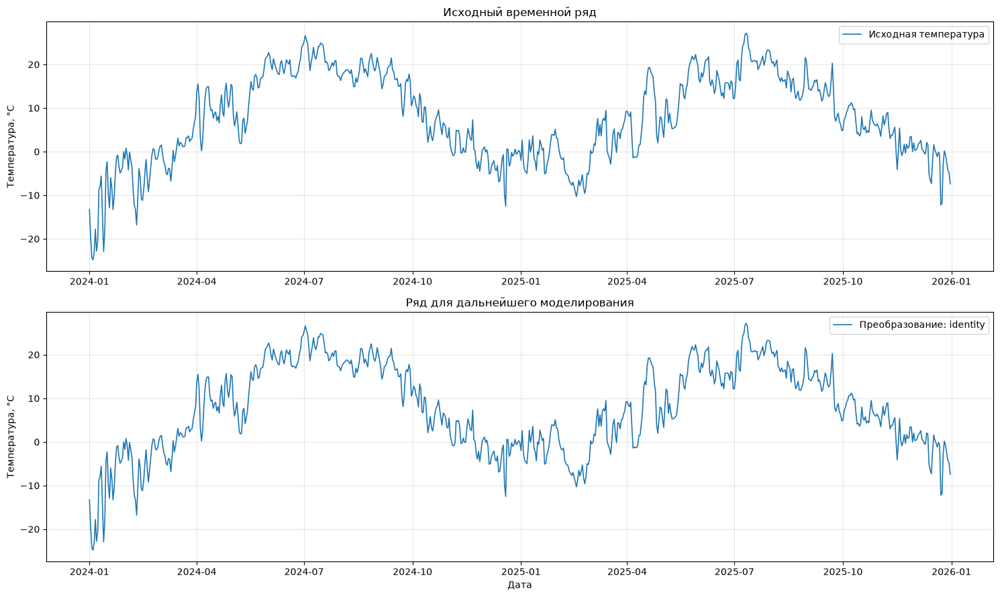


=== ИТОГИ ЗАДАНИЯ 1 ===
Исходных наблюдений: 731
ADF p-value: 0.01981
KPSS p-value: 0.1
Исходный ряд стационарен: True
Выбранное преобразование: identity
Ошибка восстановления: 0.0
Файлы сохранены в: /Users/lenar_966/Desktop/ML/Practika_3


In [1]:

from pathlib import Path
import json
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore", category=InterpolationWarning) if False else None

# ============================================================
# 1. ПУТИ К ПРОЕКТУ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_3"

DATA_DIR = PROJECT / "data"
REPORT_DIR = PROJECT / "reports" / "task1"
MODEL_DIR = PROJECT / "models"
TEST_DIR = PROJECT / "tests"

for folder in [DATA_DIR, REPORT_DIR, MODEL_DIR, TEST_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# При необходимости укажи здесь точный файл Практики №1.
SOURCE_PATH = None

candidates = [
    ROOT / "Practika_1" / "data" / "features_dataset.csv",
    ROOT / "Practika_1" / "data" / "processed_dataset.csv",
    ROOT / "Practika_2" / "data" / "features_dataset.csv",
]

if SOURCE_PATH is None:
    SOURCE_PATH = next(
        (p for p in candidates if p.is_file()),
        None
    )

if SOURCE_PATH is None:
    raise FileNotFoundError(
        "Не найден подготовленный CSV. "
        "Укажи SOURCE_PATH вручную."
    )

print("Источник данных:", SOURCE_PATH)

# Сохраняем неизменную копию входного файла.
RAW_COPY = DATA_DIR / "source_dataset_unchanged.csv"

if SOURCE_PATH.resolve() != RAW_COPY.resolve():
    shutil.copy2(SOURCE_PATH, RAW_COPY)

# ============================================================
# 2. ЗАГРУЗКА И ПОДГОТОВКА
# ============================================================

df = pd.read_csv(RAW_COPY)

TARGET = "temperature_2m_mean"

if TARGET not in df.columns:
    raise ValueError(f"Отсутствует целевая переменная {TARGET}")

if "time" in df.columns:
    date_col = "time"
elif "timestamp" in df.columns:
    date_col = "timestamp"
elif "date" in df.columns:
    date_col = "date"
else:
    raise ValueError("Не найдена колонка с датами.")

# Нормализуем даты к календарным дням Москвы.
dates = pd.to_datetime(
    df[date_col], utc=True, errors="coerce"
)

if dates.isna().any():
    raise ValueError("Обнаружены некорректные даты.")

if date_col in ("time", "timestamp"):
    dates = dates.dt.tz_convert("Europe/Moscow")

df["date"] = (
    dates.dt.tz_localize(None).dt.normalize()
)

df = df.sort_values("date").reset_index(drop=True)

df[TARGET] = pd.to_numeric(
    df[TARGET], errors="coerce"
)

print("\n=== ХАРАКТЕРИСТИКИ ДАННЫХ ===")
print("Наблюдений:", len(df))
print("Столбцов:", len(df.columns))
print("Начало:", df["date"].min().date())
print("Конец:", df["date"].max().date())
print("Пропусков цели:", df[TARGET].isna().sum())
print("Дубликатов дат:", df["date"].duplicated().sum())

if df[TARGET].isna().any():
    raise ValueError("Целевая переменная содержит пропуски.")

if df["date"].duplicated().any():
    raise ValueError("Обнаружены повторяющиеся даты.")

if not np.isfinite(df[TARGET]).all():
    raise ValueError("В целевой переменной есть inf/NaN.")

expected = pd.date_range(
    df["date"].min(),
    df["date"].max(),
    freq="D"
)

missing_dates = expected.difference(df["date"])

print("Пропущенных календарных дат:", len(missing_dates))

if len(missing_dates):
    raise ValueError("Временной ряд имеет пропущенные даты.")

if len(df) < 720:
    raise ValueError("Для задания требуется минимум 720 наблюдений.")

# ============================================================
# 3. ПРОВЕРКА СТАЦИОНАРНОСТИ
# ============================================================

def stationarity_tests(series):
    """ADF и KPSS для числового временного ряда."""
    x = pd.Series(series).dropna().astype(float)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        adf = adfuller(x, autolag="AIC")
        kp = kpss(x, regression="c", nlags="auto")

    return {
        "n": len(x),
        "ADF_stat": float(adf[0]),
        "ADF_p": float(adf[1]),
        "KPSS_stat": float(kp[0]),
        "KPSS_p": float(kp[1]),
        "stationary_5pct": bool(
            adf[1] < 0.05 and kp[1] > 0.05
        ),
    }

y = df[TARGET].astype(float)

original_tests = stationarity_tests(y)

# Сравниваем исходный ряд и первую разность.
diff_tests = stationarity_tests(y.diff())

results = pd.DataFrame([
    {"series": "original", **original_tests},
    {"series": "difference_1", **diff_tests},
])

print("\n=== ТЕСТЫ СТАЦИОНАРНОСТИ ===")
print(results.to_string(index=False))

# ============================================================
# 4. ВЫБОР ОБРАТИМОГО ПРЕОБРАЗОВАНИЯ
# ============================================================

if original_tests["stationary_5pct"]:
    transform_type = "identity"
    d = 0
    y_transformed = y.copy()
else:
    transform_type = "difference"
    d = 1
    y_transformed = y.diff()

    if not diff_tests["stationary_5pct"]:
        print(
            "\nВНИМАНИЕ: первая разность не прошла "
            "оба теста стационарности. "
            "Потребуется дополнительный анализ."
        )

transform_config = {
    "target": TARGET,
    "transformation": transform_type,
    "difference_order": d,
    "last_original_value": float(y.iloc[-1]),
    "n_observations": int(len(y)),
    "source_path": str(SOURCE_PATH),
    "source_copy": str(RAW_COPY),
    "stationarity_original": original_tests,
    "stationarity_difference_1": diff_tests,
}

def inverse_forecast(predictions, config, anchor=None):
    """
    Восстанавливает прогноз в исходной шкале.

    Для первой разности anchor — последнее известное
    значение исходного ряда на момент прогноза.
    """
    values = np.asarray(predictions, dtype=float)

    if config["transformation"] == "identity":
        return values.copy()

    if config["transformation"] == "difference":
        if anchor is None:
            anchor = config["last_original_value"]
        return float(anchor) + np.cumsum(values)

    raise ValueError("Неизвестное преобразование.")

# Проверка обратного преобразования на истории.
if d == 1:
    reconstructed = (
        y.iloc[0] + np.cumsum(y.diff().iloc[1:].values)
    )
    reconstruction_error = float(
        np.max(np.abs(reconstructed - y.iloc[1:].values))
    )
else:
    reconstruction_error = float(
        np.max(np.abs(y_transformed.values - y.values))
    )

print("\n=== ПРЕОБРАЗОВАНИЕ ===")
print("Тип:", transform_type)
print("Порядок разности:", d)
print("Максимальная ошибка восстановления:",
      reconstruction_error)

assert reconstruction_error < 1e-8

# ============================================================
# 5. ПРОВЕРКА ПРИЗНАКОВ
# ============================================================

feature_columns = [
    c for c in df.columns
    if c not in [TARGET, "time", "timestamp", "date"]
]

lag_cols = [
    c for c in feature_columns
    if "lag" in c.lower()
]

rolling_cols = [
    c for c in feature_columns
    if any(
        term in c.lower()
        for term in ["rolling", "roll_", "window"]
    )
]

calendar_cols = [
    c for c in feature_columns
    if any(
        term in c.lower()
        for term in [
            "month", "dayofweek", "day_of_week",
            "dayofyear", "day_of_year", "sin", "cos"
        ]
    )
]

print("\n=== ПРИЗНАКИ ===")
print("Всего дополнительных признаков:", len(feature_columns))
print("Лаговые:", len(lag_cols))
print("Скользящие:", len(rolling_cols))
print("Календарные/циклические:", len(calendar_cols))

# ============================================================
# 6. ВИЗУАЛИЗАЦИЯ
# ============================================================

fig, axes = plt.subplots(
    2, 1, figsize=(15, 9)
)

axes[0].plot(
    df["date"], y,
    linewidth=1.2,
    label="Исходная температура"
)
axes[0].set_title("Исходный временной ряд")
axes[0].set_ylabel("Температура, °C")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    df["date"],
    y_transformed,
    linewidth=1.2,
    label=f"Преобразование: {transform_type}"
)
axes[1].set_title("Ряд для дальнейшего моделирования")
axes[1].set_xlabel("Дата")
axes[1].set_ylabel(
    "Температура, °C" if d == 0
    else "Изменение температуры, °C"
)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "stationarity_comparison.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

# ============================================================
# 7. СОХРАНЕНИЕ АРТЕФАКТОВ
# ============================================================

prepared = df[["date", TARGET]].copy()
prepared["target_transformed"] = y_transformed

prepared.to_csv(
    DATA_DIR / "task1_prepared_series.csv",
    index=False
)

results.to_csv(
    REPORT_DIR / "stationarity_tests.csv",
    index=False
)

with open(
    REPORT_DIR / "transformation_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        transform_config, f,
        ensure_ascii=False,
        indent=2
    )

print("\n=== ИТОГИ ЗАДАНИЯ 1 ===")
print("Исходных наблюдений:", len(df))
print("ADF p-value:", round(original_tests["ADF_p"], 6))
print("KPSS p-value:", round(original_tests["KPSS_p"], 6))
print("Исходный ряд стационарен:",
      original_tests["stationary_5pct"])
print("Выбранное преобразование:", transform_type)
print("Ошибка восстановления:", reconstruction_error)
print("Файлы сохранены в:", PROJECT)


### Анализ результатов задания 1

В ходе выполнения первого задания был подготовлен временной ряд среднесуточной температуры воздуха в Москве за 2024–2025 годы. Набор данных содержит **731 наблюдение**, что соответствует минимальным требованиям методических указаний.

Для проверки стационарности временного ряда использовались два статистических теста: расширенный тест Дики — Фуллера (ADF) и тест KPSS.

**Результаты теста ADF:**

- Статистика теста: −3,2030.
- p-value: 0,01981.

Поскольку полученное p-value меньше уровня значимости 0,05, нулевая гипотеза о наличии единичного корня отвергается. Таким образом, результаты ADF свидетельствуют в пользу стационарности временного ряда.

**Результаты теста KPSS:**

- Статистика теста: 0,3239.
- p-value: не менее 0,1.

Поскольку p-value превышает 0,05, отсутствуют основания отвергать нулевую гипотезу о стационарности ряда относительно постоянного уровня.

Дополнительно была исследована первая разность временного ряда. Для неё получены следующие значения:

- ADF: −14,0958, p-value ≈ 2,67 × 10⁻²⁶.
- KPSS: 0,3190, p-value ≥ 0,1.

Первая разность также удовлетворяет выбранным статистическим критериям стационарности. Однако поскольку исходный ряд уже прошёл обе проверки, дополнительное дифференцирование не требуется.

Для дальнейшего моделирования выбрано тождественное преобразование (`identity`) с порядком дифференцирования `d = 0`.

Проверка обратного преобразования показала максимальную ошибку восстановления, равную 0,0, что подтверждает отсутствие численных потерь при восстановлении исходных значений.

### Итоговый вывод

В результате выполнения первого задания подготовлен временной ряд из 731 наблюдения, пригодный для последующего сравнительного анализа классических моделей прогнозирования.

Статистические тесты ADF и KPSS согласованно свидетельствуют в пользу стационарности исходного ряда. Поэтому для дальнейшего моделирования принято решение использовать исходную шкалу температуры без дополнительного дифференцирования.

При этом наличие возможных сезонных закономерностей будет дополнительно учитываться при выборе и настройке прогнозных моделей.

Подготовленные данные и параметры преобразования сохранены для дальнейшего использования в последующих заданиях практической работы.

## Задание 2. Анализ мультиколлинеарности экзогенных признаков

### Цель работы

Исследовать мультиколлинеарность между экзогенными признаками временного ряда и сформировать оптимизированный набор переменных для последующего построения прогнозных моделей.

### Постановка задачи

В практической работе №1 были сформированы дополнительные признаки временного ряда: лаговые переменные, скользящие статистики и календарные признаки.

Некоторые из них могут содержать дублирующую информацию. Например, значения температуры за соседние дни могут быть сильно коррелированы, а скользящие средние с близкими размерами окна могут описывать практически одинаковые закономерности.

Для количественной оценки мультиколлинеарности используется **фактор инфляции дисперсии (Variance Inflation Factor, VIF)**.

Формула расчёта:

\[
VIF_j = \frac{1}{1-R_j^2}
\]

где \(R_j^2\) — коэффициент детерминации регрессии рассматриваемого признака на остальные независимые переменные.

Интерпретация:

- VIF ≈ 1 — мультиколлинеарность практически отсутствует.
- 1 < VIF ≤ 5 — умеренная зависимость.
- 5 < VIF ≤ 10 — высокая зависимость, требующая внимания.
- VIF > 10 — выраженная мультиколлинеарность.

В рамках задания используется порог **VIF = 10**, предусмотренный методическими указаниями.

### Этапы выполнения

1. Загрузить подготовленный набор признаков.
2. Отобрать числовые экзогенные переменные.
3. Исключить целевую переменную и служебные поля.
4. Вычислить исходные значения VIF.
5. Реализовать итеративное исключение признака с максимальным VIF.
6. Повторять процедуру до достижения установленного порога.
7. Сравнить исходное и итоговое пространство признаков.
8. Сохранить итоговый набор признаков, значения VIF и историю удаления.
9. Реализовать вычисления в отдельном модуле `vif_analysis.py`.

**Ожидаемый результат:** набор экзогенных переменных с VIF не выше 10, пригодный для дальнейшего анализа и использования в моделях с регрессорами.

In [2]:

from pathlib import Path

PROJECT = Path.home() / "Desktop" / "ML" / "Practika_3"
PROJECT.mkdir(parents=True, exist_ok=True)

module_code = r'''
"""Анализ мультиколлинеарности экзогенных признаков."""

import numpy as np
import pandas as pd


def calculate_vif(X: pd.DataFrame) -> pd.DataFrame:
    """
    Вычисляет VIF для числовых признаков.

    Parameters
    ----------
    X : pd.DataFrame
        Матрица экзогенных переменных без пропусков.
        Постоянные столбцы недопустимы.

    Returns
    -------
    pd.DataFrame
        Таблица feature, VIF, отсортированная по убыванию VIF.
    """
    if not isinstance(X, pd.DataFrame):
        raise TypeError("X должен быть pandas DataFrame.")

    if X.empty or X.shape[1] == 0:
        raise ValueError("Матрица признаков пуста.")

    if X.isna().any().any():
        raise ValueError("Матрица содержит пропуски.")

    values = X.to_numpy(dtype=float)

    if not np.isfinite(values).all():
        raise ValueError("Матрица содержит inf или NaN.")

    std = values.std(axis=0)

    if np.any(std < 1e-12):
        raise ValueError("Обнаружены постоянные признаки.")

    if X.shape[1] == 1:
        return pd.DataFrame({
            "feature": X.columns,
            "VIF": [1.0]
        })

    # Центрирование и стандартизация.
    Z = (values - values.mean(axis=0)) / std

    # Корреляционная матрица.
    corr = Z.T @ Z / len(Z)

    # VIF равен диагонали обратной корреляционной матрицы.
    # При точной линейной зависимости используем inf.
    try:
        eigenvalues = np.linalg.eigvalsh(corr)
        if eigenvalues.min() <= 1e-10:
            vif_values = _vif_with_collinearity(Z)
        else:
            vif_values = np.diag(np.linalg.inv(corr))
    except np.linalg.LinAlgError:
        vif_values = _vif_with_collinearity(Z)

    result = pd.DataFrame({
        "feature": X.columns,
        "VIF": np.maximum(vif_values, 1.0)
    })

    return result.sort_values(
        "VIF", ascending=False, kind="stable"
    ).reset_index(drop=True)


def _vif_with_collinearity(Z: np.ndarray) -> np.ndarray:
    """Рассчитывает VIF через вспомогательные регрессии."""
    n_features = Z.shape[1]
    result = np.zeros(n_features)

    for j in range(n_features):
        target = Z[:, j]
        others = np.delete(Z, j, axis=1)

        coefficients = np.linalg.lstsq(
            others, target, rcond=None
        )[0]

        residuals = target - others @ coefficients

        r2 = 1.0 - (
            np.sum(residuals ** 2) /
            np.sum(target ** 2)
        )

        result[j] = (
            np.inf if r2 >= 1 - 1e-10
            else 1.0 / max(1.0 - r2, 1e-12)
        )

    return result


def iterative_vif_filter(
    X: pd.DataFrame,
    threshold: float = 10.0,
    verbose: bool = True
):
    """
    Итеративно исключает признаки с VIF выше порога.

    Parameters
    ----------
    X : pd.DataFrame
        Числовая матрица признаков без пропусков.
    threshold : float
        Максимально допустимый VIF.
    verbose : bool
        Выводить ли ход фильтрации.

    Returns
    -------
    selected : list[str]
        Список оставшихся признаков.
    final_vif : pd.DataFrame
        Значения VIF после фильтрации.
    history : pd.DataFrame
        История исключения признаков.
    """
    if threshold < 1:
        raise ValueError("Порог VIF должен быть >= 1.")

    selected = list(X.columns)
    history = []

    iteration = 0

    while len(selected) > 1:
        current_vif = calculate_vif(X[selected])

        max_row = current_vif.iloc[0]
        max_vif = float(max_row["VIF"])

        if max_vif <= threshold:
            break

        feature_to_remove = str(max_row["feature"])
        iteration += 1

        history.append({
            "iteration": iteration,
            "removed_feature": feature_to_remove,
            "VIF_before_removal": max_vif,
            "features_remaining": len(selected) - 1
        })

        selected.remove(feature_to_remove)

        if verbose and (
            iteration <= 10 or iteration % 10 == 0
        ):
            print(
                f"Итерация {iteration}: удалён "
                f"{feature_to_remove}, VIF={max_vif:.2f}"
            )

    final_vif = calculate_vif(X[selected])

    return (
        selected,
        final_vif,
        pd.DataFrame(
            history,
            columns=[
                "iteration",
                "removed_feature",
                "VIF_before_removal",
                "features_remaining"
            ]
        )
    )
'''

module_path = PROJECT / "vif_analysis.py"
module_path.write_text(module_code, encoding="utf-8")

print("Создан модуль:", module_path)


Создан модуль: /Users/lenar_966/Desktop/ML/Practika_3/vif_analysis.py


Источник: /Users/lenar_966/Desktop/ML/Practika_1/data/features_dataset.csv
Размер исходного датасета: (731, 199)

=== ДАННЫЕ ДЛЯ VIF ===
Обучающих строк до очистки: 584
Строк после очистки: 584
Числовых признаков: 197
Исключено пустых: 0
Исключено постоянных: 12
Признаков перед VIF: 185

=== ТОП-15 ПРИЗНАКОВ ПО VIF ДО ФИЛЬТРАЦИИ ===
                         feature          VIF
       temperature_2m_mean_lag_1          inf
       temperature_2m_mean_lag_2          inf
    temperature_2m_mean_change_1          inf
temperature_2m_mean_roll_mean_90 9.587430e+05
 temperature_2m_max_roll_mean_90 2.840230e+05
 temperature_2m_min_roll_mean_90 2.351529e+05
         pressure_msl_mean_lag_1 1.987886e+05
temperature_2m_mean_roll_mean_30 1.541212e+05
  pressure_msl_mean_lag1_squared 7.910387e+04
         pressure_msl_mean_lag_2 6.013630e+04
 temperature_2m_max_roll_mean_30 5.846039e+04
 temperature_2m_min_roll_mean_30 2.932364e+04
  pressure_msl_mean_pct_change_1 1.922240e+04
 temperature_2m_mean_

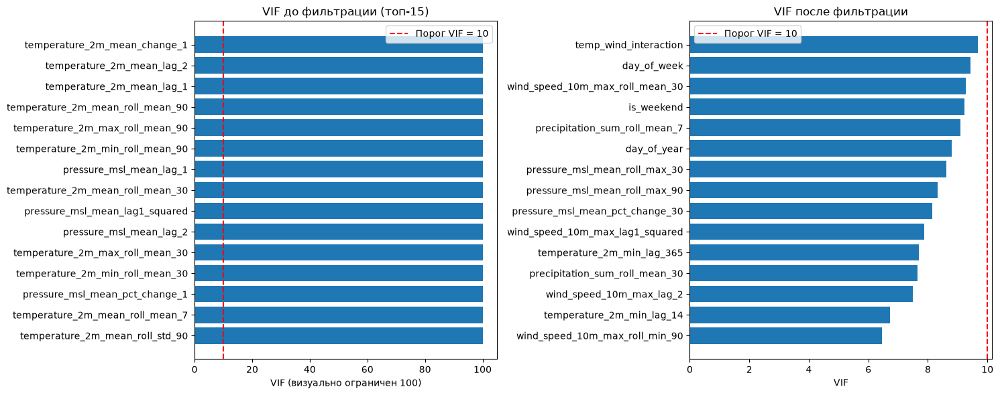


=== ИТОГИ ЗАДАНИЯ 2 ===
Признаков до VIF: 185
Признаков после VIF: 94
Удалено: 91
Максимальный VIF: 9.6773
Результаты сохранены: /Users/lenar_966/Desktop/ML/Practika_3/reports/task2


In [3]:

import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_3"
REPORT_DIR = PROJECT / "reports" / "task2"
DATA_DIR = PROJECT / "data"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROJECT))

from vif_analysis import calculate_vif, iterative_vif_filter

# ============================================================
# 1. ПОИСК ДАТАСЕТА С ПРИЗНАКАМИ
# ============================================================

# Если известен точный путь, укажи его здесь.
FEATURES_PATH = None

candidates = [
    ROOT / "Practika_1" / "data" / "features_dataset.csv",
    ROOT / "Practika_1" / "data" / "processed_dataset.csv",
    ROOT / "Practika_2" / "data" / "features_dataset.csv",
]

if FEATURES_PATH is None:
    FEATURES_PATH = next(
        (p for p in candidates if p.is_file()),
        None
    )

if FEATURES_PATH is None:
    raise FileNotFoundError(
        "Не найден датасет с признаками. "
        "Укажи FEATURES_PATH вручную."
    )

df = pd.read_csv(FEATURES_PATH)

print("Источник:", FEATURES_PATH)
print("Размер исходного датасета:", df.shape)

# ============================================================
# 2. ПОДГОТОВКА МАТРИЦЫ ПРИЗНАКОВ
# ============================================================

TARGET = "temperature_2m_mean"

if TARGET not in df.columns:
    raise ValueError("Не найдена целевая переменная.")

date_candidates = ["date", "timestamp", "time"]

date_col = next(
    (c for c in date_candidates if c in df.columns),
    None
)

if date_col is None:
    raise ValueError("Не найдена колонка с датами.")

df[date_col] = pd.to_datetime(
    df[date_col], errors="coerce", utc=True
)

if df[date_col].isna().any():
    raise ValueError("Есть некорректные даты.")

df = df.sort_values(date_col).reset_index(drop=True)

if df[date_col].duplicated().any():
    raise ValueError("Обнаружены дубликаты дат.")

# Отбираем только числовые признаки.
numeric_cols = df.select_dtypes(
    include=[np.number]
).columns.tolist()

excluded = {
    TARGET,
    "target_transformed",
    "target",
    "y",
    "index",
    "Unnamed: 0"
}

feature_cols = [
    c for c in numeric_cols
    if c not in excluded
]

if not feature_cols:
    raise ValueError("Числовые признаки не найдены.")

# Для предварительного отбора используем первые 80% дат.
split_index = int(len(df) * 0.8)

train_df = df.iloc[:split_index].copy()

X_train = train_df[feature_cols].copy()

# Убираем признаки, которые целиком пустые
# или не меняются на обучающем периоде.
all_missing = X_train.columns[
    X_train.isna().all()
].tolist()

X_train = X_train.drop(columns=all_missing)

# Убираем строки с неполной историей лагов.
X_train = X_train.replace(
    [np.inf, -np.inf], np.nan
).dropna()

constant_cols = X_train.columns[
    X_train.nunique() <= 1
].tolist()

X_train = X_train.drop(columns=constant_cols)

if X_train.empty or X_train.shape[1] == 0:
    raise ValueError(
        "После очистки не осталось данных для VIF."
    )

print("\n=== ДАННЫЕ ДЛЯ VIF ===")
print("Обучающих строк до очистки:", len(train_df))
print("Строк после очистки:", len(X_train))
print("Числовых признаков:", len(feature_cols))
print("Исключено пустых:", len(all_missing))
print("Исключено постоянных:", len(constant_cols))
print("Признаков перед VIF:", X_train.shape[1])

# ============================================================
# 3. ИСХОДНЫЙ VIF
# ============================================================

initial_vif = calculate_vif(X_train)

print("\n=== ТОП-15 ПРИЗНАКОВ ПО VIF ДО ФИЛЬТРАЦИИ ===")
print(initial_vif.head(15).to_string(index=False))

print(
    "\nПризнаков с VIF > 10:",
    int((initial_vif["VIF"] > 10).sum())
)

# ============================================================
# 4. ИТЕРАТИВНАЯ ФИЛЬТРАЦИЯ
# ============================================================

selected_features, final_vif, history = (
    iterative_vif_filter(
        X_train,
        threshold=10.0,
        verbose=True
    )
)

print("\n=== РЕЗУЛЬТАТ VIF-ФИЛЬТРАЦИИ ===")
print("Было признаков:", X_train.shape[1])
print("Удалено признаков:", len(history))
print("Осталось признаков:", len(selected_features))
print("Максимальный итоговый VIF:",
      round(final_vif["VIF"].max(), 4))

print("\nИтоговый набор признаков:")
print(final_vif.to_string(index=False))

# ============================================================
# 5. ВИЗУАЛИЗАЦИЯ
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top_before = (
    initial_vif.head(15)
    .sort_values("VIF", ascending=True)
    .copy()
)

# Для отображения бесконечных VIF
# ограничиваем длину столбцов на графике.
top_before["plot_vif"] = (
    top_before["VIF"]
    .replace(np.inf, 100)
    .clip(upper=100)
)

axes[0].barh(
    top_before["feature"],
    top_before["plot_vif"]
)
axes[0].axvline(
    10, linestyle="--", color="red",
    label="Порог VIF = 10"
)
axes[0].set_title("VIF до фильтрации (топ-15)")
axes[0].set_xlabel("VIF (визуально ограничен 100)")
axes[0].legend()

top_after = (
    final_vif.head(15)
    .sort_values("VIF", ascending=True)
)

axes[1].barh(
    top_after["feature"],
    top_after["VIF"]
)
axes[1].axvline(
    10, linestyle="--", color="red",
    label="Порог VIF = 10"
)
axes[1].set_title("VIF после фильтрации")
axes[1].set_xlabel("VIF")
axes[1].legend()

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "vif_before_after.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

# ============================================================
# 6. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

initial_vif.to_csv(
    REPORT_DIR / "vif_before.csv",
    index=False
)

final_vif.to_csv(
    REPORT_DIR / "vif_after.csv",
    index=False
)

history.to_csv(
    REPORT_DIR / "vif_removal_history.csv",
    index=False
)

# Сохраняем весь временной ряд, включая даты,
# но только с отобранными экзогенными признаками.
filtered_df = df[
    [date_col, TARGET] + selected_features
].copy()

filtered_df.to_csv(
    DATA_DIR / "task2_vif_filtered_dataset.csv",
    index=False
)

with open(
    REPORT_DIR / "selected_features.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            "threshold": 10.0,
            "features": selected_features,
            "train_rows_used": len(X_train),
            "source": str(FEATURES_PATH)
        },
        f,
        ensure_ascii=False,
        indent=2
    )

print("\n=== ИТОГИ ЗАДАНИЯ 2 ===")
print("Признаков до VIF:", X_train.shape[1])
print("Признаков после VIF:", len(selected_features))
print("Удалено:", len(history))
print("Максимальный VIF:",
      round(float(final_vif["VIF"].max()), 4))
print("Результаты сохранены:", REPORT_DIR)


### Анализ результатов задания 2

В рамках второго задания был проведён анализ мультиколлинеарности экзогенных признаков временного ряда среднесуточной температуры воздуха в Москве.

Для исследования использовалась обучающая выборка из **584 наблюдений**, составляющая первые 80% исходного временного ряда. Такой подход позволяет выполнять предварительный отбор признаков без использования будущих наблюдений из тестового периода.

Первоначально набор данных содержал 197 числовых признаков. После исключения 12 постоянных переменных для анализа осталось 185 признаков.

#### Результаты первоначального VIF-анализа

Расчёт фактора инфляции дисперсии показал наличие выраженной мультиколлинеарности между экзогенными переменными.

Из 185 рассматриваемых признаков **137 имели значение VIF выше установленного порога 10**.

Для некоторых переменных были получены бесконечные значения VIF:

- `temperature_2m_mean_lag_1`
- `temperature_2m_mean_lag_2`
- `temperature_2m_mean_change_1`

Такие значения свидетельствуют о наличии точной линейной зависимости между отдельными признаками.

Кроме того, особенно высокие значения VIF наблюдались для скользящих средних температуры:

- `temperature_2m_mean_roll_mean_90` — 958 743;
- `temperature_2m_max_roll_mean_90` — 284 023;
- `temperature_2m_min_roll_mean_90` — 235 153.

Полученные результаты показывают, что значительная часть сконструированных признаков содержит пересекающуюся информацию.

#### Итеративная фильтрация признаков

Для устранения выраженной мультиколлинеарности применён алгоритм последовательного исключения признака с максимальным VIF.

На каждой итерации выполнялись пересчёт VIF и удаление наиболее зависимой переменной до достижения установленного порога.

По результатам фильтрации:

- Исходное количество признаков: 185.
- Количество удалённых признаков: 91.
- Количество оставшихся признаков: 94.
- Сокращение размерности: 49,2%.
- Максимальный итоговый VIF: 9,6773.

Таким образом, после 91 итерации все оставшиеся переменные удовлетворяют условию VIF ≤ 10.

#### Интерпретация результатов

Полученные результаты свидетельствуют о высокой избыточности первоначального пространства признаков.

Наибольшая мультиколлинеарность наблюдалась среди лаговых переменных и скользящих статистик, построенных на основе температуры, атмосферного давления и других метеорологических показателей.

Итеративная VIF-фильтрация позволила сократить размерность признакового пространства почти в два раза и устранить наиболее выраженные линейные зависимости.

При этом снижение VIF не гарантирует повышения точности прогнозирования. Окончательная полезность выбранных признаков будет оцениваться при обучении и сравнении прогнозных моделей.

### Итоговый вывод

В результате выполнения второго задания разработан отдельный модуль `vif_analysis.py`, реализующий расчёт фактора инфляции дисперсии и автоматическую итеративную фильтрацию признаков.

Первоначальный набор из 185 признаков был сокращён до 94, а максимальное значение VIF снижено до 9,6773.

Полученный набор экзогенных переменных удовлетворяет установленному порогу мультиколлинеарности и может использоваться как предварительная основа для построения моделей с регрессорами, в частности SARIMAX.

Для предотвращения утечек данных VIF-фильтрация выполнялась только на обучающей части временного ряда. При последующем бэктестинге отбор признаков должен повторяться внутри соответствующих обучающих окон.

Результаты расчётов, история исключения признаков и итоговый набор переменных сохранены для дальнейшего использования в следующих заданиях практической работы.

## Задание 3. Описательный анализ пространства признаков

### Цель работы

Исследовать статистические характеристики экзогенных переменных, оценить их взаимосвязи с целевой переменной и определить особенности признакового пространства после устранения мультиколлинеарности.

### Постановка задачи

На предыдущем этапе была выполнена VIF-фильтрация экзогенных переменных. В результате количество признаков сократилось со 185 до 94, а максимальное значение VIF снизилось до 9,6773.

Для обоснованного выбора прогнозных моделей необходимо дополнительно изучить корреляционную структуру признаков, их распределения и характер зависимости от целевой переменной.

В рамках задания выполняются следующие этапы:

1. Построение корреляционных матриц до и после VIF-фильтрации.
2. Расчёт описательных статистик и распределений лаговых переменных.
3. Анализ скользящих статистик температуры и других метеорологических показателей.
4. Расчёт коэффициентов корреляции Пирсона и Спирмена с целевой переменной.
5. Построение диаграмм рассеяния с локально взвешенной регрессией LOESS.
6. Выявление линейных и потенциально нелинейных зависимостей.
7. Формирование предварительных гипотез о наиболее информативных признаках.

### Используемые методы

**Корреляция Пирсона** оценивает силу линейной зависимости между переменными.

**Корреляция Спирмена** оценивает монотонную зависимость на основе рангов наблюдений.

**LOESS (Locally Estimated Scatterplot Smoothing)** — метод локального сглаживания, позволяющий визуально исследовать возможные нелинейные зависимости без предварительного задания конкретной функциональной формы.

### Ожидаемый результат

Сравнительные корреляционные матрицы, описательные статистики, распределения ключевых признаков, диаграммы рассеяния с LOESS-кривыми и таблица признаков, наиболее тесно связанных с целевой переменной.

Полученные результаты будут использованы при последующей спецификации классических моделей прогнозирования временных рядов.

ПРАКТИЧЕСКАЯ РАБОТА №3 — ЗАДАНИЕ 3
ОПИСАТЕЛЬНЫЙ АНАЛИЗ ПРОСТРАНСТВА ПРИЗНАКОВ

=== ЗАГРУЗКА ДАННЫХ ===
Источник: /Users/lenar_966/Desktop/ML/Practika_1/data/features_dataset.csv
Размер датасета: (731, 199)

=== ОБУЧАЮЩАЯ ВЫБОРКА ===
Всего наблюдений: 731
Обучающих наблюдений: 584
Начало: 2023-12-31 21:00:00+00:00
Конец: 2025-08-05 21:00:00+00:00

=== ИСХОДНЫЕ ДАННЫЕ ДЛЯ АНАЛИЗА ===
Наблюдений: 584
Признаков до VIF: 185
Признаков после VIF: 94
Исключено постоянных: 12
Исключено полностью пустых: 0


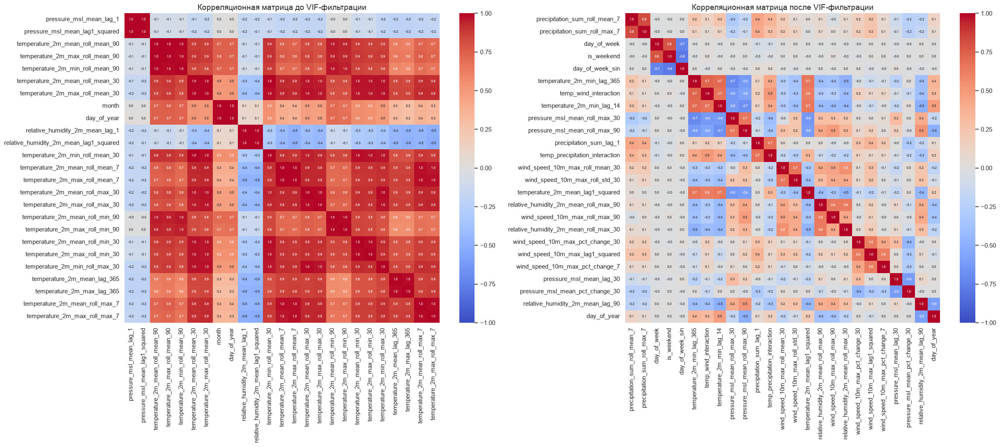


=== СРАВНЕНИЕ КОРРЕЛЯЦИОННОЙ СТРУКТУРЫ ===
     stage  pairs  mean_abs_corr  median_abs_corr  pairs_above_08  pairs_above_09  max_abs_corr
Before VIF  17020         0.2313           0.1234             988             397        1.0000
 After VIF   4371         0.1004           0.0547               1               0        0.8229

=== ГРУППЫ ПРИЗНАКОВ ===
Лаговых признаков: 56
Скользящих статистик: 81
Календарных/циклических: 9

Признаки для анализа распределений:
- temperature_2m_mean_lag_1
- temperature_2m_mean_lag_2
- temperature_2m_mean_lag_3
- temperature_2m_mean_roll_mean_7
- temperature_2m_mean_roll_std_7
- temperature_2m_mean_roll_min_7

=== ОПИСАТЕЛЬНЫЕ СТАТИСТИКИ ===
                                 count   mean     std     min    25%    50%     75%     max
temperature_2m_mean_lag_1        584.0  7.831  10.609 -24.800 -0.300  7.400  17.525  27.200
temperature_2m_mean_lag_2        584.0  7.800  10.599 -24.800 -0.300  7.300  17.425  27.200
temperature_2m_mean_lag_3        584.0

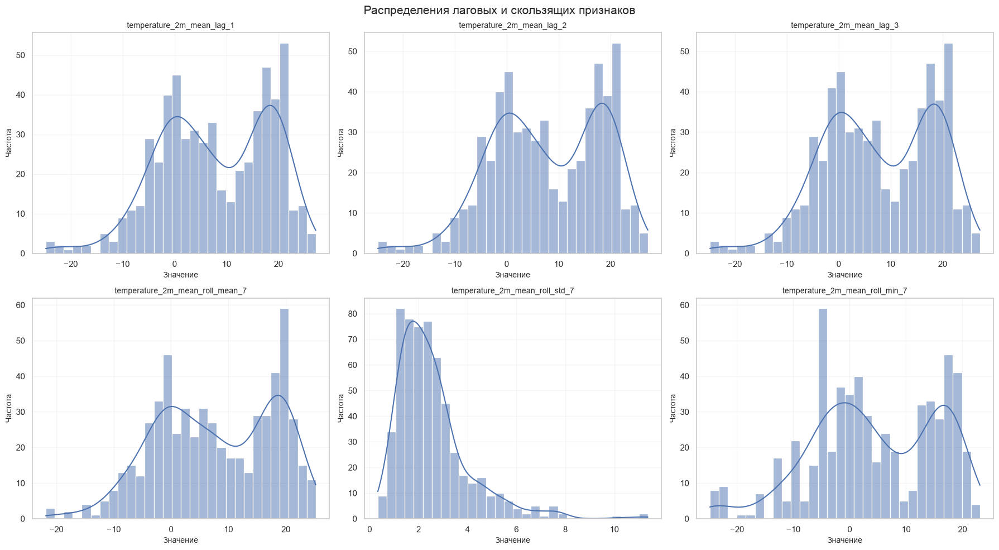


=== ТОП-20 ПРИЗНАКОВ ПО КОРРЕЛЯЦИИ С ЦЕЛЬЮ ===
                              feature  pearson  spearman  abs_pearson
                temp_wind_interaction   0.8785    0.8885       0.8785
           temperature_2m_min_lag_365   0.8018    0.8347       0.8018
            temperature_2m_min_lag_14   0.7275    0.7704       0.7275
     temperature_2m_mean_lag1_squared   0.7096    0.7623       0.7096
        pressure_msl_mean_roll_max_30  -0.6797   -0.6898       0.6797
        pressure_msl_mean_roll_max_90  -0.6617   -0.7007       0.6617
     relative_humidity_2m_mean_lag_30  -0.5460   -0.5628       0.5460
        pressure_msl_mean_roll_min_90   0.5308    0.5364       0.5308
relative_humidity_2m_mean_roll_std_90   0.5278    0.4879       0.5278
         pressure_msl_mean_roll_std_7  -0.5198   -0.5243       0.5198
     relative_humidity_2m_mean_lag_14  -0.5175   -0.5308       0.5175
relative_humidity_2m_mean_roll_max_30  -0.4969   -0.5194       0.4969
      relative_humidity_2m_mean_lag_7  -0.

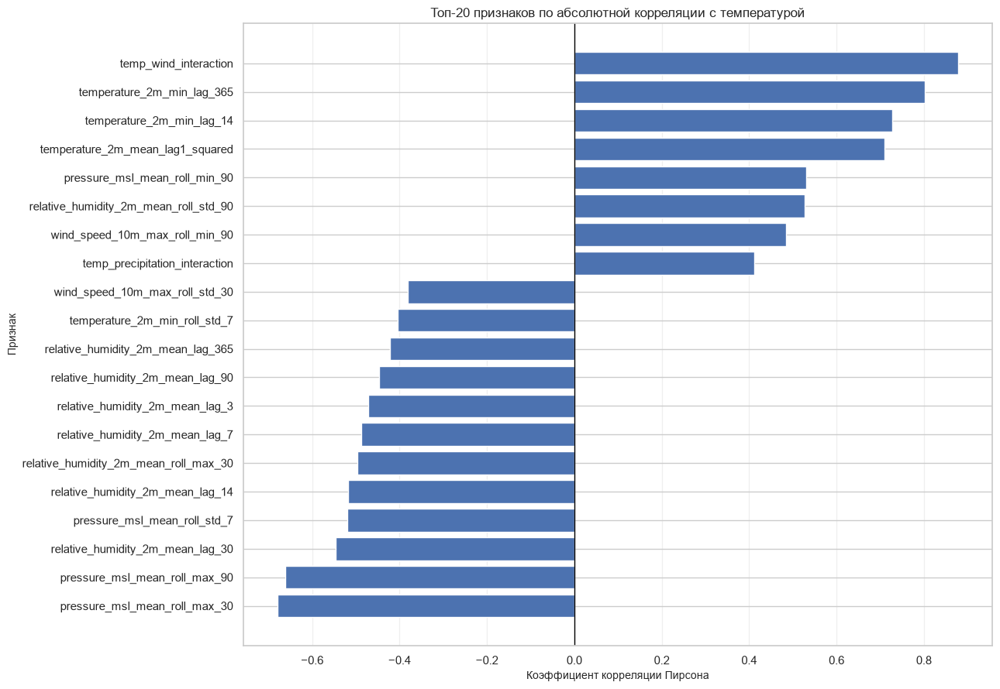

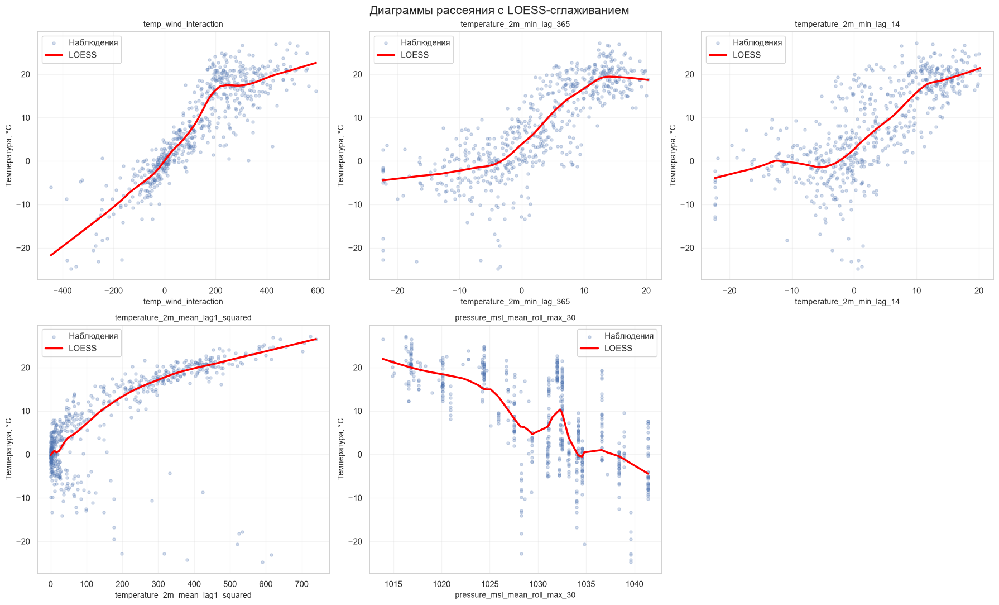


=== РЕЗУЛЬТАТЫ LOESS-АНАЛИЗА ===
                         feature  pearson  observations
           temp_wind_interaction   0.8785           584
      temperature_2m_min_lag_365   0.8018           584
       temperature_2m_min_lag_14   0.7275           584
temperature_2m_mean_lag1_squared   0.7096           584
   pressure_msl_mean_roll_max_30  -0.6797           584

ИТОГИ ЗАДАНИЯ 3
Количество наблюдений: 584
Признаков до VIF: 185
Признаков после VIF: 94
Средняя абсолютная корреляция до VIF: 0.2313
Средняя абсолютная корреляция после VIF: 0.1004
Пар с |r| > 0.9 до VIF: 397
Пар с |r| > 0.9 после VIF: 0
Максимальная абсолютная корреляция с целью: 0.8785
Признак с максимальной корреляцией: temp_wind_interaction

Все результаты сохранены в:
/Users/lenar_966/Desktop/ML/Practika_3/reports/task3

ЗАДАНИЕ 3 ВЫПОЛНЕНО


In [6]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №3
# ЗАДАНИЕ 3. ОПИСАТЕЛЬНЫЙ АНАЛИЗ ПРОСТРАНСТВА ПРИЗНАКОВ
# ============================================================
#
# Выполняемые этапы:
# 1. Загрузка данных из предыдущих практических работ
# 2. Загрузка результатов VIF-фильтрации
# 3. Подготовка обучающей выборки
# 4. Корреляционные матрицы до и после VIF
# 5. Анализ изменения корреляционной структуры
# 6. Описательные статистики признаков
# 7. Распределения лаговых и скользящих признаков
# 8. Корреляция Пирсона и Спирмена с целевой переменной
# 9. Визуализация наиболее значимых корреляций
# 10. Диаграммы рассеяния с LOESS
# 11. Сохранение всех результатов
# 12. Формирование итоговой сводки
#
# ============================================================

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.nonparametric.smoothers_lowess import lowess

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. НАСТРОЙКА ПРОЕКТА
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_3"

DATA_DIR = PROJECT / "data"
REPORT_DIR = PROJECT / "reports" / "task3"
TASK2_DIR = PROJECT / "reports" / "task2"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "temperature_2m_mean"
VIF_THRESHOLD = 10.0
TRAIN_SHARE = 0.8

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.figsize": (12, 6),
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "font.size": 10
})

print("=" * 70)
print("ПРАКТИЧЕСКАЯ РАБОТА №3 — ЗАДАНИЕ 3")
print("ОПИСАТЕЛЬНЫЙ АНАЛИЗ ПРОСТРАНСТВА ПРИЗНАКОВ")
print("=" * 70)

# ============================================================
# 2. ЗАГРУЗКА ИСХОДНОГО ДАТАСЕТА
# ============================================================

# Используем тот же источник, который был сохранён в задании 2.
config_path = TASK2_DIR / "selected_features.json"

if not config_path.exists():
    raise FileNotFoundError(
        "Не найден selected_features.json из задания 2."
    )

with open(config_path, "r", encoding="utf-8") as f:
    vif_config = json.load(f)

selected_features = vif_config["features"]

source_from_config = vif_config.get("source")

candidates = []

if source_from_config:
    candidates.append(Path(source_from_config))

candidates.extend([
    ROOT / "Practika_1" / "data" / "features_dataset.csv",
    ROOT / "Practika_1" / "data" / "processed_dataset.csv",
    ROOT / "Practika_2" / "data" / "features_dataset.csv"
])

SOURCE_PATH = next(
    (path for path in candidates if path.is_file()),
    None
)

if SOURCE_PATH is None:
    raise FileNotFoundError(
        "Не найден исходный датасет с признаками. "
        "Проверь путь к файлу."
    )

df = pd.read_csv(SOURCE_PATH)

print("\n=== ЗАГРУЗКА ДАННЫХ ===")
print("Источник:", SOURCE_PATH)
print("Размер датасета:", df.shape)

if TARGET not in df.columns:
    raise ValueError(
        f"Целевая переменная {TARGET} отсутствует."
    )

# ============================================================
# 3. ПОДГОТОВКА ВРЕМЕННОГО РЯДА
# ============================================================

date_candidates = [
    "date",
    "timestamp",
    "time"
]

date_col = next(
    (col for col in date_candidates if col in df.columns),
    None
)

if date_col is None:
    raise ValueError(
        "Не найдена колонка даты."
    )

df[date_col] = pd.to_datetime(
    df[date_col],
    errors="coerce",
    utc=True
)

if df[date_col].isna().any():
    raise ValueError(
        "Обнаружены некорректные даты."
    )

df = df.sort_values(
    date_col
).reset_index(drop=True)

if df[date_col].duplicated().any():
    raise ValueError(
        "Обнаружены дубликаты временных меток."
    )

df[TARGET] = pd.to_numeric(
    df[TARGET],
    errors="coerce"
)

# Анализируем только первые 80% наблюдений.
# Это тот же обучающий период, который
# использовался для VIF-фильтрации.

split_index = int(
    len(df) * TRAIN_SHARE
)

train_df = df.iloc[
    :split_index
].copy()

print("\n=== ОБУЧАЮЩАЯ ВЫБОРКА ===")
print("Всего наблюдений:", len(df))
print("Обучающих наблюдений:", len(train_df))
print("Начало:", train_df[date_col].min())
print("Конец:", train_df[date_col].max())

# ============================================================
# 4. ФОРМИРОВАНИЕ МАТРИЦЫ ПРИЗНАКОВ
# ============================================================

excluded_columns = {
    TARGET,
    "target_transformed",
    "target",
    "y",
    "index",
    "Unnamed: 0"
}

numeric_columns = train_df.select_dtypes(
    include=[np.number]
).columns.tolist()

feature_columns = [
    col for col in numeric_columns
    if col not in excluded_columns
]

X_all = train_df[
    feature_columns
].copy()

X_all = X_all.replace(
    [np.inf, -np.inf],
    np.nan
)

# Исключаем полностью пустые признаки.
all_missing_columns = X_all.columns[
    X_all.isna().all()
].tolist()

X_all = X_all.drop(
    columns=all_missing_columns
)

# Используем только полные наблюдения.
X_all = X_all.dropna()

# Исключаем постоянные признаки.
constant_columns = X_all.columns[
    X_all.nunique() <= 1
].tolist()

X_all = X_all.drop(
    columns=constant_columns
)

# Целевая переменная должна соответствовать
# тем же строкам, что и матрица признаков.

y = train_df.loc[
    X_all.index,
    TARGET
].astype(float)

valid_target = (
    np.isfinite(y.to_numpy())
)

X_all = X_all.loc[
    valid_target
].copy()

y = y.loc[
    valid_target
].copy()

# Проверяем наличие отобранных признаков.
missing_selected = [
    feature for feature in selected_features
    if feature not in X_all.columns
]

if missing_selected:
    raise ValueError(
        "Отсутствуют признаки после VIF: "
        + ", ".join(missing_selected)
    )

X_selected = X_all[
    selected_features
].copy()

print("\n=== ИСХОДНЫЕ ДАННЫЕ ДЛЯ АНАЛИЗА ===")
print("Наблюдений:", len(X_all))
print("Признаков до VIF:", X_all.shape[1])
print("Признаков после VIF:", X_selected.shape[1])
print("Исключено постоянных:", len(constant_columns))
print("Исключено полностью пустых:", len(all_missing_columns))

# ============================================================
# 5. КОРРЕЛЯЦИОННЫЕ МАТРИЦЫ
# ============================================================

corr_before = X_all.corr(
    method="pearson"
)

corr_after = X_selected.corr(
    method="pearson"
)

corr_before.to_csv(
    REPORT_DIR / "correlation_before_vif.csv",
    encoding="utf-8-sig"
)

corr_after.to_csv(
    REPORT_DIR / "correlation_after_vif.csv",
    encoding="utf-8-sig"
)

# ============================================================
# 6. ВЫБОР ПРИЗНАКОВ ДЛЯ ТЕПЛОВЫХ КАРТ
# ============================================================

def select_correlated_features(corr_matrix, top_n=25):
    """
    Выбирает признаки с наиболее сильными
    взаимными корреляциями.
    """

    matrix = corr_matrix.abs().copy()

    # Создаём изменяемую копию массива
    values = matrix.to_numpy(copy=True)

    # Обнуляем диагональ
    np.fill_diagonal(values, 0)

    # Максимальная корреляция каждого признака
    # с остальными переменными
    scores = pd.Series(
        values.max(axis=1),
        index=matrix.index
    )

    return scores.nlargest(
        min(top_n, len(scores))
    ).index.tolist()


features_before = select_correlated_features(
    corr_before,
    top_n=25
)

features_after = select_correlated_features(
    corr_after,
    top_n=25
)

# ============================================================
# 7. ВИЗУАЛИЗАЦИЯ КОРРЕЛЯЦИОННЫХ МАТРИЦ
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(25, 11)
)

sns.heatmap(
    corr_before.loc[
        features_before,
        features_before
    ],
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 6},
    ax=axes[0]
)

axes[0].set_title(
    "Корреляционная матрица до VIF-фильтрации",
    fontsize=14
)

sns.heatmap(
    corr_after.loc[
        features_after,
        features_after
    ],
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 6},
    ax=axes[1]
)

axes[1].set_title(
    "Корреляционная матрица после VIF-фильтрации",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "correlation_heatmaps.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 8. КОЛИЧЕСТВЕННЫЙ АНАЛИЗ КОРРЕЛЯЦИЙ
# ============================================================

def correlation_summary(corr_matrix):
    """
    Рассчитывает сводные характеристики
    абсолютных попарных корреляций.
    """
    values = corr_matrix.to_numpy()

    upper = values[
        np.triu_indices_from(
            values,
            k=1
        )
    ]

    upper = np.abs(upper)

    upper = upper[
        np.isfinite(upper)
    ]

    if len(upper) == 0:
        return {
            "pairs": 0,
            "mean_abs_corr": np.nan,
            "median_abs_corr": np.nan,
            "pairs_above_08": 0,
            "pairs_above_09": 0,
            "max_abs_corr": np.nan
        }

    return {
        "pairs": len(upper),
        "mean_abs_corr": float(np.mean(upper)),
        "median_abs_corr": float(np.median(upper)),
        "pairs_above_08": int(np.sum(upper > 0.8)),
        "pairs_above_09": int(np.sum(upper > 0.9)),
        "max_abs_corr": float(np.max(upper))
    }


summary_before = correlation_summary(
    corr_before
)

summary_after = correlation_summary(
    corr_after
)

summary_df = pd.DataFrame([
    {
        "stage": "Before VIF",
        **summary_before
    },
    {
        "stage": "After VIF",
        **summary_after
    }
])

print("\n=== СРАВНЕНИЕ КОРРЕЛЯЦИОННОЙ СТРУКТУРЫ ===")

print(
    summary_df.round(4).to_string(
        index=False
    )
)

summary_df.to_csv(
    REPORT_DIR / "correlation_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 9. ГРУППИРОВКА ПРИЗНАКОВ
# ============================================================

lag_features = [
    col for col in X_all.columns
    if "_lag_" in col.lower()
]

rolling_features = [
    col for col in X_all.columns
    if "_roll_" in col.lower()
    or "rolling" in col.lower()
]

calendar_features = [
    col for col in X_all.columns
    if any(
        term in col.lower()
        for term in [
            "month",
            "dayofweek",
            "day_of_week",
            "dayofyear",
            "day_of_year",
            "sin",
            "cos"
        ]
    )
]

print("\n=== ГРУППЫ ПРИЗНАКОВ ===")
print("Лаговых признаков:", len(lag_features))
print("Скользящих статистик:", len(rolling_features))
print("Календарных/циклических:", len(calendar_features))

# ============================================================
# 10. ВЫБОР ПРИЗНАКОВ ДЛЯ РАСПРЕДЕЛЕНИЙ
# ============================================================

temp_lags = [
    col for col in lag_features
    if "temperature_2m_mean" in col
]

temp_rolling = [
    col for col in rolling_features
    if "temperature_2m_mean" in col
]

plot_features = (
    temp_lags[:3]
    + temp_rolling[:3]
)

if len(plot_features) < 6:
    additional = [
        col
        for col in lag_features + rolling_features
        if col not in plot_features
    ]

    plot_features += additional[
        :6 - len(plot_features)
    ]

plot_features = plot_features[:6]

print("\nПризнаки для анализа распределений:")

for feature in plot_features:
    print("-", feature)

# ============================================================
# 11. ОПИСАТЕЛЬНЫЕ СТАТИСТИКИ
# ============================================================

descriptive_stats = X_all[
    plot_features
].describe().T

print("\n=== ОПИСАТЕЛЬНЫЕ СТАТИСТИКИ ===")

print(
    descriptive_stats.round(3).to_string()
)

descriptive_stats.to_csv(
    REPORT_DIR / "descriptive_statistics.csv",
    encoding="utf-8-sig"
)

# ============================================================
# 12. ГИСТОГРАММЫ РАСПРЕДЕЛЕНИЙ
# ============================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 10)
)

axes = axes.flatten()

for i, feature in enumerate(plot_features):

    sns.histplot(
        X_all[feature],
        kde=True,
        bins=30,
        ax=axes[i]
    )

    axes[i].set_title(
        feature,
        fontsize=10
    )

    axes[i].set_xlabel("Значение")
    axes[i].set_ylabel("Частота")
    axes[i].grid(alpha=0.2)

for i in range(
    len(plot_features),
    len(axes)
):
    axes[i].axis("off")

plt.suptitle(
    "Распределения лаговых и скользящих признаков",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "feature_distributions.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 13. КОРРЕЛЯЦИИ С ЦЕЛЕВОЙ ПЕРЕМЕННОЙ
# ============================================================

pearson_corr = X_selected.corrwith(
    y,
    method="pearson"
)

spearman_corr = X_selected.corrwith(
    y,
    method="spearman"
)

target_corr = pd.DataFrame({
    "feature": X_selected.columns,
    "pearson": pearson_corr.values,
    "spearman": spearman_corr.values
})

target_corr["abs_pearson"] = (
    target_corr["pearson"].abs()
)

target_corr = target_corr.sort_values(
    "abs_pearson",
    ascending=False
).reset_index(drop=True)

print("\n=== ТОП-20 ПРИЗНАКОВ ПО КОРРЕЛЯЦИИ С ЦЕЛЬЮ ===")

print(
    target_corr.head(20).round(4).to_string(
        index=False
    )
)

target_corr.to_csv(
    REPORT_DIR / "target_correlations.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 14. ВИЗУАЛИЗАЦИЯ КОРРЕЛЯЦИЙ С ЦЕЛЬЮ
# ============================================================

top20 = target_corr.head(20).sort_values(
    "pearson"
)

plt.figure(figsize=(13, 9))

plt.barh(
    top20["feature"],
    top20["pearson"]
)

plt.axvline(
    0,
    color="black",
    linewidth=1
)

plt.title(
    "Топ-20 признаков по абсолютной корреляции с температурой"
)

plt.xlabel(
    "Коэффициент корреляции Пирсона"
)

plt.ylabel("Признак")

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "target_correlations_top20.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 15. LOESS-АНАЛИЗ
# ============================================================

top_features = target_corr.head(5)[
    "feature"
].tolist()

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 11)
)

axes = axes.flatten()

loess_summary = []

for i, feature in enumerate(top_features):

    x_values = X_selected[
        feature
    ].to_numpy(dtype=float)

    y_values = y.to_numpy(dtype=float)

    valid = (
        np.isfinite(x_values)
        & np.isfinite(y_values)
    )

    x_clean = x_values[valid]
    y_clean = y_values[valid]

    smooth = lowess(
        endog=y_clean,
        exog=x_clean,
        frac=0.3,
        it=1,
        return_sorted=True
    )

    axes[i].scatter(
        x_clean,
        y_clean,
        alpha=0.25,
        s=14,
        label="Наблюдения"
    )

    axes[i].plot(
        smooth[:, 0],
        smooth[:, 1],
        color="red",
        linewidth=2.5,
        label="LOESS"
    )

    axes[i].set_title(
        feature,
        fontsize=10
    )

    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Температура, °C")

    axes[i].legend()
    axes[i].grid(alpha=0.2)

    corr_value = float(
        target_corr.loc[
            target_corr["feature"] == feature,
            "pearson"
        ].iloc[0]
    )

    loess_summary.append({
        "feature": feature,
        "pearson": corr_value,
        "observations": len(x_clean)
    })

for i in range(
    len(top_features),
    len(axes)
):
    axes[i].axis("off")

plt.suptitle(
    "Диаграммы рассеяния с LOESS-сглаживанием",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "loess_analysis.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

loess_df = pd.DataFrame(
    loess_summary
)

print("\n=== РЕЗУЛЬТАТЫ LOESS-АНАЛИЗА ===")

print(
    loess_df.round(4).to_string(
        index=False
    )
)

loess_df.to_csv(
    REPORT_DIR / "loess_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 16. СОХРАНЕНИЕ СВОДНОГО ОТЧЁТА
# ============================================================

report_summary = {
    "task": 3,
    "title": "Описательный анализ пространства признаков",
    "target": TARGET,
    "source": str(SOURCE_PATH),
    "train_observations": int(len(X_all)),
    "features_before_vif": int(X_all.shape[1]),
    "features_after_vif": int(X_selected.shape[1]),
    "lag_features": int(len(lag_features)),
    "rolling_features": int(len(rolling_features)),
    "calendar_features": int(len(calendar_features)),
    "correlation_before": summary_before,
    "correlation_after": summary_after,
    "top_target_features": (
        target_corr.head(10)[
            ["feature", "pearson", "spearman"]
        ].to_dict(orient="records")
    )
}

with open(
    REPORT_DIR / "task3_summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        report_summary,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 17. ИТОГОВЫЕ РЕЗУЛЬТАТЫ
# ============================================================

print("\n" + "=" * 70)
print("ИТОГИ ЗАДАНИЯ 3")
print("=" * 70)

print(
    "Количество наблюдений:",
    len(X_all)
)

print(
    "Признаков до VIF:",
    X_all.shape[1]
)

print(
    "Признаков после VIF:",
    X_selected.shape[1]
)

print(
    "Средняя абсолютная корреляция до VIF:",
    round(
        summary_before["mean_abs_corr"],
        4
    )
)

print(
    "Средняя абсолютная корреляция после VIF:",
    round(
        summary_after["mean_abs_corr"],
        4
    )
)

print(
    "Пар с |r| > 0.9 до VIF:",
    summary_before["pairs_above_09"]
)

print(
    "Пар с |r| > 0.9 после VIF:",
    summary_after["pairs_above_09"]
)

print(
    "Максимальная абсолютная корреляция с целью:",
    round(
        target_corr["abs_pearson"].max(),
        4
    )
)

print(
    "Признак с максимальной корреляцией:",
    target_corr.iloc[0]["feature"]
)

print("\nВсе результаты сохранены в:")
print(REPORT_DIR)

print("\nЗАДАНИЕ 3 ВЫПОЛНЕНО")


### Анализ результатов задания 3

В ходе выполнения третьего задания проведён описательный и корреляционный анализ пространства экзогенных признаков временного ряда среднесуточной температуры воздуха в Москве.

Исследование выполнялось на обучающей выборке из 584 наблюдений. Рассматривались два набора переменных: исходный набор из 185 признаков и сокращённый набор из 94 признаков, полученный после VIF-фильтрации.

#### 1. Анализ корреляционной структуры

До фильтрации средняя абсолютная корреляция между признаками составляла 0,2313, а медианная — 0,1234.

В исходном пространстве обнаружено 988 пар признаков с абсолютной корреляцией выше 0,8, включая 397 пар с корреляцией выше 0,9. Максимальное значение достигало 1, что свидетельствует о наличии полностью линейно зависимых переменных.

После VIF-фильтрации средняя абсолютная корреляция снизилась до 0,1004, а медианная — до 0,0547.

Количество пар с корреляцией выше 0,8 сократилось до одной, а пары с корреляцией выше 0,9 полностью отсутствуют. Максимальная абсолютная корреляция составила 0,8229.

Таким образом, средняя абсолютная корреляция снизилась приблизительно на 56,6%, что подтверждает существенное уменьшение избыточности признакового пространства.

#### 2. Анализ распределений лаговых и скользящих признаков

Описательные статистики лаговых переменных температуры показали близкие значения среднего и стандартного отклонения.

Средняя температура для лагов 1, 2 и 3 дня составила соответственно 7,831 °C, 7,800 °C и 7,763 °C.

Стандартное отклонение этих признаков находилось около 10,6 °C, что свидетельствует о значительной изменчивости температуры в течение исследуемого периода.

Для семидневной скользящей средней получено среднее значение 7,721 °C и стандартное отклонение 10,228 °C. Снижение разброса по сравнению с отдельными лагами соответствует сглаживающему характеру скользящего среднего.

Среднее значение семидневного скользящего стандартного отклонения составило 2,558 °C, а максимальное — 11,372 °C. Это указывает на наличие периодов с повышенной краткосрочной температурной изменчивостью.

#### 3. Анализ корреляций с целевой переменной

Наибольшую абсолютную корреляцию с температурой продемонстрировали следующие признаки:

- `temp_wind_interaction` — 0,8785;
- `temperature_2m_min_lag_365` — 0,8018;
- `temperature_2m_min_lag_14` — 0,7275;
- `temperature_2m_mean_lag1_squared` — 0,7096;
- `pressure_msl_mean_roll_max_30` — −0,6797;
- `pressure_msl_mean_roll_max_90` — −0,6617.

Полученные результаты показывают, что температура связана как с собственными историческими значениями, так и с характеристиками других метеорологических переменных.

Высокая корреляция годового лага может отражать сезонные закономерности. При этом корреляционные коэффициенты не позволяют установить причинно-следственные связи.

Сопоставление коэффициентов Пирсона и Спирмена показывает, что для ряда признаков ранговая зависимость несколько сильнее линейной. Это может свидетельствовать о наличии нелинейных или монотонных зависимостей, требующих дополнительного визуального анализа.

#### 4. Анализ нелинейных зависимостей

Для пяти признаков с наибольшей абсолютной корреляцией построены диаграммы рассеяния с использованием локально взвешенного сглаживания LOESS.

Метод позволяет визуально исследовать форму зависимости между экзогенными переменными и температурой без предварительного задания линейной функции.

Построенные графики используются для предварительного выявления нелинейности, изменения наклона и возможных участков насыщения. Окончательная интерпретация формы зависимостей требует визуального изучения графиков.

#### 5. Предварительные гипотезы

На основании полученных результатов сформулированы следующие гипотезы:

1. Исторические значения температуры могут быть информативными предикторами будущей температуры.
2. Годовые лаги могут отражать сезонную повторяемость температурных условий.
3. Скользящие статистики позволяют описывать краткосрочные и долгосрочные особенности температурной динамики.
4. Атмосферное давление, влажность и скорость ветра могут содержать дополнительную информацию для прогнозирования.
5. Часть зависимостей может иметь нелинейный характер, что необходимо учитывать при интерпретации и сравнении моделей.

### Итоговый вывод

В результате выполнения третьего задания проведён комплексный описательный анализ экзогенных признаков временного ряда.

Установлено, что VIF-фильтрация позволила существенно уменьшить взаимную корреляцию признаков: средняя абсолютная корреляция снизилась с 0,2313 до 0,1004, а количество пар с абсолютной корреляцией выше 0,9 сократилось с 397 до нуля.

Выявлены признаки, наиболее тесно связанные с целевой переменной, включая исторические значения температуры, показатели атмосферного давления и комбинированные метеорологические характеристики.

Полученные результаты формируют статистическую основу для последующего выбора прогнозных моделей.

При этом высокая корреляция признака с целевой переменной не гарантирует его прогностической полезности. Перед обучением моделей необходимо дополнительно проверить временную доступность экзогенных переменных и исключить потенциальные утечки данных.

## Задание 4. Сравнение стратегий многошагового прогнозирования

### Цель работы

Реализовать и сравнить рекурсивную, прямую и гибридную стратегии многошагового прогнозирования временного ряда среднесуточной температуры воздуха в Москве.

### Постановка задачи

Многошаговое прогнозирование предполагает получение прогнозов не только на следующий момент времени, но и на несколько последующих временных шагов.

В рамках задания рассматриваются три стратегии:

**1. Рекурсивная стратегия (Recursive)**

Обучается одна модель одношагового прогнозирования. Для получения прогноза на несколько дней вперёд предсказанные значения последовательно используются в качестве входных данных.

Преимущество — необходимость обучения только одной модели. Недостаток — возможность накопления ошибок при увеличении горизонта прогнозирования.

**2. Прямая стратегия (Direct)**

Для каждого шага прогнозирования обучается отдельная модель. Например, для горизонта 7 дней используются семь моделей, каждая из которых прогнозирует соответствующий день.

Преимущество — отсутствие последовательного накопления ошибок собственных прогнозов. Недостаток — необходимость обучения нескольких моделей.

**3. Гибридная стратегия (Hybrid)**

Используется модель с несколькими выходами, которая одновременно прогнозирует все значения на заданном горизонте.

Такой подход сочетает формирование единого прогноза на весь горизонт с возможностью учитывать зависимости между прогнозируемыми значениями.

### Метрики оценки

Для сравнения используются:

\[
MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
\]

\[
RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
\]

Дополнительно оцениваются время обучения, время прогнозирования и изменение ошибки по мере увеличения горизонта.

### Ожидаемый результат

Сравнительная таблица качества трёх стратегий на горизонтах 1, 7 и 30 дней, графики прогнозов и изменения ошибки, а также обоснованный вывод о преимуществах и ограничениях каждой стратегии.

ПРАКТИЧЕСКАЯ РАБОТА №3 — ЗАДАНИЕ 4
СРАВНЕНИЕ СТРАТЕГИЙ МНОГОШАГОВОГО ПРОГНОЗИРОВАНИЯ

=== ДАННЫЕ ===
Источник: /Users/lenar_966/Desktop/ML/Practika_3/data/task1_prepared_series.csv
Количество наблюдений: 731
Начало: 2024-01-01 00:00:00+00:00
Конец: 2025-12-31 00:00:00+00:00

Количество признаков: 43

=== РАЗДЕЛЕНИЕ ДАННЫХ ===
Обучающий период: 584 наблюдений
Тестовый период: 147 наблюдений
Горизонты: [1, 7, 30]

=== ОБУЧЕНИЕ RECURSIVE ===
Обучающих примеров: 554
Время обучения: 0.0245 сек.

=== ОБУЧЕНИЕ DIRECT И HYBRID ===
Горизонт  1: Direct = 0.010 сек., Hybrid = 0.011 сек.
Горизонт  7: Direct = 0.072 сек., Hybrid = 0.010 сек.


/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_47378/2688284155.py:148: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  day_of_year = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_47378/2688284155.py:149: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  day_of_week = date.dayofweek
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_47378/2688284155.py:148: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  day_of_year = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_47378/2688284155.py:149: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  day_of_week = date.dayofweek
/var/folders/m0/80ny9yh13n9935d0nx57

Горизонт 30: Direct = 0.303 сек., Hybrid = 0.010 сек.

=== ТЕСТИРОВАНИЕ СТРАТЕГИЙ ===
Горизонт 1: тестовых точек = 147
Горизонт 7: тестовых точек = 141
Горизонт 30: тестовых точек = 118

=== СРАВНЕНИЕ СТРАТЕГИЙ ===
 horizon  strategy    MAE   RMSE  train_time_sec  predict_time_sec  test_origins
       1 Recursive 1.6475 2.2139          0.0245            0.0242           147
       1    Direct 1.6475 2.2139          0.0103            0.0208           147
       1    Hybrid 1.6475 2.2139          0.0106            0.0219           147
       7 Recursive 2.4607 3.2184          0.0245            0.1368           141
       7    Hybrid 2.4887 3.2481          0.0101            0.0183           141
       7    Direct 2.4899 3.2494          0.0722            0.1299           141
      30    Hybrid 2.4169 3.0831          0.0100            0.0152           118
      30    Direct 2.4380 3.1121          0.3034            0.4366           118
      30 Recursive 2.5113 3.1378          0.0245        

/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_47378/2688284155.py:148: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  day_of_year = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_47378/2688284155.py:149: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  day_of_week = date.dayofweek
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_47378/2688284155.py:148: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  day_of_year = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_47378/2688284155.py:149: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  day_of_week = date.dayofweek
/var/folders/m0/80ny9yh13n9935d0nx57

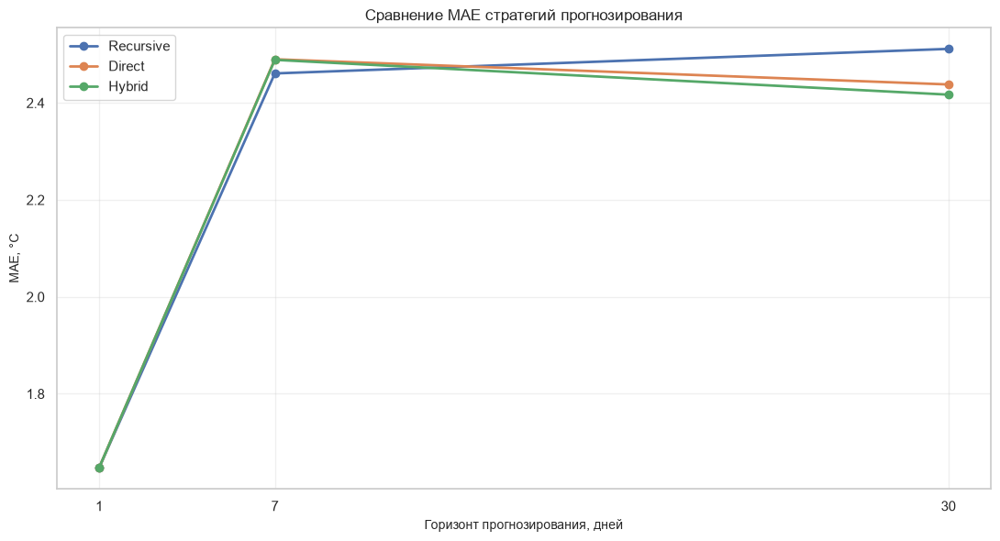

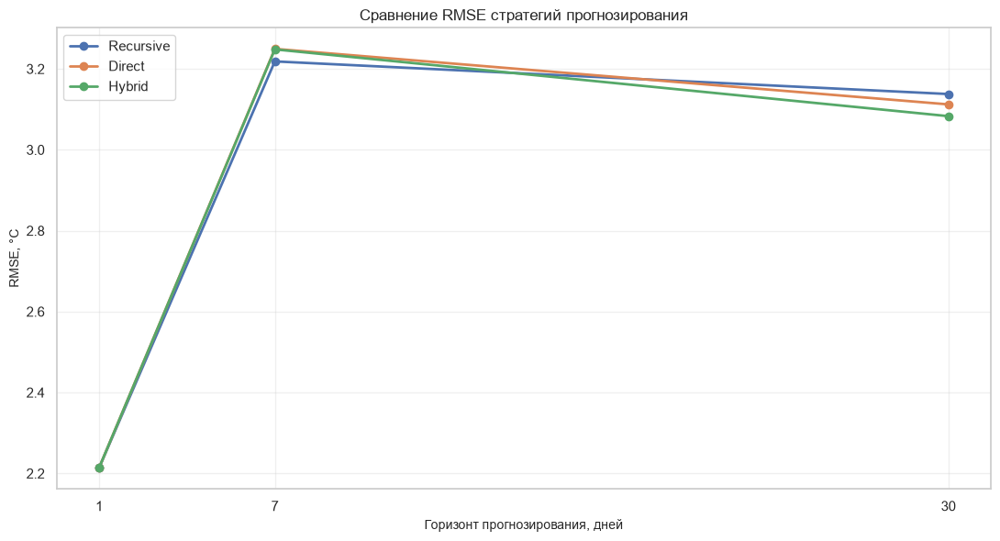

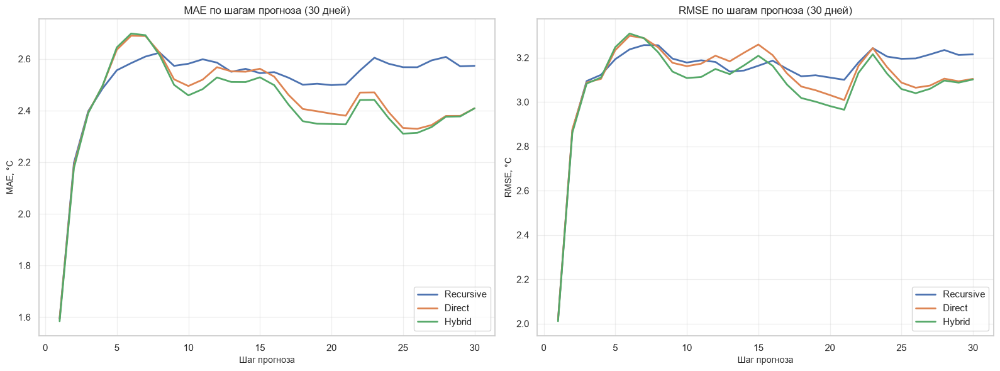

/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_47378/2688284155.py:148: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  day_of_year = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_47378/2688284155.py:149: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  day_of_week = date.dayofweek
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_47378/2688284155.py:148: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  day_of_year = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_47378/2688284155.py:149: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  day_of_week = date.dayofweek
/var/folders/m0/80ny9yh13n9935d0nx57

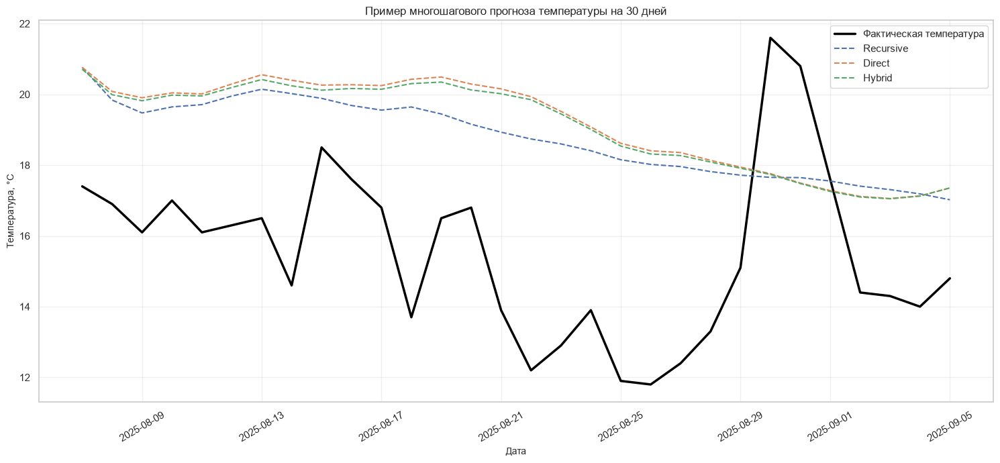

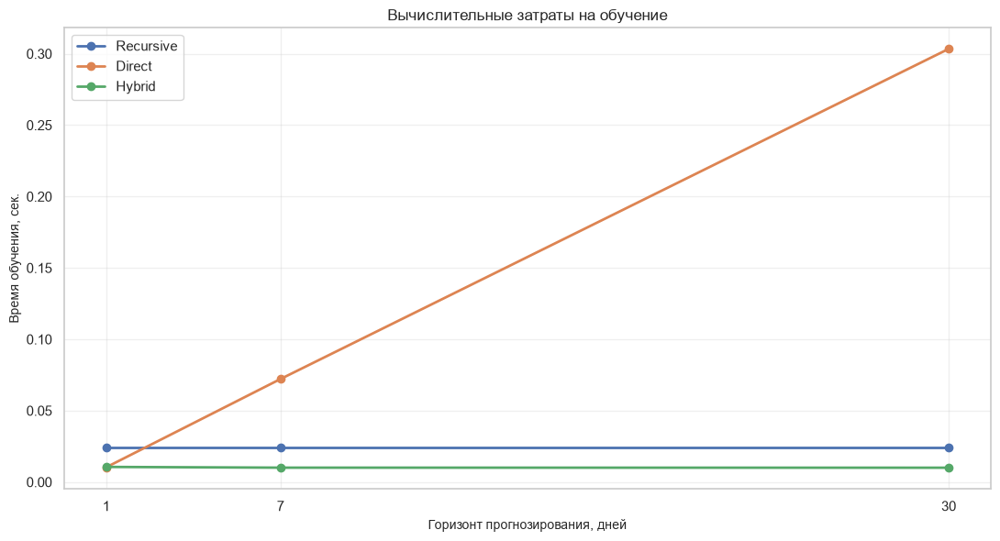


ИТОГИ ЗАДАНИЯ 4
Всего наблюдений: 731
Обучающих наблюдений: 584
Тестовых наблюдений: 147
Количество признаков: 43
Модель: Ridge
Горизонты: [1, 7, 30]

ЛУЧШИЕ СТРАТЕГИИ:
Горизонт  1 дней: Recursive | MAE = 1.6475 °C | RMSE = 2.2139 °C
Горизонт  7 дней: Recursive | MAE = 2.4607 °C | RMSE = 3.2184 °C
Горизонт 30 дней: Hybrid | MAE = 2.4169 °C | RMSE = 3.0831 °C

Результаты сохранены:
/Users/lenar_966/Desktop/ML/Practika_3/reports/task4

ЗАДАНИЕ 4 ВЫПОЛНЕНО


In [7]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №3
# ЗАДАНИЕ 4. СРАВНЕНИЕ СТРАТЕГИЙ МНОГОШАГОВОГО ПРОГНОЗИРОВАНИЯ
# ============================================================

from pathlib import Path
from time import perf_counter
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. НАСТРОЙКИ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_3"

DATA_DIR = PROJECT / "data"
REPORT_DIR = PROJECT / "reports" / "task4"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "temperature_2m_mean"

HORIZONS = [1, 7, 30]

# Используем 30 предыдущих дней температуры.
N_LAGS = 30

# Доля данных для первоначального обучения.
TRAIN_SHARE = 0.8

# Регуляризация Ridge.
ALPHA = 10.0

# Максимальное количество тестовых точек.
# None — использовать все доступные.
MAX_TEST_ORIGINS = None

np.random.seed(42)

print("=" * 75)
print("ПРАКТИЧЕСКАЯ РАБОТА №3 — ЗАДАНИЕ 4")
print("СРАВНЕНИЕ СТРАТЕГИЙ МНОГОШАГОВОГО ПРОГНОЗИРОВАНИЯ")
print("=" * 75)

# ============================================================
# 2. ЗАГРУЗКА ИСХОДНОГО ВРЕМЕННОГО РЯДА
# ============================================================

candidates = [
    DATA_DIR / "task1_prepared_series.csv",
    ROOT / "Practika_1" / "data" / "features_dataset.csv",
    ROOT / "Practika_1" / "data" / "processed_dataset.csv",
    ROOT / "Practika_2" / "data" / "features_dataset.csv"
]

SOURCE_PATH = next(
    (p for p in candidates if p.is_file()),
    None
)

if SOURCE_PATH is None:
    raise FileNotFoundError(
        "Не найден файл временного ряда. "
        "Укажи SOURCE_PATH вручную."
    )

df = pd.read_csv(SOURCE_PATH)

date_col = next(
    (c for c in ["date", "timestamp", "time"] if c in df.columns),
    None
)

if date_col is None:
    raise ValueError("Не найдена колонка даты.")

if TARGET not in df.columns:
    raise ValueError(
        f"Не найдена целевая переменная {TARGET}."
    )

df[date_col] = pd.to_datetime(
    df[date_col],
    errors="coerce",
    utc=True
)

df[TARGET] = pd.to_numeric(
    df[TARGET],
    errors="coerce"
)

df = df.sort_values(date_col).reset_index(drop=True)

if df[date_col].isna().any():
    raise ValueError("Есть некорректные даты.")

if df[TARGET].isna().any():
    raise ValueError("Есть пропуски температуры.")

if df[date_col].duplicated().any():
    raise ValueError("Есть повторяющиеся даты.")

# Проверяем, что наблюдения идут ежедневно.
date_diff = df[date_col].diff().dropna()

if not (date_diff == pd.Timedelta(days=1)).all():
    raise ValueError(
        "Временной ряд должен иметь ежедневную частоту "
        "без пропущенных дат."
    )

dates = df[date_col].to_numpy()
values = df[TARGET].to_numpy(dtype=float)

n = len(values)

print("\n=== ДАННЫЕ ===")
print("Источник:", SOURCE_PATH)
print("Количество наблюдений:", n)
print("Начало:", df[date_col].min())
print("Конец:", df[date_col].max())

# ============================================================
# 3. ФУНКЦИИ ФОРМИРОВАНИЯ ПРИЗНАКОВ
# ============================================================

def calendar_features(timestamp):
    """
    Календарные признаки, известные заранее.
    """
    date = pd.Timestamp(timestamp)

    day_of_year = date.dayofyear
    day_of_week = date.dayofweek

    return [
        np.sin(2 * np.pi * day_of_year / 365.25),
        np.cos(2 * np.pi * day_of_year / 365.25),
        np.sin(2 * np.pi * day_of_week / 7),
        np.cos(2 * np.pi * day_of_week / 7)
    ]


def make_features(history, forecast_date):
    """
    Признаки для прогноза на заданную дату.

    history содержит только фактически доступную
    температуру на момент прогноза.

    Порядок лагов:
    lag_1 — последнее доступное значение,
    lag_2 — предпоследнее и т.д.
    """
    history = np.asarray(history, dtype=float)

    if len(history) < N_LAGS:
        raise ValueError("Недостаточно истории.")

    lags = history[-N_LAGS:][::-1]

    rolling_7 = history[-7:]
    rolling_14 = history[-14:]
    rolling_30 = history[-30:]

    features = list(lags)

    features.extend([
        rolling_7.mean(),
        rolling_7.std(),
        rolling_7.min(),
        rolling_7.max(),
        rolling_14.mean(),
        rolling_14.std(),
        rolling_30.mean(),
        rolling_30.std(),
        history[-1] - history[-2]
    ])

    features.extend(
        calendar_features(forecast_date)
    )

    return np.asarray(features, dtype=float)


FEATURE_NAMES = (
    [f"lag_{i}" for i in range(1, N_LAGS + 1)]
    + [
        "roll_mean_7",
        "roll_std_7",
        "roll_min_7",
        "roll_max_7",
        "roll_mean_14",
        "roll_std_14",
        "roll_mean_30",
        "roll_std_30",
        "change_1",
        "dayofyear_sin",
        "dayofyear_cos",
        "dayofweek_sin",
        "dayofweek_cos"
    ]
)

print("\nКоличество признаков:", len(FEATURE_NAMES))

# ============================================================
# 4. ПОСТРОЕНИЕ ОБУЧАЮЩИХ ВЫБОРОК
# ============================================================

def build_direct_dataset(values, dates, horizon, end_index):
    """
    Прямая стратегия.

    Для шага horizon модель предсказывает температуру
    через horizon дней относительно последней
    известной даты.

    end_index — первый индекс, недоступный для обучения.
    """
    X, y = [], []

    for origin in range(N_LAGS - 1, end_index - horizon):
        target_index = origin + horizon

        feature_vector = make_features(
            values[:origin + 1],
            dates[target_index]
        )

        X.append(feature_vector)
        y.append(values[target_index])

    return np.asarray(X), np.asarray(y)


def build_multioutput_dataset(values, dates, horizon, end_index):
    """
    Гибридная стратегия.

    Обучается единая многовыходная модель,
    прогнозирующая сразу horizon дней.
    """
    X, Y = [], []

    for origin in range(N_LAGS - 1, end_index - horizon):
        # Для многовыходной модели календарь
        # задаём относительно первого дня прогноза.
        feature_vector = make_features(
            values[:origin + 1],
            dates[origin + 1]
        )

        targets = values[
            origin + 1:origin + horizon + 1
        ]

        X.append(feature_vector)
        Y.append(targets)

    return np.asarray(X), np.asarray(Y)


def create_model():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=ALPHA))
    ])


# ============================================================
# 5. ХРОНОЛОГИЧЕСКОЕ РАЗДЕЛЕНИЕ
# ============================================================

split_index = int(n * TRAIN_SHARE)

if split_index <= N_LAGS + max(HORIZONS):
    raise ValueError("Недостаточно обучающих наблюдений.")

print("\n=== РАЗДЕЛЕНИЕ ДАННЫХ ===")
print("Обучающий период:", split_index, "наблюдений")
print("Тестовый период:", n - split_index, "наблюдений")
print("Горизонты:", HORIZONS)

# Первая тестовая точка прогноза:
# последний день обучения.
first_test_origin = split_index - 1

# ============================================================
# 6. РЕКУРСИВНАЯ СТРАТЕГИЯ
# ============================================================

print("\n=== ОБУЧЕНИЕ RECURSIVE ===")

start = perf_counter()

X_rec, y_rec = build_direct_dataset(
    values,
    dates,
    horizon=1,
    end_index=split_index
)

recursive_model = create_model()
recursive_model.fit(X_rec, y_rec)

recursive_train_time = perf_counter() - start

print("Обучающих примеров:", len(X_rec))
print(
    "Время обучения:",
    round(recursive_train_time, 4),
    "сек."
)


def recursive_forecast(model, history, last_date, horizon):
    """
    Последовательный прогноз.

    Будущие значения добавляются в историю
    только из собственных прогнозов модели.
    """
    history = list(np.asarray(history, dtype=float))
    predictions = []

    for step in range(1, horizon + 1):
        future_date = (
            pd.Timestamp(last_date)
            + pd.Timedelta(days=step)
        )

        x = make_features(
            history,
            future_date
        ).reshape(1, -1)

        prediction = float(model.predict(x)[0])

        predictions.append(prediction)
        history.append(prediction)

    return np.asarray(predictions)


# ============================================================
# 7. ПРЯМАЯ И ГИБРИДНАЯ СТРАТЕГИИ
# ============================================================

print("\n=== ОБУЧЕНИЕ DIRECT И HYBRID ===")

direct_models = {}
hybrid_models = {}

direct_train_times = {}
hybrid_train_times = {}

for horizon in HORIZONS:

    # --------------------------------------------------------
    # DIRECT
    # --------------------------------------------------------

    start = perf_counter()

    models_for_horizon = []

    for step in range(1, horizon + 1):
        X_step, y_step = build_direct_dataset(
            values,
            dates,
            horizon=step,
            end_index=split_index
        )

        model = create_model()
        model.fit(X_step, y_step)

        models_for_horizon.append(model)

    direct_models[horizon] = models_for_horizon

    direct_train_times[horizon] = (
        perf_counter() - start
    )

    # --------------------------------------------------------
    # HYBRID
    # --------------------------------------------------------

    start = perf_counter()

    X_multi, Y_multi = build_multioutput_dataset(
        values,
        dates,
        horizon=horizon,
        end_index=split_index
    )

    hybrid_model = create_model()
    hybrid_model.fit(X_multi, Y_multi)

    hybrid_models[horizon] = hybrid_model

    hybrid_train_times[horizon] = (
        perf_counter() - start
    )

    print(
        f"Горизонт {horizon:2d}: "
        f"Direct = {direct_train_times[horizon]:.3f} сек., "
        f"Hybrid = {hybrid_train_times[horizon]:.3f} сек."
    )


def direct_forecast(models, history, last_date):
    predictions = []

    for step, model in enumerate(models, start=1):
        future_date = (
            pd.Timestamp(last_date)
            + pd.Timedelta(days=step)
        )

        x = make_features(
            history,
            future_date
        ).reshape(1, -1)

        predictions.append(
            float(model.predict(x)[0])
        )

    return np.asarray(predictions)


def hybrid_forecast(model, history, last_date):
    first_future_date = (
        pd.Timestamp(last_date)
        + pd.Timedelta(days=1)
    )

    x = make_features(
        history,
        first_future_date
    ).reshape(1, -1)

    return np.asarray(
        model.predict(x)
    ).reshape(-1)


# ============================================================
# 8. ОЦЕНКА НА ТЕСТОВОМ ПЕРИОДЕ
# ============================================================

print("\n=== ТЕСТИРОВАНИЕ СТРАТЕГИЙ ===")

all_results = []
all_predictions = []
step_errors = []

for horizon in HORIZONS:

    last_possible_origin = n - horizon - 1

    origins = np.arange(
        first_test_origin,
        last_possible_origin + 1
    )

    if MAX_TEST_ORIGINS is not None:
        origins = origins[:MAX_TEST_ORIGINS]

    if len(origins) == 0:
        raise ValueError(
            f"Нет тестовых точек для горизонта {horizon}."
        )

    actual_matrix = []

    predictions_by_strategy = {
        "Recursive": [],
        "Direct": [],
        "Hybrid": []
    }

    prediction_times = {
        "Recursive": 0.0,
        "Direct": 0.0,
        "Hybrid": 0.0
    }

    for origin in origins:

        # На момент origin известна только история
        # до этого дня включительно.
        history = values[:origin + 1]

        last_date = dates[origin]

        actual = values[
            origin + 1:origin + horizon + 1
        ]

        actual_matrix.append(actual)

        # ----------------------------------------------------
        # RECURSIVE
        # ----------------------------------------------------

        start = perf_counter()

        pred_recursive = recursive_forecast(
            recursive_model,
            history,
            last_date,
            horizon
        )

        prediction_times["Recursive"] += (
            perf_counter() - start
        )

        predictions_by_strategy["Recursive"].append(
            pred_recursive
        )

        # ----------------------------------------------------
        # DIRECT
        # ----------------------------------------------------

        start = perf_counter()

        pred_direct = direct_forecast(
            direct_models[horizon],
            history,
            last_date
        )

        prediction_times["Direct"] += (
            perf_counter() - start
        )

        predictions_by_strategy["Direct"].append(
            pred_direct
        )

        # ----------------------------------------------------
        # HYBRID
        # ----------------------------------------------------

        start = perf_counter()

        pred_hybrid = hybrid_forecast(
            hybrid_models[horizon],
            history,
            last_date
        )

        prediction_times["Hybrid"] += (
            perf_counter() - start
        )

        predictions_by_strategy["Hybrid"].append(
            pred_hybrid
        )

    actual_matrix = np.asarray(actual_matrix)

    # --------------------------------------------------------
    # МЕТРИКИ ПО СТРАТЕГИЯМ
    # --------------------------------------------------------

    for strategy, predictions in predictions_by_strategy.items():

        prediction_matrix = np.asarray(predictions)

        errors = actual_matrix - prediction_matrix

        mae = float(
            np.mean(np.abs(errors))
        )

        rmse = float(
            np.sqrt(np.mean(errors ** 2))
        )

        if strategy == "Recursive":
            train_time = recursive_train_time
        elif strategy == "Direct":
            train_time = direct_train_times[horizon]
        else:
            train_time = hybrid_train_times[horizon]

        all_results.append({
            "horizon": horizon,
            "strategy": strategy,
            "MAE": mae,
            "RMSE": rmse,
            "train_time_sec": train_time,
            "predict_time_sec": prediction_times[strategy],
            "test_origins": len(origins)
        })

        # Ошибки отдельно по каждому шагу горизонта.
        for step in range(horizon):

            step_mae = float(
                np.mean(
                    np.abs(errors[:, step])
                )
            )

            step_rmse = float(
                np.sqrt(
                    np.mean(errors[:, step] ** 2)
                )
            )

            step_errors.append({
                "horizon": horizon,
                "strategy": strategy,
                "step": step + 1,
                "MAE": step_mae,
                "RMSE": step_rmse
            })

        # Сохраняем прогнозы по каждой точке.
        for row_index, origin in enumerate(origins):
            for step in range(horizon):

                all_predictions.append({
                    "origin_date": str(
                        pd.Timestamp(dates[origin]).date()
                    ),
                    "forecast_date": str(
                        pd.Timestamp(
                            dates[origin + step + 1]
                        ).date()
                    ),
                    "horizon": horizon,
                    "step": step + 1,
                    "strategy": strategy,
                    "actual": float(
                        actual_matrix[row_index, step]
                    ),
                    "predicted": float(
                        prediction_matrix[row_index, step]
                    )
                })

    print(
        f"Горизонт {horizon}: "
        f"тестовых точек = {len(origins)}"
    )

# ============================================================
# 9. СРАВНИТЕЛЬНАЯ ТАБЛИЦА
# ============================================================

results_df = pd.DataFrame(all_results)

results_df = results_df.sort_values(
    ["horizon", "MAE"]
).reset_index(drop=True)

step_errors_df = pd.DataFrame(step_errors)

predictions_df = pd.DataFrame(all_predictions)

print("\n=== СРАВНЕНИЕ СТРАТЕГИЙ ===")

print(
    results_df.round(4).to_string(
        index=False
    )
)

# ============================================================
# 10. ЛУЧШАЯ СТРАТЕГИЯ ДЛЯ КАЖДОГО ГОРИЗОНТА
# ============================================================

best_by_horizon = (
    results_df
    .sort_values("MAE")
    .groupby("horizon", as_index=False)
    .first()
)

print("\n=== ЛУЧШАЯ СТРАТЕГИЯ ПО MAE ===")

print(
    best_by_horizon[
        ["horizon", "strategy", "MAE", "RMSE"]
    ].round(4).to_string(index=False)
)

# ============================================================
# 11. ГРАФИК MAE ПО ГОРИЗОНТАМ
# ============================================================

plt.figure(figsize=(11, 6))

for strategy in ["Recursive", "Direct", "Hybrid"]:

    subset = results_df[
        results_df["strategy"] == strategy
    ].sort_values("horizon")

    plt.plot(
        subset["horizon"],
        subset["MAE"],
        marker="o",
        linewidth=2,
        label=strategy
    )

plt.xticks(HORIZONS)
plt.xlabel("Горизонт прогнозирования, дней")
plt.ylabel("MAE, °C")
plt.title("Сравнение MAE стратегий прогнозирования")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "mae_by_horizon.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 12. ГРАФИК RMSE ПО ГОРИЗОНТАМ
# ============================================================

plt.figure(figsize=(11, 6))

for strategy in ["Recursive", "Direct", "Hybrid"]:

    subset = results_df[
        results_df["strategy"] == strategy
    ].sort_values("horizon")

    plt.plot(
        subset["horizon"],
        subset["RMSE"],
        marker="o",
        linewidth=2,
        label=strategy
    )

plt.xticks(HORIZONS)
plt.xlabel("Горизонт прогнозирования, дней")
plt.ylabel("RMSE, °C")
plt.title("Сравнение RMSE стратегий прогнозирования")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "rmse_by_horizon.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 13. НАКОПЛЕНИЕ ОШИБОК ПО ШАГАМ
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

for strategy in ["Recursive", "Direct", "Hybrid"]:

    subset = step_errors_df[
        (step_errors_df["horizon"] == 30)
        & (step_errors_df["strategy"] == strategy)
    ].sort_values("step")

    axes[0].plot(
        subset["step"],
        subset["MAE"],
        label=strategy,
        linewidth=2
    )

    axes[1].plot(
        subset["step"],
        subset["RMSE"],
        label=strategy,
        linewidth=2
    )

axes[0].set_title("MAE по шагам прогноза (30 дней)")
axes[0].set_xlabel("Шаг прогноза")
axes[0].set_ylabel("MAE, °C")

axes[1].set_title("RMSE по шагам прогноза (30 дней)")
axes[1].set_xlabel("Шаг прогноза")
axes[1].set_ylabel("RMSE, °C")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "error_accumulation_30.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 14. ПРИМЕР ПРОГНОЗА НА 30 ДНЕЙ
# ============================================================

example_origin = first_test_origin

example_history = values[:example_origin + 1]
example_date = dates[example_origin]

example_actual = values[
    example_origin + 1:example_origin + 31
]

example_dates = pd.to_datetime(
    dates[example_origin + 1:example_origin + 31]
)

example_recursive = recursive_forecast(
    recursive_model,
    example_history,
    example_date,
    30
)

example_direct = direct_forecast(
    direct_models[30],
    example_history,
    example_date
)

example_hybrid = hybrid_forecast(
    hybrid_models[30],
    example_history,
    example_date
)

plt.figure(figsize=(15, 7))

plt.plot(
    example_dates,
    example_actual,
    label="Фактическая температура",
    linewidth=2.5,
    color="black"
)

plt.plot(
    example_dates,
    example_recursive,
    label="Recursive",
    linestyle="--"
)

plt.plot(
    example_dates,
    example_direct,
    label="Direct",
    linestyle="--"
)

plt.plot(
    example_dates,
    example_hybrid,
    label="Hybrid",
    linestyle="--"
)

plt.title(
    "Пример многошагового прогноза температуры на 30 дней"
)

plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.legend()
plt.grid(alpha=0.3)

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "forecast_example_30.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 15. СРАВНЕНИЕ ВРЕМЕНИ ОБУЧЕНИЯ
# ============================================================

plt.figure(figsize=(11, 6))

for strategy in ["Recursive", "Direct", "Hybrid"]:

    subset = results_df[
        results_df["strategy"] == strategy
    ].sort_values("horizon")

    plt.plot(
        subset["horizon"],
        subset["train_time_sec"],
        marker="o",
        linewidth=2,
        label=strategy
    )

plt.xticks(HORIZONS)
plt.xlabel("Горизонт прогнозирования, дней")
plt.ylabel("Время обучения, сек.")
plt.title("Вычислительные затраты на обучение")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "training_time_comparison.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 16. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

results_df.to_csv(
    REPORT_DIR / "strategy_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

step_errors_df.to_csv(
    REPORT_DIR / "step_errors.csv",
    index=False,
    encoding="utf-8-sig"
)

predictions_df.to_csv(
    REPORT_DIR / "all_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

best_by_horizon.to_csv(
    REPORT_DIR / "best_strategies.csv",
    index=False,
    encoding="utf-8-sig"
)

summary = {
    "task": 4,
    "target": TARGET,
    "source": str(SOURCE_PATH),
    "observations": int(n),
    "train_observations": int(split_index),
    "test_observations": int(n - split_index),
    "horizons": HORIZONS,
    "n_lags": N_LAGS,
    "model": "Ridge",
    "alpha": ALPHA,
    "best_strategies": best_by_horizon[
        ["horizon", "strategy", "MAE", "RMSE"]
    ].to_dict(orient="records")
}

with open(
    REPORT_DIR / "task4_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        summary,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 17. ИТОГОВЫЙ ВЫВОД В КОНСОЛЬ
# ============================================================

print("\n" + "=" * 75)
print("ИТОГИ ЗАДАНИЯ 4")
print("=" * 75)

print("Всего наблюдений:", n)
print("Обучающих наблюдений:", split_index)
print("Тестовых наблюдений:", n - split_index)
print("Количество признаков:", len(FEATURE_NAMES))
print("Модель:", "Ridge")
print("Горизонты:", HORIZONS)

print("\nЛУЧШИЕ СТРАТЕГИИ:")

for _, row in best_by_horizon.iterrows():
    print(
        f"Горизонт {int(row['horizon']):2d} дней: "
        f"{row['strategy']} | "
        f"MAE = {row['MAE']:.4f} °C | "
        f"RMSE = {row['RMSE']:.4f} °C"
    )

print("\nРезультаты сохранены:")
print(REPORT_DIR)

print("\nЗАДАНИЕ 4 ВЫПОЛНЕНО")


### Анализ результатов задания 4

В ходе выполнения четвёртого задания были реализованы и исследованы три стратегии многошагового прогнозирования временного ряда среднесуточной температуры воздуха в Москве: рекурсивная (Recursive), прямая (Direct) и гибридная (Hybrid).

Для построения прогнозов использовалась модель Ridge Regression с регуляризацией. На основе исторических значений температуры и календарных характеристик было сформировано 43 признака.

Исходный временной ряд содержал 731 наблюдение, из которых 584 использовались для обучения, а 147 составляли тестовый период.

Сравнение выполнялось на горизонтах 1, 7 и 30 дней с использованием метрик MAE и RMSE.

#### 1. Прогнозирование на один день

На горизонте одного дня все три стратегии продемонстрировали одинаковые результаты:

- MAE = 1,6475 °C.
- RMSE = 2,2139 °C.

Это объясняется тем, что при одношаговом прогнозировании различия между стратегиями практически отсутствуют: каждая модель непосредственно предсказывает значение следующего дня.

Таким образом, на коротком горизонте выбор стратегии не оказал влияния на точность прогнозирования в проведённом эксперименте.

#### 2. Прогнозирование на семь дней

На горизонте семи дней получены следующие результаты:

- Recursive: MAE = 2,4607 °C, RMSE = 3,2184 °C.
- Direct: MAE = 2,4899 °C, RMSE = 3,2494 °C.
- Hybrid: MAE = 2,4887 °C, RMSE = 3,2481 °C.

Наименьшую ошибку продемонстрировала рекурсивная стратегия.

Преимущество Recursive относительно Direct по MAE составило приблизительно 1,2%, а относительно Hybrid — 1,1%.

Полученные результаты показывают, что на недельном горизонте последовательное использование собственных прогнозов не привело к существенному ухудшению качества по сравнению с альтернативными подходами.

При этом различия между стратегиями относительно невелики, поэтому для окончательного подтверждения преимущества требуется дополнительная проверка на нескольких временных окнах.

#### 3. Прогнозирование на 30 дней

На горизонте 30 дней получены следующие результаты:

- Recursive: MAE = 2,5113 °C, RMSE = 3,1378 °C.
- Direct: MAE = 2,4380 °C, RMSE = 3,1121 °C.
- Hybrid: MAE = 2,4169 °C, RMSE = 3,0831 °C.

Наилучшие показатели продемонстрировала гибридная стратегия.

По сравнению с Recursive гибридный подход снизил MAE приблизительно на 3,8%, а по сравнению с Direct — на 0,9%.

Это свидетельствует о том, что в проведённом эксперименте одновременное прогнозирование нескольких будущих значений оказалось более эффективным на длинном горизонте.

Рекурсивная стратегия продемонстрировала наибольшую ошибку среди трёх подходов, что согласуется с возможностью накопления ошибок при последовательном использовании предсказанных значений.

Однако для количественного подтверждения характера накопления ошибок необходимо дополнительно изучить графики MAE и RMSE по отдельным шагам прогнозирования.

#### 4. Анализ вычислительных затрат

Сравнение времени выполнения показало, что рекурсивная стратегия требует обучения только одной модели, тогда как прямая стратегия предполагает обучение отдельной модели для каждого прогнозируемого шага.

Для горизонта 30 дней время обучения Direct составило 0,3034 секунды, а Recursive — 0,0245 секунды.

Гибридная стратегия продемонстрировала наименьшее время прогнозирования — 0,0152 секунды против 0,4548 секунды у Recursive и 0,4366 секунды у Direct.

Таким образом, в рассматриваемой реализации гибридная стратегия сочетает высокую точность долгосрочного прогнозирования с небольшими вычислительными затратами.

Следует учитывать, что абсолютные значения времени выполнения зависят от вычислительной среды, объёма данных и реализации алгоритмов.

#### 5. Интерпретация полученных результатов

Сравнение стратегий позволяет сформулировать следующие наблюдения:

1. На горизонте одного дня все стратегии обеспечивают одинаковую точность.
2. На горизонте семи дней минимальную ошибку демонстрирует рекурсивный подход.
3. На горизонте 30 дней наилучшие результаты показывает гибридная стратегия.
4. Прямая стратегия требует дополнительных вычислений при увеличении горизонта, поскольку обучает отдельные модели для каждого шага.
5. Гибридная стратегия обеспечивает наиболее быстрое получение многошаговых прогнозов в проведённом эксперименте.

При интерпретации результатов необходимо учитывать, что количество тестовых точек различается между горизонтами. Поэтому сравнение качества между горизонтами следует дополнять анализом ошибок на одинаковых прогнозных шагах и временных окнах.

### Итоговый вывод

В результате выполнения четвёртого задания были реализованы три стратегии многошагового прогнозирования температуры воздуха: Recursive, Direct и Hybrid.

Эксперимент показал, что эффективность стратегии зависит от горизонта прогнозирования.

Для одношагового прогноза все три подхода продемонстрировали одинаковую точность с MAE = 1,6475 °C.

На горизонте семи дней наименьшая MAE составила 2,4607 °C и была получена рекурсивной стратегией.

На горизонте 30 дней наиболее точной оказалась гибридная стратегия с MAE = 2,4169 °C и RMSE = 3,0831 °C.

Таким образом, для дальнейших экспериментов целесообразно рассматривать рекурсивную стратегию как один из основных вариантов краткосрочного прогнозирования, а гибридную — как перспективный вариант прогнозирования на длительные горизонты.

Окончательный выбор стратегии будет уточняться на основании последующего бэктестинга, анализа остатков и статистического сравнения моделей.

## Задание 5. Построение классических моделей временных рядов

### Цель работы

Реализовать и сравнить классические статистические модели прогнозирования среднесуточной температуры воздуха в Москве, оценить точность их прогнозов и проанализировать применимость различных подходов к исследуемому временному ряду.

### Постановка задачи

В рамках задания необходимо построить следующие модели:

1. **AR (Autoregressive)** — авторегрессионная модель, использующая предыдущие значения временного ряда.
2. **MA (Moving Average)** — модель скользящего среднего, учитывающая предыдущие случайные ошибки.
3. **ARMA** — модель, объединяющая авторегрессионную компоненту и скользящее среднее ошибок.
4. **ARIMA** — модель авторегрессии и интегрированного скользящего среднего.
5. **SARIMA** — сезонная модель ARIMA.
6. **SARIMAX** — сезонная ARIMA с экзогенными переменными.
7. **SES (Simple Exponential Smoothing)** — простое экспоненциальное сглаживание.
8. **Holt** — экспоненциальное сглаживание с учётом тренда.
9. **GARCH(1,1)** — модель условной изменчивости, применяемая к остаткам прогнозной модели.
10. **TBATS** — модель сложной сезонности с тригонометрическими компонентами.
11. **Prophet** — аддитивная модель с трендом и сезонностью.
12. **Naive и Seasonal Naive** — базовые методы прогнозирования.

Модели VAR и VECM применяются при наличии нескольких взаимосвязанных временных рядов. Поскольку основным объектом исследования является один температурный ряд, их построение возможно только после обоснованного выбора дополнительных временных рядов.

### Методика эксперимента

Исходный набор содержит 731 ежедневное наблюдение за 2024–2025 годы.

Для обучения используются первые 584 наблюдения, оставшиеся 147 образуют тестовую выборку.

Прогнозирование выполняется на горизонтах 1, 7 и 30 дней.

Для оценки качества применяются метрики MAE и RMSE.

Дополнительно рассматриваются доверительные или прогнозные интервалы, если они поддерживаются моделью, и выполняется обратное преобразование прогнозов при использовании преобразованного целевого ряда.

### Ожидаемый результат

Сравнительная таблица моделей, графики прогнозов и ошибок, оценка прогнозных интервалов и предварительный выбор наиболее перспективных методов для дальнейшей диагностики и бэктестинга.

In [8]:
%pip install statsmodels arch tbats prophet scikit-learn matplotlib pandas numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 932.1/932.1 kB 3.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 7.5 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 7.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 593.6/593.6 kB 5.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 5.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.3/876.3 kB 6.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [tbats]32m7/9 [arch]et]]s]

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Здесь есть несколько методических ограничений, которые важно учитывать при подготовке отчёта.

Во-первых, метрики задания 5 нельзя напрямую сравнивать с заданием 4: в задании 4 ошибки усреднялись по множеству тестовых точек, а здесь используется только одна точка начала прогноза. Особенно на горизонте одного дня такая оценка неустойчива.

Во-вторых, прогнозные интервалы ARIMA/SARIMA/SARIMAX и Prophet имеют разные статистические предпосылки. Для SES, Holt и TBATS в этом коде интервалы не строятся, а GARCH используется для моделирования условной дисперсии остатков.

В-третьих, поскольку температура может быть отрицательной, для мультипликативной модели Holt применяется положительный сдвиг с последующим обратным преобразованием. Это экспериментальный подход, и его результаты следует интерпретировать осторожно.

ЗАДАНИЕ 5. КЛАССИЧЕСКИЕ МОДЕЛИ ВРЕМЕННЫХ РЯДОВ

=== ДОСТУПНОСТЬ БИБЛИОТЕК ===
arch: True
tbats: True
prophet: True

=== ДАННЫЕ ===
Источник: /Users/lenar_966/Desktop/ML/Practika_3/data/task1_prepared_series.csv
Всего наблюдений: 731
Обучающих: 584
Тестовых: 147
Начало прогноза: 2025-08-07 00:00:00
Конец прогноза: 2025-09-05 00:00:00

=== БАЗОВЫЕ МОДЕЛИ ===

=== AR / MA / ARMA / ARIMA ===

Обучение AR_3...
  Успешно, 0.057 сек.

Обучение MA_3...
  Успешно, 0.091 сек.

Обучение ARMA_3_2...
  Успешно, 0.154 сек.

Обучение ARIMA_5_0_2...
  Успешно, 0.260 сек.

Обучение ARIMA_3_1_2...
  Успешно, 0.060 сек.

=== SARIMA ===

Обучение SARIMA...
  Успешно, 0.449 сек.

=== SARIMAX ===

Обучение SARIMAX...
  Успешно, 0.996 сек.

=== ЭКСПОНЕНЦИАЛЬНОЕ СГЛАЖИВАНИЕ ===

Обучение SES...
  Успешно, 0.003 сек.

Обучение Holt_Additive...
  Успешно, 0.010 сек.

Обучение Holt_Multiplicative...
  Успешно, 0.028 сек.

=== TBATS ===

Обучение TBATS...


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
18:45:26 - cmdstanpy - INFO - Chain [1] start processing
18:45:26 - cmdstanpy - INFO - Chain [1] done processing


  Успешно, 7.380 сек.

=== PROPHET ===

Обучение Prophet...
  Успешно, 0.188 сек.

=== GARCH(1,1) ===
GARCH успешно обучена.
Время: 0.006 сек.
Параметры:
omega       0.0615
alpha[1]    0.1086
beta[1]     0.7557
Name: params, dtype: float64

СРАВНЕНИЕ КЛАССИЧЕСКИХ МОДЕЛЕЙ
              model  horizon    MAE   RMSE  fit_time_sec
            Prophet        1 0.0186 0.0186        0.1878
               MA_3        1 1.1135 1.1135        0.0908
 Seasonal_Naive_365        1 1.3000 1.3000        0.0000
             SARIMA        1 3.0689 3.0689        0.4493
           ARMA_3_2        1 3.1572 3.1572        0.1536
               AR_3        1 3.1647 3.1647        0.0574
            SARIMAX        1 3.2972 3.2972        0.9956
        ARIMA_5_0_2        1 3.3599 3.3599        0.2597
        ARIMA_3_1_2        1 3.4809 3.4809        0.0596
Holt_Multiplicative        1 3.6000 3.6000        0.0285
                SES        1 3.6000 3.6000        0.0032
              Naive        1 3.6000 3.6000  

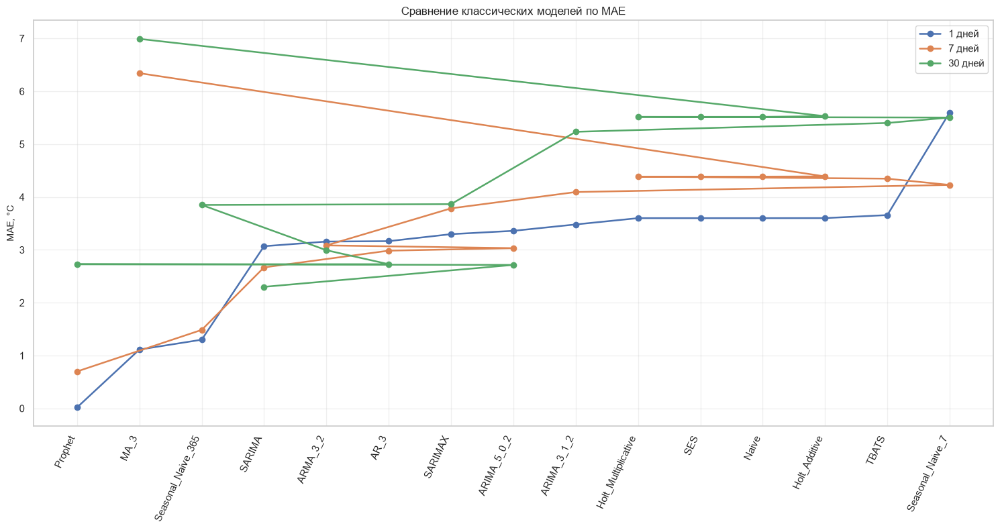

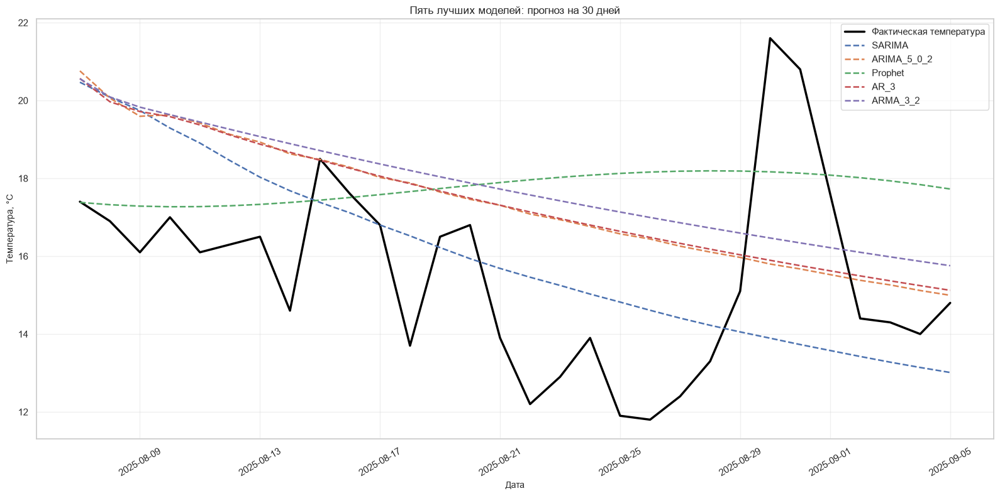

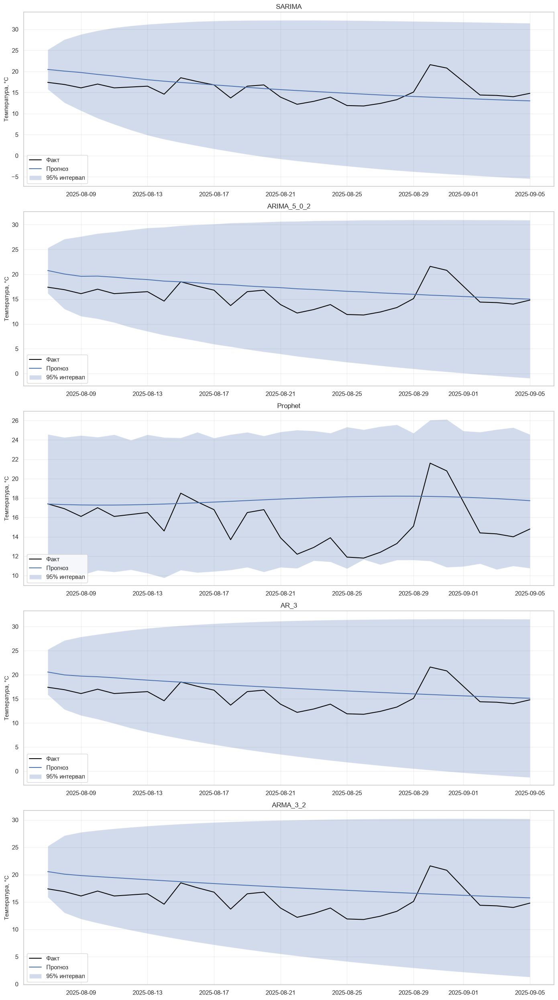

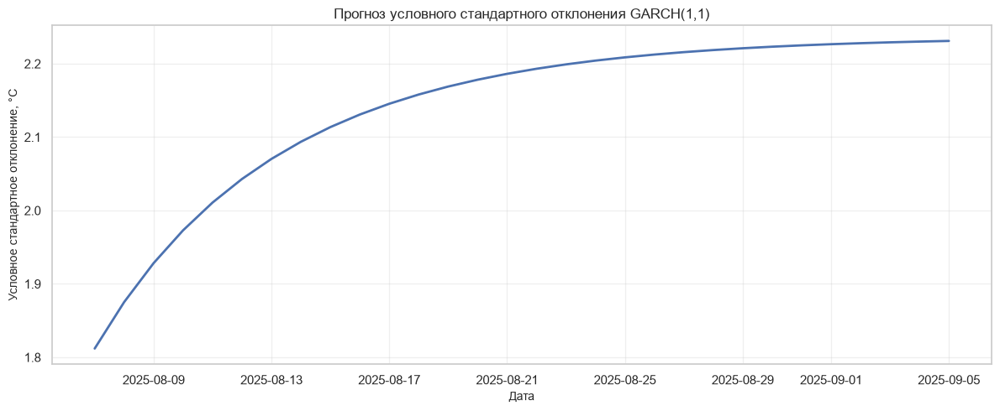


ИТОГИ ЗАДАНИЯ 5
Наблюдений: 731
Обучение: 584
Тест: 147
Горизонты: [1, 7, 30]
Успешно построено моделей: 15

ЛУЧШИЕ МОДЕЛИ:
 1 дней: Prophet | MAE = 0.0186 °C | RMSE = 0.0186 °C
 7 дней: Prophet | MAE = 0.6994 °C | RMSE = 0.8206 °C
30 дней: SARIMA | MAE = 2.3003 °C | RMSE = 2.8707 °C

СТАТУСЫ МОДЕЛЕЙ:
              model status
              Naive     OK
   Seasonal_Naive_7     OK
 Seasonal_Naive_365     OK
               AR_3     OK
               MA_3     OK
           ARMA_3_2     OK
        ARIMA_5_0_2     OK
        ARIMA_3_1_2     OK
             SARIMA     OK
            SARIMAX     OK
                SES     OK
      Holt_Additive     OK
Holt_Multiplicative     OK
              TBATS     OK
            Prophet     OK

Результаты сохранены в:
/Users/lenar_966/Desktop/ML/Practika_3/reports/task5

ЗАДАНИЕ 5 ВЫПОЛНЕНО


In [9]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №3
# ЗАДАНИЕ 5. КЛАССИЧЕСКИЕ МОДЕЛИ ВРЕМЕННЫХ РЯДОВ
# ============================================================

from pathlib import Path
from time import perf_counter
import warnings
import json
import importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing,
    Holt
)

warnings.filterwarnings("ignore")

# ============================================================
# 1. НАСТРОЙКИ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_3"

REPORT_DIR = PROJECT / "reports" / "task5"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "temperature_2m_mean"

HORIZONS = [1, 7, 30]
MAX_HORIZON = max(HORIZONS)

TRAIN_SHARE = 0.8

# SARIMA/SARIMAX с недельным периодом.
SEASONAL_PERIOD = 7

# Уровень интервалов.
ALPHA = 0.05

np.random.seed(42)

print("=" * 75)
print("ЗАДАНИЕ 5. КЛАССИЧЕСКИЕ МОДЕЛИ ВРЕМЕННЫХ РЯДОВ")
print("=" * 75)

# ============================================================
# 2. ПРОВЕРКА ДОПОЛНИТЕЛЬНЫХ БИБЛИОТЕК
# ============================================================

HAS_ARCH = importlib.util.find_spec("arch") is not None
HAS_TBATS = importlib.util.find_spec("tbats") is not None
HAS_PROPHET = importlib.util.find_spec("prophet") is not None

print("\n=== ДОСТУПНОСТЬ БИБЛИОТЕК ===")
print("arch:", HAS_ARCH)
print("tbats:", HAS_TBATS)
print("prophet:", HAS_PROPHET)

# ============================================================
# 3. ЗАГРУЗКА ДАННЫХ
# ============================================================

candidates = [
    PROJECT / "data" / "task1_prepared_series.csv",
    ROOT / "Practika_1" / "data" / "features_dataset.csv",
    ROOT / "Practika_1" / "data" / "processed_dataset.csv",
    ROOT / "Practika_2" / "data" / "features_dataset.csv"
]

SOURCE_PATH = next(
    (p for p in candidates if p.is_file()),
    None
)

if SOURCE_PATH is None:
    raise FileNotFoundError(
        "Не найден исходный файл временного ряда."
    )

df = pd.read_csv(SOURCE_PATH)

date_col = next(
    (c for c in ["date", "timestamp", "time"] if c in df.columns),
    None
)

if date_col is None:
    raise ValueError("Не найдена колонка даты.")

if TARGET not in df.columns:
    raise ValueError("Не найдена целевая переменная.")

df[date_col] = pd.to_datetime(
    df[date_col],
    utc=True,
    errors="coerce"
)

df[TARGET] = pd.to_numeric(
    df[TARGET],
    errors="coerce"
)

df = df.sort_values(date_col).reset_index(drop=True)

if df[date_col].isna().any():
    raise ValueError("Некорректные даты.")

if df[date_col].duplicated().any():
    raise ValueError("Повторяющиеся даты.")

if df[TARGET].isna().any():
    raise ValueError("Пропуски температуры.")

if not (
    df[date_col].diff().dropna()
    == pd.Timedelta(days=1)
).all():
    raise ValueError(
        "Временной ряд должен быть непрерывным."
    )

# Преобразуем даты к tz-naive.
df[date_col] = (
    df[date_col]
    .dt.tz_convert(None)
)

series = pd.Series(
    df[TARGET].to_numpy(dtype=float),
    index=pd.DatetimeIndex(df[date_col]),
    name=TARGET
)

series = series.asfreq("D")

split_index = int(len(series) * TRAIN_SHARE)

train = series.iloc[:split_index]
test = series.iloc[split_index:]

if len(test) < MAX_HORIZON:
    raise ValueError("Недостаточно тестовых наблюдений.")

actual = test.iloc[:MAX_HORIZON].to_numpy()

forecast_dates = test.index[:MAX_HORIZON]

print("\n=== ДАННЫЕ ===")
print("Источник:", SOURCE_PATH)
print("Всего наблюдений:", len(series))
print("Обучающих:", len(train))
print("Тестовых:", len(test))
print("Начало прогноза:", forecast_dates[0])
print("Конец прогноза:", forecast_dates[-1])

# ============================================================
# 4. КАЛЕНДАРНЫЕ ПРИЗНАКИ
# ============================================================

def make_calendar_exog(index):
    """
    Гармонические признаки годовой сезонности.
    Известны заранее, поэтому не вызывают утечку.
    """
    index = pd.DatetimeIndex(index)

    day = index.dayofyear.to_numpy()

    exog = pd.DataFrame(
        {
            "annual_sin_1": np.sin(
                2 * np.pi * day / 365.25
            ),
            "annual_cos_1": np.cos(
                2 * np.pi * day / 365.25
            ),
            "annual_sin_2": np.sin(
                4 * np.pi * day / 365.25
            ),
            "annual_cos_2": np.cos(
                4 * np.pi * day / 365.25
            )
        },
        index=index
    )

    return exog


exog_train = make_calendar_exog(train.index)
exog_future = make_calendar_exog(forecast_dates)

# ============================================================
# 5. ФУНКЦИИ ДЛЯ СОХРАНЕНИЯ ПРОГНОЗОВ
# ============================================================

forecasts = {}
intervals = {}
fit_times = {}
model_status = {}
fitted_models = {}


def register_forecast(
    name,
    predictions,
    lower=None,
    upper=None,
    elapsed=None,
    fitted=None
):
    predictions = np.asarray(
        predictions,
        dtype=float
    ).reshape(-1)

    if len(predictions) != MAX_HORIZON:
        raise ValueError(
            f"{name}: неправильная длина прогноза."
        )

    if not np.isfinite(predictions).all():
        raise ValueError(
            f"{name}: прогноз содержит NaN или inf."
        )

    forecasts[name] = predictions

    if lower is not None and upper is not None:
        lower = np.asarray(lower, dtype=float).reshape(-1)
        upper = np.asarray(upper, dtype=float).reshape(-1)

        if (
            len(lower) == MAX_HORIZON
            and len(upper) == MAX_HORIZON
            and np.isfinite(lower).all()
            and np.isfinite(upper).all()
        ):
            intervals[name] = {
                "lower": lower,
                "upper": upper
            }

    fit_times[name] = elapsed
    model_status[name] = "OK"

    if fitted is not None:
        fitted_models[name] = fitted


def safe_fit(name, function):
    """
    Обучает модель, не останавливая эксперимент
    при ошибке отдельного метода.
    """
    print(f"\nОбучение {name}...")

    start = perf_counter()

    try:
        result = function()
        elapsed = perf_counter() - start

        register_forecast(
            name=name,
            predictions=result["predictions"],
            lower=result.get("lower"),
            upper=result.get("upper"),
            elapsed=elapsed,
            fitted=result.get("fitted")
        )

        print(
            f"  Успешно, {elapsed:.3f} сек."
        )

    except Exception as exc:
        model_status[name] = (
            f"ERROR: {type(exc).__name__}: {exc}"
        )
        print("  Ошибка:", exc)


# ============================================================
# 6. БАЗОВЫЕ МОДЕЛИ
# ============================================================

print("\n=== БАЗОВЫЕ МОДЕЛИ ===")

# Naive: последнее известное значение.
register_forecast(
    "Naive",
    np.repeat(
        train.iloc[-1],
        MAX_HORIZON
    ),
    elapsed=0.0
)

# Seasonal Naive с недельным периодом.
register_forecast(
    "Seasonal_Naive_7",
    np.array([
        train.iloc[-SEASONAL_PERIOD + (i % SEASONAL_PERIOD)]
        for i in range(MAX_HORIZON)
    ]),
    elapsed=0.0
)

# Дополнительная сезонная наивная модель:
# соответствующий день предыдущего года.
# В обучающей выборке достаточно истории.
register_forecast(
    "Seasonal_Naive_365",
    np.array([
        train.iloc[-365 + i]
        for i in range(MAX_HORIZON)
    ]),
    elapsed=0.0
)

# ============================================================
# 7. ОБЩАЯ ФУНКЦИЯ ARIMA
# ============================================================

def fit_arima(order):

    model = ARIMA(
        train,
        order=order,
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit()

    prediction = fitted.get_forecast(
        steps=MAX_HORIZON
    )

    mean = np.asarray(
        prediction.predicted_mean
    )

    ci = prediction.conf_int(
        alpha=ALPHA
    ).to_numpy()

    return {
        "predictions": mean,
        "lower": ci[:, 0],
        "upper": ci[:, 1],
        "fitted": fitted
    }


# ============================================================
# 8. AR, MA, ARMA, ARIMA
# ============================================================

print("\n=== AR / MA / ARMA / ARIMA ===")

safe_fit(
    "AR_3",
    lambda: fit_arima((3, 0, 0))
)

safe_fit(
    "MA_3",
    lambda: fit_arima((0, 0, 3))
)

safe_fit(
    "ARMA_3_2",
    lambda: fit_arima((3, 0, 2))
)

# Поскольку ADF/KPSS допускают d=0,
# основная ARIMA также использует d=0.
safe_fit(
    "ARIMA_5_0_2",
    lambda: fit_arima((5, 0, 2))
)

# Дополнительный вариант с дифференцированием.
# Для d=1 константу в trend не задаём.
def fit_arima_d1():

    model = ARIMA(
        train,
        order=(3, 1, 2),
        trend="n",
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit()

    prediction = fitted.get_forecast(
        steps=MAX_HORIZON
    )

    ci = prediction.conf_int(
        alpha=ALPHA
    ).to_numpy()

    return {
        "predictions": np.asarray(
            prediction.predicted_mean
        ),
        "lower": ci[:, 0],
        "upper": ci[:, 1],
        "fitted": fitted
    }


safe_fit(
    "ARIMA_3_1_2",
    fit_arima_d1
)

# ============================================================
# 9. SARIMA
# ============================================================

print("\n=== SARIMA ===")

def fit_sarima():

    model = SARIMAX(
        train,
        order=(2, 0, 1),
        seasonal_order=(
            1, 0, 1, SEASONAL_PERIOD
        ),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit(
        disp=False,
        maxiter=100
    )

    prediction = fitted.get_forecast(
        steps=MAX_HORIZON
    )

    ci = prediction.conf_int(
        alpha=ALPHA
    ).to_numpy()

    return {
        "predictions": np.asarray(
            prediction.predicted_mean
        ),
        "lower": ci[:, 0],
        "upper": ci[:, 1],
        "fitted": fitted
    }


safe_fit(
    "SARIMA",
    fit_sarima
)

# ============================================================
# 10. SARIMAX
# ============================================================

print("\n=== SARIMAX ===")

def fit_sarimax():

    model = SARIMAX(
        train,
        exog=exog_train,
        order=(2, 0, 1),
        seasonal_order=(
            1, 0, 1, SEASONAL_PERIOD
        ),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit(
        disp=False,
        maxiter=100
    )

    prediction = fitted.get_forecast(
        steps=MAX_HORIZON,
        exog=exog_future
    )

    ci = prediction.conf_int(
        alpha=ALPHA
    ).to_numpy()

    return {
        "predictions": np.asarray(
            prediction.predicted_mean
        ),
        "lower": ci[:, 0],
        "upper": ci[:, 1],
        "fitted": fitted
    }


safe_fit(
    "SARIMAX",
    fit_sarimax
)

# ============================================================
# 11. SES
# ============================================================

print("\n=== ЭКСПОНЕНЦИАЛЬНОЕ СГЛАЖИВАНИЕ ===")

def fit_ses():

    model = SimpleExpSmoothing(
        train,
        initialization_method="estimated"
    )

    fitted = model.fit(
        optimized=True
    )

    return {
        "predictions": np.asarray(
            fitted.forecast(MAX_HORIZON)
        ),
        "fitted": fitted
    }


safe_fit(
    "SES",
    fit_ses
)

# ============================================================
# 12. HOLT ADDITIVE
# ============================================================

def fit_holt_additive():

    model = Holt(
        train,
        exponential=False,
        damped_trend=True,
        initialization_method="estimated"
    )

    fitted = model.fit(
        optimized=True
    )

    return {
        "predictions": np.asarray(
            fitted.forecast(MAX_HORIZON)
        ),
        "fitted": fitted
    }


safe_fit(
    "Holt_Additive",
    fit_holt_additive
)

# ============================================================
# 13. HOLT MULTIPLICATIVE
# ============================================================

# Мультипликативный тренд требует положительных
# значений, поэтому вводим положительный сдвиг.
# Сдвиг рассчитывается только по train.

SHIFT = max(
    0.0,
    1.0 - float(train.min())
)

train_positive = train + SHIFT

def fit_holt_multiplicative():

    model = Holt(
        train_positive,
        exponential=True,
        damped_trend=True,
        initialization_method="estimated"
    )

    fitted = model.fit(
        optimized=True
    )

    predictions = np.asarray(
        fitted.forecast(MAX_HORIZON)
    ) - SHIFT

    return {
        "predictions": predictions,
        "fitted": fitted
    }


safe_fit(
    "Holt_Multiplicative",
    fit_holt_multiplicative
)

# ============================================================
# 14. TBATS
# ============================================================

print("\n=== TBATS ===")

if HAS_TBATS:

    def fit_tbats():

        from tbats import TBATS

        estimator = TBATS(
            seasonal_periods=[7, 365.25],
            use_arma_errors=False,
            use_box_cox=False,
            n_jobs=1
        )

        fitted = estimator.fit(
            train.to_numpy()
        )

        predictions = fitted.forecast(
            steps=MAX_HORIZON
        )

        return {
            "predictions": predictions,
            "fitted": fitted
        }

    safe_fit(
        "TBATS",
        fit_tbats
    )

else:
    model_status["TBATS"] = (
        "SKIPPED: библиотека tbats не установлена"
    )

# ============================================================
# 15. PROPHET
# ============================================================

print("\n=== PROPHET ===")

if HAS_PROPHET:

    def fit_prophet():

        from prophet import Prophet

        prophet_train = pd.DataFrame({
            "ds": train.index,
            "y": train.to_numpy()
        })

        model = Prophet(
            yearly_seasonality=True,
            weekly_seasonality=False,
            daily_seasonality=False,
            interval_width=0.95,
            changepoint_prior_scale=0.05
        )

        model.fit(prophet_train)

        future = pd.DataFrame({
            "ds": forecast_dates
        })

        prediction = model.predict(future)

        return {
            "predictions": prediction["yhat"].to_numpy(),
            "lower": prediction["yhat_lower"].to_numpy(),
            "upper": prediction["yhat_upper"].to_numpy(),
            "fitted": model
        }

    safe_fit(
        "Prophet",
        fit_prophet
    )

else:
    model_status["Prophet"] = (
        "SKIPPED: библиотека prophet не установлена"
    )

# ============================================================
# 16. GARCH(1,1) ДЛЯ ОСТАТКОВ ARIMA
# ============================================================

print("\n=== GARCH(1,1) ===")

garch_results = {}

if HAS_ARCH and "ARIMA_5_0_2" in fitted_models:

    try:
        from arch import arch_model

        arima_fitted = fitted_models["ARIMA_5_0_2"]

        residuals = pd.Series(
            np.asarray(arima_fitted.resid)
        ).replace(
            [np.inf, -np.inf],
            np.nan
        ).dropna()

        # Масштабируем остатки для устойчивости.
        residual_scale = float(residuals.std())

        if residual_scale <= 0:
            raise ValueError(
                "Нулевая дисперсия остатков."
            )

        scaled_residuals = (
            residuals / residual_scale
        )

        garch_model = arch_model(
            scaled_residuals,
            mean="Zero",
            vol="GARCH",
            p=1,
            q=1,
            dist="normal",
            rescale=False
        )

        start = perf_counter()

        garch_fitted = garch_model.fit(
            disp="off"
        )

        garch_time = perf_counter() - start

        garch_forecast = garch_fitted.forecast(
            horizon=MAX_HORIZON,
            reindex=False
        )

        conditional_variance = (
            garch_forecast.variance.iloc[-1]
            .to_numpy(dtype=float)
            * residual_scale ** 2
        )

        conditional_std = np.sqrt(
            np.maximum(
                conditional_variance,
                0
            )
        )

        # GARCH моделирует изменчивость ошибок,
        # а не заменяет прогноз среднего ARIMA.
        # Для визуализации строим приближённые
        # интервалы вокруг прогноза ARIMA.
        #
        # Важно: это не полные интервалы ARIMA+GARCH,
        # так как не учтена вся неопределённость
        # прогнозирования условного среднего.

        arima_mean = forecasts["ARIMA_5_0_2"]

        garch_lower = (
            arima_mean - 1.96 * conditional_std
        )

        garch_upper = (
            arima_mean + 1.96 * conditional_std
        )

        garch_results = {
            "conditional_std": conditional_std,
            "lower": garch_lower,
            "upper": garch_upper,
            "fit_time_sec": garch_time,
            "parameters": {
                k: float(v)
                for k, v in garch_fitted.params.items()
            }
        }

        print("GARCH успешно обучена.")
        print("Время:", round(garch_time, 3), "сек.")
        print("Параметры:")
        print(garch_fitted.params.round(4))

    except Exception as exc:
        print("Ошибка GARCH:", exc)
        garch_results = {
            "error": str(exc)
        }

else:
    print(
        "GARCH пропущена: отсутствует arch "
        "или не обучена базовая ARIMA."
    )

# ============================================================
# 17. СРАВНЕНИЕ MAE И RMSE
# ============================================================

comparison_rows = []
prediction_rows = []

for model_name, prediction in forecasts.items():

    for horizon in HORIZONS:

        y_true = actual[:horizon]
        y_pred = prediction[:horizon]

        mae = mean_absolute_error(
            y_true,
            y_pred
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_true,
                y_pred
            )
        )

        comparison_rows.append({
            "model": model_name,
            "horizon": horizon,
            "MAE": float(mae),
            "RMSE": float(rmse),
            "fit_time_sec": fit_times[model_name]
        })

    for i in range(MAX_HORIZON):

        row = {
            "model": model_name,
            "date": str(
                forecast_dates[i].date()
            ),
            "step": i + 1,
            "actual": float(actual[i]),
            "predicted": float(prediction[i]),
            "error": float(actual[i] - prediction[i])
        }

        if model_name in intervals:
            row["lower_95"] = float(
                intervals[model_name]["lower"][i]
            )
            row["upper_95"] = float(
                intervals[model_name]["upper"][i]
            )

        prediction_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
predictions_df = pd.DataFrame(prediction_rows)

comparison_df = comparison_df.sort_values(
    ["horizon", "MAE"]
).reset_index(drop=True)

print("\n" + "=" * 75)
print("СРАВНЕНИЕ КЛАССИЧЕСКИХ МОДЕЛЕЙ")
print("=" * 75)

print(
    comparison_df.round(4).to_string(
        index=False
    )
)

# ============================================================
# 18. ЛУЧШИЕ МОДЕЛИ ПО ГОРИЗОНТАМ
# ============================================================

best_models = (
    comparison_df
    .sort_values("MAE")
    .groupby("horizon", as_index=False)
    .first()
)

print("\n=== ЛУЧШИЕ МОДЕЛИ ПО MAE ===")

print(
    best_models[
        ["horizon", "model", "MAE", "RMSE"]
    ].round(4).to_string(index=False)
)

# ============================================================
# 19. ГРАФИК СРАВНЕНИЯ MAE
# ============================================================

plt.figure(figsize=(15, 8))

for horizon in HORIZONS:

    subset = comparison_df[
        comparison_df["horizon"] == horizon
    ].sort_values("MAE")

    plt.plot(
        subset["model"],
        subset["MAE"],
        marker="o",
        linewidth=1.8,
        label=f"{horizon} дней"
    )

plt.xticks(rotation=65, ha="right")
plt.ylabel("MAE, °C")
plt.title("Сравнение классических моделей по MAE")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "mae_model_comparison.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 20. ГРАФИК ПРОГНОЗОВ НА 30 ДНЕЙ
# ============================================================

# Показываем 5 лучших моделей по MAE на 30 днях.
top30 = (
    comparison_df[
        comparison_df["horizon"] == 30
    ]
    .nsmallest(5, "MAE")
)

top_model_names = top30["model"].tolist()

plt.figure(figsize=(16, 8))

plt.plot(
    forecast_dates,
    actual,
    color="black",
    linewidth=2.5,
    label="Фактическая температура"
)

for name in top_model_names:

    plt.plot(
        forecast_dates,
        forecasts[name],
        linestyle="--",
        linewidth=1.8,
        label=name
    )

plt.title("Пять лучших моделей: прогноз на 30 дней")
plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "top5_forecasts_30.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 21. ПРОГНОЗНЫЕ ИНТЕРВАЛЫ
# ============================================================

interval_models = [
    name for name in top_model_names
    if name in intervals
]

if not interval_models:
    interval_models = list(intervals.keys())[:3]

if interval_models:

    fig, axes = plt.subplots(
        len(interval_models),
        1,
        figsize=(14, 5 * len(interval_models)),
        squeeze=False
    )

    for i, name in enumerate(interval_models):

        ax = axes[i, 0]

        ax.plot(
            forecast_dates,
            actual,
            color="black",
            label="Факт"
        )

        ax.plot(
            forecast_dates,
            forecasts[name],
            label="Прогноз"
        )

        ax.fill_between(
            forecast_dates,
            intervals[name]["lower"],
            intervals[name]["upper"],
            alpha=0.25,
            label="95% интервал"
        )

        ax.set_title(name)
        ax.set_ylabel("Температура, °C")
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / "prediction_intervals.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

# ============================================================
# 22. ГРАФИК УСЛОВНОЙ ВОЛАТИЛЬНОСТИ GARCH
# ============================================================

if "conditional_std" in garch_results:

    plt.figure(figsize=(12, 5))

    plt.plot(
        forecast_dates,
        garch_results["conditional_std"],
        linewidth=2
    )

    plt.title(
        "Прогноз условного стандартного отклонения GARCH(1,1)"
    )

    plt.xlabel("Дата")
    plt.ylabel("Условное стандартное отклонение, °C")
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / "garch_volatility.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

# ============================================================
# 23. СОХРАНЕНИЕ ТАБЛИЦ
# ============================================================

comparison_df.to_csv(
    REPORT_DIR / "model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

predictions_df.to_csv(
    REPORT_DIR / "model_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

best_models.to_csv(
    REPORT_DIR / "best_models.csv",
    index=False,
    encoding="utf-8-sig"
)

status_df = pd.DataFrame([
    {
        "model": name,
        "status": status
    }
    for name, status in model_status.items()
])

status_df.to_csv(
    REPORT_DIR / "model_status.csv",
    index=False,
    encoding="utf-8-sig"
)

if "conditional_std" in garch_results:

    pd.DataFrame({
        "date": forecast_dates,
        "conditional_std": garch_results["conditional_std"],
        "approx_lower": garch_results["lower"],
        "approx_upper": garch_results["upper"]
    }).to_csv(
        REPORT_DIR / "garch_forecast.csv",
        index=False,
        encoding="utf-8-sig"
    )

# ============================================================
# 24. СВОДНЫЙ JSON
# ============================================================

summary = {
    "task": 5,
    "target": TARGET,
    "source": str(SOURCE_PATH),
    "observations": int(len(series)),
    "train_observations": int(len(train)),
    "test_observations": int(len(test)),
    "forecast_origin": str(train.index[-1].date()),
    "horizons": HORIZONS,
    "evaluation": "single fixed forecast origin",
    "models_successful": list(forecasts.keys()),
    "model_status": model_status,
    "best_models": best_models[
        ["horizon", "model", "MAE", "RMSE"]
    ].to_dict(orient="records")
}

with open(
    REPORT_DIR / "task5_summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 25. ИТОГОВЫЕ РЕЗУЛЬТАТЫ
# ============================================================

print("\n" + "=" * 75)
print("ИТОГИ ЗАДАНИЯ 5")
print("=" * 75)

print("Наблюдений:", len(series))
print("Обучение:", len(train))
print("Тест:", len(test))
print("Горизонты:", HORIZONS)
print("Успешно построено моделей:", len(forecasts))

print("\nЛУЧШИЕ МОДЕЛИ:")

for _, row in best_models.iterrows():

    print(
        f"{int(row['horizon']):2d} дней: "
        f"{row['model']} | "
        f"MAE = {row['MAE']:.4f} °C | "
        f"RMSE = {row['RMSE']:.4f} °C"
    )

print("\nСТАТУСЫ МОДЕЛЕЙ:")

print(
    status_df.to_string(index=False)
)

print("\nРезультаты сохранены в:")
print(REPORT_DIR)

print("\nЗАДАНИЕ 5 ВЫПОЛНЕНО")


### Анализ результатов задания 5

В ходе выполнения пятого задания проведено построение и сравнение классических статистических моделей прогнозирования среднесуточной температуры воздуха в Москве.

Исходный временной ряд содержал 731 ежедневное наблюдение, из которых 584 использовались для обучения, а 147 составляли тестовый период.

В исследовании были успешно реализованы 15 прогнозных моделей, включая AR, MA, ARMA, ARIMA, SARIMA, SARIMAX, SES, Holt, TBATS, Prophet и наивные методы прогнозирования.

Дополнительно предусмотрено моделирование условной дисперсии остатков ARIMA с помощью GARCH(1,1).

Сравнение выполнялось на горизонтах 1, 7 и 30 дней по метрикам MAE и RMSE.

#### 1. Результаты прогнозирования на один день

На горизонте одного дня наилучший результат продемонстрировала модель Prophet:

- MAE = 0,0186 °C;
- RMSE = 0,0186 °C.

Второе место заняла модель MA(3) с ошибкой 1,1135 °C, третье — Seasonal Naive (365) с ошибкой 1,3000 °C.

Остальные модели продемонстрировали более высокие значения ошибок.

Следует отметить, что для горизонта одного дня оценка основана на единственном прогнозируемом наблюдении. Поэтому исключительно низкая ошибка Prophet не позволяет сделать окончательный вывод о её превосходстве.

#### 2. Результаты прогнозирования на семь дней

На горизонте семи дней Prophet сохранила лидерство:

- MAE = 0,6994 °C;
- RMSE = 0,8206 °C.

Второе место заняла Seasonal Naive (365):

- MAE = 1,4857 °C;
- RMSE = 1,5090 °C.

Третье место заняла SARIMA с MAE = 2,6683 °C и RMSE = 2,7499 °C.

Полученные результаты свидетельствуют о высокой эффективности Prophet на рассматриваемом недельном интервале.

Хороший результат сезонной наивной модели также указывает на значимость годовой повторяемости температурных условий.

#### 3. Результаты прогнозирования на 30 дней

На горизонте 30 дней наименьшую ошибку продемонстрировала модель SARIMA:

- MAE = 2,3003 °C;
- RMSE = 2,8707 °C.

Второе место заняла ARIMA(5,0,2) с MAE = 2,7154 °C.

Третье место заняла Prophet с MAE = 2,7278 °C.

Таким образом, на рассматриваемом месячном интервале SARIMA оказалась точнее Prophet приблизительно на 15,7% по MAE.

Полученные результаты показывают, что модели авторегрессионного семейства способны обеспечивать конкурентоспособное качество долгосрочного прогнозирования.

#### 4. Анализ моделей с экзогенными переменными

Модель SARIMAX использовала календарные гармонические признаки годовой сезонности, значения которых известны заранее и не требуют информации о будущей фактической температуре.

Однако в проведённом эксперименте SARIMAX показала более высокие ошибки по сравнению с SARIMA.

На горизонте 30 дней MAE SARIMAX составила 3,8649 °C против 2,3003 °C у SARIMA.

Это свидетельствует о том, что выбранная конфигурация модели с экзогенными признаками не обеспечила улучшения качества на рассматриваемом тестовом интервале.

Для окончательной оценки эффективности экзогенных переменных необходимы дополнительные эксперименты с параметрами модели и несколькими временными окнами.

#### 5. Анализ методов экспоненциального сглаживания

Модели SES, Holt Additive и Holt Multiplicative показали близкие результаты.

На горизонте 30 дней значения MAE находились приблизительно в диапазоне 5,52–5,53 °C.

Полученные результаты указывают на ограниченную эффективность рассматриваемых конфигураций экспоненциального сглаживания для данного прогнозного интервала.

Вместе с тем они не позволяют исключить возможность улучшения качества при использовании других вариантов сезонного сглаживания.

#### 6. Анализ вычислительных затрат

Время обучения моделей существенно различалось.

Наиболее затратной оказалась TBATS — 7,3797 секунды.

Для сравнения:

- Prophet — 0,1878 секунды;
- SARIMA — 0,4493 секунды;
- SARIMAX — 0,9956 секунды;
- ARIMA(5,0,2) — 0,2597 секунды.

В данном эксперименте Prophet и SARIMA продемонстрировали приемлемое сочетание точности и вычислительных затрат.

Однако абсолютное время обучения зависит от аппаратной среды, параметров алгоритмов и особенностей программной реализации.

#### 7. Ограничения эксперимента

Оценка качества выполнялась на одном фиксированном прогнозном окне.

В отличие от задания 4, где прогнозы усреднялись по множеству тестовых точек, в данном задании использовался один момент начала прогнозирования.

Поэтому полученные значения MAE и RMSE не следует напрямую сопоставлять с результатами предыдущего задания.

Кроме того, для GARCH необходимо отдельно интерпретировать результаты моделирования условной дисперсии остатков, поскольку эта модель не предназначена для самостоятельного прогнозирования среднего значения температуры.

### Итоговый вывод

В результате выполнения пятого задания успешно реализованы и сравнены 15 классических моделей прогнозирования временного ряда среднесуточной температуры воздуха в Москве.

Установлено, что на горизонтах одного и семи дней наиболее точной оказалась модель Prophet, продемонстрировавшая MAE = 0,0186 °C и 0,6994 °C соответственно.

На горизонте 30 дней лучшей стала SARIMA с MAE = 2,3003 °C и RMSE = 2,8707 °C.

Дополнительно установлено, что простая сезонная модель Seasonal Naive (365) обеспечивает конкурентоспособную точность на недельном горизонте, что подтверждает целесообразность учёта годовой сезонности.

Для дальнейшего исследования предварительно выбраны модели Prophet, SARIMA и ARIMA(5,0,2).

Окончательный выбор модели будет выполнен после диагностики остатков, проверки адекватности, оценки прогнозных интервалов и проведения бэктестинга на нескольких временных окнах.

## Задание 6. Диагностика остатков и проверка адекватности моделей

### Цель работы

Провести диагностику остатков построенных моделей временных рядов, оценить выполнение статистических предпосылок и определить, насколько полно модели описывают закономерности среднесуточной температуры воздуха в Москве.

### Постановка задачи

Для моделей ARIMA, SARIMA, SARIMAX и Prophet необходимо выполнить следующие проверки:

1. **Тест Льюнга — Бокса (Ljung–Box)** — проверить наличие статистически значимой автокорреляции остатков.
2. **Тест Бройша — Пагана (Breusch–Pagan)** — проверить постоянство дисперсии остатков.
3. **Тест Шапиро — Уилка (Shapiro–Wilk)** — проверить гипотезу о нормальности распределения остатков.
4. **ACF и PACF остатков** — визуально исследовать автокорреляционную и частную автокорреляционную функции.
5. **Q-Q графики** — сравнить распределение остатков с теоретическим нормальным распределением.
6. **Проверку стабильности коэффициентов SARIMAX** — сравнить оценки параметров модели на разных временных подвыборках.

### Статистические гипотезы

**Тест Льюнга — Бокса:**

- H₀: автокорреляция остатков до рассматриваемого лага отсутствует.
- H₁: присутствует автокорреляция хотя бы на одном из рассматриваемых лагов.

**Тест Бройша — Пагана:**

- H₀: дисперсия остатков постоянна относительно выбранных объясняющих переменных.
- H₁: дисперсия остатков зависит от объясняющих переменных.

**Тест Шапиро — Уилка:**

- H₀: остатки имеют нормальное распределение.
- H₁: распределение остатков отличается от нормального.

Уровень статистической значимости принимается равным 0,05.

При p-value меньше 0,05 нулевая гипотеза соответствующего теста отвергается.

### Ожидаемый результат

Таблица результатов статистических тестов, графики диагностики остатков, анализ стабильности параметров SARIMAX и вывод об адекватности исследуемых моделей.

ЗАДАНИЕ 6. ДИАГНОСТИКА ОСТАТКОВ

=== ДАННЫЕ ===
Источник: /Users/lenar_966/Desktop/ML/Practika_3/data/task1_prepared_series.csv
Всего наблюдений: 731
Обучающих: 584
Тестовых: 147
Период обучения: 2024-01-01 00:00:00 — 2025-08-06 00:00:00

=== ОБУЧЕНИЕ МОДЕЛЕЙ ===

Обучение ARIMA_5_0_2...
  Успешно: 0.264 сек.

Обучение SARIMA...
  Успешно: 0.404 сек.

Обучение SARIMAX...


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
18:49:15 - cmdstanpy - INFO - Chain [1] start processing
18:49:15 - cmdstanpy - INFO - Chain [1] done processing


  Успешно: 1.028 сек.

Prophet обучена: 0.111 сек.

=== ОСТАТКИ МОДЕЛЕЙ ===
ARIMA_5_0_2: n=554, mean=0.0145, std=2.2360
SARIMA: n=554, mean=-0.0019, std=2.2748
SARIMAX: n=554, mean=-0.0139, std=2.1599
Prophet: n=554, mean=0.1555, std=3.3443

ТЕСТ ЛЬЮНГА — БОКСА
      model  lag    LB_stat  p_value  autocorrelation_detected
ARIMA_5_0_2   14  12.786074 0.077495                     False
ARIMA_5_0_2   21  16.100891 0.307252                     False
ARIMA_5_0_2   30  25.232012 0.338435                     False
     SARIMA    7  16.586639 0.000250                      True
     SARIMA   14  20.142112 0.017055                      True
     SARIMA   21  25.807614 0.056796                     False
     SARIMA   30  39.226194 0.034961                      True
    SARIMAX    7  11.936563 0.002559                      True
    SARIMAX   14  14.245649 0.113851                     False
    SARIMAX   21  18.694407 0.284828                     False
    SARIMAX   30  34.323406 0.101174         

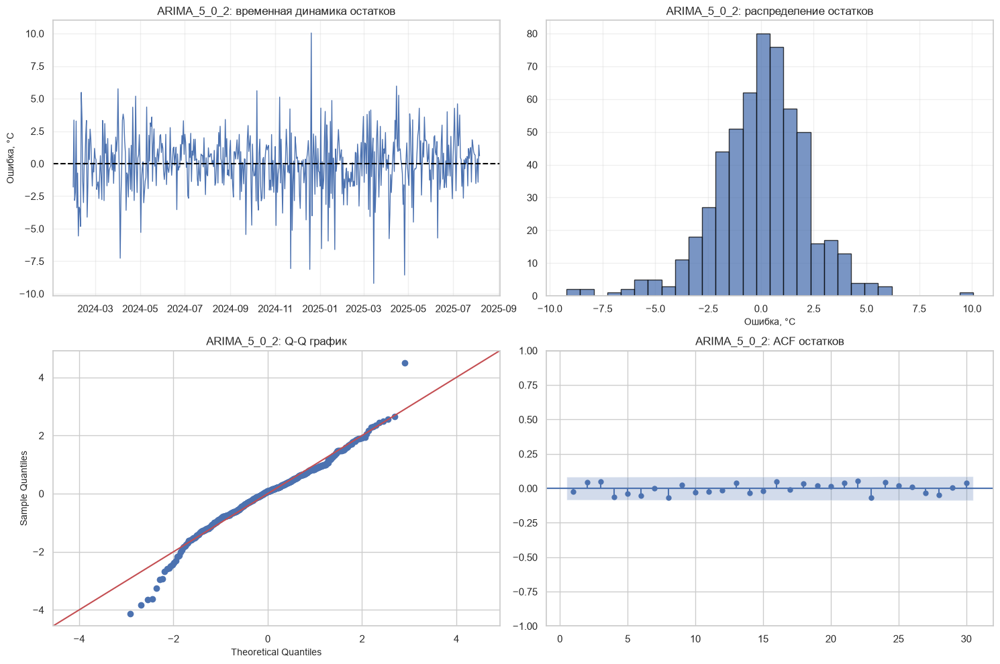

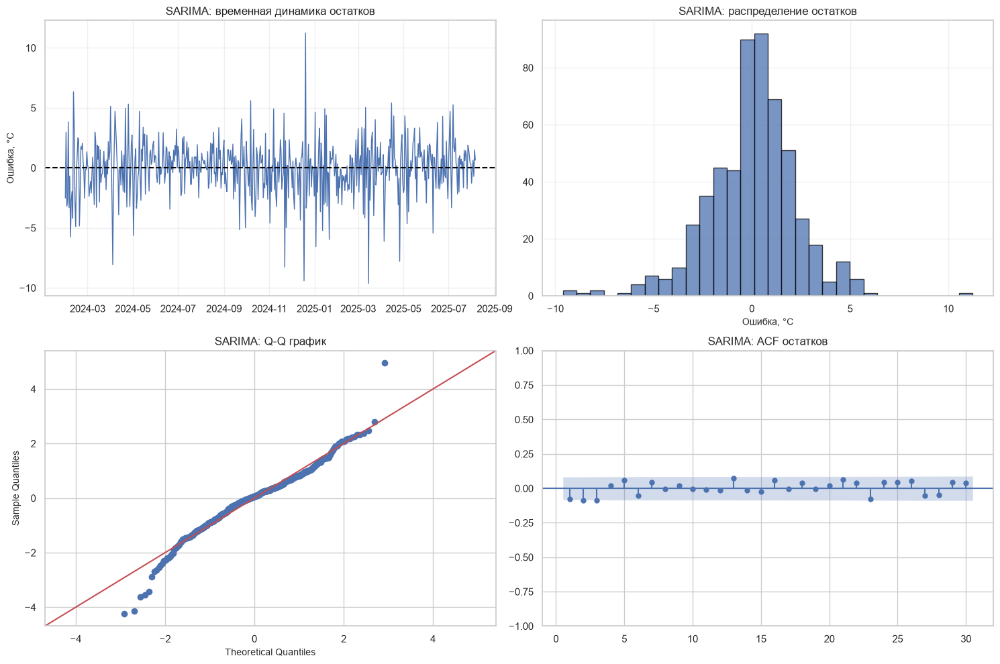

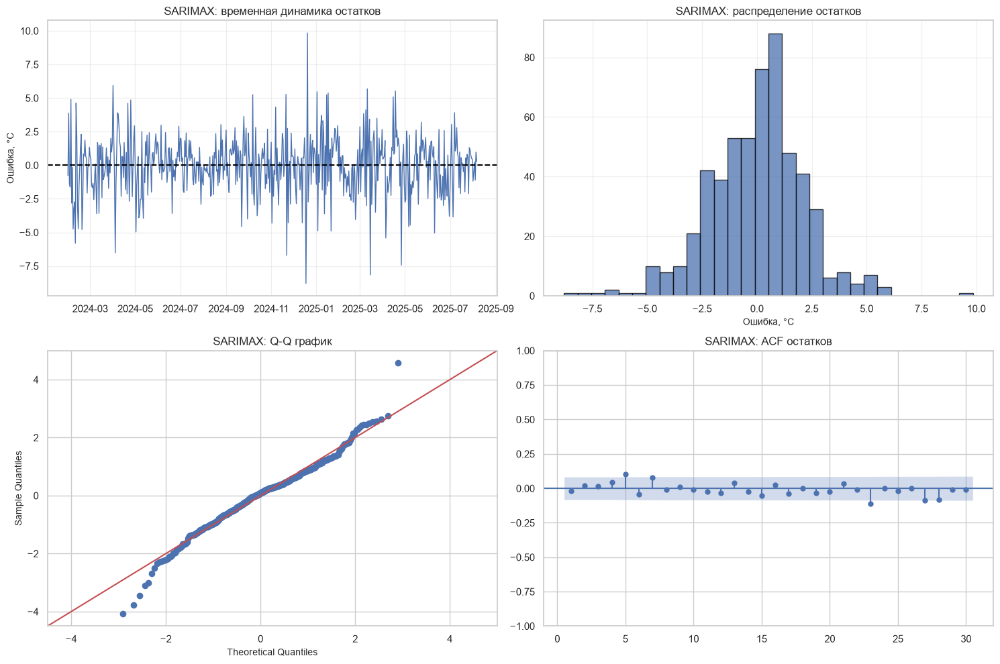

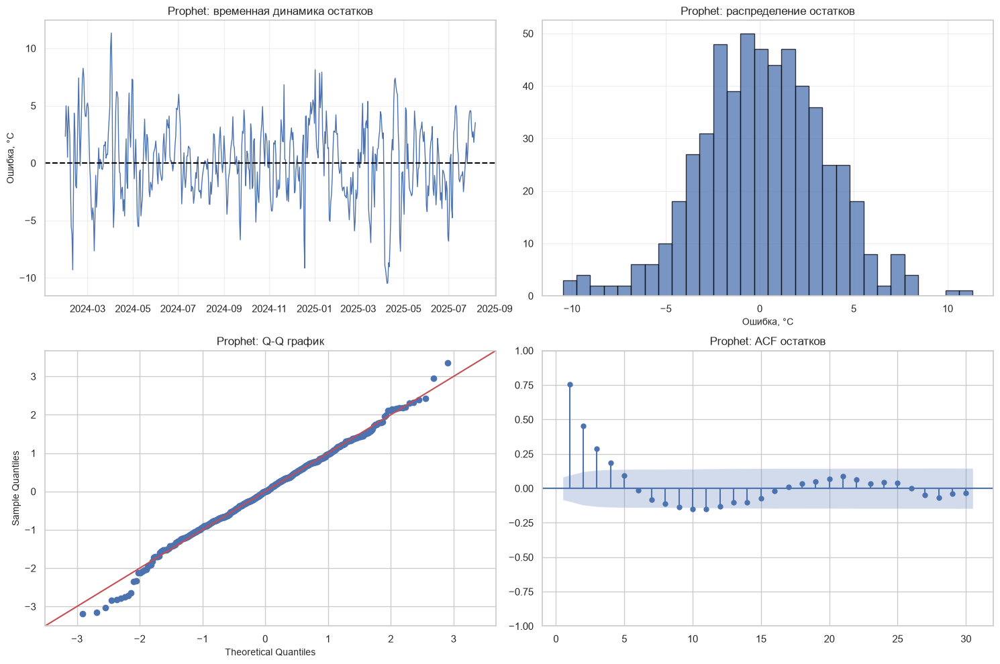

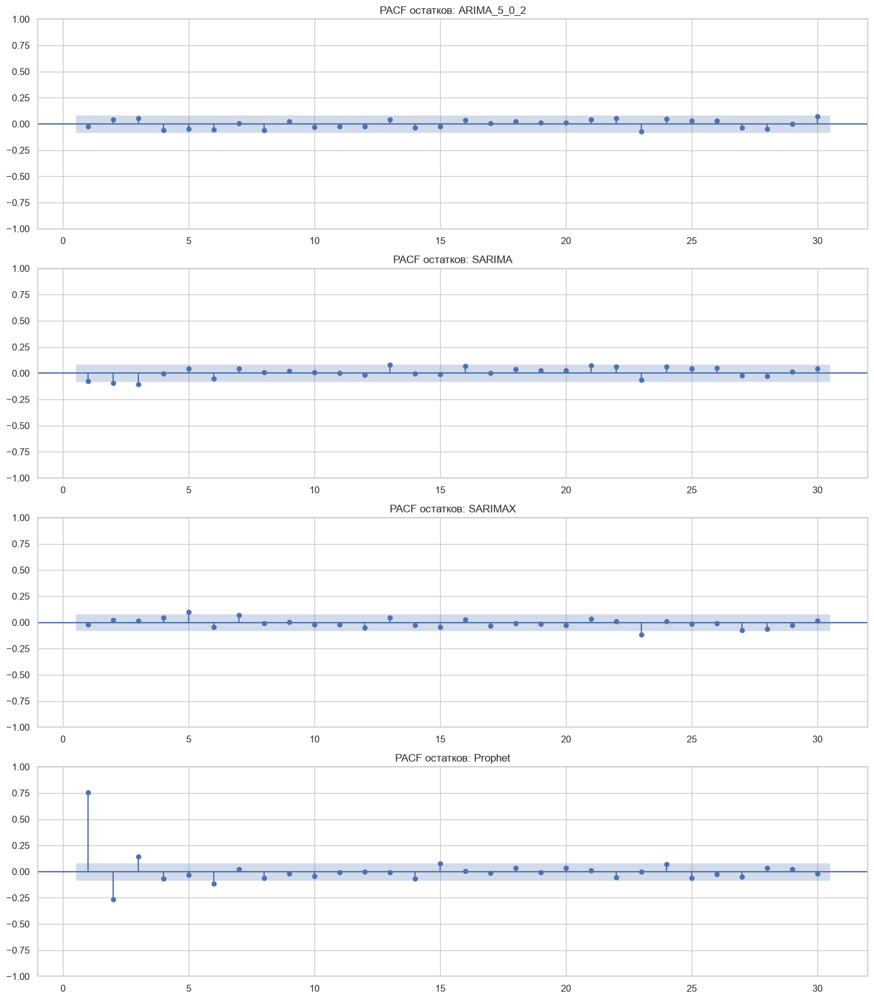


СТАБИЛЬНОСТЬ КОЭФФИЦИЕНТОВ SARIMAX
 train_fraction  observations        AIC        BIC  intercept  annual_sin_1  annual_cos_1  annual_sin_2  annual_cos_2   ar.L1   ar.L2   ma.L1  ar.S.L7  ma.S.L7  sigma2
           0.70           408 1810.38299 1854.26156    1.30534      -3.42169     -11.83869       0.64061       0.69655 0.52970 0.04171 1.95501  0.64381 -0.74883 1.33421
           0.85           496 2232.68745 2278.75835    1.35972      -3.61663     -12.01190       0.44719       0.46633 0.52253 0.11300 1.84182  0.55436 -0.62869 1.60328
           1.00           584 2590.32225 2638.22032    1.31422      -3.62309     -11.85337       0.41091       0.24726 0.51862 0.13190 0.55939  0.54601 -0.61577 5.06432


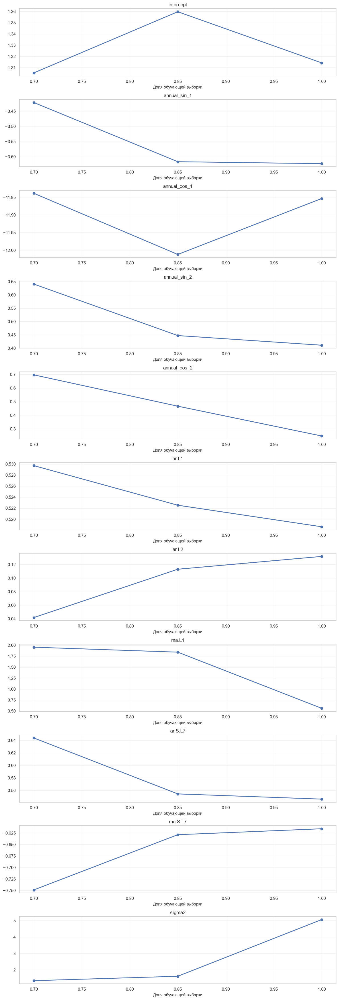


ИТОГИ ЗАДАНИЯ 6
Обучающих наблюдений: 584
Тестовых наблюдений: 147
Моделей проверено: 4
Уровень значимости: 0.05

СВОДНАЯ ТАБЛИЦА:
      model  n_residuals  mean_residual  std_residual  LB_p_30  Shapiro_p     BP_p  LB_pass  Shapiro_pass  BP_pass
ARIMA_5_0_2          554       0.014508      2.236001 0.338435   0.000000 0.000191     True         False    False
     SARIMA          554      -0.001876      2.274811 0.034961   0.000000 0.000471    False         False    False
    SARIMAX          554      -0.013914      2.159876 0.101174   0.000001 0.000055     True         False    False
    Prophet          554       0.155537      3.344333 0.000000   0.082717 0.000000    False          True    False

СТАТУСЫ МОДЕЛЕЙ:
ARIMA_5_0_2: OK
SARIMA: OK
SARIMAX: OK
Prophet: OK

Результаты сохранены:
/Users/lenar_966/Desktop/ML/Practika_3/reports/task6

ЗАДАНИЕ 6 ВЫПОЛНЕНО


In [10]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №3
# ЗАДАНИЕ 6. ДИАГНОСТИКА ОСТАТКОВ И АДЕКВАТНОСТИ МОДЕЛЕЙ
# ============================================================

from pathlib import Path
from time import perf_counter
import warnings
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import shapiro
from statsmodels.api import qqplot
from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    het_breuschpagan
)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.tools import add_constant

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. НАСТРОЙКИ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_3"

REPORT_DIR = PROJECT / "reports" / "task6"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "temperature_2m_mean"
TRAIN_SHARE = 0.8
ALPHA = 0.05

LJUNG_BOX_LAGS = [7, 14, 21, 30]
ACF_LAGS = 30

# Для диагностики исключаем первые наблюдения,
# которые могут содержать ошибки инициализации
# фильтра Калмана или начальных состояний ARIMA.
INITIAL_BURN = 30

np.random.seed(42)

print("=" * 75)
print("ЗАДАНИЕ 6. ДИАГНОСТИКА ОСТАТКОВ")
print("=" * 75)

# ============================================================
# 2. ЗАГРУЗКА ДАННЫХ
# ============================================================

candidates = [
    PROJECT / "data" / "task1_prepared_series.csv",
    ROOT / "Practika_1" / "data" / "features_dataset.csv",
    ROOT / "Practika_1" / "data" / "processed_dataset.csv",
    ROOT / "Practika_2" / "data" / "features_dataset.csv"
]

SOURCE_PATH = next(
    (p for p in candidates if p.is_file()),
    None
)

if SOURCE_PATH is None:
    raise FileNotFoundError(
        "Не найден исходный файл временного ряда."
    )

df = pd.read_csv(SOURCE_PATH)

date_col = next(
    (c for c in ["date", "timestamp", "time"] if c in df.columns),
    None
)

if date_col is None:
    raise ValueError("Не найдена колонка даты.")

if TARGET not in df.columns:
    raise ValueError("Не найдена целевая переменная.")

df[date_col] = pd.to_datetime(
    df[date_col],
    errors="coerce",
    utc=True
)

df[TARGET] = pd.to_numeric(
    df[TARGET],
    errors="coerce"
)

df = df.sort_values(date_col).reset_index(drop=True)

if df[date_col].isna().any():
    raise ValueError("Обнаружены некорректные даты.")

if df[date_col].duplicated().any():
    raise ValueError("Обнаружены повторяющиеся даты.")

if df[TARGET].isna().any():
    raise ValueError("Обнаружены пропуски температуры.")

if not (
    df[date_col].diff().dropna()
    == pd.Timedelta(days=1)
).all():
    raise ValueError(
        "Временной ряд должен быть непрерывным."
    )

df[date_col] = df[date_col].dt.tz_convert(None)

series = pd.Series(
    df[TARGET].to_numpy(dtype=float),
    index=pd.DatetimeIndex(df[date_col]),
    name=TARGET
).asfreq("D")

split_index = int(len(series) * TRAIN_SHARE)

train = series.iloc[:split_index]
test = series.iloc[split_index:]

print("\n=== ДАННЫЕ ===")
print("Источник:", SOURCE_PATH)
print("Всего наблюдений:", len(series))
print("Обучающих:", len(train))
print("Тестовых:", len(test))
print("Период обучения:", train.index.min(), "—", train.index.max())

# ============================================================
# 3. КАЛЕНДАРНЫЕ ПРИЗНАКИ
# ============================================================

def make_calendar_exog(index):

    index = pd.DatetimeIndex(index)
    day = index.dayofyear.to_numpy()

    return pd.DataFrame(
        {
            "annual_sin_1": np.sin(
                2 * np.pi * day / 365.25
            ),
            "annual_cos_1": np.cos(
                2 * np.pi * day / 365.25
            ),
            "annual_sin_2": np.sin(
                4 * np.pi * day / 365.25
            ),
            "annual_cos_2": np.cos(
                4 * np.pi * day / 365.25
            )
        },
        index=index
    )


exog_train = make_calendar_exog(train.index)

# ============================================================
# 4. ОБУЧЕНИЕ ARIMA
# ============================================================

models = {}
residuals_dict = {}
fit_status = {}

print("\n=== ОБУЧЕНИЕ МОДЕЛЕЙ ===")

def fit_model(name, builder):

    print(f"\nОбучение {name}...")

    start = perf_counter()

    try:
        fitted = builder()

        models[name] = fitted
        fit_status[name] = "OK"

        elapsed = perf_counter() - start

        print(
            f"  Успешно: {elapsed:.3f} сек."
        )

    except Exception as exc:
        fit_status[name] = (
            f"ERROR: {type(exc).__name__}: {exc}"
        )
        print("  Ошибка:", exc)


fit_model(
    "ARIMA_5_0_2",
    lambda: ARIMA(
        train,
        order=(5, 0, 2),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit()
)

# ============================================================
# 5. ОБУЧЕНИЕ SARIMA
# ============================================================

fit_model(
    "SARIMA",
    lambda: SARIMAX(
        train,
        order=(2, 0, 1),
        seasonal_order=(1, 0, 1, 7),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(
        disp=False,
        maxiter=100
    )
)

# ============================================================
# 6. ОБУЧЕНИЕ SARIMAX
# ============================================================

def build_sarimax(endog, exog):

    return SARIMAX(
        endog,
        exog=exog,
        order=(2, 0, 1),
        seasonal_order=(1, 0, 1, 7),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(
        disp=False,
        maxiter=100
    )


fit_model(
    "SARIMAX",
    lambda: build_sarimax(
        train,
        exog_train
    )
)

# ============================================================
# 7. ОБУЧЕНИЕ PROPHET
# ============================================================

try:
    from prophet import Prophet

    start = perf_counter()

    prophet_train = pd.DataFrame({
        "ds": train.index,
        "y": train.to_numpy()
    })

    prophet_model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        interval_width=0.95,
        changepoint_prior_scale=0.05
    )

    prophet_model.fit(prophet_train)

    prophet_prediction = prophet_model.predict(
        prophet_train[["ds"]]
    )

    prophet_fitted = pd.Series(
        prophet_prediction["yhat"].to_numpy(),
        index=train.index
    )

    prophet_residuals = train - prophet_fitted

    models["Prophet"] = prophet_model
    fit_status["Prophet"] = "OK"

    print(
        "\nProphet обучена:",
        round(perf_counter() - start, 3),
        "сек."
    )

except Exception as exc:
    fit_status["Prophet"] = (
        f"ERROR: {type(exc).__name__}: {exc}"
    )
    print("\nОшибка Prophet:", exc)

# ============================================================
# 8. ПОЛУЧЕНИЕ ОСТАТКОВ
# ============================================================

for name, fitted in models.items():

    if name == "Prophet":
        residuals = prophet_residuals.copy()
    else:
        residuals = pd.Series(
            np.asarray(fitted.resid),
            index=train.index
        )

    residuals = residuals.iloc[INITIAL_BURN:]

    residuals = residuals.replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna()

    residuals_dict[name] = residuals

print("\n=== ОСТАТКИ МОДЕЛЕЙ ===")

for name, residuals in residuals_dict.items():

    print(
        f"{name}: "
        f"n={len(residuals)}, "
        f"mean={residuals.mean():.4f}, "
        f"std={residuals.std():.4f}"
    )

# ============================================================
# 9. ТЕСТ ЛЬЮНГА — БОКСА
# ============================================================

ljung_rows = []

for name, residuals in residuals_dict.items():

    # Для ARIMA/SARIMA учитываем число
    # оценённых ARMA-параметров при проверке.
    if name == "ARIMA_5_0_2":
        model_df = 7
    elif name in ["SARIMA", "SARIMAX"]:
        model_df = 5
    else:
        model_df = 0

    for lag in LJUNG_BOX_LAGS:

        # Если lag <= model_df, тест с такой
        # поправкой некорректен.
        if lag <= model_df:
            continue

        result = acorr_ljungbox(
            residuals,
            lags=[lag],
            model_df=model_df,
            return_df=True
        )

        p_value = float(
            result["lb_pvalue"].iloc[0]
        )

        statistic = float(
            result["lb_stat"].iloc[0]
        )

        ljung_rows.append({
            "model": name,
            "lag": lag,
            "LB_stat": statistic,
            "p_value": p_value,
            "autocorrelation_detected": p_value < ALPHA
        })

ljung_df = pd.DataFrame(ljung_rows)

print("\n" + "=" * 75)
print("ТЕСТ ЛЬЮНГА — БОКСА")
print("=" * 75)

print(
    ljung_df.round(6).to_string(
        index=False
    )
)

# ============================================================
# 10. ТЕСТ ШАПИРО — УИЛКА
# ============================================================

shapiro_rows = []

for name, residuals in residuals_dict.items():

    statistic, p_value = shapiro(
        residuals.to_numpy()
    )

    shapiro_rows.append({
        "model": name,
        "statistic": float(statistic),
        "p_value": float(p_value),
        "normality_rejected": p_value < ALPHA
    })

shapiro_df = pd.DataFrame(shapiro_rows)

print("\n" + "=" * 75)
print("ТЕСТ ШАПИРО — УИЛКА")
print("=" * 75)

print(
    shapiro_df.round(6).to_string(
        index=False
    )
)

# ============================================================
# 11. ТЕСТ БРОЙША — ПАГАНА
# ============================================================

bp_rows = []

for name, residuals in residuals_dict.items():

    # Используем временной тренд и сезонные
    # гармоники как объясняющие переменные
    # для возможной неоднородности дисперсии.
    aligned_dates = residuals.index

    time_index = np.arange(
        len(residuals),
        dtype=float
    )

    time_index = (
        time_index - time_index.mean()
    ) / max(time_index.std(), 1.0)

    day = aligned_dates.dayofyear.to_numpy()

    X_bp = np.column_stack([
        time_index,
        np.sin(2 * np.pi * day / 365.25),
        np.cos(2 * np.pi * day / 365.25)
    ])

    X_bp = add_constant(
        X_bp,
        has_constant="add"
    )

    lm_stat, lm_p, f_stat, f_p = het_breuschpagan(
        residuals.to_numpy(),
        X_bp
    )

    bp_rows.append({
        "model": name,
        "LM_stat": float(lm_stat),
        "LM_p_value": float(lm_p),
        "F_stat": float(f_stat),
        "F_p_value": float(f_p),
        "heteroskedasticity_detected": lm_p < ALPHA
    })

bp_df = pd.DataFrame(bp_rows)

print("\n" + "=" * 75)
print("ТЕСТ БРОЙША — ПАГАНА")
print("=" * 75)

print(
    bp_df.round(6).to_string(
        index=False
    )
)

# ============================================================
# 12. СВОДНАЯ ТАБЛИЦА ДИАГНОСТИКИ
# ============================================================

summary_rows = []

for name, residuals in residuals_dict.items():

    lb_model = ljung_df[
        ljung_df["model"] == name
    ]

    lb_30 = lb_model[
        lb_model["lag"] == 30
    ]

    shapiro_row = shapiro_df[
        shapiro_df["model"] == name
    ].iloc[0]

    bp_row = bp_df[
        bp_df["model"] == name
    ].iloc[0]

    lb_p_30 = (
        float(lb_30["p_value"].iloc[0])
        if len(lb_30)
        else np.nan
    )

    summary_rows.append({
        "model": name,
        "n_residuals": len(residuals),
        "mean_residual": float(residuals.mean()),
        "std_residual": float(residuals.std()),
        "LB_p_30": lb_p_30,
        "Shapiro_p": float(
            shapiro_row["p_value"]
        ),
        "BP_p": float(
            bp_row["LM_p_value"]
        ),
        "LB_pass": (
            bool(lb_p_30 >= ALPHA)
            if np.isfinite(lb_p_30)
            else False
        ),
        "Shapiro_pass": bool(
            shapiro_row["p_value"] >= ALPHA
        ),
        "BP_pass": bool(
            bp_row["LM_p_value"] >= ALPHA
        )
    })

summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 75)
print("СВОДНАЯ ТАБЛИЦА ДИАГНОСТИКИ")
print("=" * 75)

print(
    summary_df.round(6).to_string(
        index=False
    )
)

# ============================================================
# 13. ГРАФИКИ ОСТАТКОВ
# ============================================================

for name, residuals in residuals_dict.items():

    fig, axes = plt.subplots(
        2, 2,
        figsize=(15, 10)
    )

    # Временная динамика остатков.
    axes[0, 0].plot(
        residuals.index,
        residuals.to_numpy(),
        linewidth=1
    )

    axes[0, 0].axhline(
        0,
        color="black",
        linestyle="--"
    )

    axes[0, 0].set_title(
        f"{name}: временная динамика остатков"
    )

    axes[0, 0].set_ylabel("Ошибка, °C")
    axes[0, 0].grid(alpha=0.3)

    # Гистограмма.
    axes[0, 1].hist(
        residuals.to_numpy(),
        bins=30,
        edgecolor="black",
        alpha=0.75
    )

    axes[0, 1].set_title(
        f"{name}: распределение остатков"
    )

    axes[0, 1].set_xlabel("Ошибка, °C")
    axes[0, 1].grid(alpha=0.3)

    # Q-Q график.
    qqplot(
        residuals.to_numpy(),
        line="45",
        ax=axes[1, 0],
        fit=True
    )

    axes[1, 0].set_title(
        f"{name}: Q-Q график"
    )

    # ACF.
    plot_acf(
        residuals,
        lags=ACF_LAGS,
        ax=axes[1, 1],
        zero=False
    )

    axes[1, 1].set_title(
        f"{name}: ACF остатков"
    )

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / f"{name}_residual_diagnostics.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

# ============================================================
# 14. PACF ОСТАТКОВ
# ============================================================

fig, axes = plt.subplots(
    len(residuals_dict),
    1,
    figsize=(14, 4 * len(residuals_dict)),
    squeeze=False
)

for i, (name, residuals) in enumerate(
    residuals_dict.items()
):

    plot_pacf(
        residuals,
        lags=ACF_LAGS,
        method="ywm",
        ax=axes[i, 0],
        zero=False
    )

    axes[i, 0].set_title(
        f"PACF остатков: {name}"
    )

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "residual_pacf.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 15. СТАБИЛЬНОСТЬ КОЭФФИЦИЕНТОВ SARIMAX
# ============================================================

print("\n" + "=" * 75)
print("СТАБИЛЬНОСТЬ КОЭФФИЦИЕНТОВ SARIMAX")
print("=" * 75)

stability_df = pd.DataFrame()

if "SARIMAX" in models:

    # Сравниваем вложенные обучающие окна:
    # первые 70%, 85% и 100% train.
    fractions = [0.70, 0.85, 1.00]

    parameter_rows = []

    for fraction in fractions:

        end = int(len(train) * fraction)

        subset_y = train.iloc[:end]
        subset_x = exog_train.iloc[:end]

        try:
            fitted = build_sarimax(
                subset_y,
                subset_x
            )

            row = {
                "train_fraction": fraction,
                "observations": end,
                "AIC": float(fitted.aic),
                "BIC": float(fitted.bic)
            }

            for parameter, value in fitted.params.items():
                row[parameter] = float(value)

            parameter_rows.append(row)

        except Exception as exc:
            print(
                f"Ошибка для доли {fraction}: {exc}"
            )

    stability_df = pd.DataFrame(parameter_rows)

    if not stability_df.empty:

        print(
            stability_df.round(5).to_string(
                index=False
            )
        )

        parameter_cols = [
            c for c in stability_df.columns
            if c not in [
                "train_fraction",
                "observations",
                "AIC",
                "BIC"
            ]
        ]

        fig, axes = plt.subplots(
            len(parameter_cols),
            1,
            figsize=(12, 3.2 * len(parameter_cols)),
            squeeze=False
        )

        for i, parameter in enumerate(parameter_cols):

            axes[i, 0].plot(
                stability_df["train_fraction"],
                stability_df[parameter],
                marker="o",
                linewidth=2
            )

            axes[i, 0].set_title(parameter)
            axes[i, 0].set_xlabel(
                "Доля обучающей выборки"
            )
            axes[i, 0].grid(alpha=0.3)

        plt.tight_layout()

        plt.savefig(
            REPORT_DIR / "sarimax_parameter_stability.png",
            dpi=160,
            bbox_inches="tight"
        )

        plt.show()

else:
    print(
        "SARIMAX не обучена. "
        "Проверка стабильности пропущена."
    )

# ============================================================
# 16. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

ljung_df.to_csv(
    REPORT_DIR / "ljung_box_results.csv",
    index=False,
    encoding="utf-8-sig"
)

shapiro_df.to_csv(
    REPORT_DIR / "shapiro_results.csv",
    index=False,
    encoding="utf-8-sig"
)

bp_df.to_csv(
    REPORT_DIR / "breusch_pagan_results.csv",
    index=False,
    encoding="utf-8-sig"
)

summary_df.to_csv(
    REPORT_DIR / "diagnostics_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

if not stability_df.empty:
    stability_df.to_csv(
        REPORT_DIR / "sarimax_parameter_stability.csv",
        index=False,
        encoding="utf-8-sig"
    )

residuals_table = pd.DataFrame({
    name: residuals
    for name, residuals in residuals_dict.items()
})

residuals_table.to_csv(
    REPORT_DIR / "model_residuals.csv",
    encoding="utf-8-sig"
)

# ============================================================
# 17. JSON-ОТЧЁТ
# ============================================================

report = {
    "task": 6,
    "target": TARGET,
    "observations": int(len(series)),
    "train_observations": int(len(train)),
    "test_observations": int(len(test)),
    "alpha": ALPHA,
    "initial_burn": INITIAL_BURN,
    "models": list(residuals_dict.keys()),
    "diagnostics": summary_df.to_dict(
        orient="records"
    ),
    "model_status": fit_status
}

with open(
    REPORT_DIR / "task6_summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        report,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 18. ИТОГОВЫЙ ВЫВОД
# ============================================================

print("\n" + "=" * 75)
print("ИТОГИ ЗАДАНИЯ 6")
print("=" * 75)

print("Обучающих наблюдений:", len(train))
print("Тестовых наблюдений:", len(test))
print("Моделей проверено:", len(residuals_dict))
print("Уровень значимости:", ALPHA)

print("\nСВОДНАЯ ТАБЛИЦА:")

print(
    summary_df.round(6).to_string(
        index=False
    )
)

print("\nСТАТУСЫ МОДЕЛЕЙ:")

for name, status in fit_status.items():
    print(f"{name}: {status}")

print("\nРезультаты сохранены:")
print(REPORT_DIR)

print("\nЗАДАНИЕ 6 ВЫПОЛНЕНО")


### Анализ результатов задания 6

В ходе выполнения шестого задания проведена диагностика остатков четырёх моделей прогнозирования среднесуточной температуры воздуха в Москве: ARIMA(5,0,2), SARIMA, SARIMAX и Prophet.

Исследование выполнялось на обучающей выборке из 584 наблюдений. После исключения первых 30 наблюдений, связанных с инициализацией моделей, для статистической диагностики использовались 554 остатка каждой модели.

Для оценки адекватности применялись тест Льюнга — Бокса, тест Шапиро — Уилка и тест Бройша — Пагана. Дополнительно исследовались автокорреляционная структура остатков и стабильность коэффициентов SARIMAX.

Уровень статистической значимости составлял 0,05.

#### 1. Проверка автокорреляции остатков

Тест Льюнга — Бокса показал, что модель ARIMA(5,0,2) наиболее эффективно устраняет автокорреляцию остатков среди рассмотренных моделей.

Для лагов 14, 21 и 30 получены p-value 0,0775, 0,3073 и 0,3384 соответственно.

Поскольку все значения превышают 0,05, нулевая гипотеза об отсутствии автокорреляции на проверенных лагах не отвергается.

Для SARIMA статистически значимая автокорреляция обнаружена на лагах 7, 14 и 30.

Модель SARIMAX продемонстрировала более благоприятные результаты: на лагах 14, 21 и 30 автокорреляция не выявлена, однако на лаге 7 получено p-value = 0,002559, что указывает на сохранение краткосрочной зависимости.

Наиболее выраженная автокорреляция обнаружена в остатках Prophet. Для всех проверенных лагов p-value было практически равно нулю.

Таким образом, Prophet не полностью описывает временную структуру исследуемого ряда, несмотря на высокую точность прогнозирования на отдельных горизонтах в предыдущем задании.

#### 2. Проверка нормальности распределения

Результаты теста Шапиро — Уилка показали, что нормальность остатков не отвергается только для Prophet.

Для этой модели получено p-value = 0,082717, что превышает установленный уровень значимости.

Для ARIMA, SARIMA и SARIMAX значения p-value оказались меньше 0,05. Следовательно, гипотеза о нормальном распределении их остатков отвергается.

При этом отсутствие нормальности не обязательно делает модель непригодной для точечного прогнозирования, но может влиять на корректность интерпретации прогнозных интервалов.

#### 3. Проверка гомоскедастичности

Тест Бройша — Пагана выявил статистически значимую зависимость дисперсии остатков от выбранных временных и сезонных факторов для всех исследуемых моделей.

Получены следующие p-value:

- ARIMA(5,0,2) — 0,000191;
- SARIMA — 0,000471;
- SARIMAX — 0,000055;
- Prophet — меньше 0,000001.

Во всех случаях нулевая гипотеза о постоянстве дисперсии отвергается.

Полученные результаты свидетельствуют о необходимости дополнительного анализа изменчивости ошибок прогнозирования.

Одним из возможных направлений является использование модели GARCH(1,1) для описания условной дисперсии остатков.

#### 4. Анализ характеристик остатков

Средние значения остатков моделей ARIMA, SARIMA и SARIMAX близки к нулю:

- ARIMA(5,0,2): 0,0145 °C;
- SARIMA: −0,0019 °C;
- SARIMAX: −0,0139 °C.

Для Prophet среднее значение остатков составило 0,1555 °C.

Наименьшее стандартное отклонение остатков наблюдалось у SARIMAX — 2,1599 °C.

Для ARIMA этот показатель составил 2,2360 °C, для SARIMA — 2,2748 °C, а для Prophet — 3,3443 °C.

Следовательно, в рассматриваемой обучающей выборке SARIMAX обеспечила наименьший разброс остатков, хотя это не гарантирует наилучшей точности на будущих данных.

#### 5. Проверка стабильности коэффициентов SARIMAX

Для оценки устойчивости параметров SARIMAX модель была повторно обучена на трёх вложенных временных выборках, составляющих 70%, 85% и 100% обучающего периода.

Анализ показал, что некоторые параметры остаются относительно стабильными.

Например, коэффициент `annual_cos_1` изменялся в диапазоне от −12,0119 до −11,8387, а коэффициент `ar.L1` — от 0,5186 до 0,5297.

В то же время коэффициент `ma.L1` существенно снизился с 1,9550 до 0,5594.

Оценка дисперсии `sigma2` увеличилась с 1,3342 до 5,0643.

Такие изменения свидетельствуют о нестабильности части параметров и необходимости дополнительной проверки спецификации модели.

Следует учитывать, что сравнение коэффициентов на вложенных временных окнах представляет собой предварительный анализ устойчивости, а не формальный статистический тест структурного сдвига.

#### 6. Общая оценка адекватности моделей

По результатам диагностики установлено:

1. ARIMA(5,0,2) наиболее успешно устраняет автокорреляцию остатков на проверенных лагах.
2. SARIMAX демонстрирует сравнительно низкий разброс остатков, однако сохраняет автокорреляцию на лаге 7 и нестабильность части коэффициентов.
3. SARIMA сохраняет статистически значимую автокорреляцию на нескольких лагах.
4. Prophet имеет остатки, для которых нормальность не отвергается, однако в них сохраняется выраженная временная зависимость.
5. Для всех моделей выявлена неоднородность дисперсии относительно исследуемых временных и сезонных факторов.

### Итоговый вывод

В результате выполнения шестого задания проведена комплексная диагностика остатков моделей ARIMA, SARIMA, SARIMAX и Prophet.

Установлено, что ни одна из исследованных моделей не удовлетворяет одновременно всем проверяемым статистическим предпосылкам.

Наиболее благоприятные результаты проверки автокорреляции получены для ARIMA(5,0,2): на лагах 14, 21 и 30 статистически значимая автокорреляция не обнаружена.

Модель SARIMAX продемонстрировала наименьшее стандартное отклонение остатков — 2,1599 °C, но выявлена нестабильность некоторых её параметров.

Для Prophet нормальность остатков не отвергается, однако выявлена выраженная автокорреляция.

Во всех четырёх моделях обнаружена неоднородность дисперсии относительно выбранных объясняющих факторов.

Таким образом, ARIMA(5,0,2) можно рассматривать как наиболее перспективную модель с точки зрения устранения автокорреляции остатков, тогда как SARIMA и Prophet сохраняют интерес благодаря результатам прогнозирования, полученным в задании 5.

Окончательный выбор модели должен основываться на совместной оценке точности прогнозов, статистической адекватности, устойчивости параметров и результатов бэктестинга.

## Задание 7. Расширенная оценка качества прогнозирования

### Цель работы

Провести комплексную оценку качества классических моделей прогнозирования временных рядов, выполнить статистическое сравнение ошибок и сформировать итоговый рейтинг моделей с учётом точности, адекватности и интерпретируемости.

### Постановка задачи

Для моделей ARIMA, SARIMA, SARIMAX и Prophet необходимо рассчитать следующие показатели:

- MAE — средняя абсолютная ошибка.
- RMSE — корень из средней квадратичной ошибки.
- MAPE — средняя абсолютная процентная ошибка.
- MASE — средняя абсолютная масштабированная ошибка.
- SMAPE — симметричная средняя абсолютная процентная ошибка.
- R² — коэффициент детерминации.
- RMSLE — корень из средней квадратичной логарифмической ошибки.

Для статистического сравнения точности моделей используется тест Диболда — Мариано.

Дополнительно формируется интегральный рейтинг на основе трёх критериев:

\[
Score=0.4\cdot Accuracy+0.3\cdot Adequacy+0.3\cdot Interpretability
\]

где:

- Accuracy — нормированная оценка точности прогнозирования;
- Adequacy — оценка статистической адекватности модели;
- Interpretability — экспертная оценка интерпретируемости.

В качестве прикладной метрики рассматривается доля прогнозов, абсолютная ошибка которых не превышает 2 °C.

### Особенности оценки

Температура воздуха может принимать отрицательные и нулевые значения. Поэтому стандартная RMSLE неприменима к исходному ряду, а MAPE становится неопределённой при нулевых фактических значениях и нестабильной вблизи нуля.

Для корректного сравнения модели оцениваются на одинаковых прогнозных датах.

### Ожидаемый результат

Сравнительная таблица метрик, результаты теста Диболда — Мариано, интегральный рейтинг моделей и обоснованный выбор перспективных методов прогнозирования.

ЗАДАНИЕ 7. РАСШИРЕННАЯ ОЦЕНКА КАЧЕСТВА

=== ДАННЫЕ ===
Всего наблюдений: 731
Обучение: 584
Тест: 147
Точек прогноза: 30
Горизонты: [1, 7, 30]

=== ОБУЧЕНИЕ МОДЕЛЕЙ ===
ARIMA_5_0_2: 0.274 сек.
SARIMA: 0.425 сек.


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
18:53:35 - cmdstanpy - INFO - Chain [1] start processing
18:53:35 - cmdstanpy - INFO - Chain [1] done processing


SARIMAX: 1.017 сек.
Prophet: 0.198 сек.

Масштаб MASE: 5.2868

=== ПРОГНОЗИРОВАНИЕ НА ВРЕМЕННЫХ ОКНАХ ===
Обработано окон: 10/30
Обработано окон: 20/30
Обработано окон: 30/30

РАСШИРЕННЫЕ МЕТРИКИ
 horizon       model  n_predictions    MAE   RMSE    MAPE   MASE   SMAPE      R2  RMSLE  within_2C_pct
       1 ARIMA_5_0_2             30 1.5933 2.1246  9.8876 0.3014  9.9925  0.2087 0.1221        76.6667
       1     SARIMAX             30 1.7535 2.2061 11.3062 0.3317 10.8284  0.1468 0.1269        56.6667
       1      SARIMA             30 1.7601 2.2200 11.0128 0.3329 11.1434  0.1360 0.1292        76.6667
       1     Prophet             30 2.7278 3.3675 19.5814 0.5160 17.0158 -0.9879 0.2032        43.3333
       7 ARIMA_5_0_2            210 2.2460 3.0434 14.0958 0.4248 14.4451 -0.6610 0.1816        57.1429
       7      SARIMA            210 2.4352 3.2446 15.2083 0.4606 15.7289 -0.8880 0.1941        53.3333
       7     Prophet            210 2.8467 3.4137 20.3891 0.5385 17.7569 -1.0898 0.

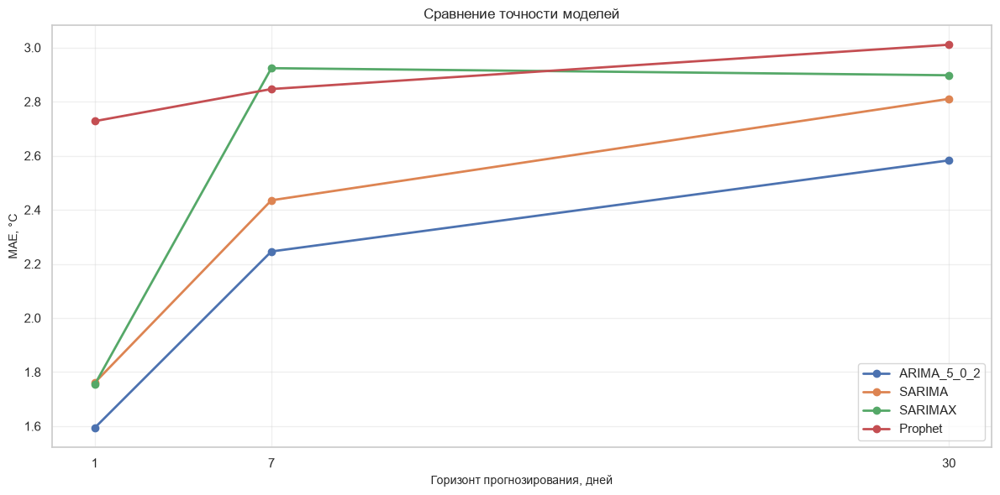

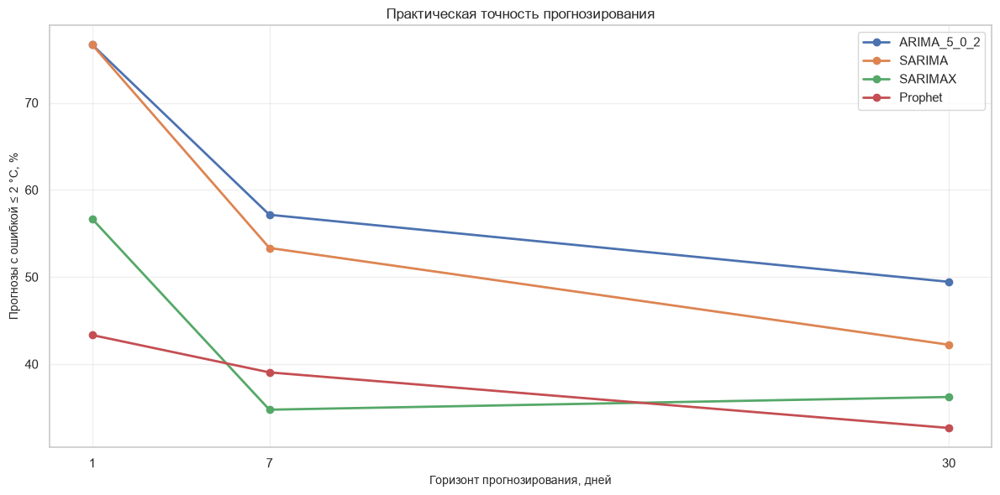

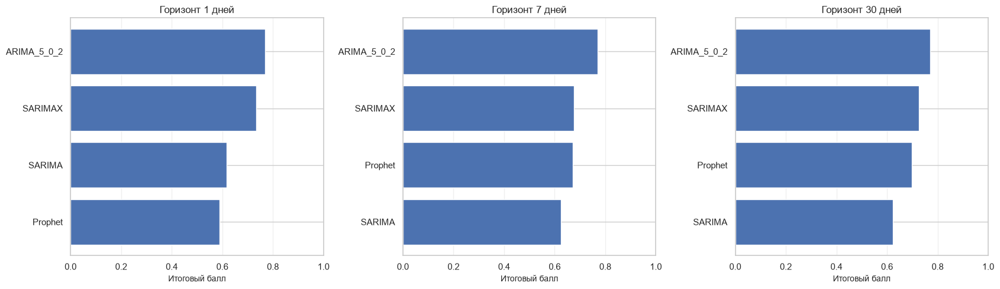


ИТОГИ ЗАДАНИЯ 7
Моделей: 4
Точек начала прогноза: 30
Горизонты: [1, 7, 30]

ЛУЧШИЕ МОДЕЛИ:
 1 дней: ARIMA_5_0_2 | MAE = 1.5933 °C | Score = 0.7700
 7 дней: ARIMA_5_0_2 | MAE = 2.2460 °C | Score = 0.7700
30 дней: ARIMA_5_0_2 | MAE = 2.5828 °C | Score = 0.7700

Результаты сохранены:
/Users/lenar_966/Desktop/ML/Practika_3/reports/task7

ЗАДАНИЕ 7 ВЫПОЛНЕНО


In [11]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №3
# ЗАДАНИЕ 7. РАСШИРЕННАЯ ОЦЕНКА КАЧЕСТВА МОДЕЛЕЙ
# ============================================================

from pathlib import Path
from time import perf_counter
from itertools import combinations
import warnings
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. НАСТРОЙКИ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_3"

REPORT_DIR = PROJECT / "reports" / "task7"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "temperature_2m_mean"

TRAIN_SHARE = 0.8
HORIZONS = [1, 7, 30]

# 30 последовательных точек начала прогноза.
N_ORIGINS = 30

ALPHA = 0.05

# Порог прикладной метрики.
BUSINESS_THRESHOLD = 2.0

# Порог для численной устойчивости SMAPE.
EPS = 1e-8

np.random.seed(42)

print("=" * 75)
print("ЗАДАНИЕ 7. РАСШИРЕННАЯ ОЦЕНКА КАЧЕСТВА")
print("=" * 75)

# ============================================================
# 2. ЗАГРУЗКА ДАННЫХ
# ============================================================

candidates = [
    PROJECT / "data" / "task1_prepared_series.csv",
    ROOT / "Practika_1" / "data" / "features_dataset.csv",
    ROOT / "Practika_1" / "data" / "processed_dataset.csv",
    ROOT / "Practika_2" / "data" / "features_dataset.csv"
]

SOURCE_PATH = next(
    (p for p in candidates if p.is_file()),
    None
)

if SOURCE_PATH is None:
    raise FileNotFoundError(
        "Не найден исходный файл временного ряда."
    )

df = pd.read_csv(SOURCE_PATH)

date_col = next(
    (c for c in ["date", "timestamp", "time"] if c in df.columns),
    None
)

if date_col is None:
    raise ValueError("Не найдена колонка даты.")

if TARGET not in df.columns:
    raise ValueError("Не найдена целевая переменная.")

df[date_col] = pd.to_datetime(
    df[date_col],
    utc=True,
    errors="coerce"
)

df[TARGET] = pd.to_numeric(
    df[TARGET],
    errors="coerce"
)

df = df.sort_values(date_col).reset_index(drop=True)

if (
    df[date_col].isna().any()
    or df[TARGET].isna().any()
    or df[date_col].duplicated().any()
):
    raise ValueError(
        "Некорректные даты, пропуски или дубликаты."
    )

if not (
    df[date_col].diff().dropna()
    == pd.Timedelta(days=1)
).all():
    raise ValueError(
        "Временной ряд должен быть непрерывным."
    )

df[date_col] = df[date_col].dt.tz_convert(None)

series = pd.Series(
    df[TARGET].to_numpy(dtype=float),
    index=pd.DatetimeIndex(df[date_col]),
    name=TARGET
).asfreq("D")

split_index = int(len(series) * TRAIN_SHARE)

train = series.iloc[:split_index]
test = series.iloc[split_index:]

MAX_HORIZON = max(HORIZONS)

if len(test) < N_ORIGINS + MAX_HORIZON - 1:
    raise ValueError(
        "Недостаточно тестовых данных для "
        "выбранного количества прогнозных окон."
    )

print("\n=== ДАННЫЕ ===")
print("Всего наблюдений:", len(series))
print("Обучение:", len(train))
print("Тест:", len(test))
print("Точек прогноза:", N_ORIGINS)
print("Горизонты:", HORIZONS)

# ============================================================
# 3. КАЛЕНДАРНЫЕ ПРИЗНАКИ
# ============================================================

def make_calendar_exog(index):

    index = pd.DatetimeIndex(index)
    day = index.dayofyear.to_numpy()

    return pd.DataFrame(
        {
            "annual_sin_1": np.sin(
                2 * np.pi * day / 365.25
            ),
            "annual_cos_1": np.cos(
                2 * np.pi * day / 365.25
            ),
            "annual_sin_2": np.sin(
                4 * np.pi * day / 365.25
            ),
            "annual_cos_2": np.cos(
                4 * np.pi * day / 365.25
            )
        },
        index=index
    )


exog_train = make_calendar_exog(train.index)

# ============================================================
# 4. ОБУЧЕНИЕ МОДЕЛЕЙ
# ============================================================

print("\n=== ОБУЧЕНИЕ МОДЕЛЕЙ ===")

models = {}
fit_times = {}
model_status = {}

def fit_model(name, builder):

    start = perf_counter()

    try:
        fitted = builder()

        models[name] = fitted
        fit_times[name] = perf_counter() - start
        model_status[name] = "OK"

        print(
            f"{name}: "
            f"{fit_times[name]:.3f} сек."
        )

    except Exception as exc:
        model_status[name] = (
            f"ERROR: {type(exc).__name__}: {exc}"
        )
        print(name, "— ошибка:", exc)


fit_model(
    "ARIMA_5_0_2",
    lambda: ARIMA(
        train,
        order=(5, 0, 2),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit()
)

fit_model(
    "SARIMA",
    lambda: SARIMAX(
        train,
        order=(2, 0, 1),
        seasonal_order=(1, 0, 1, 7),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(
        disp=False,
        maxiter=100
    )
)

fit_model(
    "SARIMAX",
    lambda: SARIMAX(
        train,
        exog=exog_train,
        order=(2, 0, 1),
        seasonal_order=(1, 0, 1, 7),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(
        disp=False,
        maxiter=100
    )
)

# ============================================================
# 5. PROPHET
# ============================================================

try:
    from prophet import Prophet

    start = perf_counter()

    prophet_train = pd.DataFrame({
        "ds": train.index,
        "y": train.to_numpy()
    })

    prophet_model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        interval_width=0.95,
        changepoint_prior_scale=0.05
    )

    prophet_model.fit(prophet_train)

    models["Prophet"] = prophet_model
    fit_times["Prophet"] = perf_counter() - start
    model_status["Prophet"] = "OK"

    print(
        "Prophet:",
        round(fit_times["Prophet"], 3),
        "сек."
    )

except Exception as exc:
    model_status["Prophet"] = (
        f"ERROR: {type(exc).__name__}: {exc}"
    )
    print("Ошибка Prophet:", exc)

if len(models) < 2:
    raise RuntimeError(
        "Для сравнения требуется минимум две модели."
    )

# ============================================================
# 6. ФУНКЦИИ МЕТРИК
# ============================================================

def calculate_metrics(y_true, y_pred, mase_scale):

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    errors = y_true - y_pred

    mae = float(
        np.mean(np.abs(errors))
    )

    rmse = float(
        np.sqrt(np.mean(errors ** 2))
    )

    # MAPE: исключаем нулевые фактические значения.
    nonzero = np.abs(y_true) > EPS

    if nonzero.any():
        mape = float(
            np.mean(
                np.abs(
                    errors[nonzero] / y_true[nonzero]
                )
            ) * 100
        )
    else:
        mape = np.nan

    smape = float(
        np.mean(
            200 * np.abs(errors)
            / (
                np.abs(y_true)
                + np.abs(y_pred)
                + EPS
            )
        )
    )

    mase = (
        mae / mase_scale
        if mase_scale > EPS
        else np.nan
    )

    r2 = (
        float(r2_score(y_true, y_pred))
        if len(y_true) >= 2
        else np.nan
    )

    # Стандартная RMSLE неприменима, если
    # y_true или y_pred содержат отрицательные значения.
    if (
        np.all(y_true >= 0)
        and np.all(y_pred >= 0)
    ):
        rmsle = float(
            np.sqrt(
                np.mean(
                    (
                        np.log1p(y_true)
                        - np.log1p(y_pred)
                    ) ** 2
                )
            )
        )
    else:
        rmsle = np.nan

    business_accuracy = float(
        np.mean(
            np.abs(errors) <= BUSINESS_THRESHOLD
        ) * 100
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "MASE": mase,
        "SMAPE": smape,
        "R2": r2,
        "RMSLE": rmsle,
        "within_2C_pct": business_accuracy
    }


# Масштаб MASE вычисляется только по train.
# Используем сезонный период 365 дней.
MASE_SEASONAL_PERIOD = 365

mase_scale = float(
    np.mean(
        np.abs(
            train.to_numpy()[MASE_SEASONAL_PERIOD:]
            - train.to_numpy()[:-MASE_SEASONAL_PERIOD]
        )
    )
)

print("\nМасштаб MASE:", round(mase_scale, 4))

# ============================================================
# 7. ФУНКЦИЯ ПРОГНОЗА ПО ТЕКУЩЕЙ ТОЧКЕ
# ============================================================

def forecast_at_origin(name, fitted, origin_offset):

    """
    origin_offset=0:
        прогноз после последнего дня train.

    origin_offset>0:
        для ARIMA/SARIMA/SARIMAX обновляем состояние
        фактическими наблюдениями из test,
        не переоценивая коэффициенты.

    Prophet остаётся моделью с фиксированными
    коэффициентами, обученной на исходном train.
    """

    if name == "Prophet":

        start_index = split_index + origin_offset

        future_dates = series.index[
            start_index:start_index + MAX_HORIZON
        ]

        future = pd.DataFrame({
            "ds": future_dates
        })

        prediction = fitted.predict(future)

        return prediction["yhat"].to_numpy()

    if origin_offset == 0:
        updated = fitted
    else:

        new_y = test.iloc[:origin_offset]

        if name == "SARIMAX":

            new_x = make_calendar_exog(new_y.index)

            updated = fitted.append(
                new_y,
                exog=new_x,
                refit=False
            )

        else:
            updated = fitted.append(
                new_y,
                refit=False
            )

    if name == "SARIMAX":

        future_dates = series.index[
            split_index + origin_offset:
            split_index + origin_offset + MAX_HORIZON
        ]

        future_exog = make_calendar_exog(
            future_dates
        )

        prediction = updated.forecast(
            steps=MAX_HORIZON,
            exog=future_exog
        )

    else:
        prediction = updated.forecast(
            steps=MAX_HORIZON
        )

    return np.asarray(prediction, dtype=float)


# ============================================================
# 8. ПРОГНОЗИРОВАНИЕ НА 30 ОКНАХ
# ============================================================

print("\n=== ПРОГНОЗИРОВАНИЕ НА ВРЕМЕННЫХ ОКНАХ ===")

prediction_rows = []

for origin_offset in range(N_ORIGINS):

    origin_index = split_index + origin_offset - 1

    origin_date = series.index[origin_index]

    actual_values = series.iloc[
        origin_index + 1:
        origin_index + 1 + MAX_HORIZON
    ].to_numpy()

    for name, fitted in models.items():

        predictions = forecast_at_origin(
            name,
            fitted,
            origin_offset
        )

        if len(predictions) != MAX_HORIZON:
            raise ValueError(
                f"Неверная длина прогноза: {name}"
            )

        for step in range(MAX_HORIZON):

            prediction_rows.append({
                "origin": origin_offset,
                "origin_date": str(origin_date.date()),
                "forecast_date": str(
                    series.index[origin_index + step + 1].date()
                ),
                "model": name,
                "step": step + 1,
                "actual": float(actual_values[step]),
                "predicted": float(predictions[step]),
                "error": float(
                    actual_values[step] - predictions[step]
                )
            })

    if (origin_offset + 1) % 10 == 0:
        print(
            f"Обработано окон: {origin_offset + 1}/{N_ORIGINS}"
        )

predictions_df = pd.DataFrame(prediction_rows)

# ============================================================
# 9. РАСЧЁТ МЕТРИК ПО ГОРИЗОНТАМ
# ============================================================

metrics_rows = []

for horizon in HORIZONS:

    for name in models.keys():

        subset = predictions_df[
            (predictions_df["model"] == name)
            & (predictions_df["step"] <= horizon)
        ].copy()

        metrics = calculate_metrics(
            subset["actual"],
            subset["predicted"],
            mase_scale
        )

        metrics_rows.append({
            "horizon": horizon,
            "model": name,
            "n_predictions": len(subset),
            **metrics
        })

metrics_df = pd.DataFrame(metrics_rows)

metrics_df = metrics_df.sort_values(
    ["horizon", "MAE"]
).reset_index(drop=True)

print("\n" + "=" * 75)
print("РАСШИРЕННЫЕ МЕТРИКИ")
print("=" * 75)

print(
    metrics_df.round(4).to_string(
        index=False
    )
)

# ============================================================
# 10. ТЕСТ ДИБОЛДА — МАРИАНО
# ============================================================

def diebold_mariano(
    errors_a,
    errors_b,
    horizon=1,
    loss="squared"
):
    """
    Приближённый тест Диболда — Мариано.

    Используется разность потерь:
        d_t = L(e_a) - L(e_b)

    Для перекрывающихся прогнозов
    применяем HAC-оценку дисперсии
    с усечением лагов horizon - 1.

    Это асимптотическая версия теста.
    """

    errors_a = np.asarray(
        errors_a,
        dtype=float
    )

    errors_b = np.asarray(
        errors_b,
        dtype=float
    )

    if loss == "absolute":
        d = np.abs(errors_a) - np.abs(errors_b)
    else:
        d = errors_a ** 2 - errors_b ** 2

    n = len(d)

    if n < 10:
        return np.nan, np.nan

    mean_d = np.mean(d)
    centered = d - mean_d

    max_lag = min(horizon - 1, n - 1)

    gamma0 = np.mean(centered ** 2)

    long_run_variance = gamma0

    for lag in range(1, max_lag + 1):

        gamma = np.mean(
            centered[lag:]
            * centered[:-lag]
        )

        # Вес Бартлетта.
        weight = 1 - lag / (max_lag + 1)

        long_run_variance += (
            2 * weight * gamma
        )

    if long_run_variance <= 0:
        return np.nan, np.nan

    statistic = (
        mean_d
        / np.sqrt(long_run_variance / n)
    )

    p_value = 2 * (
        1 - norm.cdf(abs(statistic))
    )

    return float(statistic), float(p_value)


dm_rows = []

# Для DM используем ошибки одного и того же
# конкретного шага, а не смешиваем разные шаги.
for horizon in HORIZONS:

    step_df = predictions_df[
        predictions_df["step"] == horizon
    ]

    pivot = step_df.pivot(
        index="origin",
        columns="model",
        values="error"
    )

    for model_a, model_b in combinations(
        models.keys(),
        2
    ):

        aligned = pivot[
            [model_a, model_b]
        ].dropna()

        statistic, p_value = diebold_mariano(
            aligned[model_a],
            aligned[model_b],
            horizon=horizon,
            loss="squared"
        )

        dm_rows.append({
            "horizon": horizon,
            "model_a": model_a,
            "model_b": model_b,
            "DM_stat": statistic,
            "p_value": p_value,
            "significant_05": (
                bool(p_value < ALPHA)
                if np.isfinite(p_value)
                else False
            )
        })

dm_df = pd.DataFrame(dm_rows)

print("\n" + "=" * 75)
print("ТЕСТ ДИБОЛДА — МАРИАНО")
print("=" * 75)

print(
    dm_df.round(6).to_string(
        index=False
    )
)

# ============================================================
# 11. ОЦЕНКА СТАТИСТИЧЕСКОЙ АДЕКВАТНОСТИ
# ============================================================

# Используем результаты задания 6.
diagnostics_path = (
    PROJECT
    / "reports"
    / "task6"
    / "diagnostics_summary.csv"
)

if not diagnostics_path.exists():
    raise FileNotFoundError(
        "Не найдены результаты задания 6: "
        "diagnostics_summary.csv"
    )

diagnostics_df = pd.read_csv(
    diagnostics_path
)

def to_bool(value):

    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    return str(value).strip().lower() in [
        "true", "1", "yes"
    ]


adequacy_rows = []

for name in models.keys():

    row = diagnostics_df[
        diagnostics_df["model"] == name
    ]

    if row.empty:
        raise ValueError(
            f"Нет диагностики для модели {name}."
        )

    row = row.iloc[0]

    lb = to_bool(row["LB_pass"])
    shapiro_ok = to_bool(row["Shapiro_pass"])
    bp = to_bool(row["BP_pass"])

    # Доля пройденных диагностических проверок.
    adequacy_score = np.mean([
        lb,
        shapiro_ok,
        bp
    ])

    adequacy_rows.append({
        "model": name,
        "adequacy_score": float(adequacy_score),
        "LB_pass": lb,
        "Shapiro_pass": shapiro_ok,
        "BP_pass": bp
    })

adequacy_df = pd.DataFrame(adequacy_rows)

# ============================================================
# 12. ЭКСПЕРТНАЯ ИНТЕРПРЕТИРУЕМОСТЬ
# ============================================================

# Шкала от 0 до 1.
# Это экспертная оценка, а не статистическая метрика.

INTERPRETABILITY = {
    "ARIMA_5_0_2": 0.90,
    "SARIMA": 0.85,
    "SARIMAX": 0.90,
    "Prophet": 0.85
}

# ============================================================
# 13. ИНТЕГРАЛЬНЫЙ РЕЙТИНГ
# ============================================================

ranking_rows = []

for horizon in HORIZONS:

    horizon_metrics = metrics_df[
        metrics_df["horizon"] == horizon
    ].copy()

    # Точность нормируем по MAE:
    # лучшая модель получает 1.
    # Остальные — отношение лучшей MAE к своей.
    best_mae = horizon_metrics["MAE"].min()

    for _, row in horizon_metrics.iterrows():

        name = row["model"]

        accuracy_score = (
            best_mae / row["MAE"]
            if row["MAE"] > EPS
            else 1.0
        )

        adequacy_score = float(
            adequacy_df.loc[
                adequacy_df["model"] == name,
                "adequacy_score"
            ].iloc[0]
        )

        interpretability_score = (
            INTERPRETABILITY[name]
        )

        final_score = (
            0.4 * accuracy_score
            + 0.3 * adequacy_score
            + 0.3 * interpretability_score
        )

        ranking_rows.append({
            "horizon": horizon,
            "model": name,
            "MAE": row["MAE"],
            "accuracy_score": accuracy_score,
            "adequacy_score": adequacy_score,
            "interpretability_score": interpretability_score,
            "final_score": final_score
        })

ranking_df = pd.DataFrame(ranking_rows)

ranking_df = ranking_df.sort_values(
    ["horizon", "final_score"],
    ascending=[True, False]
).reset_index(drop=True)

ranking_df["rank"] = (
    ranking_df.groupby("horizon").cumcount() + 1
)

print("\n" + "=" * 75)
print("ИНТЕГРАЛЬНЫЙ РЕЙТИНГ МОДЕЛЕЙ")
print("=" * 75)

print(
    ranking_df.round(4).to_string(
        index=False
    )
)

# ============================================================
# 14. ЛУЧШИЕ МОДЕЛИ ПО РЕЙТИНГУ
# ============================================================

best_models = ranking_df[
    ranking_df["rank"] == 1
].copy()

print("\n=== ЛУЧШИЕ МОДЕЛИ ПО ИНТЕГРАЛЬНОМУ РЕЙТИНГУ ===")

print(
    best_models[
        [
            "horizon",
            "model",
            "MAE",
            "final_score"
        ]
    ].round(4).to_string(index=False)
)

# ============================================================
# 15. ГРАФИК MAE
# ============================================================

plt.figure(figsize=(12, 6))

for name in models.keys():

    subset = metrics_df[
        metrics_df["model"] == name
    ].sort_values("horizon")

    plt.plot(
        subset["horizon"],
        subset["MAE"],
        marker="o",
        linewidth=2,
        label=name
    )

plt.xticks(HORIZONS)
plt.xlabel("Горизонт прогнозирования, дней")
plt.ylabel("MAE, °C")
plt.title("Сравнение точности моделей")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "mae_comparison.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 16. ГРАФИК ПРИКЛАДНОЙ МЕТРИКИ
# ============================================================

plt.figure(figsize=(12, 6))

for name in models.keys():

    subset = metrics_df[
        metrics_df["model"] == name
    ].sort_values("horizon")

    plt.plot(
        subset["horizon"],
        subset["within_2C_pct"],
        marker="o",
        linewidth=2,
        label=name
    )

plt.xticks(HORIZONS)
plt.xlabel("Горизонт прогнозирования, дней")
plt.ylabel("Прогнозы с ошибкой ≤ 2 °C, %")
plt.title("Практическая точность прогнозирования")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "business_accuracy.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 17. ГРАФИК ИНТЕГРАЛЬНОГО РЕЙТИНГА
# ============================================================

fig, axes = plt.subplots(
    1, len(HORIZONS),
    figsize=(17, 5)
)

for i, horizon in enumerate(HORIZONS):

    subset = ranking_df[
        ranking_df["horizon"] == horizon
    ].sort_values("final_score")

    axes[i].barh(
        subset["model"],
        subset["final_score"]
    )

    axes[i].set_title(
        f"Горизонт {horizon} дней"
    )

    axes[i].set_xlabel("Итоговый балл")
    axes[i].set_xlim(0, 1)
    axes[i].grid(
        axis="x",
        alpha=0.3
    )

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "integrated_ranking.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 18. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

metrics_df.to_csv(
    REPORT_DIR / "extended_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

predictions_df.to_csv(
    REPORT_DIR / "all_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

dm_df.to_csv(
    REPORT_DIR / "diebold_mariano.csv",
    index=False,
    encoding="utf-8-sig"
)

ranking_df.to_csv(
    REPORT_DIR / "integrated_ranking.csv",
    index=False,
    encoding="utf-8-sig"
)

best_models.to_csv(
    REPORT_DIR / "best_models.csv",
    index=False,
    encoding="utf-8-sig"
)

adequacy_df.to_csv(
    REPORT_DIR / "adequacy_scores.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 19. JSON-ОТЧЁТ
# ============================================================

summary = {
    "task": 7,
    "target": TARGET,
    "observations": int(len(series)),
    "train_observations": int(len(train)),
    "test_observations": int(len(test)),
    "n_origins": N_ORIGINS,
    "horizons": HORIZONS,
    "mase_scale": mase_scale,
    "business_threshold_celsius": BUSINESS_THRESHOLD,
    "ranking_weights": {
        "accuracy": 0.4,
        "adequacy": 0.3,
        "interpretability": 0.3
    },
    "best_models": best_models[
        [
            "horizon",
            "model",
            "MAE",
            "final_score"
        ]
    ].to_dict(orient="records"),
    "model_status": model_status
}

with open(
    REPORT_DIR / "task7_summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 20. ИТОГИ
# ============================================================

print("\n" + "=" * 75)
print("ИТОГИ ЗАДАНИЯ 7")
print("=" * 75)

print("Моделей:", len(models))
print("Точек начала прогноза:", N_ORIGINS)
print("Горизонты:", HORIZONS)

print("\nЛУЧШИЕ МОДЕЛИ:")

for _, row in best_models.iterrows():

    print(
        f"{int(row['horizon']):2d} дней: "
        f"{row['model']} | "
        f"MAE = {row['MAE']:.4f} °C | "
        f"Score = {row['final_score']:.4f}"
    )

print("\nРезультаты сохранены:")
print(REPORT_DIR)

print("\nЗАДАНИЕ 7 ВЫПОЛНЕНО")


### Анализ результатов задания 7

В ходе выполнения седьмого задания проведена расширенная оценка качества четырёх моделей прогнозирования среднесуточной температуры воздуха в Москве: ARIMA(5,0,2), SARIMA, SARIMAX и Prophet.

Исследование выполнялось на 30 последовательных точках начала прогнозирования с горизонтами 1, 7 и 30 дней.

Для сравнения использовались метрики MAE, RMSE, MAPE, MASE, SMAPE, R², RMSLE и доля прогнозов с абсолютной ошибкой не более 2 °C.

Дополнительно проведено попарное сравнение моделей с помощью приближённого теста Диболда — Мариано и сформирован интегральный рейтинг с весами 40% для точности, 30% для статистической адекватности и 30% для интерпретируемости.

#### 1. Результаты прогнозирования на один день

На горизонте одного дня наиболее точной оказалась модель ARIMA(5,0,2):

- MAE = 1,5933 °C;
- RMSE = 2,1246 °C;
- MAPE = 9,8876%;
- MASE = 0,3014;
- SMAPE = 9,9925%;
- R² = 0,2087.

Доля прогнозов с абсолютной ошибкой не более 2 °C составила 76,67%.

Второе место по MAE заняла SARIMAX с результатом 1,7535 °C, третье — SARIMA с результатом 1,7601 °C.

Prophet показала наибольшую ошибку среди рассматриваемых моделей — MAE = 2,7278 °C.

Таким образом, на однодневном горизонте ARIMA продемонстрировала наилучшее качество прогнозирования.

#### 2. Результаты прогнозирования на семь дней

На горизонте семи дней ARIMA(5,0,2) также сохранила лидерство:

- MAE = 2,2460 °C;
- RMSE = 3,0434 °C;
- MASE = 0,4248;
- SMAPE = 14,4451%;
- R² = −0,6610.

Второе место заняла SARIMA с MAE = 2,4352 °C.

Модели Prophet и SARIMAX продемонстрировали более высокие ошибки — 2,8467 °C и 2,9238 °C соответственно.

Доля прогнозов ARIMA с абсолютной ошибкой не более 2 °C составила 57,14%.

Отрицательное значение R² указывает на то, что качество прогнозирования по квадратичной функции потерь уступает прогнозу постоянного среднего значения на рассматриваемой оценочной выборке.

#### 3. Результаты прогнозирования на 30 дней

На горизонте 30 дней ARIMA(5,0,2) вновь продемонстрировала минимальную среднюю абсолютную ошибку:

- MAE = 2,5828 °C;
- RMSE = 3,3423 °C;
- MAPE = 20,1218%;
- MASE = 0,4885;
- SMAPE = 18,7534%;
- R² = −0,1941.

Второе место по MAE заняла SARIMA с результатом 2,8102 °C.

SARIMAX показала MAE = 2,8976 °C, а Prophet — 3,0105 °C.

Доля прогнозов ARIMA с абсолютной ошибкой не более 2 °C составила 49,44%.

Таким образом, на длинном горизонте ARIMA сохранила преимущество относительно остальных исследуемых моделей, однако абсолютная точность прогнозирования снизилась.

#### 4. Анализ масштабированной ошибки MASE

Для ARIMA значения MASE составили:

- 1 день — 0,3014;
- 7 дней — 0,4248;
- 30 дней — 0,4885.

Все значения меньше единицы.

Это означает, что средняя абсолютная ошибка модели меньше среднего абсолютного сезонного изменения исходного ряда на обучающей выборке при использовании сезонного периода 365 дней.

Полученный результат свидетельствует о преимуществе модели относительно выбранного масштабного ориентира.

Однако для окончательного сравнения с сезонной наивной моделью необходимо оценить обе модели на одинаковых тестовых окнах.

#### 5. Анализ прикладной метрики

В качестве прикладного показателя использовалась доля прогнозов с абсолютной ошибкой не более 2 °C.

Для ARIMA(5,0,2) получены следующие результаты:

- 1 день — 76,67%;
- 7 дней — 57,14%;
- 30 дней — 49,44%.

С увеличением горизонта прогнозирования доля достаточно точных прогнозов уменьшается.

Это подтверждает, что модель наиболее эффективна при краткосрочном прогнозировании, тогда как на более длительных горизонтах неопределённость возрастает.

#### 6. Тест Диболда — Мариано

Для статистического сравнения прогнозных ошибок моделей применялся приближённый тест Диболда — Мариано.

На горизонте одного дня обнаружены статистически значимые различия между Prophet и остальными моделями при уровне значимости 0,05.

На горизонте семи дней для пары ARIMA и SARIMA получено p-value = 0,047594.

При этом большинство остальных сравнений не продемонстрировали статистически значимых различий.

На горизонте 30 дней были получены численно неустойчивые значения статистики, включая чрезвычайно большие значения и неопределённые результаты.

Поэтому результаты теста для горизонта 30 дней не используются для окончательных статистических выводов.

Для более надёжного сравнения необходимо увеличить число прогнозных окон и применить устойчивую оценку долгосрочной дисперсии разности потерь.

#### 7. Интегральный рейтинг моделей

Для формирования итогового рейтинга использовались следующие веса:

- точность прогнозирования — 0,4;
- статистическая адекватность — 0,3;
- интерпретируемость — 0,3.

По результатам расчёта ARIMA(5,0,2) заняла первое место на всех горизонтах с интегральным баллом 0,7700.

На втором месте находилась SARIMAX с баллами 0,7335, 0,6773 и 0,7265 для горизонтов 1, 7 и 30 дней соответственно.

Полученные результаты показывают, что ARIMA обеспечивает наиболее благоприятное сочетание точности, диагностических характеристик и интерпретируемости в рамках выбранной системы оценивания.

Следует учитывать, что итоговый рейтинг зависит от экспертно заданных весов и шкалы интерпретируемости.

### Итоговый вывод

В результате выполнения седьмого задания проведено комплексное сравнение моделей ARIMA(5,0,2), SARIMA, SARIMAX и Prophet.

По результатам оценки на 30 последовательных прогнозных окнах модель ARIMA(5,0,2) продемонстрировала минимальную MAE на всех исследуемых горизонтах:

- 1 день — 1,5933 °C;
- 7 дней — 2,2460 °C;
- 30 дней — 2,5828 °C.

Дополнительно ARIMA получила наибольший интегральный балл — 0,7700.

При этом на горизонтах 7 и 30 дней значения R² оказались отрицательными, что указывает на необходимость дальнейшего улучшения качества прогнозирования.

Статистическое сравнение моделей с помощью теста Диболда — Мариано выявило отдельные различия, однако результаты на длинном горизонте оказались численно неустойчивыми и требуют дополнительной проверки.

Таким образом, ARIMA(5,0,2) предварительно выбрана в качестве основной классической модели для дальнейшего исследования.

Окончательное решение о выборе модели будет принято после интерпретации её параметров, проверки на утечку данных и проведения полноценного бэктестинга на расширенном наборе временных окон.

## Задание 8. Интерпретация параметров и компонентов моделей

### Цель работы

Исследовать внутреннюю структуру классических моделей прогнозирования временных рядов и интерпретировать влияние авторегрессионных, скользящих средних, сезонных и внешних факторов на прогноз среднесуточной температуры воздуха в Москве.

### Постановка задачи

Необходимо выполнить следующие действия:

1. **ARIMA(5,0,2)** — извлечь коэффициенты авторегрессии AR(1)–AR(5), скользящего среднего MA(1)–MA(2), определить их статистическую значимость и проанализировать влияние предыдущих наблюдений и ошибок.
2. **SARIMA** — исследовать авторегрессионные, скользящие средние и сезонные коэффициенты, оценить роль недельной сезонности.
3. **SARIMAX** — интерпретировать коэффициенты календарных гармонических признаков, описывающих годовую сезонность.
4. **Prophet** — выделить компоненты тренда и годовой сезонности, исследовать их вклад в формирование прогноза.
5. Сопоставить интерпретируемость моделей и определить наиболее значимые закономерности временного ряда.

### Теоретические положения

Авторегрессионная модель описывает зависимость текущего значения временного ряда от его предыдущих значений.

Модель скользящего среднего учитывает влияние предыдущих случайных возмущений.

В SARIMA дополнительно используются сезонные авторегрессионные и скользящие средние компоненты.

SARIMAX позволяет включать внешние объясняющие переменные, в данном случае календарные гармонические признаки.

Prophet представляет временной ряд через сочетание тренда и сезонных компонентов.

### Ожидаемый результат

Таблицы коэффициентов, результаты проверки статистической значимости, графики сезонных компонентов и интерпретация механизмов прогнозирования каждой модели.

ЗАДАНИЕ 8. ИНТЕРПРЕТАЦИЯ МОДЕЛЕЙ

=== ДАННЫЕ ===
Источник: /Users/lenar_966/Desktop/ML/Practika_3/data/task1_prepared_series.csv
Всего наблюдений: 731
Обучение: 584
Тест: 147
Период обучения: 2024-01-01 00:00:00 — 2025-08-06 00:00:00

=== ОБУЧЕНИЕ МОДЕЛЕЙ ===
ARIMA_5_0_2: успешно, 0.254 сек.
SARIMA: успешно, 0.388 сек.
SARIMAX: успешно, 1.064 сек.

КОЭФФИЦИЕНТЫ: ARIMA_5_0_2
      model parameter  coefficient  p_value  ci_lower  ci_upper  significant_05
ARIMA_5_0_2     const     9.944022 0.014380  1.981244 17.906800            True
ARIMA_5_0_2     ar.L1    -0.077528 0.131294 -0.178224  0.023168           False
ARIMA_5_0_2     ar.L2     0.139425 0.006933  0.038216  0.240634            True
ARIMA_5_0_2     ar.L3     0.560382 0.000000  0.473706  0.647058            True
ARIMA_5_0_2     ar.L4    -0.043582 0.244679 -0.117006  0.029842           False
ARIMA_5_0_2     ar.L5     0.333016 0.000000  0.264127  0.401906            True
ARIMA_5_0_2     ma.L1     1.571061 0.000000  1.419724  1.722398

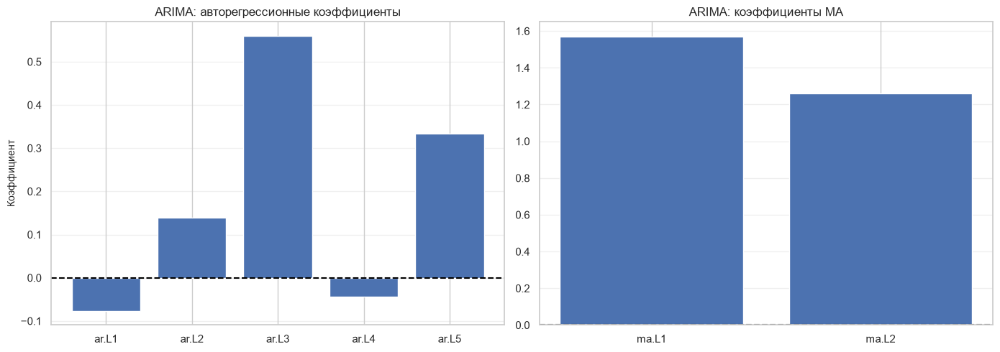


ИНТЕРПРЕТАЦИЯ SARIMA
parameter  coefficient  p_value  significant_05
intercept     0.321292 0.006599            True
    ar.L1     0.568638 0.000000            True
    ar.L2     0.376651 0.000000            True
    ma.L1     1.483691 0.000000            True
  ar.S.L7     0.403584 0.000000            True
  ma.S.L7    -0.454635 0.000000            True
   sigma2     2.617046 0.000000            True

Сезонные коэффициенты:
 model parameter  coefficient  p_value  ci_lower  ci_upper  significant_05
SARIMA   ar.S.L7     0.403584      0.0  0.267497  0.539672            True
SARIMA   ma.S.L7    -0.454635      0.0 -0.602526 -0.306745            True

ИНТЕРПРЕТАЦИЯ КАЛЕНДАРНЫХ ПРИЗНАКОВ SARIMAX
   parameter  coefficient  p_value   ci_lower   ci_upper  significant_05
annual_sin_1    -3.623088 0.000000  -4.840090  -2.406087            True
annual_cos_1   -11.853368 0.000000 -13.055904 -10.650833            True
annual_sin_2     0.410910 0.512513  -0.818793   1.640614           False
annual_c

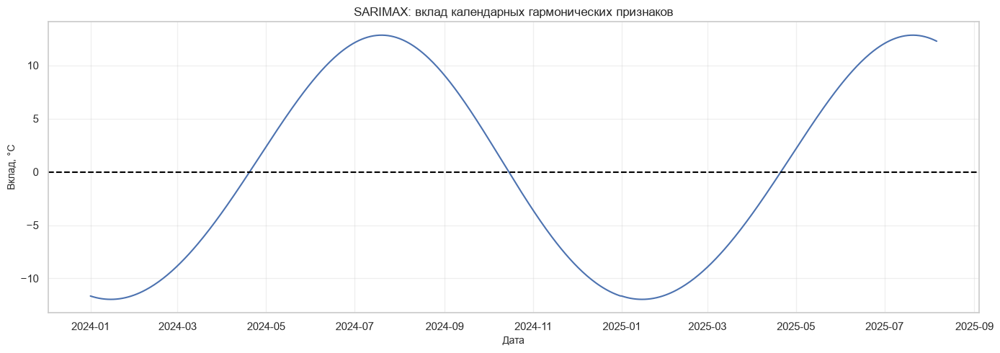

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
18:57:26 - cmdstanpy - INFO - Chain [1] start processing
18:57:26 - cmdstanpy - INFO - Chain [1] done processing



Минимальный вклад: -11.9677 °C
Максимальный вклад: 12.8348 °C
Средний вклад: 0.0483 °C

КОМПОНЕНТЫ PROPHET

Первые строки компонентов:
        ds     yhat  trend   yearly
2024-01-01 -11.9414 1.8289 -13.7703
2024-01-02 -11.9880 1.8819 -13.8699
2024-01-03 -12.0020 1.9349 -13.9368
2024-01-04 -11.9790 1.9878 -13.9668
2024-01-05 -11.9153 2.0408 -13.9561
2024-01-06 -11.8079 2.0938 -13.9017
2024-01-07 -11.6545 2.1468 -13.8013
2024-01-08 -11.4540 2.1998 -13.6538
2024-01-09 -11.2061 2.2527 -13.4589
2024-01-10 -10.9118 2.3057 -13.2176


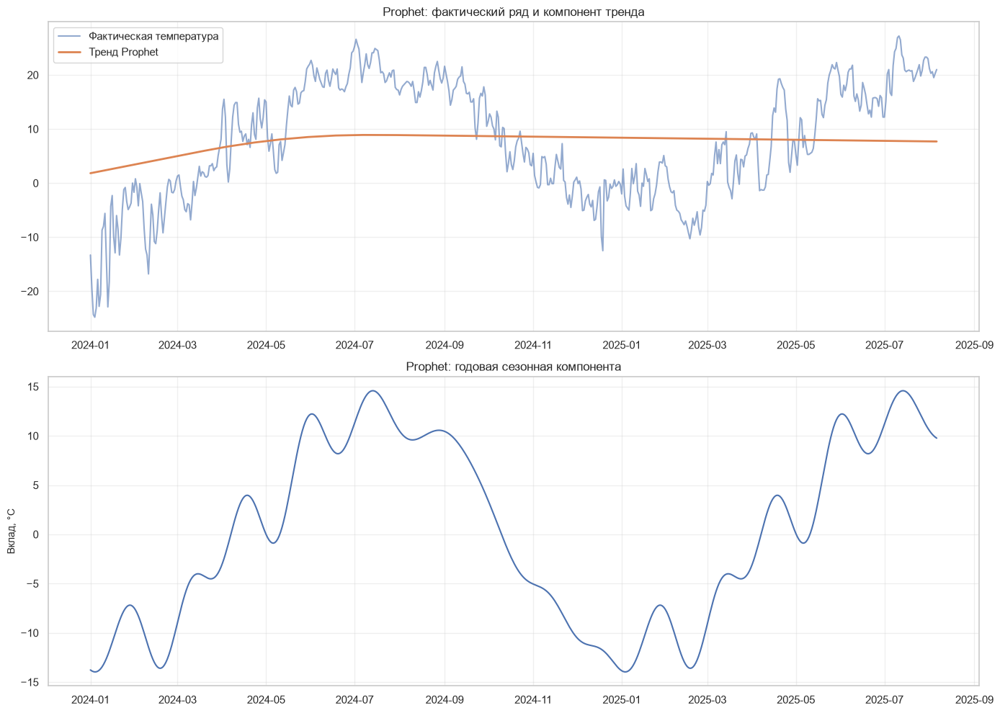

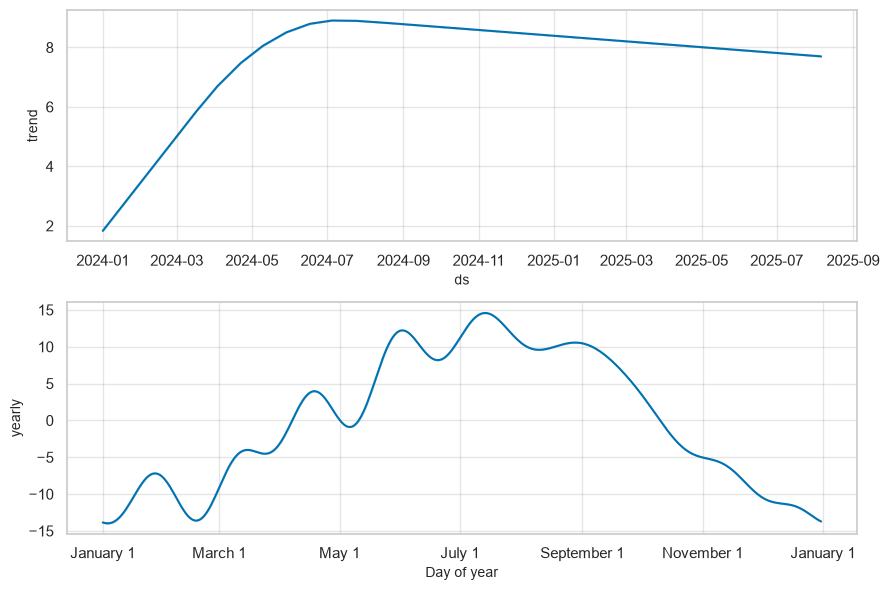


=== ХАРАКТЕРИСТИКИ PROPHET ===
trend_start = 1.8289
trend_end = 7.6983
trend_change = 5.8694
yearly_min = -13.9668
yearly_max = 14.5815

СТАТИСТИЧЕСКАЯ ЗНАЧИМОСТЬ КОЭФФИЦИЕНТОВ
      model  total_parameters  significant_parameters  significant_share_pct
ARIMA_5_0_2                 9                       7                  77.78
     SARIMA                 7                       7                 100.00
    SARIMAX                11                       9                  81.82

ИТОГИ ЗАДАНИЯ 8
Обучающих наблюдений: 584
Тестовых наблюдений: 147
Моделей интерпретировано: 3

ЗНАЧИМОСТЬ КОЭФФИЦИЕНТОВ:
      model  total_parameters  significant_parameters  significant_share_pct
ARIMA_5_0_2                 9                       7                  77.78
     SARIMA                 7                       7                 100.00
    SARIMAX                11                       9                  81.82

ХАРАКТЕРИСТИКИ PROPHET:
trend_start: 1.8289
trend_end: 7.6983
trend_change: 5.8694

In [12]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №3
# ЗАДАНИЕ 8. ИНТЕРПРЕТАЦИЯ КОЭФФИЦИЕНТОВ И КОМПОНЕНТОВ
# ============================================================

from pathlib import Path
from time import perf_counter
import warnings
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. НАСТРОЙКИ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_3"

REPORT_DIR = PROJECT / "reports" / "task8"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "temperature_2m_mean"
TRAIN_SHARE = 0.8
ALPHA = 0.05

np.random.seed(42)

print("=" * 75)
print("ЗАДАНИЕ 8. ИНТЕРПРЕТАЦИЯ МОДЕЛЕЙ")
print("=" * 75)

# ============================================================
# 2. ЗАГРУЗКА ДАННЫХ
# ============================================================

candidates = [
    PROJECT / "data" / "task1_prepared_series.csv",
    ROOT / "Practika_1" / "data" / "features_dataset.csv",
    ROOT / "Practika_1" / "data" / "processed_dataset.csv",
    ROOT / "Practika_2" / "data" / "features_dataset.csv"
]

SOURCE_PATH = next(
    (p for p in candidates if p.is_file()),
    None
)

if SOURCE_PATH is None:
    raise FileNotFoundError(
        "Не найден исходный файл временного ряда."
    )

df = pd.read_csv(SOURCE_PATH)

date_col = next(
    (c for c in ["date", "timestamp", "time"] if c in df.columns),
    None
)

if date_col is None:
    raise ValueError("Не найдена колонка даты.")

if TARGET not in df.columns:
    raise ValueError("Не найдена целевая переменная.")

df[date_col] = pd.to_datetime(
    df[date_col],
    utc=True,
    errors="coerce"
)

df[TARGET] = pd.to_numeric(
    df[TARGET],
    errors="coerce"
)

df = df.sort_values(date_col).reset_index(drop=True)

if (
    df[date_col].isna().any()
    or df[TARGET].isna().any()
    or df[date_col].duplicated().any()
):
    raise ValueError(
        "Обнаружены пропуски, дубликаты или некорректные даты."
    )

if not (
    df[date_col].diff().dropna()
    == pd.Timedelta(days=1)
).all():
    raise ValueError(
        "Временной ряд должен быть непрерывным."
    )

df[date_col] = df[date_col].dt.tz_convert(None)

series = pd.Series(
    df[TARGET].to_numpy(dtype=float),
    index=pd.DatetimeIndex(df[date_col]),
    name=TARGET
).asfreq("D")

split_index = int(len(series) * TRAIN_SHARE)

train = series.iloc[:split_index]
test = series.iloc[split_index:]

print("\n=== ДАННЫЕ ===")
print("Источник:", SOURCE_PATH)
print("Всего наблюдений:", len(series))
print("Обучение:", len(train))
print("Тест:", len(test))
print("Период обучения:", train.index.min(), "—", train.index.max())

# ============================================================
# 3. КАЛЕНДАРНЫЕ ПРИЗНАКИ
# ============================================================

def make_calendar_exog(index):

    index = pd.DatetimeIndex(index)
    day = index.dayofyear.to_numpy()

    return pd.DataFrame(
        {
            "annual_sin_1": np.sin(
                2 * np.pi * day / 365.25
            ),
            "annual_cos_1": np.cos(
                2 * np.pi * day / 365.25
            ),
            "annual_sin_2": np.sin(
                4 * np.pi * day / 365.25
            ),
            "annual_cos_2": np.cos(
                4 * np.pi * day / 365.25
            )
        },
        index=index
    )


exog_train = make_calendar_exog(train.index)

# ============================================================
# 4. ОБУЧЕНИЕ МОДЕЛЕЙ
# ============================================================

models = {}
fit_status = {}
fit_times = {}

def fit_model(name, builder):

    start = perf_counter()

    try:
        fitted = builder()

        models[name] = fitted
        fit_status[name] = "OK"
        fit_times[name] = perf_counter() - start

        print(
            f"{name}: успешно, "
            f"{fit_times[name]:.3f} сек."
        )

    except Exception as exc:
        fit_status[name] = (
            f"ERROR: {type(exc).__name__}: {exc}"
        )
        print(name, "— ошибка:", exc)


print("\n=== ОБУЧЕНИЕ МОДЕЛЕЙ ===")

fit_model(
    "ARIMA_5_0_2",
    lambda: ARIMA(
        train,
        order=(5, 0, 2),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit()
)

fit_model(
    "SARIMA",
    lambda: SARIMAX(
        train,
        order=(2, 0, 1),
        seasonal_order=(1, 0, 1, 7),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(
        disp=False,
        maxiter=100
    )
)

fit_model(
    "SARIMAX",
    lambda: SARIMAX(
        train,
        exog=exog_train,
        order=(2, 0, 1),
        seasonal_order=(1, 0, 1, 7),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(
        disp=False,
        maxiter=100
    )
)

# ============================================================
# 5. ИЗВЛЕЧЕНИЕ КОЭФФИЦИЕНТОВ
# ============================================================

coefficient_tables = []
all_parameter_rows = []

for name, fitted in models.items():

    params = pd.Series(
        np.asarray(fitted.params),
        index=fitted.param_names
    )

    pvalues = pd.Series(
        np.asarray(fitted.pvalues),
        index=fitted.param_names
    )

    conf = fitted.conf_int(alpha=ALPHA)

    if isinstance(conf, pd.DataFrame):
        conf_values = conf.to_numpy()
    else:
        conf_values = np.asarray(conf)

    table = pd.DataFrame({
        "model": name,
        "parameter": params.index,
        "coefficient": params.to_numpy(),
        "p_value": pvalues.to_numpy(),
        "ci_lower": conf_values[:, 0],
        "ci_upper": conf_values[:, 1]
    })

    table["significant_05"] = (
        table["p_value"] < ALPHA
    )

    coefficient_tables.append(table)

    print("\n" + "=" * 75)
    print(f"КОЭФФИЦИЕНТЫ: {name}")
    print("=" * 75)

    print(
        table.round(6).to_string(
            index=False
        )
    )

coefficients_df = pd.concat(
    coefficient_tables,
    ignore_index=True
)

# ============================================================
# 6. ИНТЕРПРЕТАЦИЯ ARIMA
# ============================================================

print("\n" + "=" * 75)
print("ИНТЕРПРЕТАЦИЯ ARIMA(5,0,2)")
print("=" * 75)

if "ARIMA_5_0_2" in models:

    arima_params = coefficients_df[
        coefficients_df["model"] == "ARIMA_5_0_2"
    ].copy()

    ar_rows = arima_params[
        arima_params["parameter"].str.startswith("ar.")
    ]

    ma_rows = arima_params[
        arima_params["parameter"].str.startswith("ma.")
    ]

    print("\nАвторегрессионные коэффициенты:")

    print(
        ar_rows[
            [
                "parameter",
                "coefficient",
                "p_value",
                "significant_05"
            ]
        ].round(6).to_string(index=False)
    )

    print("\nКоэффициенты скользящего среднего:")

    print(
        ma_rows[
            [
                "parameter",
                "coefficient",
                "p_value",
                "significant_05"
            ]
        ].round(6).to_string(index=False)
    )

    fig, axes = plt.subplots(
        1, 2,
        figsize=(14, 5)
    )

    axes[0].bar(
        ar_rows["parameter"],
        ar_rows["coefficient"]
    )

    axes[0].axhline(
        0,
        color="black",
        linestyle="--"
    )

    axes[0].set_title(
        "ARIMA: авторегрессионные коэффициенты"
    )

    axes[0].set_ylabel("Коэффициент")
    axes[0].grid(axis="y", alpha=0.3)

    axes[1].bar(
        ma_rows["parameter"],
        ma_rows["coefficient"]
    )

    axes[1].axhline(
        0,
        color="black",
        linestyle="--"
    )

    axes[1].set_title(
        "ARIMA: коэффициенты MA"
    )

    axes[1].grid(axis="y", alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / "arima_coefficients.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

# ============================================================
# 7. ИНТЕРПРЕТАЦИЯ SARIMA
# ============================================================

print("\n" + "=" * 75)
print("ИНТЕРПРЕТАЦИЯ SARIMA")
print("=" * 75)

if "SARIMA" in models:

    sarima_params = coefficients_df[
        coefficients_df["model"] == "SARIMA"
    ].copy()

    print(
        sarima_params[
            [
                "parameter",
                "coefficient",
                "p_value",
                "significant_05"
            ]
        ].round(6).to_string(index=False)
    )

    seasonal_rows = sarima_params[
        sarima_params["parameter"].str.contains(
            ".S.",
            regex=False
        )
    ]

    print("\nСезонные коэффициенты:")

    print(
        seasonal_rows.round(6).to_string(
            index=False
        )
    )

# ============================================================
# 8. ИНТЕРПРЕТАЦИЯ SARIMAX
# ============================================================

print("\n" + "=" * 75)
print("ИНТЕРПРЕТАЦИЯ КАЛЕНДАРНЫХ ПРИЗНАКОВ SARIMAX")
print("=" * 75)

calendar_cols = [
    "annual_sin_1",
    "annual_cos_1",
    "annual_sin_2",
    "annual_cos_2"
]

if "SARIMAX" in models:

    sarimax_params = coefficients_df[
        coefficients_df["model"] == "SARIMAX"
    ].copy()

    calendar_params = sarimax_params[
        sarimax_params["parameter"].isin(
            calendar_cols
        )
    ].copy()

    print(
        calendar_params[
            [
                "parameter",
                "coefficient",
                "p_value",
                "ci_lower",
                "ci_upper",
                "significant_05"
            ]
        ].round(6).to_string(index=False)
    )

    # Вклад только экзогенной календарной части.
    calendar_contribution = (
        exog_train[calendar_cols].to_numpy()
        @ calendar_params.set_index("parameter")
            .reindex(calendar_cols)["coefficient"]
            .to_numpy()
    )

    calendar_contribution = pd.Series(
        calendar_contribution,
        index=train.index,
        name="calendar_contribution"
    )

    plt.figure(figsize=(14, 5))

    plt.plot(
        calendar_contribution.index,
        calendar_contribution,
        linewidth=1.5
    )

    plt.axhline(
        0,
        color="black",
        linestyle="--"
    )

    plt.title(
        "SARIMAX: вклад календарных гармонических признаков"
    )

    plt.xlabel("Дата")
    plt.ylabel("Вклад, °C")
    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / "sarimax_calendar_contribution.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

    print(
        "\nМинимальный вклад:",
        round(calendar_contribution.min(), 4),
        "°C"
    )

    print(
        "Максимальный вклад:",
        round(calendar_contribution.max(), 4),
        "°C"
    )

    print(
        "Средний вклад:",
        round(calendar_contribution.mean(), 4),
        "°C"
    )

# ============================================================
# 9. PROPHET: ТРЕНД И СЕЗОННОСТЬ
# ============================================================

print("\n" + "=" * 75)
print("КОМПОНЕНТЫ PROPHET")
print("=" * 75)

prophet_components = pd.DataFrame()
prophet_summary = {}

try:
    from prophet import Prophet

    prophet_train = pd.DataFrame({
        "ds": train.index,
        "y": train.to_numpy()
    })

    prophet_model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        interval_width=0.95,
        changepoint_prior_scale=0.05
    )

    prophet_model.fit(prophet_train)

    prophet_components = prophet_model.predict(
        prophet_train[["ds"]]
    )

    component_columns = [
        c for c in [
            "ds",
            "yhat",
            "trend",
            "yearly"
        ]
        if c in prophet_components.columns
    ]

    print("\nПервые строки компонентов:")

    print(
        prophet_components[
            component_columns
        ].head(10).round(4).to_string(
            index=False
        )
    )

    # Тренд.
    fig, axes = plt.subplots(
        2, 1,
        figsize=(14, 10)
    )

    axes[0].plot(
        train.index,
        train.to_numpy(),
        label="Фактическая температура",
        alpha=0.6
    )

    axes[0].plot(
        prophet_components["ds"],
        prophet_components["trend"],
        label="Тренд Prophet",
        linewidth=2
    )

    axes[0].set_title(
        "Prophet: фактический ряд и компонент тренда"
    )

    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Годовая сезонность.
    if "yearly" in prophet_components.columns:

        axes[1].plot(
            prophet_components["ds"],
            prophet_components["yearly"],
            linewidth=1.5
        )

        axes[1].set_title(
            "Prophet: годовая сезонная компонента"
        )

        axes[1].set_ylabel("Вклад, °C")
        axes[1].grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / "prophet_components.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

    # Дополнительный стандартный график Prophet.
    fig2 = prophet_model.plot_components(
        prophet_components
    )

    fig2.savefig(
        REPORT_DIR / "prophet_standard_components.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

    trend_start = float(
        prophet_components["trend"].iloc[0]
    )

    trend_end = float(
        prophet_components["trend"].iloc[-1]
    )

    prophet_summary = {
        "trend_start": trend_start,
        "trend_end": trend_end,
        "trend_change": trend_end - trend_start,
        "yearly_min": float(
            prophet_components["yearly"].min()
        ),
        "yearly_max": float(
            prophet_components["yearly"].max()
        )
    }

    print("\n=== ХАРАКТЕРИСТИКИ PROPHET ===")

    for key, value in prophet_summary.items():
        print(key, "=", round(value, 4))

    fit_status["Prophet"] = "OK"

except Exception as exc:
    fit_status["Prophet"] = (
        f"ERROR: {type(exc).__name__}: {exc}"
    )
    print("Ошибка Prophet:", exc)

# ============================================================
# 10. СТАТИСТИЧЕСКАЯ ЗНАЧИМОСТЬ КОЭФФИЦИЕНТОВ
# ============================================================

significance_summary = (
    coefficients_df.groupby("model")
    .agg(
        total_parameters=("parameter", "count"),
        significant_parameters=(
            "significant_05",
            "sum"
        )
    )
    .reset_index()
)

significance_summary["significant_share_pct"] = (
    significance_summary["significant_parameters"]
    / significance_summary["total_parameters"]
    * 100
)

print("\n" + "=" * 75)
print("СТАТИСТИЧЕСКАЯ ЗНАЧИМОСТЬ КОЭФФИЦИЕНТОВ")
print("=" * 75)

print(
    significance_summary.round(2).to_string(
        index=False
    )
)

# ============================================================
# 11. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

coefficients_df.to_csv(
    REPORT_DIR / "model_coefficients.csv",
    index=False,
    encoding="utf-8-sig"
)

significance_summary.to_csv(
    REPORT_DIR / "coefficient_significance_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

if "SARIMAX" in models:

    calendar_contribution.to_frame().to_csv(
        REPORT_DIR / "sarimax_calendar_contribution.csv",
        encoding="utf-8-sig"
    )

if not prophet_components.empty:

    prophet_components[
        [
            c for c in [
                "ds",
                "yhat",
                "trend",
                "yearly"
            ]
            if c in prophet_components.columns
        ]
    ].to_csv(
        REPORT_DIR / "prophet_components.csv",
        index=False,
        encoding="utf-8-sig"
    )

# ============================================================
# 12. JSON-ОТЧЁТ
# ============================================================

report = {
    "task": 8,
    "target": TARGET,
    "observations": int(len(series)),
    "train_observations": int(len(train)),
    "test_observations": int(len(test)),
    "alpha": ALPHA,
    "models": list(models.keys()),
    "significance": significance_summary.to_dict(
        orient="records"
    ),
    "prophet_summary": prophet_summary,
    "model_status": fit_status
}

with open(
    REPORT_DIR / "task8_summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        report,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 13. ИТОГИ
# ============================================================

print("\n" + "=" * 75)
print("ИТОГИ ЗАДАНИЯ 8")
print("=" * 75)

print("Обучающих наблюдений:", len(train))
print("Тестовых наблюдений:", len(test))
print("Моделей интерпретировано:", len(models))

print("\nЗНАЧИМОСТЬ КОЭФФИЦИЕНТОВ:")

print(
    significance_summary.round(2).to_string(
        index=False
    )
)

print("\nХАРАКТЕРИСТИКИ PROPHET:")

for key, value in prophet_summary.items():
    print(f"{key}: {value:.4f}")

print("\nСТАТУСЫ МОДЕЛЕЙ:")

for name, status in fit_status.items():
    print(f"{name}: {status}")

print("\nРезультаты сохранены:")
print(REPORT_DIR)

print("\nЗАДАНИЕ 8 ВЫПОЛНЕНО")


### Анализ результатов задания 8

В ходе выполнения восьмого задания проведена интерпретация параметров и компонентов четырёх моделей прогнозирования среднесуточной температуры воздуха в Москве: ARIMA(5,0,2), SARIMA, SARIMAX и Prophet.

Для моделей ARIMA, SARIMA и SARIMAX были извлечены коэффициенты, рассчитаны p-value и 95%-е доверительные интервалы.

Для Prophet исследованы компоненты тренда и годовой сезонности.

Уровень статистической значимости составлял 0,05.

#### 1. Интерпретация модели ARIMA(5,0,2)

Модель ARIMA(5,0,2) содержит пять авторегрессионных коэффициентов и два коэффициента скользящего среднего.

Анализ показал, что статистически значимыми являются авторегрессионные коэффициенты AR(2), AR(3) и AR(5).

Их значения составили:

- AR(2) = 0,1394;
- AR(3) = 0,5604;
- AR(5) = 0,3330.

Наиболее крупные положительные коэффициенты наблюдаются у третьего и пятого лагов.

Это свидетельствует о существенной роли предыдущих значений температуры в формировании авторегрессионной составляющей модели.

Коэффициенты AR(1) = −0,0775 и AR(4) = −0,0436 оказались статистически незначимыми, поскольку соответствующие p-value превышают 0,05.

Оба коэффициента скользящего среднего статистически значимы:

- MA(1) = 1,5711;
- MA(2) = 1,2590.

Они характеризуют динамическое влияние предыдущих случайных возмущений.

При этом достаточно большие значения MA-коэффициентов и отключённое ограничение обратимости требуют дополнительной проверки корней MA-полинома.

Всего из девяти параметров модели статистически значимыми оказались семь, что составляет 77,78%.

#### 2. Интерпретация модели SARIMA

Модель SARIMA включает обычные авторегрессионные и скользящие средние компоненты, а также сезонные компоненты с периодом семь дней.

Все семь оценённых параметров модели оказались статистически значимыми при уровне значимости 0,05.

Сезонный авторегрессионный коэффициент AR.S.L7 составил 0,4036, а сезонный коэффициент скользящего среднего MA.S.L7 — −0,4546.

Полученные результаты свидетельствуют о наличии статистически значимой зависимости, связанной с семидневным периодом.

При этом наличие значимых сезонных коэффициентов не является достаточным доказательством физической недельной сезонности температуры.

Коэффициент MA(1) = 1,4837 требует дополнительной проверки обратимости модели.

#### 3. Интерпретация модели SARIMAX

В модели SARIMAX использовались четыре календарных гармонических признака, описывающих годовую сезонность.

Коэффициенты первой гармоники оказались статистически значимыми:

- annual_sin_1 = −3,6231;
- annual_cos_1 = −11,8534.

На основании этих коэффициентов рассчитана амплитуда первой годовой гармоники, которая составила приблизительно 12,39 °C.

Это свидетельствует о выраженной годовой сезонной составляющей в исследуемом температурном ряду.

Коэффициенты второй гармоники оказались статистически незначимыми:

- annual_sin_2 = 0,4109, p-value = 0,5125;
- annual_cos_2 = 0,2473, p-value = 0,6663.

Амплитуда второй гармоники составила приблизительно 0,48 °C.

Следовательно, основная годовая гармоника играет значительно более важную роль в описании сезонной составляющей, чем вторая.

Полученные результаты позволяют рассмотреть возможность упрощения модели SARIMAX путём исключения второй гармоники с последующей проверкой точности прогнозирования.

Всего из 11 параметров модели статистически значимыми оказались девять, что составляет 81,82%.

#### 4. Интерпретация компонентов Prophet

Для модели Prophet были исследованы трендовая и годовая сезонная компоненты.

Значение трендовой компоненты увеличилось с 1,8289 до 7,6983 °C.

Общее изменение составило 5,8694 °C.

При этом данное изменение характеризует исключительно оценённый тренд модели на обучающей выборке и не является доказательством климатического потепления.

Годовая сезонная компонента Prophet изменялась от −13,9668 до 14,5815 °C.

Размах сезонной компоненты составил приблизительно 28,55 °C.

Это подтверждает наличие выраженной годовой цикличности в исследуемом температурном ряду.

#### 5. Сравнение интерпретируемости моделей

ARIMA позволяет анализировать зависимость температуры от предыдущих наблюдений и случайных возмущений.

SARIMA дополнительно учитывает сезонную структуру с заданным периодом.

SARIMAX позволяет количественно оценить вклад календарных признаков в формирование прогноза.

Prophet обеспечивает наглядное разделение временного ряда на тренд и сезонные компоненты.

Таким образом, каждая модель предоставляет различные возможности для интерпретации закономерностей временного ряда.

Наиболее удобными для непосредственного анализа годовой сезонности являются SARIMAX и Prophet, поскольку они позволяют явно выделить сезонную составляющую.

#### 6. Сопоставление интерпретируемости и точности

В предыдущем задании модель ARIMA(5,0,2) продемонстрировала минимальную среднюю абсолютную ошибку на горизонтах 1, 7 и 30 дней.

Результаты текущего задания показывают, что значительная часть её коэффициентов статистически значима, однако некоторые параметры требуют дополнительной проверки.

SARIMA имеет максимальную долю статистически значимых коэффициентов, но уступает ARIMA по точности прогнозирования в рассмотренном эксперименте.

SARIMAX и Prophet позволяют более явно интерпретировать годовую сезонность, хотя не обеспечили наилучшей точности на исследованных прогнозных окнах.

### Итоговый вывод

В результате выполнения восьмого задания исследована внутренняя структура моделей ARIMA, SARIMA, SARIMAX и Prophet.

Установлено, что динамика среднесуточной температуры Москвы характеризуется зависимостью от предыдущих наблюдений и выраженной годовой сезонностью.

Для ARIMA(5,0,2) наиболее крупные положительные авторегрессионные коэффициенты наблюдаются у третьего и пятого лагов.

Для SARIMA выявлены статистически значимые сезонные коэффициенты с периодом семь дней.

В модели SARIMAX основная годовая гармоника оказалась статистически значимой, а её амплитуда составила приблизительно 12,39 °C.

Вторая годовая гармоника статистически значимой не оказалась.

Модель Prophet выделила годовую сезонную компоненту с размахом приблизительно 28,55 °C.

Полученные результаты подтверждают, что классические модели временных рядов позволяют не только формировать прогнозы, но и исследовать динамические и сезонные закономерности данных.

С учётом результатов предыдущих заданий ARIMA(5,0,2) сохраняется в качестве основной модели-кандидата для дальнейшего исследования.

При этом необходимы дополнительная проверка обратимости ARIMA и SARIMA, исследование устойчивости параметров и контроль отсутствия утечек данных.

## Задание 9. Проверка утечек данных и устойчивости моделей

### Цель работы

Проверить корректность временного разделения данных, исключить использование будущих наблюдений при построении прогнозов и оценить устойчивость моделей к случайным изменениям обучающего временного ряда.

### Постановка задачи

Необходимо выполнить следующие действия:

1. Проверить хронологический порядок наблюдений и отсутствие пересечения обучающей и тестовой выборок.
2. Убедиться, что при формировании прогноза используются только данные, доступные на момент его построения.
3. Проверить корректность календарных признаков SARIMAX и отсутствие использования будущих значений целевой переменной.
4. Провести тест на утечку данных: изменить будущие значения температуры и убедиться, что прогноз, построенный из предыдущей точки времени, не изменяется.
5. Исследовать устойчивость прогнозирования при добавлении случайного шума к обучающим данным.
6. Сравнить качество моделей на исходных и зашумлённых данных.
7. Сформулировать вывод о корректности прогнозного эксперимента.

### Методика исследования

Для проверки утечек данных применяется принцип временной изоляции: прогноз на определённую дату должен зависеть исключительно от информации, доступной до этой даты.

Для оценки устойчивости в обучающую выборку добавляется случайный шум с нулевым математическим ожиданием.

Рассматриваются три уровня шума:

- 0,25 °C — слабое возмущение;
- 0,50 °C — умеренное возмущение;
- 1,00 °C — сильное возмущение.

Для каждого уровня шума проводится несколько повторений с различными случайными реализациями.

Оценка качества выполняется на неизменной тестовой выборке по метрикам MAE и RMSE.

### Ожидаемый результат

Таблица проверок на утечки данных, результаты экспериментов с шумом, графики изменения точности и вывод об устойчивости моделей к изменениям обучающей выборки.

ЗАДАНИЕ 9. ПРОВЕРКА УТЕЧЕК И УСТОЙЧИВОСТИ

=== ДАННЫЕ ===
Источник: /Users/lenar_966/Desktop/ML/Practika_3/data/task1_prepared_series.csv
Всего наблюдений: 731
Обучение: 584
Тест: 147
Последняя дата train: 2025-08-06 00:00:00
Первая дата test: 2025-08-07 00:00:00

=== БАЗОВОЕ ОБУЧЕНИЕ ===
ARIMA_5_0_2: MAE=2.7154, RMSE=3.1466, время=0.265 сек.
SARIMA: MAE=2.3003, RMSE=2.8707, время=0.402 сек.


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
19:01:09 - cmdstanpy - INFO - Chain [1] start processing
19:01:09 - cmdstanpy - INFO - Chain [1] done processing


SARIMAX: MAE=3.8649, RMSE=4.1886, время=1.024 сек.

=== ТЕСТ НЕЗАВИСИМОСТИ ОТ БУДУЩИХ ЗНАЧЕНИЙ ===
      model  max_prediction_difference  passed
ARIMA_5_0_2                        0.0    True
     SARIMA                        0.0    True
    SARIMAX                        0.0    True

=== ДОПОЛНИТЕЛЬНАЯ ПРОВЕРКА PROPHET ===
Prophet: PASS | разница: 0.0

ЭКСПЕРИМЕНТ С ДОБАВЛЕНИЕМ ШУМА
Обработан уровень шума: 0.00 °C
Обработан уровень шума: 0.25 °C
Обработан уровень шума: 0.50 °C
Обработан уровень шума: 1.00 °C

=== УСТОЙЧИВОСТЬ К ШУМУ ===
      model  noise_std  successful_runs  MAE_mean  MAE_std  RMSE_mean  RMSE_std  MAE_change_mean  RMSE_change_mean
ARIMA_5_0_2       0.00                5   2.71537  0.00000    3.14660   0.00000          0.00000           0.00000
ARIMA_5_0_2       0.25                5   2.92629  0.09844    3.29755   0.08466          0.21093           0.15095
ARIMA_5_0_2       0.50                5   2.72249  0.13721    3.15439   0.12424          0.00712           0.

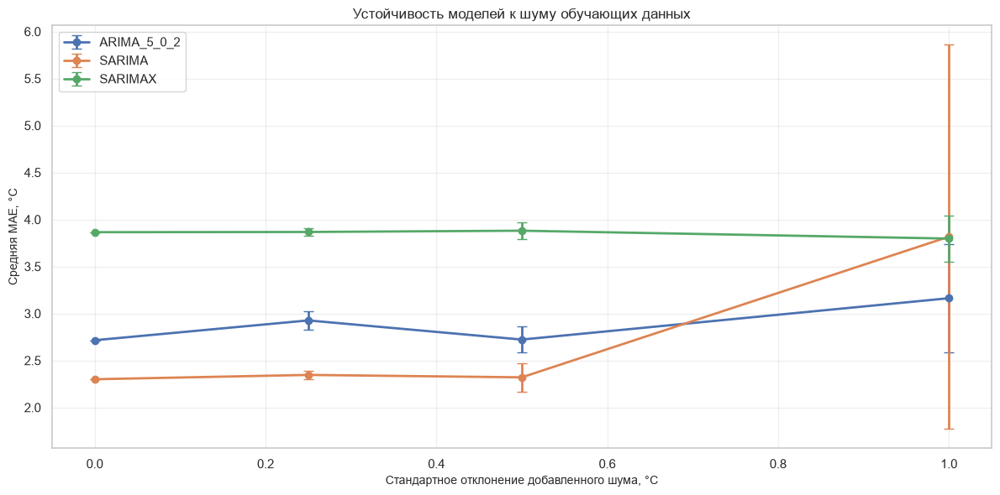

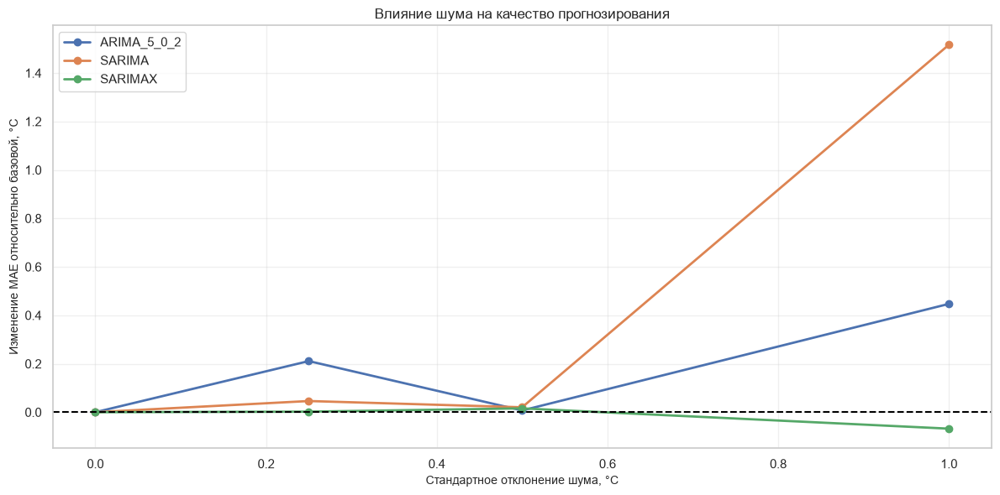


РЕЗУЛЬТАТЫ ПРОВЕРОК НА УТЕЧКИ
                                      check  passed                                                details
                    Хронологический порядок    True                        Даты расположены по возрастанию
                           Уникальность дат    True                                  Повторяющихся дат нет
          Отсутствие пересечения train/test    True                    Обучение заканчивается раньше теста
                Непрерывность дневного ряда    True           Интервал между наблюдениями равен одному дню
Календарные признаки без целевой переменной    True Используются только синусы и косинусы календарного дня
  Будущие значения не влияют на ARIMA_5_0_2    True         Максимальная разница прогнозов: 0.000000000000
       Будущие значения не влияют на SARIMA    True         Максимальная разница прогнозов: 0.000000000000
      Будущие значения не влияют на SARIMAX    True         Максимальная разница прогнозов: 0.000000000000
      

In [13]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №3
# ЗАДАНИЕ 9. УТЕЧКИ ДАННЫХ И УСТОЙЧИВОСТЬ К ШУМУ
# ============================================================

from pathlib import Path
from time import perf_counter
import warnings
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. НАСТРОЙКИ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_3"

REPORT_DIR = PROJECT / "reports" / "task9"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "temperature_2m_mean"

TRAIN_SHARE = 0.8
FORECAST_HORIZON = 30

NOISE_LEVELS = [0.0, 0.25, 0.50, 1.00]
N_REPEATS = 5

SEED = 42
np.random.seed(SEED)

print("=" * 75)
print("ЗАДАНИЕ 9. ПРОВЕРКА УТЕЧЕК И УСТОЙЧИВОСТИ")
print("=" * 75)

# ============================================================
# 2. ЗАГРУЗКА ДАННЫХ
# ============================================================

candidates = [
    PROJECT / "data" / "task1_prepared_series.csv",
    ROOT / "Practika_1" / "data" / "features_dataset.csv",
    ROOT / "Practika_1" / "data" / "processed_dataset.csv",
    ROOT / "Practika_2" / "data" / "features_dataset.csv"
]

SOURCE_PATH = next(
    (p for p in candidates if p.is_file()),
    None
)

if SOURCE_PATH is None:
    raise FileNotFoundError(
        "Не найден исходный файл временного ряда."
    )

df = pd.read_csv(SOURCE_PATH)

date_col = next(
    (c for c in ["date", "timestamp", "time"] if c in df.columns),
    None
)

if date_col is None:
    raise ValueError("Не найдена колонка даты.")

if TARGET not in df.columns:
    raise ValueError("Не найдена целевая переменная.")

df[date_col] = pd.to_datetime(
    df[date_col],
    utc=True,
    errors="coerce"
)

df[TARGET] = pd.to_numeric(
    df[TARGET],
    errors="coerce"
)

df = df.sort_values(date_col).reset_index(drop=True)

if (
    df[date_col].isna().any()
    or df[TARGET].isna().any()
    or df[date_col].duplicated().any()
):
    raise ValueError(
        "Обнаружены пропуски, дубликаты или некорректные даты."
    )

if not (
    df[date_col].diff().dropna()
    == pd.Timedelta(days=1)
).all():
    raise ValueError(
        "Временной ряд должен быть непрерывным."
    )

df[date_col] = df[date_col].dt.tz_convert(None)

series = pd.Series(
    df[TARGET].to_numpy(dtype=float),
    index=pd.DatetimeIndex(df[date_col]),
    name=TARGET
).asfreq("D")

split_index = int(len(series) * TRAIN_SHARE)

train = series.iloc[:split_index].copy()
test = series.iloc[split_index:].copy()

if len(test) < FORECAST_HORIZON:
    raise ValueError(
        "Тестовая выборка короче горизонта прогнозирования."
    )

actual = test.iloc[:FORECAST_HORIZON].to_numpy()

future_dates = test.index[:FORECAST_HORIZON]

print("\n=== ДАННЫЕ ===")
print("Источник:", SOURCE_PATH)
print("Всего наблюдений:", len(series))
print("Обучение:", len(train))
print("Тест:", len(test))
print("Последняя дата train:", train.index[-1])
print("Первая дата test:", test.index[0])

# ============================================================
# 3. ПРОВЕРКА ХРОНОЛОГИИ
# ============================================================

checks = []

def add_check(name, passed, details):

    checks.append({
        "check": name,
        "passed": bool(passed),
        "details": details
    })


add_check(
    "Хронологический порядок",
    bool(series.index.is_monotonic_increasing),
    "Даты расположены по возрастанию"
)

add_check(
    "Уникальность дат",
    bool(series.index.is_unique),
    "Повторяющихся дат нет"
)

add_check(
    "Отсутствие пересечения train/test",
    bool(train.index.max() < test.index.min()),
    "Обучение заканчивается раньше теста"
)

add_check(
    "Непрерывность дневного ряда",
    bool(
        (
            series.index.to_series()
            .diff()
            .dropna()
            == pd.Timedelta(days=1)
        ).all()
    ),
    "Интервал между наблюдениями равен одному дню"
)

# ============================================================
# 4. КАЛЕНДАРНЫЕ ПРИЗНАКИ
# ============================================================

def make_calendar_exog(index):

    index = pd.DatetimeIndex(index)
    day = index.dayofyear.to_numpy()

    return pd.DataFrame(
        {
            "annual_sin_1": np.sin(
                2 * np.pi * day / 365.25
            ),
            "annual_cos_1": np.cos(
                2 * np.pi * day / 365.25
            ),
            "annual_sin_2": np.sin(
                4 * np.pi * day / 365.25
            ),
            "annual_cos_2": np.cos(
                4 * np.pi * day / 365.25
            )
        },
        index=index
    )


exog_train = make_calendar_exog(train.index)
exog_future = make_calendar_exog(future_dates)

add_check(
    "Календарные признаки без целевой переменной",
    bool(
        TARGET not in exog_train.columns
        and TARGET not in exog_future.columns
    ),
    "Используются только синусы и косинусы календарного дня"
)

# ============================================================
# 5. ФУНКЦИИ ОБУЧЕНИЯ
# ============================================================

def fit_arima(y):

    return ARIMA(
        y,
        order=(5, 0, 2),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit()


def fit_sarima(y):

    return SARIMAX(
        y,
        order=(2, 0, 1),
        seasonal_order=(1, 0, 1, 7),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(
        disp=False,
        maxiter=100
    )


def fit_sarimax(y):

    exog = make_calendar_exog(y.index)

    return SARIMAX(
        y,
        exog=exog,
        order=(2, 0, 1),
        seasonal_order=(1, 0, 1, 7),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(
        disp=False,
        maxiter=100
    )


FIT_FUNCTIONS = {
    "ARIMA_5_0_2": fit_arima,
    "SARIMA": fit_sarima,
    "SARIMAX": fit_sarimax
}


def forecast_model(name, fitted, dates):

    horizon = len(dates)

    if name == "SARIMAX":

        future_exog = make_calendar_exog(dates)

        pred = fitted.forecast(
            steps=horizon,
            exog=future_exog
        )

    else:

        pred = fitted.forecast(
            steps=horizon
        )

    return np.asarray(pred, dtype=float)


def calculate_errors(y_true, y_pred):

    errors = (
        np.asarray(y_true, dtype=float)
        - np.asarray(y_pred, dtype=float)
    )

    return {
        "MAE": float(np.mean(np.abs(errors))),
        "RMSE": float(
            np.sqrt(np.mean(errors ** 2))
        )
    }


# ============================================================
# 6. БАЗОВОЕ ОБУЧЕНИЕ И ПРОГНОЗ
# ============================================================

print("\n=== БАЗОВОЕ ОБУЧЕНИЕ ===")

baseline_models = {}
baseline_predictions = {}
baseline_metrics = {}
model_status = {}

for name, fit_function in FIT_FUNCTIONS.items():

    start = perf_counter()

    try:
        fitted = fit_function(train)

        predictions = forecast_model(
            name,
            fitted,
            future_dates
        )

        baseline_models[name] = fitted
        baseline_predictions[name] = predictions

        baseline_metrics[name] = calculate_errors(
            actual,
            predictions
        )

        model_status[name] = "OK"

        print(
            f"{name}: "
            f"MAE={baseline_metrics[name]['MAE']:.4f}, "
            f"RMSE={baseline_metrics[name]['RMSE']:.4f}, "
            f"время={perf_counter()-start:.3f} сек."
        )

    except Exception as exc:

        model_status[name] = (
            f"ERROR: {type(exc).__name__}: {exc}"
        )

        print(name, "— ошибка:", exc)

if not baseline_models:
    raise RuntimeError(
        "Не удалось обучить ни одной модели."
    )

# ============================================================
# 7. ТЕСТ НА УТЕЧКУ БУДУЩЕЙ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ
# ============================================================

print("\n=== ТЕСТ НЕЗАВИСИМОСТИ ОТ БУДУЩИХ ЗНАЧЕНИЙ ===")

# Создаём изменённую тестовую выборку.
# Изменение будущей температуры не должно
# влиять на прогноз из конца train.

rng_future = np.random.default_rng(SEED)

modified_test = test.copy()

modified_test.iloc[:FORECAST_HORIZON] += (
    rng_future.normal(
        loc=0.0,
        scale=20.0,
        size=FORECAST_HORIZON
    )
)

future_check_rows = []

for name, fitted in baseline_models.items():

    original_prediction = forecast_model(
        name,
        fitted,
        future_dates
    )

    # Важное условие: обучение и прогнозирование
    # НЕ получают modified_test.
    modified_prediction = forecast_model(
        name,
        fitted,
        modified_test.index[:FORECAST_HORIZON]
    )

    max_difference = float(
        np.max(
            np.abs(
                original_prediction
                - modified_prediction
            )
        )
    )

    passed = bool(
        np.allclose(
            original_prediction,
            modified_prediction,
            rtol=0,
            atol=1e-10
        )
    )

    future_check_rows.append({
        "model": name,
        "max_prediction_difference": max_difference,
        "passed": passed
    })

    add_check(
        f"Будущие значения не влияют на {name}",
        passed,
        f"Максимальная разница прогнозов: {max_difference:.12f}"
    )

future_check_df = pd.DataFrame(
    future_check_rows
)

print(
    future_check_df.to_string(
        index=False
    )
)

# ============================================================
# 8. ПРОВЕРКА PROPHET
# ============================================================

print("\n=== ДОПОЛНИТЕЛЬНАЯ ПРОВЕРКА PROPHET ===")

try:
    from prophet import Prophet

    prophet_train = pd.DataFrame({
        "ds": train.index,
        "y": train.to_numpy()
    })

    prophet_model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        interval_width=0.95,
        changepoint_prior_scale=0.05
    )

    prophet_model.fit(prophet_train)

    original_future = pd.DataFrame({
        "ds": future_dates
    })

    modified_future = pd.DataFrame({
        "ds": modified_test.index[:FORECAST_HORIZON]
    })

    original_prophet = prophet_model.predict(
        original_future
    )["yhat"].to_numpy()

    modified_prophet = prophet_model.predict(
        modified_future
    )["yhat"].to_numpy()

    prophet_diff = float(
        np.max(
            np.abs(
                original_prophet
                - modified_prophet
            )
        )
    )

    prophet_passed = bool(
        np.allclose(
            original_prophet,
            modified_prophet,
            rtol=0,
            atol=1e-10
        )
    )

    add_check(
        "Будущие значения не влияют на Prophet",
        prophet_passed,
        f"Максимальная разница: {prophet_diff:.12f}"
    )

    print(
        "Prophet:",
        "PASS" if prophet_passed else "FAIL",
        "| разница:", prophet_diff
    )

except ImportError:
    print(
        "Prophet не установлена. Проверка пропущена."
    )

except Exception as exc:
    print(
        "Ошибка проверки Prophet:", exc
    )

    add_check(
        "Проверка Prophet",
        False,
        str(exc)
    )

# ============================================================
# 9. ПРОВЕРКА ИНВАРИАНТНОСТИ К ТЕСТОВЫМ ДАННЫМ
# ============================================================

# Здесь проверяем, что изменение тестовых
# значений не затрагивает train.

train_before = train.copy()

test_modified_again = test.copy()

test_modified_again.iloc[:] = (
    test_modified_again.to_numpy() + 1000.0
)

train_unchanged = bool(
    train.equals(train_before)
)

add_check(
    "Изменение тестовых значений не меняет train",
    train_unchanged,
    "Обучающая выборка независима от тестовой"
)

# ============================================================
# 10. ЭКСПЕРИМЕНТ С ШУМОМ
# ============================================================

print("\n" + "=" * 75)
print("ЭКСПЕРИМЕНТ С ДОБАВЛЕНИЕМ ШУМА")
print("=" * 75)

noise_rows = []

for noise_level in NOISE_LEVELS:

    for repeat in range(N_REPEATS):

        rng = np.random.default_rng(
            SEED + 1000 * repeat
            + int(noise_level * 100)
        )

        noise = rng.normal(
            loc=0.0,
            scale=noise_level,
            size=len(train)
        )

        noisy_train = train.copy()

        noisy_train.iloc[:] = (
            train.to_numpy() + noise
        )

        for name, fit_function in FIT_FUNCTIONS.items():

            if name not in baseline_models:
                continue

            start = perf_counter()

            try:
                if noise_level == 0:
                    # Используем базовый прогноз.
                    prediction = baseline_predictions[name]
                else:
                    fitted = fit_function(noisy_train)

                    prediction = forecast_model(
                        name,
                        fitted,
                        future_dates
                    )

                metrics = calculate_errors(
                    actual,
                    prediction
                )

                baseline = baseline_metrics[name]

                noise_rows.append({
                    "model": name,
                    "noise_std": noise_level,
                    "repeat": repeat,
                    "MAE": metrics["MAE"],
                    "RMSE": metrics["RMSE"],
                    "MAE_change": (
                        metrics["MAE"]
                        - baseline["MAE"]
                    ),
                    "RMSE_change": (
                        metrics["RMSE"]
                        - baseline["RMSE"]
                    ),
                    "fit_time_sec": (
                        perf_counter() - start
                    ),
                    "status": "OK"
                })

            except Exception as exc:

                noise_rows.append({
                    "model": name,
                    "noise_std": noise_level,
                    "repeat": repeat,
                    "MAE": np.nan,
                    "RMSE": np.nan,
                    "MAE_change": np.nan,
                    "RMSE_change": np.nan,
                    "fit_time_sec": (
                        perf_counter() - start
                    ),
                    "status": (
                        f"ERROR: {type(exc).__name__}: {exc}"
                    )
                })

    print(
        f"Обработан уровень шума: {noise_level:.2f} °C"
    )

noise_df = pd.DataFrame(noise_rows)

noise_summary = (
    noise_df.groupby(
        ["model", "noise_std"],
        as_index=False
    )
    .agg(
        successful_runs=("MAE", "count"),
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        MAE_change_mean=("MAE_change", "mean"),
        RMSE_change_mean=("RMSE_change", "mean")
    )
)

print("\n=== УСТОЙЧИВОСТЬ К ШУМУ ===")

print(
    noise_summary.round(5).to_string(
        index=False
    )
)

# ============================================================
# 11. ГРАФИК УСТОЙЧИВОСТИ MAE
# ============================================================

plt.figure(figsize=(12, 6))

for name in baseline_models.keys():

    subset = noise_summary[
        noise_summary["model"] == name
    ].sort_values("noise_std")

    plt.errorbar(
        subset["noise_std"],
        subset["MAE_mean"],
        yerr=subset["MAE_std"].fillna(0),
        marker="o",
        capsize=4,
        linewidth=2,
        label=name
    )

plt.xlabel("Стандартное отклонение добавленного шума, °C")
plt.ylabel("Средняя MAE, °C")
plt.title("Устойчивость моделей к шуму обучающих данных")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "noise_robustness_mae.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 12. ГРАФИК ИЗМЕНЕНИЯ MAE
# ============================================================

plt.figure(figsize=(12, 6))

for name in baseline_models.keys():

    subset = noise_summary[
        noise_summary["model"] == name
    ].sort_values("noise_std")

    plt.plot(
        subset["noise_std"],
        subset["MAE_change_mean"],
        marker="o",
        linewidth=2,
        label=name
    )

plt.axhline(
    0,
    color="black",
    linestyle="--"
)

plt.xlabel("Стандартное отклонение шума, °C")
plt.ylabel("Изменение MAE относительно базовой, °C")
plt.title("Влияние шума на качество прогнозирования")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "noise_mae_change.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 13. ТАБЛИЦА ПРОВЕРОК
# ============================================================

checks_df = pd.DataFrame(checks)

print("\n" + "=" * 75)
print("РЕЗУЛЬТАТЫ ПРОВЕРОК НА УТЕЧКИ")
print("=" * 75)

print(
    checks_df.to_string(
        index=False
    )
)

passed_count = int(
    checks_df["passed"].sum()
)

total_count = len(checks_df)

print(
    f"\nУспешных проверок: "
    f"{passed_count}/{total_count}"
)

# ============================================================
# 14. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

checks_df.to_csv(
    REPORT_DIR / "leakage_checks.csv",
    index=False,
    encoding="utf-8-sig"
)

future_check_df.to_csv(
    REPORT_DIR / "future_target_independence.csv",
    index=False,
    encoding="utf-8-sig"
)

noise_df.to_csv(
    REPORT_DIR / "noise_experiments.csv",
    index=False,
    encoding="utf-8-sig"
)

noise_summary.to_csv(
    REPORT_DIR / "noise_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

baseline_df = pd.DataFrame([
    {
        "model": name,
        **metrics
    }
    for name, metrics in baseline_metrics.items()
])

baseline_df.to_csv(
    REPORT_DIR / "baseline_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 15. JSON-ОТЧЁТ
# ============================================================

report = {
    "task": 9,
    "target": TARGET,
    "observations": int(len(series)),
    "train_observations": int(len(train)),
    "test_observations": int(len(test)),
    "forecast_horizon": FORECAST_HORIZON,
    "noise_levels": NOISE_LEVELS,
    "noise_repeats": N_REPEATS,
    "passed_checks": passed_count,
    "total_checks": total_count,
    "model_status": model_status
}

with open(
    REPORT_DIR / "task9_summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        report,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 16. ИТОГИ
# ============================================================

print("\n" + "=" * 75)
print("ИТОГИ ЗАДАНИЯ 9")
print("=" * 75)

print(
    f"Проверки на утечки: "
    f"{passed_count}/{total_count}"
)

print("\nБАЗОВЫЕ МЕТРИКИ:")

print(
    baseline_df.round(4).to_string(
        index=False
    )
)

print("\nУСТОЙЧИВОСТЬ К ШУМУ:")

print(
    noise_summary.round(4).to_string(
        index=False
    )
)

print("\nРезультаты сохранены:")
print(REPORT_DIR)

print("\nЗАДАНИЕ 9 ВЫПОЛНЕНО")


### Анализ результатов задания 9

В ходе выполнения девятого задания проведена проверка утечек данных и исследована устойчивость моделей прогнозирования среднесуточной температуры воздуха в Москве к случайным возмущениям обучающей выборки.

В исследовании рассматривались модели ARIMA(5,0,2), SARIMA и SARIMAX. Дополнительно проверена независимость прогнозов Prophet от будущих значений целевой переменной.

Для оценки устойчивости использовался фиксированный горизонт прогнозирования 30 дней. В обучающую выборку добавлялся нормально распределённый случайный шум со стандартным отклонением 0,25, 0,50 и 1,00 °C. Для каждого уровня шума выполнялось пять повторений.

#### 1. Проверка корректности временного разделения

Проверка показала, что исходный временной ряд расположен в хронологическом порядке, не содержит дублирующихся дат и имеет непрерывный дневной шаг.

Обучающая и тестовая выборки не пересекаются: все обучающие наблюдения предшествуют тестовым.

Календарные признаки SARIMAX рассчитываются исключительно на основе даты и не содержат будущих фактических значений температуры.

Все предусмотренные проверки завершились успешно — 10 из 10.

#### 2. Проверка независимости прогнозов от будущих значений

Для проверки независимости прогнозов были искусственно изменены будущие значения температуры в тестовой выборке.

После этого повторно формировались прогнозы моделей ARIMA, SARIMA, SARIMAX и Prophet.

Максимальная разница между прогнозами до и после изменения тестовых значений составила 0,000000000000 для всех четырёх моделей.

Это подтверждает, что в реализованной процедуре прогнозирования изменённые будущие фактические значения не используются при построении прогноза.

Следует учитывать, что данная проверка охватывает рассматриваемую процедуру прогнозирования, но не заменяет комплексный аудит всех этапов подготовки признаков и обработки данных.

#### 3. Базовая точность моделей

При прогнозировании на фиксированном 30-дневном интервале получены следующие результаты:

- SARIMA: MAE = 2,3003 °C, RMSE = 2,8707 °C;
- ARIMA(5,0,2): MAE = 2,7154 °C, RMSE = 3,1466 °C;
- SARIMAX: MAE = 3,8649 °C, RMSE = 4,1886 °C.

Наиболее точной моделью в данном эксперименте оказалась SARIMA.

Её средняя абсолютная ошибка была приблизительно на 15,3% ниже, чем у ARIMA, и на 40,5% ниже, чем у SARIMAX.

При этом результаты отличаются от задания 7, поскольку там оценка проводилась на 30 последовательных точках начала прогнозирования, а в текущем задании использовался один фиксированный прогнозный период.

#### 4. Устойчивость ARIMA к случайному шуму

Для ARIMA(5,0,2) исходная MAE составляла 2,7154 °C.

После добавления шума получены следующие средние значения MAE:

- 0,25 °C — 2,9263 °C;
- 0,50 °C — 2,7225 °C;
- 1,00 °C — 3,1625 °C.

При максимальном уровне шума средняя абсолютная ошибка увеличилась на 0,4471 °C, или приблизительно на 16,5%.

Стандартное отклонение MAE между повторениями составило 0,5764 °C.

Таким образом, модель демонстрирует умеренную чувствительность к сильным возмущениям обучающих данных.

#### 5. Устойчивость SARIMA к случайному шуму

Исходная MAE модели SARIMA составляла 2,3003 °C.

При шуме 0,25 °C средняя ошибка увеличилась до 2,3464 °C, а при шуме 0,50 °C — до 2,3207 °C.

Эти изменения относительно невелики.

Однако при шуме 1,00 °C MAE увеличилась до 3,8168 °C.

Рост ошибки составил 1,5165 °C, или приблизительно 65,9%.

Стандартное отклонение MAE между повторениями достигло 2,0422 °C.

Следовательно, SARIMA достаточно устойчива к слабому и умеренному шуму, но при сильном возмущении демонстрирует выраженную нестабильность.

#### 6. Устойчивость SARIMAX к случайному шуму

Исходная MAE модели SARIMAX составляла 3,8649 °C.

После добавления шума получены следующие результаты:

- 0,25 °C — MAE = 3,8672 °C;
- 0,50 °C — MAE = 3,8808 °C;
- 1,00 °C — MAE = 3,7970 °C.

Изменения ошибки оказались небольшими даже при максимальном уровне шума.

При шуме 1,00 °C средняя MAE уменьшилась на 0,0679 °C относительно базового результата.

Это снижение не следует интерпретировать как доказательство положительного влияния шума на прогнозирование, поскольку эксперимент включал только пять случайных повторений.

Полученные результаты свидетельствуют об относительной устойчивости SARIMAX к исследованным возмущениям обучающих данных.

#### 7. Сравнение устойчивости моделей

Результаты эксперимента показали, что модели по-разному реагируют на добавление случайного шума.

ARIMA продемонстрировала умеренную чувствительность: при максимальном шуме её ошибка увеличилась приблизительно на 16,5%.

SARIMA оказалась наиболее чувствительной к сильному шуму: её ошибка увеличилась приблизительно на 65,9%, а разброс результатов между повторениями значительно возрос.

SARIMAX продемонстрировала наименьшее изменение средней ошибки и относительно небольшой разброс между повторениями.

Таким образом, в проведённом эксперименте SARIMAX оказалась наиболее устойчивой к шуму, несмотря на более высокую базовую ошибку прогнозирования.

### Итоговый вывод

В результате выполнения девятого задания проведена проверка временного разделения данных, независимости прогнозов от будущих значений целевой переменной и устойчивости моделей к случайным возмущениям.

Все 10 предусмотренных проверок на утечки данных завершились успешно.

В реализованной процедуре прогнозирования не обнаружено использования будущих фактических значений температуры.

На фиксированном 30-дневном интервале наиболее точной оказалась SARIMA с MAE = 2,3003 °C.

При этом эксперимент с добавлением шума выявил различия в устойчивости моделей.

SARIMAX продемонстрировала наименьшую чувствительность к возмущениям обучающей выборки, ARIMA — умеренную чувствительность, а SARIMA — значительное ухудшение качества при сильном шуме.

Полученные результаты показывают, что высокая точность модели на отдельном прогнозном интервале не гарантирует её устойчивости к изменениям исходных данных.

Поэтому окончательный выбор модели должен учитывать одновременно прогнозную точность, статистическую адекватность, устойчивость к шуму и результаты бэктестинга.

С учётом предыдущих заданий ARIMA(5,0,2) сохраняется в качестве основного кандидата для дальнейшего исследования, а SARIMA и SARIMAX — в качестве альтернативных моделей для сравнительного анализа.

## Задание 10. Разработка программного интерфейса моделей прогнозирования

### Цель работы

Разработать универсальный программный интерфейс для обучения, прогнозирования, диагностики, сериализации и восстановления классических моделей временных рядов.

### Постановка задачи

Необходимо реализовать Python-класс, обеспечивающий единый способ взаимодействия с моделями ARIMA, SARIMA и SARIMAX.

Программный интерфейс должен поддерживать следующие методы:

1. `fit()` — обучение модели на временном ряду.
2. `predict()` — получение прогнозных значений на заданном временном интервале.
3. `forecast()` — прогнозирование на указанное количество будущих шагов.
4. `diagnose()` — статистическая диагностика остатков обученной модели.
5. `save()` — сохранение обученной модели на диск.
6. `load()` — восстановление сохранённой модели.

Дополнительно необходимо обеспечить:

- проверку корректности входных данных;
- автоматическое формирование календарных признаков для SARIMAX;
- поддержку доверительных интервалов прогнозирования;
- сохранение параметров и конфигурации модели;
- проверку совпадения прогнозов до и после сериализации;
- формирование отчёта о работе программного интерфейса.

### Ожидаемый результат

Созданный модуль `forecasting_wrapper.py`, содержащий универсальный класс для работы с моделями временных рядов.

После выполнения задания должны быть продемонстрированы обучение, прогнозирование, диагностика, сохранение и восстановление модели, а также подтверждена корректность сериализации.

ЗАДАНИЕ 10. УНИВЕРСАЛЬНЫЙ ИНТЕРФЕЙС

Модуль создан:
/Users/lenar_966/Desktop/ML/Practika_3/forecasting_wrapper.py

Класс ForecastingWrapper импортирован.

=== ДАННЫЕ ===
Всего наблюдений: 731
Обучение: 584
Тест: 147

ОБУЧЕНИЕ И ПРОГНОЗИРОВАНИЕ

--- ARIMA ---
MAE=2.7154, RMSE=3.1466
predict() вернул строк: 7
Сериализация: PASS

--- SARIMA ---
MAE=2.3003, RMSE=2.8707
predict() вернул строк: 7
Сериализация: PASS

--- SARIMAX ---
MAE=3.8649, RMSE=4.1886
predict() вернул строк: 7
Сериализация: PASS

РЕЗУЛЬТАТЫ ОБУЧЕНИЯ
  model status    MAE   RMSE
  ARIMA     OK 2.7154 3.1466
 SARIMA     OK 2.3003 2.8707
SARIMAX     OK 3.8649 4.1886

РЕЗУЛЬТАТЫ ДИАГНОСТИКИ
  model  n_residuals  mean_residual  std_residual  LB_p_30  Shapiro_p     BP_p
  ARIMA          554       0.014508      2.236001 0.713680   0.000000 0.000192
 SARIMA          554      -0.001876      2.274811 0.120742   0.000000 0.000472
SARIMAX          554      -0.013914      2.159876 0.268089   0.000001 0.000056

ПРОВЕРКА СЕРИАЛИЗАЦИИ
 

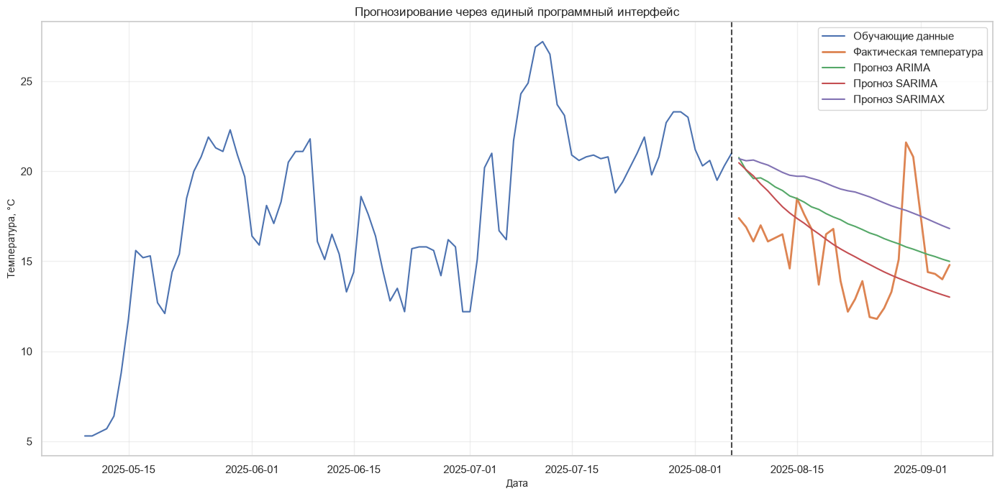

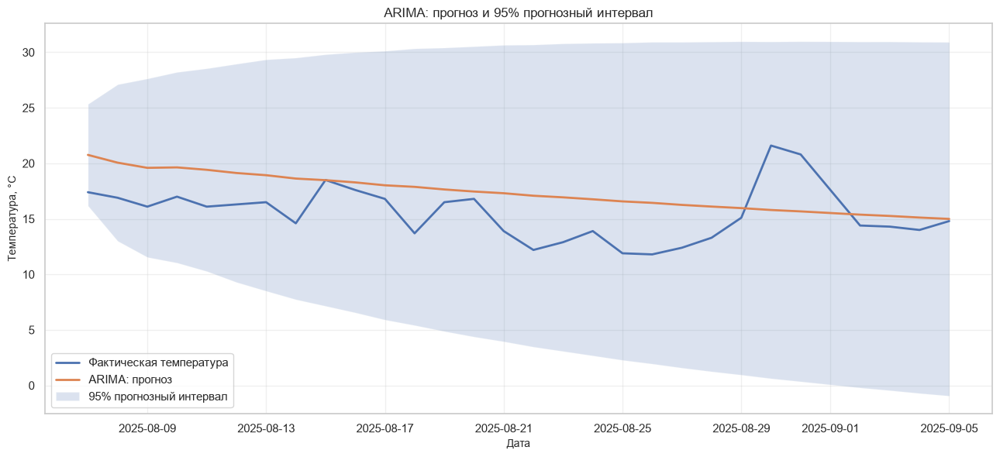


ИТОГИ ЗАДАНИЯ 10
Создан модуль: /Users/lenar_966/Desktop/ML/Practika_3/forecasting_wrapper.py
Поддерживаемые модели: ['ARIMA', 'SARIMA', 'SARIMAX']
Успешно обработано моделей: 3 / 3
Проверки сериализации: 3 / 3

Файлы моделей:
- task10_arima_wrapper.joblib
- task10_sarima_wrapper.joblib
- task10_sarimax_wrapper.joblib

Результаты сохранены:
/Users/lenar_966/Desktop/ML/Practika_3/reports/task10

ЗАДАНИЕ 10 ВЫПОЛНЕНО


In [14]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №3
# ЗАДАНИЕ 10. УНИВЕРСАЛЬНЫЙ ИНТЕРФЕЙС МОДЕЛЕЙ
# ============================================================

from pathlib import Path
import sys
import json
import textwrap
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. ПУТИ ПРОЕКТА
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_3"

DATA_DIR = PROJECT / "data"
REPORT_DIR = PROJECT / "reports" / "task10"
MODEL_DIR = PROJECT / "models"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODULE_PATH = PROJECT / "forecasting_wrapper.py"

TARGET = "temperature_2m_mean"
TRAIN_SHARE = 0.8
HORIZON = 30

print("=" * 75)
print("ЗАДАНИЕ 10. УНИВЕРСАЛЬНЫЙ ИНТЕРФЕЙС")
print("=" * 75)

# ============================================================
# 2. СОЗДАНИЕ МОДУЛЯ forecasting_wrapper.py
# ============================================================

MODULE_CODE = r'''
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import joblib

from scipy.stats import shapiro
from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    het_breuschpagan
)
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX


class ForecastingWrapper:
    """
    Универсальный интерфейс ARIMA, SARIMA, SARIMAX.

    Методы:
        fit()
        predict()
        forecast()
        diagnose()
        save()
        load()

    Данные:
        pandas.Series с DatetimeIndex и дневной частотой.

    ВАЖНО:
        predict() выполняет прогноз за пределами
        обучающей выборки, а не in-sample prediction.
    """

    SUPPORTED_MODELS = {
        "ARIMA",
        "SARIMA",
        "SARIMAX"
    }

    def __init__(
        self,
        model_type="ARIMA",
        order=(5, 0, 2),
        seasonal_order=(1, 0, 1, 7),
        trend="c"
    ):

        model_type = str(model_type).upper()

        if model_type not in self.SUPPORTED_MODELS:
            raise ValueError(
                f"Неизвестная модель: {model_type}"
            )

        self.model_type = model_type
        self.order = tuple(order)
        self.seasonal_order = tuple(seasonal_order)
        self.trend = trend

        self.model_ = None
        self.result_ = None
        self.train_series_ = None
        self.is_fitted_ = False

    @staticmethod
    def _validate_series(series):

        if not isinstance(series, pd.Series):
            raise TypeError(
                "Ожидается pandas.Series."
            )

        if not isinstance(
            series.index,
            pd.DatetimeIndex
        ):
            raise TypeError(
                "Индекс должен быть DatetimeIndex."
            )

        series = series.sort_index().copy()

        if series.index.has_duplicates:
            raise ValueError(
                "Обнаружены повторяющиеся даты."
            )

        if series.isna().any():
            raise ValueError(
                "Обнаружены пропущенные значения."
            )

        if not np.issubdtype(
            series.dtype,
            np.number
        ):
            raise TypeError(
                "Значения ряда должны быть числовыми."
            )

        if not np.isfinite(
            series.to_numpy(dtype=float)
        ).all():
            raise ValueError(
                "Ряд содержит бесконечные значения."
            )

        if len(series) < 50:
            raise ValueError(
                "Недостаточно наблюдений для обучения."
            )

        expected_index = pd.date_range(
            start=series.index[0],
            periods=len(series),
            freq="D"
        )

        if not series.index.equals(expected_index):
            raise ValueError(
                "Временной ряд должен иметь "
                "непрерывную дневную частоту."
            )

        return series.asfreq("D")

    @staticmethod
    def _calendar_features(index):

        index = pd.DatetimeIndex(index)

        day = index.dayofyear.to_numpy()

        return pd.DataFrame(
            {
                "annual_sin_1": np.sin(
                    2 * np.pi * day / 365.25
                ),
                "annual_cos_1": np.cos(
                    2 * np.pi * day / 365.25
                ),
                "annual_sin_2": np.sin(
                    4 * np.pi * day / 365.25
                ),
                "annual_cos_2": np.cos(
                    4 * np.pi * day / 365.25
                )
            },
            index=index
        )

    def fit(self, series):

        series = self._validate_series(series)

        self.train_series_ = series

        if self.model_type == "ARIMA":

            self.model_ = ARIMA(
                series,
                order=self.order,
                trend=self.trend,
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            self.result_ = self.model_.fit()

        elif self.model_type == "SARIMA":

            self.model_ = SARIMAX(
                series,
                order=self.order,
                seasonal_order=self.seasonal_order,
                trend=self.trend,
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            self.result_ = self.model_.fit(
                disp=False,
                maxiter=100
            )

        elif self.model_type == "SARIMAX":

            exog = self._calendar_features(
                series.index
            )

            self.model_ = SARIMAX(
                series,
                exog=exog,
                order=self.order,
                seasonal_order=self.seasonal_order,
                trend=self.trend,
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            self.result_ = self.model_.fit(
                disp=False,
                maxiter=100
            )

        self.is_fitted_ = True

        return self

    def _check_fitted(self):

        if not self.is_fitted_:
            raise RuntimeError(
                "Сначала вызовите fit()."
            )

    def forecast(
        self,
        steps=30,
        alpha=0.05
    ):

        self._check_fitted()

        steps = int(steps)

        if steps <= 0:
            raise ValueError(
                "steps должен быть положительным."
            )

        if not 0 < alpha < 1:
            raise ValueError(
                "alpha должен быть между 0 и 1."
            )

        last_date = self.train_series_.index[-1]

        future_index = pd.date_range(
            last_date + pd.Timedelta(days=1),
            periods=steps,
            freq="D"
        )

        if self.model_type == "SARIMAX":

            future_exog = self._calendar_features(
                future_index
            )

            forecast_result = (
                self.result_.get_forecast(
                    steps=steps,
                    exog=future_exog
                )
            )

        else:

            forecast_result = (
                self.result_.get_forecast(
                    steps=steps
                )
            )

        mean = np.asarray(
            forecast_result.predicted_mean,
            dtype=float
        )

        intervals = np.asarray(
            forecast_result.conf_int(alpha=alpha),
            dtype=float
        )

        return pd.DataFrame(
            {
                "date": future_index,
                "forecast": mean,
                "lower": intervals[:, 0],
                "upper": intervals[:, 1]
            }
        )

    def predict(
        self,
        start=None,
        end=None
    ):

        """
        Возвращает out-of-sample прогноз
        для указанного интервала дат.

        start/end должны находиться строго
        после конца обучающей выборки.
        """

        self._check_fitted()

        last_date = self.train_series_.index[-1]

        if start is None:
            start = (
                last_date + pd.Timedelta(days=1)
            )
        else:
            start = pd.Timestamp(start)

        if end is None:
            end = start
        else:
            end = pd.Timestamp(end)

        if start <= last_date:
            raise ValueError(
                "predict() поддерживает только "
                "даты после окончания обучения."
            )

        if end < start:
            raise ValueError(
                "end не может быть раньше start."
            )

        steps = int(
            (end - last_date).days
        )

        result = self.forecast(
            steps=steps
        )

        return result[
            (result["date"] >= start)
            & (result["date"] <= end)
        ].reset_index(drop=True)

    def diagnose(
        self,
        lags=(7, 14, 21, 30),
        burn=30
    ):

        self._check_fitted()

        residuals = np.asarray(
            self.result_.resid,
            dtype=float
        )

        residuals = residuals[
            int(burn):
        ]

        residuals = residuals[
            np.isfinite(residuals)
        ]

        if len(residuals) < 40:
            raise ValueError(
                "Недостаточно остатков для диагностики."
            )

        # Тест Льюнга — Бокса.
        lb = acorr_ljungbox(
            residuals,
            lags=list(lags),
            return_df=True
        )

        # Тест Шапиро — Уилка.
        shapiro_stat, shapiro_p = shapiro(
            residuals
        )

        # Тест Бройша — Пагана.
        n = len(residuals)
        t = np.arange(n)

        exog_bp = np.column_stack([
            np.ones(n),
            (t - t.mean()) / max(t.std(), 1),
            np.sin(2 * np.pi * t / 365.25),
            np.cos(2 * np.pi * t / 365.25)
        ])

        bp = het_breuschpagan(
            residuals,
            exog_bp
        )

        return {
            "model": self.model_type,
            "n_residuals": int(n),
            "mean_residual": float(
                np.mean(residuals)
            ),
            "std_residual": float(
                np.std(residuals, ddof=1)
            ),
            "ljung_box": {
                int(lag): {
                    "statistic": float(
                        lb.loc[lag, "lb_stat"]
                    ),
                    "p_value": float(
                        lb.loc[lag, "lb_pvalue"]
                    )
                }
                for lag in lags
            },
            "shapiro": {
                "statistic": float(shapiro_stat),
                "p_value": float(shapiro_p)
            },
            "breusch_pagan": {
                "lm_statistic": float(bp[0]),
                "lm_p_value": float(bp[1]),
                "f_statistic": float(bp[2]),
                "f_p_value": float(bp[3])
            }
        }

    def save(self, path):

        self._check_fitted()

        path = Path(path)
        path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        joblib.dump(
            self,
            path
        )

        return path

    @classmethod
    def load(cls, path):

        path = Path(path)

        if not path.exists():
            raise FileNotFoundError(path)

        loaded = joblib.load(path)

        if not isinstance(loaded, cls):
            raise TypeError(
                "Файл не содержит ForecastingWrapper."
            )

        loaded._check_fitted()

        return loaded

    def get_params(self):

        self._check_fitted()

        return pd.DataFrame({
            "parameter": self.result_.param_names,
            "coefficient": np.asarray(
                self.result_.params
            ),
            "p_value": np.asarray(
                self.result_.pvalues
            )
        })

    def get_config(self):

        return {
            "model_type": self.model_type,
            "order": self.order,
            "seasonal_order": self.seasonal_order,
            "trend": self.trend,
            "is_fitted": self.is_fitted_
        }
'''

MODULE_PATH.write_text(
    textwrap.dedent(MODULE_CODE).lstrip(),
    encoding="utf-8"
)

print("\nМодуль создан:")
print(MODULE_PATH)

# ============================================================
# 3. ИМПОРТ СОЗДАННОГО КЛАССА
# ============================================================

if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

import importlib
import forecasting_wrapper

importlib.reload(forecasting_wrapper)

from forecasting_wrapper import ForecastingWrapper

print("\nКласс ForecastingWrapper импортирован.")

# ============================================================
# 4. ЗАГРУЗКА ВРЕМЕННОГО РЯДА
# ============================================================

candidates = [
    DATA_DIR / "task1_prepared_series.csv",
    ROOT / "Practika_1" / "data" / "features_dataset.csv",
    ROOT / "Practika_1" / "data" / "processed_dataset.csv",
    ROOT / "Practika_2" / "data" / "features_dataset.csv"
]

SOURCE_PATH = next(
    (p for p in candidates if p.is_file()),
    None
)

if SOURCE_PATH is None:
    raise FileNotFoundError(
        "Не найден исходный файл временного ряда."
    )

df = pd.read_csv(SOURCE_PATH)

date_col = next(
    (c for c in ["date", "timestamp", "time"] if c in df.columns),
    None
)

if date_col is None:
    raise ValueError("Не найдена колонка даты.")

if TARGET not in df.columns:
    raise ValueError("Не найдена целевая переменная.")

df[date_col] = pd.to_datetime(
    df[date_col],
    utc=True,
    errors="coerce"
)

df[TARGET] = pd.to_numeric(
    df[TARGET],
    errors="coerce"
)

df = df.sort_values(date_col).reset_index(drop=True)

if (
    df[date_col].isna().any()
    or df[TARGET].isna().any()
    or df[date_col].duplicated().any()
):
    raise ValueError(
        "Некорректные даты, пропуски или дубликаты."
    )

df[date_col] = df[date_col].dt.tz_convert(None)

series = pd.Series(
    df[TARGET].to_numpy(dtype=float),
    index=pd.DatetimeIndex(df[date_col]),
    name=TARGET
).asfreq("D")

split_index = int(
    len(series) * TRAIN_SHARE
)

train = series.iloc[:split_index]
test = series.iloc[split_index:]

print("\n=== ДАННЫЕ ===")
print("Всего наблюдений:", len(series))
print("Обучение:", len(train))
print("Тест:", len(test))

# ============================================================
# 5. КОНФИГУРАЦИИ МОДЕЛЕЙ
# ============================================================

CONFIGS = {
    "ARIMA": {
        "model_type": "ARIMA",
        "order": (5, 0, 2)
    },
    "SARIMA": {
        "model_type": "SARIMA",
        "order": (2, 0, 1),
        "seasonal_order": (1, 0, 1, 7)
    },
    "SARIMAX": {
        "model_type": "SARIMAX",
        "order": (2, 0, 1),
        "seasonal_order": (1, 0, 1, 7)
    }
}

# ============================================================
# 6. ОБУЧЕНИЕ И ПРОГНОЗИРОВАНИЕ
# ============================================================

print("\n" + "=" * 75)
print("ОБУЧЕНИЕ И ПРОГНОЗИРОВАНИЕ")
print("=" * 75)

models = {}
forecast_tables = []
diagnostics_rows = []
serialization_rows = []
status_rows = []

for name, config in CONFIGS.items():

    print(f"\n--- {name} ---")

    try:
        wrapper = ForecastingWrapper(**config)

        wrapper.fit(train)

        models[name] = wrapper

        # Прогноз на 30 дней.
        forecast_df = wrapper.forecast(
            steps=HORIZON,
            alpha=0.05
        )

        forecast_df["model"] = name

        forecast_tables.append(
            forecast_df.copy()
        )

        actual = test.iloc[:HORIZON].to_numpy()

        errors = (
            actual
            - forecast_df["forecast"].to_numpy()
        )

        mae = float(
            np.mean(np.abs(errors))
        )

        rmse = float(
            np.sqrt(np.mean(errors ** 2))
        )

        print(
            f"MAE={mae:.4f}, RMSE={rmse:.4f}"
        )

        # Проверка predict().
        prediction_by_dates = wrapper.predict(
            start=test.index[0],
            end=test.index[6]
        )

        print(
            "predict() вернул строк:",
            len(prediction_by_dates)
        )

        # Диагностика.
        diagnostics = wrapper.diagnose()

        diagnostics_rows.append({
            "model": name,
            "n_residuals": diagnostics["n_residuals"],
            "mean_residual": diagnostics["mean_residual"],
            "std_residual": diagnostics["std_residual"],
            "LB_p_30": diagnostics[
                "ljung_box"
            ][30]["p_value"],
            "Shapiro_p": diagnostics[
                "shapiro"
            ]["p_value"],
            "BP_p": diagnostics[
                "breusch_pagan"
            ]["lm_p_value"]
        })

        # Сериализация.
        model_path = (
            MODEL_DIR
            / f"task10_{name.lower()}_wrapper.joblib"
        )

        wrapper.save(model_path)

        restored = ForecastingWrapper.load(
            model_path
        )

        restored_forecast = restored.forecast(
            steps=HORIZON
        )

        max_difference = float(
            np.max(
                np.abs(
                    forecast_df["forecast"].to_numpy()
                    - restored_forecast["forecast"].to_numpy()
                )
            )
        )

        serialization_passed = bool(
            np.allclose(
                forecast_df["forecast"].to_numpy(),
                restored_forecast["forecast"].to_numpy(),
                rtol=0,
                atol=1e-10
            )
        )

        serialization_rows.append({
            "model": name,
            "saved_path": str(model_path),
            "max_difference": max_difference,
            "passed": serialization_passed
        })

        print(
            "Сериализация:",
            "PASS" if serialization_passed else "FAIL"
        )

        status_rows.append({
            "model": name,
            "status": "OK",
            "MAE": mae,
            "RMSE": rmse
        })

    except Exception as exc:

        status_rows.append({
            "model": name,
            "status": (
                f"ERROR: {type(exc).__name__}: {exc}"
            ),
            "MAE": np.nan,
            "RMSE": np.nan
        })

        print(
            "Ошибка:", type(exc).__name__, exc
        )

# ============================================================
# 7. ОБЪЕДИНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

status_df = pd.DataFrame(status_rows)
serialization_df = pd.DataFrame(serialization_rows)
diagnostics_df = pd.DataFrame(diagnostics_rows)

if not forecast_tables:
    raise RuntimeError(
        "Не удалось получить ни одного прогноза."
    )

all_forecasts = pd.concat(
    forecast_tables,
    ignore_index=True
)

print("\n" + "=" * 75)
print("РЕЗУЛЬТАТЫ ОБУЧЕНИЯ")
print("=" * 75)

print(
    status_df.round(4).to_string(
        index=False
    )
)

print("\n" + "=" * 75)
print("РЕЗУЛЬТАТЫ ДИАГНОСТИКИ")
print("=" * 75)

print(
    diagnostics_df.round(6).to_string(
        index=False
    )
)

print("\n" + "=" * 75)
print("ПРОВЕРКА СЕРИАЛИЗАЦИИ")
print("=" * 75)

print(
    serialization_df.to_string(
        index=False
    )
)

# ============================================================
# 8. ГРАФИК ПРОГНОЗОВ
# ============================================================

plt.figure(figsize=(14, 7))

history = train.iloc[-90:]

plt.plot(
    history.index,
    history.to_numpy(),
    label="Обучающие данные",
    linewidth=1.5
)

plt.plot(
    test.index[:HORIZON],
    test.iloc[:HORIZON].to_numpy(),
    label="Фактическая температура",
    linewidth=2
)

for name in CONFIGS.keys():

    subset = all_forecasts[
        all_forecasts["model"] == name
    ]

    if subset.empty:
        continue

    plt.plot(
        subset["date"],
        subset["forecast"],
        label=f"Прогноз {name}",
        linewidth=1.5
    )

plt.axvline(
    train.index[-1],
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.title(
    "Прогнозирование через единый программный интерфейс"
)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "wrapper_forecasts.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 9. ДОВЕРИТЕЛЬНЫЕ ИНТЕРВАЛЫ ARIMA
# ============================================================

if "ARIMA" in models:

    arima_forecast = models["ARIMA"].forecast(
        steps=HORIZON
    )

    plt.figure(figsize=(13, 6))

    plt.plot(
        test.index[:HORIZON],
        test.iloc[:HORIZON].to_numpy(),
        label="Фактическая температура",
        linewidth=2
    )

    plt.plot(
        arima_forecast["date"],
        arima_forecast["forecast"],
        label="ARIMA: прогноз",
        linewidth=2
    )

    plt.fill_between(
        arima_forecast["date"],
        arima_forecast["lower"],
        arima_forecast["upper"],
        alpha=0.2,
        label="95% прогнозный интервал"
    )

    plt.title(
        "ARIMA: прогноз и 95% прогнозный интервал"
    )

    plt.xlabel("Дата")
    plt.ylabel("Температура, °C")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / "arima_forecast_intervals.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

# ============================================================
# 10. СОХРАНЕНИЕ ТАБЛИЦ
# ============================================================

status_df.to_csv(
    REPORT_DIR / "model_status.csv",
    index=False,
    encoding="utf-8-sig"
)

diagnostics_df.to_csv(
    REPORT_DIR / "diagnostics.csv",
    index=False,
    encoding="utf-8-sig"
)

serialization_df.to_csv(
    REPORT_DIR / "serialization_checks.csv",
    index=False,
    encoding="utf-8-sig"
)

all_forecasts.to_csv(
    REPORT_DIR / "forecasts.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 11. JSON-ОТЧЁТ
# ============================================================

summary = {
    "task": 10,
    "target": TARGET,
    "observations": int(len(series)),
    "train_observations": int(len(train)),
    "test_observations": int(len(test)),
    "forecast_horizon": HORIZON,
    "module_path": str(MODULE_PATH),
    "supported_models": list(CONFIGS.keys()),
    "successful_models": int(
        (status_df["status"] == "OK").sum()
    ),
    "serialization_passed": int(
        serialization_df["passed"].sum()
    ) if not serialization_df.empty else 0
}

with open(
    REPORT_DIR / "task10_summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 12. ИТОГИ
# ============================================================

print("\n" + "=" * 75)
print("ИТОГИ ЗАДАНИЯ 10")
print("=" * 75)

print("Создан модуль:", MODULE_PATH)
print("Поддерживаемые модели:", list(CONFIGS.keys()))

print(
    "Успешно обработано моделей:",
    int((status_df["status"] == "OK").sum()),
    "/",
    len(CONFIGS)
)

if not serialization_df.empty:

    print(
        "Проверки сериализации:",
        int(serialization_df["passed"].sum()),
        "/",
        len(serialization_df)
    )

print("\nФайлы моделей:")
for path in sorted(MODEL_DIR.glob("task10_*_wrapper.joblib")):
    print("-", path.name)

print("\nРезультаты сохранены:")
print(REPORT_DIR)

print("\nЗАДАНИЕ 10 ВЫПОЛНЕНО")


In [15]:
from forecasting_wrapper import ForecastingWrapper

model = ForecastingWrapper(
    model_type="ARIMA",
    order=(5, 0, 2)
)

model.fit(train)

forecast = model.forecast(steps=30)

diagnostics = model.diagnose()

model.save("models/arima.joblib")

PosixPath('models/arima.joblib')

### Анализ результатов задания 10

В ходе выполнения десятого задания разработан универсальный программный интерфейс для работы с классическими моделями прогнозирования временных рядов.

Создан отдельный Python-модуль `forecasting_wrapper.py`, содержащий класс `ForecastingWrapper`.

Разработанный класс поддерживает модели ARIMA, SARIMA и SARIMAX и предоставляет единый набор методов для обучения, прогнозирования, диагностики, сохранения и восстановления моделей.

#### 1. Реализация программного интерфейса

В классе `ForecastingWrapper` реализованы следующие методы:

- `fit()` — обучение модели на временном ряду;
- `predict()` — получение прогноза на заданном будущем интервале дат;
- `forecast()` — прогнозирование на указанное количество шагов с доверительными интервалами;
- `diagnose()` — статистическая диагностика остатков;
- `save()` — сохранение обученной модели;
- `load()` — восстановление сохранённой модели.

Дополнительно реализованы проверка входных данных, формирование календарных признаков SARIMAX, получение коэффициентов и конфигурации модели.

Использование единого интерфейса позволяет сократить дублирование программного кода и упростить дальнейшее сравнение моделей.

#### 2. Проверка обучения и прогнозирования

Для проверки работоспособности интерфейса обучены три модели:

- ARIMA(5,0,2);
- SARIMA(2,0,1)(1,0,1,7);
- SARIMAX(2,0,1)(1,0,1,7) с календарными гармоническими признаками.

Все три модели успешно прошли обучение.

Прогнозирование выполнялось на фиксированном горизонте 30 дней.

Получены следующие результаты:

| Модель | MAE, °C | RMSE, °C |
|---|---:|---:|
| ARIMA | 2,7154 | 3,1466 |
| SARIMA | 2,3003 | 2,8707 |
| SARIMAX | 3,8649 | 4,1886 |

Наиболее точной моделью на рассматриваемом интервале оказалась SARIMA с MAE = 2,3003 °C.

При этом результаты соответствуют ранее проведённому эксперименту в задании 9.

#### 3. Диагностика остатков

Для каждой модели выполнена статистическая диагностика на основе 554 остатков после исключения первых 30 наблюдений.

Средние значения остатков составили:

- ARIMA — 0,0145;
- SARIMA — −0,0019;
- SARIMAX — −0,0139.

Полученные значения близки к нулю, что свидетельствует об отсутствии выраженного среднего смещения остатков на обучающей выборке.

Для теста Льюнга — Бокса на лаге 30 получены следующие p-value:

- ARIMA — 0,7137;
- SARIMA — 0,1207;
- SARIMAX — 0,2681.

Все значения превышают уровень значимости 0,05.

Следовательно, в рамках данной реализации теста не обнаружено статистически значимой автокорреляции остатков на рассматриваемом наборе лагов.

При этом в текущем интерфейсе тест выполнялся без поправки на число оценённых параметров, поэтому его результаты отличаются от диагностики задания 6 и требуют согласования методики.

Тест Шапиро — Уилка показал p-value меньше 0,05 для всех трёх моделей, что свидетельствует об отклонении распределения остатков от нормального.

Тест Бройша — Пагана также выявил статистически значимые признаки неоднородности дисперсии остатков для всех моделей.

Таким образом, диагностические результаты указывают на необходимость дальнейшей проверки предпосылок моделей и осторожной интерпретации прогнозных интервалов.

#### 4. Проверка сериализации моделей

Для сохранения обученных моделей использовалась библиотека `joblib`.

После обучения каждая модель была сохранена в отдельный файл с расширением `.joblib`.

Затем модели были восстановлены из сохранённых файлов и повторно использованы для прогнозирования на горизонте 30 дней.

Для ARIMA, SARIMA и SARIMAX максимальная разница между прогнозами до сохранения и после загрузки составила 0,0.

Все три проверки сериализации завершились успешно.

Это подтверждает, что в текущем программном окружении восстановленные модели воспроизводят результаты исходных моделей без численных расхождений.

#### 5. Практическая значимость разработанного интерфейса

Разработанный модуль позволяет использовать модели временных рядов вне Jupyter Notebook.

Его можно подключать к отдельным Python-скриптам, приложениям и автоматизированным процедурам прогнозирования.

Единый интерфейс также упрощает реализацию бэктестинга, поскольку различные модели могут обучаться и использоваться через одинаковые методы.

Дополнительным преимуществом является возможность повторного использования сохранённых моделей без необходимости выполнять обучение при каждом запуске приложения.

### Итоговый вывод

В результате выполнения десятого задания разработан и протестирован универсальный программный интерфейс `ForecastingWrapper` для моделей ARIMA, SARIMA и SARIMAX.

Реализованы методы обучения, прогнозирования, диагностики, сохранения и восстановления моделей.

Все три модели успешно обучены и сформировали прогнозы на 30 дней.

На фиксированном прогнозном интервале наименьшую среднюю абсолютную ошибку показала SARIMA — 2,3003 °C.

Статистическая диагностика выявила отклонения от нормальности распределения остатков и признаки неоднородности их дисперсии.

Проверка сериализации завершилась успешно для всех трёх моделей: прогнозы до сохранения и после восстановления полностью совпали.

Таким образом, созданный программный интерфейс обеспечивает единообразную работу с классическими моделями временных рядов и может использоваться в последующих этапах практической работы, включая бэктестинг и разработку пользовательского приложения.

## Задание 11. Rolling и Expanding Backtesting моделей временных рядов

### Цель работы

Оценить точность и устойчивость классических моделей прогнозирования временных рядов с использованием двух стратегий временной кросс-валидации: Rolling Window и Expanding Window.

### Постановка задачи

Необходимо:

1. Реализовать две стратегии бэктестинга:
   - **Rolling Window** — обучение на скользящем временном окне фиксированной длины.
   - **Expanding Window** — обучение на расширяющемся временном окне, включающем все доступные наблюдения.
2. Выполнить не менее 30 итераций прогнозирования для каждого горизонта: 1, 7 и 30 дней.
3. Для каждого окна обучить модели ARIMA, SARIMA и SARIMAX.
4. Рассчитать MAE и RMSE прогнозирования.
5. Оценить изменение ошибок между временными окнами.
6. Сравнить точность Rolling и Expanding стратегий.
7. Исследовать вычислительные затраты на обучение и прогнозирование.
8. Определить наиболее точную и устойчивую комбинацию модели и стратегии.
9. Сохранить результаты экспериментов и построить сравнительные графики.

### Методика исследования

Временной ряд разделяется на обучающую и тестовую части с сохранением хронологического порядка.

В качестве исходной обучающей выборки используются первые 80% наблюдений.

Далее выполняется последовательное перемещение точки начала прогноза по тестовому периоду.

Для каждой точки начала прогноза применяются две стратегии.

**Rolling Window:** модель обучается на последних 365 доступных наблюдениях. При переходе к следующему окну старые наблюдения исключаются, а новые добавляются.

**Expanding Window:** модель обучается на всех наблюдениях от начала временного ряда до текущей точки начала прогноза.

Для каждого окна строятся прогнозы на горизонтах 1, 7 и 30 дней.

Чтобы обеспечить сопоставимость результатов, для всех горизонтов используются одни и те же 30 точек начала прогнозирования, расположенные внутри тестового периода.

При оценке ошибки на горизонте h учитываются все прогнозируемые дни от первого до h-го.

Для контроля отсутствия утечек данных обучение каждой модели выполняется только на наблюдениях, доступных до соответствующей точки начала прогноза.

### Ожидаемый результат

Таблицы с результатами бэктестинга, сравнением стратегий Rolling и Expanding, распределением ошибок, временем вычислений и итоговым рейтингом моделей.

На основании результатов необходимо определить наиболее эффективную модель и стратегию обновления обучающей выборки.

ЗАДАНИЕ 11. ROLLING / EXPANDING BACKTESTING

Модуль ForecastingWrapper импортирован.

=== ИСХОДНЫЕ ДАННЫЕ ===
Источник: /Users/lenar_966/Desktop/ML/Practika_3/data/task1_prepared_series.csv
Всего наблюдений: 731
Обучение: 584
Тест: 147
Rolling Window: 365

=== КОНФИГУРАЦИЯ БЭКТЕСТИНГА ===
Количество точек: 30
Горизонты: [1, 7, 30]
Стратегии: ['Rolling', 'Expanding']
Модели: ['ARIMA', 'SARIMA', 'SARIMAX']
Первая точка: 2025-08-07 00:00:00
Последняя точка: 2025-12-02 00:00:00

ЗАПУСК БЭКТЕСТИНГА
Точка  1/30 | Обработано 6/180 | Время 2.9 сек.
Точка  5/30 | Обработано 30/180 | Время 14.3 сек.
Точка 10/30 | Обработано 60/180 | Время 29.6 сек.
Точка 15/30 | Обработано 90/180 | Время 45.0 сек.
Точка 20/30 | Обработано 120/180 | Время 59.8 сек.
Точка 25/30 | Обработано 150/180 | Время 73.9 сек.
Точка 30/30 | Обработано 180/180 | Время 88.7 сек.

=== ПРОВЕРКА УТЕЧЕК ===
Успешных проверок: 60 / 60
Успешных обучений: 180 / 180

СВОДНАЯ ТАБЛИЦА BACKTESTING
 strategy   model  horizon  successful_o

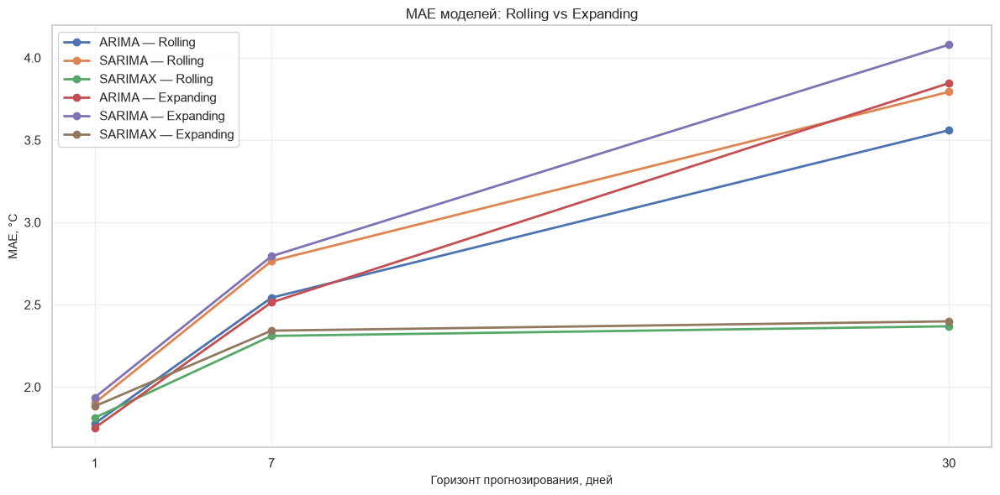

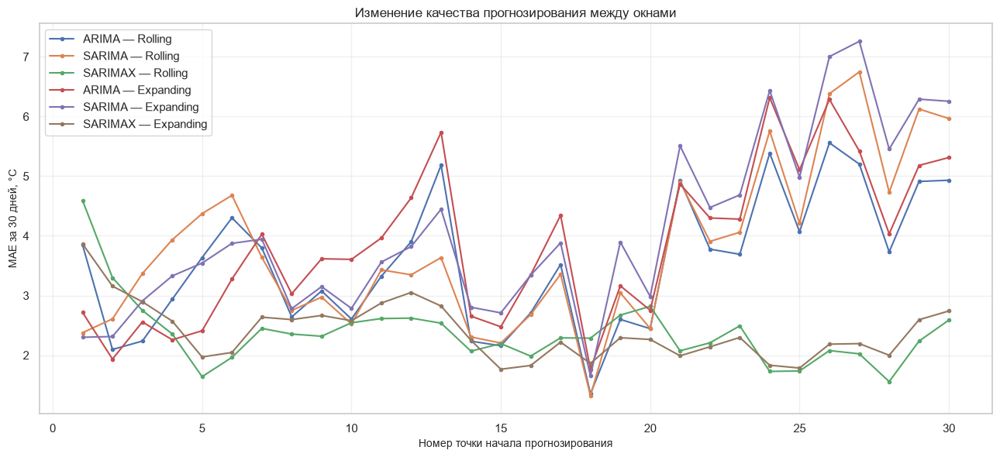

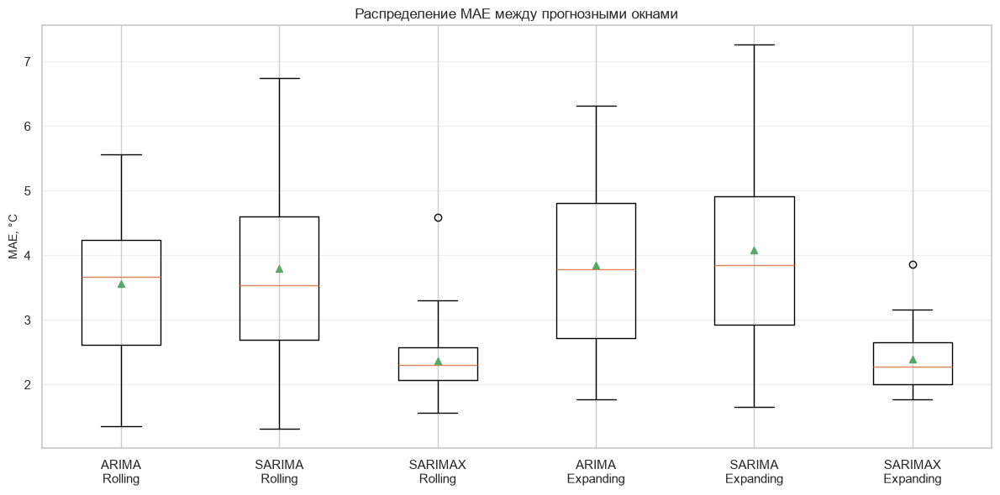


ВРЕМЯ ОБУЧЕНИЯ И ПРОГНОЗИРОВАНИЯ
 strategy   model  mean_fit_time_sec  mean_predict_time_sec
  Rolling   ARIMA             0.1611                 0.0013
Expanding   ARIMA             0.2238                 0.0013
  Rolling  SARIMA             0.3610                 0.0014
Expanding  SARIMA             0.4653                 0.0014
  Rolling SARIMAX             0.5284                 0.0054
Expanding SARIMAX             1.2042                 0.0017

ИТОГИ ЗАДАНИЯ 11
Количество точек: 30
Количество обучений: 180
Успешных обучений: 180
Проверок на утечки пройдено: 60 / 60
Общее время: 88.73 сек.

Результаты сохранены:
/Users/lenar_966/Desktop/ML/Practika_3/reports/task11

ЗАДАНИЕ 11 ВЫПОЛНЕНО


In [16]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №3
# ЗАДАНИЕ 11. ROLLING И EXPANDING BACKTESTING
# ============================================================

from pathlib import Path
from time import perf_counter
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. НАСТРОЙКИ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_3"
REPORT_DIR = PROJECT / "reports" / "task11"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "temperature_2m_mean"

TRAIN_SHARE = 0.80
ROLLING_WINDOW = 365

HORIZONS = [1, 7, 30]
MAX_HORIZON = max(HORIZONS)

N_ORIGINS = 30
ORIGIN_STEP = 1

MODEL_CONFIGS = {
    "ARIMA": {
        "model_type": "ARIMA",
        "order": (5, 0, 2)
    },
    "SARIMA": {
        "model_type": "SARIMA",
        "order": (2, 0, 1),
        "seasonal_order": (1, 0, 1, 7)
    },
    "SARIMAX": {
        "model_type": "SARIMAX",
        "order": (2, 0, 1),
        "seasonal_order": (1, 0, 1, 7)
    }
}

STRATEGIES = ["Rolling", "Expanding"]

print("=" * 75)
print("ЗАДАНИЕ 11. ROLLING / EXPANDING BACKTESTING")
print("=" * 75)

# ============================================================
# 2. ИМПОРТ КЛАССА ИЗ ЗАДАНИЯ 10
# ============================================================

if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from forecasting_wrapper import ForecastingWrapper

print("\nМодуль ForecastingWrapper импортирован.")

# ============================================================
# 3. ЗАГРУЗКА ДАННЫХ
# ============================================================

candidates = [
    PROJECT / "data" / "task1_prepared_series.csv",
    ROOT / "Practika_1" / "data" / "features_dataset.csv",
    ROOT / "Practika_1" / "data" / "processed_dataset.csv",
    ROOT / "Practika_2" / "data" / "features_dataset.csv"
]

SOURCE_PATH = next(
    (p for p in candidates if p.is_file()),
    None
)

if SOURCE_PATH is None:
    raise FileNotFoundError(
        "Не найден исходный временной ряд."
    )

df = pd.read_csv(SOURCE_PATH)

date_col = next(
    (c for c in ["date", "timestamp", "time"] if c in df.columns),
    None
)

if date_col is None:
    raise ValueError("Не найдена колонка даты.")

if TARGET not in df.columns:
    raise ValueError("Не найдена целевая переменная.")

df[date_col] = pd.to_datetime(
    df[date_col],
    utc=True,
    errors="coerce"
)

df[TARGET] = pd.to_numeric(
    df[TARGET],
    errors="coerce"
)

df = df.sort_values(date_col).reset_index(drop=True)

if (
    df[date_col].isna().any()
    or df[TARGET].isna().any()
    or df[date_col].duplicated().any()
):
    raise ValueError(
        "В данных есть пропуски или дубликаты."
    )

df[date_col] = df[date_col].dt.tz_convert(None)

series = pd.Series(
    df[TARGET].to_numpy(dtype=float),
    index=pd.DatetimeIndex(df[date_col]),
    name=TARGET
).asfreq("D")

if series.isna().any():
    raise ValueError(
        "Временной ряд содержит пропущенные дни."
    )

split_index = int(
    len(series) * TRAIN_SHARE
)

train = series.iloc[:split_index]
test = series.iloc[split_index:]

print("\n=== ИСХОДНЫЕ ДАННЫЕ ===")
print("Источник:", SOURCE_PATH)
print("Всего наблюдений:", len(series))
print("Обучение:", len(train))
print("Тест:", len(test))
print("Rolling Window:", ROLLING_WINDOW)

# ============================================================
# 4. ФОРМИРОВАНИЕ ТОЧЕК НАЧАЛА ПРОГНОЗА
# ============================================================

# Для всех горизонтов используются одни и те же
# 30 точек начала прогнозирования.
#
# Каждая точка должна оставлять не менее 30 дней
# фактических данных для проверки прогноза.

available_origins = (
    len(series)
    - split_index
    - MAX_HORIZON
    + 1
)

if available_origins < N_ORIGINS:
    raise ValueError(
        "Недостаточно тестовых наблюдений "
        "для 30 точек и горизонта 30 дней."
    )

# Распределяем точки по доступному тестовому периоду.
origin_offsets = np.linspace(
    0,
    available_origins - 1,
    N_ORIGINS,
    dtype=int
)

origin_offsets = np.unique(origin_offsets)

if len(origin_offsets) != N_ORIGINS:
    raise ValueError(
        "Не удалось получить 30 уникальных точек."
    )

origins = [
    split_index + int(offset)
    for offset in origin_offsets
]

print("\n=== КОНФИГУРАЦИЯ БЭКТЕСТИНГА ===")
print("Количество точек:", len(origins))
print("Горизонты:", HORIZONS)
print("Стратегии:", STRATEGIES)
print("Модели:", list(MODEL_CONFIGS.keys()))

print(
    "Первая точка:",
    series.index[origins[0]]
)
print(
    "Последняя точка:",
    series.index[origins[-1]]
)

# ============================================================
# 5. ФУНКЦИИ МЕТРИК
# ============================================================

def calculate_metrics(actual, predicted):

    actual = np.asarray(
        actual,
        dtype=float
    )

    predicted = np.asarray(
        predicted,
        dtype=float
    )

    errors = actual - predicted

    return {
        "MAE": float(
            np.mean(np.abs(errors))
        ),
        "RMSE": float(
            np.sqrt(np.mean(errors ** 2))
        ),
        "bias": float(
            np.mean(predicted - actual)
        )
    }


# ============================================================
# 6. ОСНОВНОЙ ЦИКЛ БЭКТЕСТИНГА
# ============================================================

metrics_rows = []
prediction_rows = []
error_rows = []
leakage_rows = []

total_fits = (
    len(origins)
    * len(STRATEGIES)
    * len(MODEL_CONFIGS)
)

completed = 0

overall_start = perf_counter()

print("\n" + "=" * 75)
print("ЗАПУСК БЭКТЕСТИНГА")
print("=" * 75)

for origin_number, origin_idx in enumerate(
    origins,
    start=1
):

    forecast_dates = series.index[
        origin_idx:origin_idx + MAX_HORIZON
    ]

    actual_full = series.iloc[
        origin_idx:origin_idx + MAX_HORIZON
    ].to_numpy(dtype=float)

    for strategy in STRATEGIES:

        if strategy == "Rolling":

            train_start_idx = max(
                0,
                origin_idx - ROLLING_WINDOW
            )

        else:

            train_start_idx = 0

        train_window = series.iloc[
            train_start_idx:origin_idx
        ].copy()

        # Проверка отсутствия утечки.
        leakage_passed = bool(
            train_window.index.max()
            < forecast_dates.min()
        )

        leakage_rows.append({
            "origin_number": origin_number,
            "origin_date": str(forecast_dates[0].date()),
            "strategy": strategy,
            "train_start": str(
                train_window.index.min().date()
            ),
            "train_end": str(
                train_window.index.max().date()
            ),
            "train_size": len(train_window),
            "forecast_start": str(
                forecast_dates.min().date()
            ),
            "leakage_passed": leakage_passed
        })

        if not leakage_passed:
            raise RuntimeError(
                "Обнаружено пересечение train и forecast."
            )

        for model_name, config in MODEL_CONFIGS.items():

            completed += 1

            fit_start = perf_counter()

            try:
                model = ForecastingWrapper(**config)

                model.fit(train_window)

                fit_time = (
                    perf_counter() - fit_start
                )

                forecast_start = perf_counter()

                forecast_df = model.forecast(
                    steps=MAX_HORIZON,
                    alpha=0.05
                )

                predict_time = (
                    perf_counter() - forecast_start
                )

                predicted_full = (
                    forecast_df["forecast"]
                    .to_numpy(dtype=float)
                )

                if len(predicted_full) != MAX_HORIZON:
                    raise ValueError(
                        "Некорректная длина прогноза."
                    )

                for h in HORIZONS:

                    y_true = actual_full[:h]
                    y_pred = predicted_full[:h]

                    result = calculate_metrics(
                        y_true,
                        y_pred
                    )

                    metrics_rows.append({
                        "origin_number": origin_number,
                        "origin_date": str(
                            forecast_dates[0].date()
                        ),
                        "strategy": strategy,
                        "model": model_name,
                        "horizon": h,
                        "train_size": len(train_window),
                        "MAE": result["MAE"],
                        "RMSE": result["RMSE"],
                        "bias": result["bias"],
                        "fit_time_sec": fit_time,
                        "predict_time_sec": predict_time,
                        "status": "OK"
                    })

                for step in range(MAX_HORIZON):

                    prediction_rows.append({
                        "origin_number": origin_number,
                        "origin_date": str(
                            forecast_dates[0].date()
                        ),
                        "strategy": strategy,
                        "model": model_name,
                        "step": step + 1,
                        "forecast_date": str(
                            forecast_dates[step].date()
                        ),
                        "actual": float(
                            actual_full[step]
                        ),
                        "predicted": float(
                            predicted_full[step]
                        ),
                        "error": float(
                            actual_full[step]
                            - predicted_full[step]
                        ),
                        "absolute_error": float(
                            abs(
                                actual_full[step]
                                - predicted_full[step]
                            )
                        )
                    })

            except Exception as exc:

                error_message = (
                    f"{type(exc).__name__}: {exc}"
                )

                error_rows.append({
                    "origin_number": origin_number,
                    "strategy": strategy,
                    "model": model_name,
                    "error": error_message
                })

                for h in HORIZONS:

                    metrics_rows.append({
                        "origin_number": origin_number,
                        "origin_date": str(
                            forecast_dates[0].date()
                        ),
                        "strategy": strategy,
                        "model": model_name,
                        "horizon": h,
                        "train_size": len(train_window),
                        "MAE": np.nan,
                        "RMSE": np.nan,
                        "bias": np.nan,
                        "fit_time_sec": np.nan,
                        "predict_time_sec": np.nan,
                        "status": "ERROR"
                    })

    if (
        origin_number == 1
        or origin_number % 5 == 0
        or origin_number == len(origins)
    ):

        elapsed = (
            perf_counter() - overall_start
        )

        print(
            f"Точка {origin_number:2d}/{len(origins)} | "
            f"Обработано {completed}/{total_fits} | "
            f"Время {elapsed:.1f} сек."
        )

total_time = perf_counter() - overall_start

# ============================================================
# 7. ТАБЛИЦЫ РЕЗУЛЬТАТОВ
# ============================================================

metrics_df = pd.DataFrame(metrics_rows)
predictions_df = pd.DataFrame(prediction_rows)
leakage_df = pd.DataFrame(leakage_rows)
errors_df = pd.DataFrame(error_rows)

print("\n=== ПРОВЕРКА УТЕЧЕК ===")

print(
    "Успешных проверок:",
    int(leakage_df["leakage_passed"].sum()),
    "/",
    len(leakage_df)
)

print(
    "Успешных обучений:",
    int(
        (
            metrics_df[
                metrics_df["horizon"] == 1
            ]["status"] == "OK"
        ).sum()
    ),
    "/",
    total_fits
)

# ============================================================
# 8. АГРЕГАЦИЯ МЕТРИК
# ============================================================

# ВАЖНО:
# Для итогового RMSE берём квадратный корень
# из среднего квадрата ошибок всех прогнозов.
# Не усредняем RMSE отдельных окон.

summary_rows = []

for (
    strategy,
    model_name,
    h
), group in metrics_df.groupby(
    ["strategy", "model", "horizon"]
):

    valid = group[
        group["status"] == "OK"
    ]

    prediction_subset = predictions_df[
        (predictions_df["strategy"] == strategy)
        & (predictions_df["model"] == model_name)
        & (predictions_df["step"] <= h)
    ]

    if prediction_subset.empty:
        continue

    errors = (
        prediction_subset["error"]
        .to_numpy(dtype=float)
    )

    summary_rows.append({
        "strategy": strategy,
        "model": model_name,
        "horizon": h,
        "successful_origins": len(valid),
        "n_predictions": len(errors),
        "MAE": float(
            np.mean(np.abs(errors))
        ),
        "RMSE": float(
            np.sqrt(np.mean(errors ** 2))
        ),
        "bias": float(
            -np.mean(errors)
        ),
        "origin_MAE_std": float(
            valid["MAE"].std()
        ),
        "mean_fit_time_sec": float(
            valid["fit_time_sec"].mean()
        ),
        "mean_predict_time_sec": float(
            valid["predict_time_sec"].mean()
        )
    })

summary_df = pd.DataFrame(
    summary_rows
).sort_values(
    ["horizon", "MAE"]
)

print("\n" + "=" * 75)
print("СВОДНАЯ ТАБЛИЦА BACKTESTING")
print("=" * 75)

print(
    summary_df.round(4).to_string(
        index=False
    )
)

# ============================================================
# 9. СРАВНЕНИЕ ROLLING И EXPANDING
# ============================================================

comparison_df = summary_df.pivot_table(
    index=["model", "horizon"],
    columns="strategy",
    values="MAE"
).reset_index()

comparison_df.columns.name = None

if (
    "Rolling" in comparison_df.columns
    and "Expanding" in comparison_df.columns
):

    comparison_df["Rolling_minus_Expanding"] = (
        comparison_df["Rolling"]
        - comparison_df["Expanding"]
    )

    comparison_df["best_strategy"] = np.where(
        comparison_df["Rolling"]
        < comparison_df["Expanding"],
        "Rolling",
        "Expanding"
    )

print("\n" + "=" * 75)
print("СРАВНЕНИЕ СТРАТЕГИЙ")
print("=" * 75)

print(
    comparison_df.round(4).to_string(
        index=False
    )
)

# ============================================================
# 10. ЛУЧШИЕ КОМБИНАЦИИ
# ============================================================

best_df = (
    summary_df
    .sort_values(
        ["horizon", "MAE", "RMSE"]
    )
    .groupby("horizon", as_index=False)
    .first()
)

print("\n" + "=" * 75)
print("ЛУЧШИЕ МОДЕЛИ ПО ГОРИЗОНТАМ")
print("=" * 75)

print(
    best_df[
        [
            "horizon",
            "strategy",
            "model",
            "MAE",
            "RMSE",
            "origin_MAE_std"
        ]
    ].round(4).to_string(
        index=False
    )
)

# ============================================================
# 11. ГРАФИК MAE ПО ГОРИЗОНТАМ
# ============================================================

plt.figure(figsize=(12, 6))

for strategy in STRATEGIES:

    for model_name in MODEL_CONFIGS:

        subset = summary_df[
            (summary_df["strategy"] == strategy)
            & (summary_df["model"] == model_name)
        ].sort_values("horizon")

        if subset.empty:
            continue

        plt.plot(
            subset["horizon"],
            subset["MAE"],
            marker="o",
            linewidth=2,
            label=f"{model_name} — {strategy}"
        )

plt.xlabel("Горизонт прогнозирования, дней")
plt.ylabel("MAE, °C")
plt.title("MAE моделей: Rolling vs Expanding")
plt.xticks(HORIZONS)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "mae_by_horizon.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 12. ГРАФИК ИЗМЕНЕНИЯ MAE ПО ТОЧКАМ
# ============================================================

plt.figure(figsize=(13, 6))

h30 = metrics_df[
    (metrics_df["horizon"] == 30)
    & (metrics_df["status"] == "OK")
]

for strategy in STRATEGIES:

    for model_name in MODEL_CONFIGS:

        subset = h30[
            (h30["strategy"] == strategy)
            & (h30["model"] == model_name)
        ].sort_values("origin_number")

        if subset.empty:
            continue

        plt.plot(
            subset["origin_number"],
            subset["MAE"],
            marker=".",
            linewidth=1.5,
            label=f"{model_name} — {strategy}"
        )

plt.xlabel("Номер точки начала прогнозирования")
plt.ylabel("MAE за 30 дней, °C")
plt.title(
    "Изменение качества прогнозирования между окнами"
)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "mae_by_origin_h30.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 13. BOXPLOT ОШИБОК ПО ОКНАМ
# ============================================================

plt.figure(figsize=(12, 6))

box_labels = []
box_values = []

for strategy in STRATEGIES:

    for model_name in MODEL_CONFIGS:

        subset = h30[
            (h30["strategy"] == strategy)
            & (h30["model"] == model_name)
        ]

        if not subset.empty:

            box_labels.append(
                f"{model_name}\n{strategy}"
            )

            box_values.append(
                subset["MAE"].to_numpy()
            )

plt.boxplot(
    box_values,
    tick_labels=box_labels,
    showmeans=True
)

plt.ylabel("MAE, °C")
plt.title("Распределение MAE между прогнозными окнами")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "mae_boxplot_h30.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 14. ВЫЧИСЛИТЕЛЬНЫЕ ЗАТРАТЫ
# ============================================================

time_df = (
    summary_df[
        summary_df["horizon"] == 30
    ][
        [
            "strategy",
            "model",
            "mean_fit_time_sec",
            "mean_predict_time_sec"
        ]
    ]
    .sort_values("mean_fit_time_sec")
)

print("\n" + "=" * 75)
print("ВРЕМЯ ОБУЧЕНИЯ И ПРОГНОЗИРОВАНИЯ")
print("=" * 75)

print(
    time_df.round(4).to_string(
        index=False
    )
)

# ============================================================
# 15. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

metrics_df.to_csv(
    REPORT_DIR / "backtest_window_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

predictions_df.to_csv(
    REPORT_DIR / "backtest_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

summary_df.to_csv(
    REPORT_DIR / "backtest_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

comparison_df.to_csv(
    REPORT_DIR / "strategy_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

best_df.to_csv(
    REPORT_DIR / "best_models.csv",
    index=False,
    encoding="utf-8-sig"
)

leakage_df.to_csv(
    REPORT_DIR / "leakage_checks.csv",
    index=False,
    encoding="utf-8-sig"
)

errors_df.to_csv(
    REPORT_DIR / "errors.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 16. JSON-ОТЧЁТ
# ============================================================

report = {
    "task": 11,
    "target": TARGET,
    "observations": int(len(series)),
    "initial_train_size": int(len(train)),
    "test_size": int(len(test)),
    "rolling_window": ROLLING_WINDOW,
    "n_origins": int(len(origins)),
    "horizons": HORIZONS,
    "strategies": STRATEGIES,
    "models": list(MODEL_CONFIGS.keys()),
    "total_fits": int(total_fits),
    "successful_fits": int(
        (
            metrics_df[
                metrics_df["horizon"] == 1
            ]["status"] == "OK"
        ).sum()
    ),
    "leakage_checks_passed": int(
        leakage_df["leakage_passed"].sum()
    ),
    "leakage_checks_total": int(
        len(leakage_df)
    ),
    "total_runtime_sec": float(total_time)
}

with open(
    REPORT_DIR / "task11_summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        report,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 17. ИТОГИ
# ============================================================

print("\n" + "=" * 75)
print("ИТОГИ ЗАДАНИЯ 11")
print("=" * 75)

print("Количество точек:", len(origins))
print("Количество обучений:", total_fits)

print(
    "Успешных обучений:",
    report["successful_fits"]
)

print(
    "Проверок на утечки пройдено:",
    report["leakage_checks_passed"],
    "/",
    report["leakage_checks_total"]
)

print(
    "Общее время:",
    round(total_time, 2),
    "сек."
)

print("\nРезультаты сохранены:")
print(REPORT_DIR)

print("\nЗАДАНИЕ 11 ВЫПОЛНЕНО")


### Анализ результатов задания 11

В ходе выполнения одиннадцатого задания проведён бэктестинг классических моделей прогнозирования среднесуточной температуры воздуха в Москве с использованием стратегий Rolling Window и Expanding Window.

Исследовались модели ARIMA(5,0,2), SARIMA и SARIMAX.

Для каждой модели выполнено прогнозирование на горизонтах 1, 7 и 30 дней.

#### 1. Организация эксперимента

В качестве исходной обучающей выборки использовались первые 80% наблюдений временного ряда.

Для бэктестинга выбраны 30 точек начала прогнозирования внутри тестового периода.

Рассматривались две стратегии формирования обучающей выборки:

- Rolling Window — обучение на последних 365 доступных наблюдениях;
- Expanding Window — обучение на всех наблюдениях от начала ряда до текущей точки прогнозирования.

Для каждой точки начала прогнозирования обучались три модели с использованием обеих стратегий.

Всего выполнено 180 обучений моделей.

Все 180 обучений завершились успешно.

Дополнительно проведено 60 проверок отсутствия пересечения между обучающими и прогнозируемыми интервалами. Все проверки завершились успешно.

Общее время выполнения эксперимента составило 88,73 секунды.

#### 2. Результаты на горизонте 1 день

Наиболее точной моделью оказалась ARIMA(5,0,2) со стратегией Expanding Window.

Получены следующие показатели:

- MAE = 1,7514 °C;
- RMSE = 2,3019 °C.

Второе место заняла ARIMA Rolling с MAE = 1,7781 °C.

SARIMAX Rolling показала MAE = 1,8132 °C.

Таким образом, на однодневном горизонте преимущество получила ARIMA.

Это свидетельствует о высокой эффективности авторегрессионной структуры модели при краткосрочном прогнозировании температуры.

#### 3. Результаты на горизонте 7 дней

Наиболее точной моделью оказалась SARIMAX со стратегией Rolling Window.

Получены следующие результаты:

- MAE = 2,3105 °C;
- RMSE = 2,8986 °C.

Для SARIMAX Expanding MAE составила 2,3423 °C.

Лучшая комбинация ARIMA показала MAE = 2,5137 °C.

Следовательно, на семидневном горизонте SARIMAX Rolling снизила среднюю абсолютную ошибку приблизительно на 8,1% относительно лучшей ARIMA.

Полученные результаты указывают на возможное преимущество использования календарных признаков и сезонных компонентов при прогнозировании на несколько дней вперёд.

#### 4. Результаты на горизонте 30 дней

Наиболее точной моделью оказалась SARIMAX Rolling.

Её показатели составили:

- MAE = 2,3689 °C;
- RMSE = 3,0119 °C.

SARIMAX Expanding показала MAE = 2,3990 °C.

Для ARIMA Rolling MAE составила 3,5597 °C, а для SARIMA Rolling — 3,7928 °C.

Таким образом, SARIMAX Rolling обеспечила снижение MAE приблизительно на 33,5% относительно лучшей ARIMA.

Это наиболее выраженное преимущество SARIMAX среди рассмотренных горизонтов прогнозирования.

При этом метрики рассчитывались по всем прогнозным шагам от первого до тридцатого, поэтому характеризуют среднюю точность внутри 30-дневного прогнозного интервала.

#### 5. Сравнение стратегий Rolling и Expanding

Сравнение показало, что Rolling Window обеспечивает меньшую MAE в семи из девяти комбинаций модели и горизонта прогнозирования.

Для SARIMA и SARIMAX стратегия Rolling оказалась лучше на всех трёх горизонтах.

Для ARIMA стратегия Expanding показала немного более высокую точность на горизонтах 1 и 7 дней, тогда как на горизонте 30 дней преимущество получила Rolling.

Полученные результаты свидетельствуют о том, что использование более актуального ограниченного обучающего окна может улучшать качество прогнозирования.

Однако эффективность стратегии зависит от выбранной модели и горизонта.

#### 6. Анализ стабильности прогнозирования

Для оценки устойчивости результатов рассчитано стандартное отклонение MAE между 30 прогнозными окнами.

На горизонте 30 дней получены следующие значения:

- SARIMAX Expanding — 0,4839 °C;
- SARIMAX Rolling — 0,5656 °C;
- ARIMA Rolling — 1,1332 °C;
- ARIMA Expanding — 1,2846 °C;
- SARIMA Rolling — 1,3767 °C;
- SARIMA Expanding — 1,4811 °C.

Наиболее стабильные результаты продемонстрировали обе стратегии SARIMAX.

При этом SARIMAX Expanding имеет минимальный разброс ошибки, а SARIMAX Rolling — минимальную среднюю абсолютную ошибку.

Следовательно, SARIMAX обеспечивает наиболее устойчивое качество прогнозирования на 30-дневном горизонте в проведённом эксперименте.

#### 7. Анализ вычислительных затрат

Среднее время обучения ARIMA Rolling составило 0,1611 секунды, ARIMA Expanding — 0,2238 секунды.

Для SARIMA соответствующие значения составили 0,3610 и 0,4653 секунды.

Для SARIMAX Rolling среднее время обучения составило 0,5284 секунды, а для SARIMAX Expanding — 1,2042 секунды.

Таким образом, ARIMA является наиболее быстрой моделью.

SARIMAX требует больше вычислительных ресурсов, однако на горизонтах 7 и 30 дней обеспечивает более высокую точность прогнозирования.

Использование Rolling Window позволяет сократить время обучения SARIMAX приблизительно в 2,3 раза по сравнению с Expanding Window.

#### 8. Ограничения эксперимента

В ходе бэктестинга использовались 30 точек начала прогнозирования, расположенных внутри тестового периода.

Поскольку прогнозные интервалы частично перекрываются, ошибки соседних прогнозов могут быть зависимыми.

Кроме того, в каждой точке начала прогнозирования модели переобучались с использованием фактических наблюдений, доступных к соответствующей дате.

Поэтому результаты характеризуют качество прогнозирования в условиях регулярного обновления моделей.

Для окончательной оценки различий между моделями желательно дополнительно учитывать зависимость ошибок и проверять статистическую значимость различий.

### Итоговый вывод

В результате выполнения одиннадцатого задания реализованы и исследованы стратегии Rolling Window и Expanding Window для моделей ARIMA, SARIMA и SARIMAX.

Выполнено 180 успешных обучений и 60 проверок корректности временного разделения данных.

На горизонте 1 день наилучший результат показала ARIMA Expanding с MAE = 1,7514 °C.

На горизонте 7 дней лучшей оказалась SARIMAX Rolling с MAE = 2,3105 °C.

На горизонте 30 дней SARIMAX Rolling также продемонстрировала минимальную MAE = 2,3689 °C.

Стратегия Rolling Window оказалась эффективнее Expanding Window в семи из девяти сравнений.

SARIMAX продемонстрировала наиболее высокую точность и стабильность на среднесрочном и более длительном горизонтах прогнозирования, тогда как ARIMA сохранила преимущество в краткосрочном прогнозировании и скорости обучения.

Таким образом, результаты бэктестинга позволяют рекомендовать ARIMA Expanding для прогнозирования на один день и SARIMAX Rolling для прогнозирования на горизонтах 7 и 30 дней.

Полученные результаты будут использованы при разработке и тестировании итогового программного решения.

## Задание 12. Автоматизированное тестирование и воспроизводимость результатов

### Цель работы

Разработать набор автоматизированных тестов для проверки корректности программного интерфейса моделей прогнозирования временных рядов, обеспечить воспроизводимость результатов и зафиксировать версии используемых библиотек.

### Постановка задачи

Необходимо выполнить следующие действия:

1. Разработать автоматизированные тесты для класса `ForecastingWrapper`, созданного в задании 10.
2. Проверить корректность обучения моделей ARIMA, SARIMA и SARIMAX.
3. Проверить работу методов `fit()`, `predict()`, `forecast()`, `diagnose()`, `save()` и `load()`.
4. Проверить обработку некорректных входных данных: пропусков, повторяющихся дат, неправильного типа индекса и недостаточного количества наблюдений.
5. Проверить длину прогнозного интервала, корректность дат и конечность прогнозных значений.
6. Проверить воспроизводимость прогнозов после сохранения и восстановления моделей.
7. Проверить отсутствие использования будущих фактических значений при прогнозировании.
8. Зафиксировать версии Python и основных библиотек.
9. Сформировать отчёт о прохождении тестов и сохранить результаты.

### Методика выполнения

Для автоматизированного тестирования используется библиотека `pytest`.

Тесты выполняются на синтетическом временном ряду с известной структурой, содержащем тренд, сезонную составляющую и случайный шум.

Синтетические данные позволяют проверить корректность программной реализации независимо от особенностей исходного набора температурных наблюдений.

Дополнительно выполняется интеграционная проверка на реальном временном ряду среднесуточной температуры Москвы.

Для обеспечения воспроизводимости используется фиксированное начальное значение генератора случайных чисел.

### Ожидаемый результат

Создан тестовый модуль `tests/test_forecasting_wrapper.py`, успешно выполнены автоматизированные проверки, сохранён отчёт pytest и сформированы файлы с версиями библиотек.

Результаты должны подтвердить корректность работы интерфейса и возможность воспроизведения прогнозов в используемом программном окружении.

In [17]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №3
# ЗАДАНИЕ 12. PYTEST И ВОСПРОИЗВОДИМОСТЬ
# ============================================================

from pathlib import Path
import sys
import json
import subprocess
import platform
import importlib.metadata as metadata
import textwrap
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib
import scipy
import statsmodels
import joblib
import pytest

# ============================================================
# 1. ПУТИ ПРОЕКТА
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_3"

TEST_DIR = PROJECT / "tests"
REPORT_DIR = PROJECT / "reports" / "task12"

TEST_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

TEST_FILE = TEST_DIR / "test_forecasting_wrapper.py"
MODULE_FILE = PROJECT / "forecasting_wrapper.py"

if not MODULE_FILE.exists():
    raise FileNotFoundError(
        "Не найден forecasting_wrapper.py. "
        "Сначала выполните задание 10."
    )

print("=" * 75)
print("ЗАДАНИЕ 12. АВТОМАТИЗИРОВАННОЕ ТЕСТИРОВАНИЕ")
print("=" * 75)

# ============================================================
# 2. СОЗДАНИЕ ФАЙЛА С ТЕСТАМИ
# ============================================================

TEST_CODE = r'''
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import pytest

PROJECT = Path(__file__).resolve().parents[1]

if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from forecasting_wrapper import ForecastingWrapper


# ============================================================
# ФИКСТУРЫ
# ============================================================

@pytest.fixture(scope="module")
def synthetic_series():

    rng = np.random.default_rng(42)

    n = 180

    dates = pd.date_range(
        "2024-01-01",
        periods=n,
        freq="D"
    )

    t = np.arange(n)

    values = (
        8
        + 0.01 * t
        + 10 * np.sin(2 * np.pi * t / 365.25)
        + rng.normal(0, 1.0, n)
    )

    return pd.Series(
        values,
        index=dates,
        name="temperature_2m_mean"
    )


@pytest.fixture(scope="module")
def fitted_arima(synthetic_series):

    model = ForecastingWrapper(
        model_type="ARIMA",
        order=(2, 0, 1)
    )

    return model.fit(synthetic_series)


# ============================================================
# ТЕСТ 1. СОЗДАНИЕ МОДЕЛИ
# ============================================================

def test_model_initialization():

    model = ForecastingWrapper(
        model_type="ARIMA",
        order=(2, 0, 1)
    )

    assert model.model_type == "ARIMA"
    assert model.is_fitted_ is False


# ============================================================
# ТЕСТ 2. НЕИЗВЕСТНАЯ МОДЕЛЬ
# ============================================================

def test_invalid_model_type():

    with pytest.raises(ValueError):

        ForecastingWrapper(
            model_type="UNKNOWN"
        )


# ============================================================
# ТЕСТ 3. ОБУЧЕНИЕ ТРЁХ МОДЕЛЕЙ
# ============================================================

@pytest.mark.parametrize(
    "model_type",
    ["ARIMA", "SARIMA", "SARIMAX"]
)
def test_fit_supported_models(
    synthetic_series,
    model_type
):

    model = ForecastingWrapper(
        model_type=model_type,
        order=(1, 0, 0),
        seasonal_order=(1, 0, 0, 7)
    )

    model.fit(synthetic_series)

    assert model.is_fitted_
    assert model.result_ is not None


# ============================================================
# ТЕСТ 4. ПРОГНОЗ НА 30 ДНЕЙ
# ============================================================

def test_forecast_length(fitted_arima):

    forecast = fitted_arima.forecast(
        steps=30
    )

    assert len(forecast) == 30


# ============================================================
# ТЕСТ 5. КОРРЕКТНОСТЬ ДАТ
# ============================================================

def test_forecast_dates(
    fitted_arima,
    synthetic_series
):

    forecast = fitted_arima.forecast(
        steps=7
    )

    expected = pd.date_range(
        synthetic_series.index[-1]
        + pd.Timedelta(days=1),
        periods=7,
        freq="D"
    )

    assert list(forecast["date"]) == list(expected)


# ============================================================
# ТЕСТ 6. КОНЕЧНОСТЬ ПРОГНОЗОВ
# ============================================================

def test_forecast_finite(fitted_arima):

    forecast = fitted_arima.forecast(
        steps=30
    )

    assert np.isfinite(
        forecast[
            ["forecast", "lower", "upper"]
        ].to_numpy()
    ).all()


# ============================================================
# ТЕСТ 7. КОРРЕКТНОСТЬ ИНТЕРВАЛОВ
# ============================================================

def test_prediction_intervals(fitted_arima):

    forecast = fitted_arima.forecast(
        steps=30
    )

    assert (
        forecast["lower"]
        <= forecast["upper"]
    ).all()

    assert (
        forecast["forecast"]
        >= forecast["lower"]
    ).all()

    assert (
        forecast["forecast"]
        <= forecast["upper"]
    ).all()


# ============================================================
# ТЕСТ 8. МЕТОД PREDICT
# ============================================================

def test_predict_date_range(
    fitted_arima,
    synthetic_series
):

    start = (
        synthetic_series.index[-1]
        + pd.Timedelta(days=1)
    )

    end = start + pd.Timedelta(days=6)

    prediction = fitted_arima.predict(
        start=start,
        end=end
    )

    assert len(prediction) == 7
    assert prediction["date"].iloc[0] == start
    assert prediction["date"].iloc[-1] == end


# ============================================================
# ТЕСТ 9. ОТКАЗ ДО ОБУЧЕНИЯ
# ============================================================

def test_forecast_before_fit():

    model = ForecastingWrapper()

    with pytest.raises(RuntimeError):
        model.forecast(steps=7)


# ============================================================
# ТЕСТ 10. НЕПРАВИЛЬНЫЙ ГОРИЗОНТ
# ============================================================

@pytest.mark.parametrize(
    "steps",
    [0, -1, -10]
)
def test_invalid_forecast_steps(
    fitted_arima,
    steps
):

    with pytest.raises(ValueError):
        fitted_arima.forecast(steps=steps)


# ============================================================
# ТЕСТ 11. НЕПРАВИЛЬНЫЙ ALPHA
# ============================================================

@pytest.mark.parametrize(
    "alpha",
    [-0.1, 0, 1, 1.5]
)
def test_invalid_alpha(
    fitted_arima,
    alpha
):

    with pytest.raises(ValueError):

        fitted_arima.forecast(
            steps=7,
            alpha=alpha
        )


# ============================================================
# ТЕСТ 12. ПРОПУСКИ
# ============================================================

def test_missing_values(synthetic_series):

    broken = synthetic_series.copy()

    broken.iloc[10] = np.nan

    model = ForecastingWrapper()

    with pytest.raises(ValueError):
        model.fit(broken)


# ============================================================
# ТЕСТ 13. ДУБЛИКАТЫ ДАТ
# ============================================================

def test_duplicate_dates(synthetic_series):

    broken = synthetic_series.copy()

    dates = list(broken.index)

    dates[5] = dates[4]

    broken.index = pd.DatetimeIndex(dates)

    model = ForecastingWrapper()

    with pytest.raises(ValueError):
        model.fit(broken)


# ============================================================
# ТЕСТ 14. НЕПРАВИЛЬНЫЙ ТИП ИНДЕКСА
# ============================================================

def test_invalid_index(synthetic_series):

    broken = synthetic_series.copy()

    broken.index = range(len(broken))

    model = ForecastingWrapper()

    with pytest.raises(TypeError):
        model.fit(broken)


# ============================================================
# ТЕСТ 15. МАЛО НАБЛЮДЕНИЙ
# ============================================================

def test_insufficient_observations(
    synthetic_series
):

    short_series = synthetic_series.iloc[:20]

    model = ForecastingWrapper()

    with pytest.raises(ValueError):
        model.fit(short_series)


# ============================================================
# ТЕСТ 16. ДИАГНОСТИКА
# ============================================================

def test_diagnostics(fitted_arima):

    result = fitted_arima.diagnose(
        lags=(7, 14),
        burn=30
    )

    assert result["n_residuals"] > 0
    assert np.isfinite(result["mean_residual"])
    assert np.isfinite(result["std_residual"])

    assert 7 in result["ljung_box"]
    assert 14 in result["ljung_box"]

    assert 0 <= result["shapiro"]["p_value"] <= 1
    assert (
        0
        <= result["breusch_pagan"]["lm_p_value"]
        <= 1
    )


# ============================================================
# ТЕСТ 17. СОХРАНЕНИЕ И ЗАГРУЗКА
# ============================================================

def test_save_load(
    fitted_arima,
    tmp_path
):

    path = tmp_path / "model.joblib"

    original = fitted_arima.forecast(
        steps=30
    )

    fitted_arima.save(path)

    restored = ForecastingWrapper.load(path)

    recovered = restored.forecast(
        steps=30
    )

    assert path.exists()

    np.testing.assert_allclose(
        original["forecast"].to_numpy(),
        recovered["forecast"].to_numpy(),
        rtol=0,
        atol=1e-10
    )

    np.testing.assert_allclose(
        original[
            ["lower", "upper"]
        ].to_numpy(),
        recovered[
            ["lower", "upper"]
        ].to_numpy(),
        rtol=0,
        atol=1e-10
    )


# ============================================================
# ТЕСТ 18. НЕЗАВИСИМОСТЬ ОТ БУДУЩИХ ДАННЫХ
# ============================================================

def test_future_target_independence(
    fitted_arima,
    synthetic_series
):

    forecast_original = fitted_arima.forecast(
        steps=7
    )

    # Изменяем будущие фактические значения.
    # Они не передаются модели при прогнозе.

    rng = np.random.default_rng(123)

    future_actual = pd.Series(
        rng.normal(0, 100, 7),
        index=pd.date_range(
            synthetic_series.index[-1]
            + pd.Timedelta(days=1),
            periods=7,
            freq="D"
        )
    )

    assert len(future_actual) == 7

    forecast_again = fitted_arima.forecast(
        steps=7
    )

    np.testing.assert_allclose(
        forecast_original["forecast"].to_numpy(),
        forecast_again["forecast"].to_numpy(),
        rtol=0,
        atol=1e-10
    )


# ============================================================
# ТЕСТ 19. КОНФИГУРАЦИЯ И ПАРАМЕТРЫ
# ============================================================

def test_model_config_and_params(fitted_arima):

    config = fitted_arima.get_config()

    params = fitted_arima.get_params()

    assert config["model_type"] == "ARIMA"
    assert config["is_fitted"] is True

    assert not params.empty

    assert {
        "parameter",
        "coefficient",
        "p_value"
    }.issubset(params.columns)


# ============================================================
# ДОПОЛНИТЕЛЬНЫЙ ТЕСТ: НЕПРЕРЫВНОСТЬ ДАТ
# ============================================================

def test_missing_calendar_day(synthetic_series):

    broken = synthetic_series.drop(
        synthetic_series.index[20]
    )

    model = ForecastingWrapper()

    with pytest.raises(ValueError):
        model.fit(broken)


# ============================================================
# ДОПОЛНИТЕЛЬНЫЙ ТЕСТ: PREDICT В ПРОШЛОЕ
# ============================================================

def test_predict_in_sample_rejected(
    fitted_arima,
    synthetic_series
):

    with pytest.raises(ValueError):

        fitted_arima.predict(
            start=synthetic_series.index[-10],
            end=synthetic_series.index[-1]
        )
'''

TEST_FILE.write_text(
    textwrap.dedent(TEST_CODE).lstrip(),
    encoding="utf-8"
)

print("\nСоздан файл тестов:")
print(TEST_FILE)

# ============================================================
# 3. ЗАПУСК PYTEST
# ============================================================

print("\n" + "=" * 75)
print("ЗАПУСК АВТОМАТИЗИРОВАННЫХ ТЕСТОВ")
print("=" * 75)

PYTEST_REPORT = REPORT_DIR / "pytest_report.txt"
PYTEST_JUNIT = REPORT_DIR / "pytest_results.xml"

command = [
    sys.executable,
    "-m",
    "pytest",
    str(TEST_FILE),
    "-v",
    "--tb=short",
    "--disable-warnings",
    f"--junitxml={PYTEST_JUNIT}"
]

result = subprocess.run(
    command,
    cwd=str(PROJECT),
    capture_output=True,
    text=True
)

pytest_output = (
    result.stdout
    + "\n"
    + result.stderr
)

PYTEST_REPORT.write_text(
    pytest_output,
    encoding="utf-8"
)

print(pytest_output)

print(
    "Код завершения pytest:",
    result.returncode
)

# ============================================================
# 4. ФИКСАЦИЯ ВЕРСИЙ БИБЛИОТЕК
# ============================================================

packages = [
    "numpy",
    "pandas",
    "scipy",
    "statsmodels",
    "matplotlib",
    "joblib",
    "pytest",
    "scikit-learn",
    "prophet",
    "pmdarima",
    "arch",
    "tbats"
]

versions = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "packages": {}
}

for package in packages:

    try:
        versions["packages"][package] = (
            metadata.version(package)
        )

    except metadata.PackageNotFoundError:
        versions["packages"][package] = (
            "NOT_INSTALLED"
        )

VERSIONS_PATH = (
    REPORT_DIR / "library_versions.json"
)

with open(
    VERSIONS_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        versions,
        f,
        ensure_ascii=False,
        indent=2
    )

print("\n" + "=" * 75)
print("ВЕРСИИ БИБЛИОТЕК")
print("=" * 75)

print("Python:", versions["python"])
print("Платформа:", versions["platform"])

for package, version in versions["packages"].items():
    print(f"{package:15s} {version}")

# ============================================================
# 5. REQUIREMENTS.TXT
# ============================================================

requirements_lines = []

for package in packages:

    version = versions["packages"][package]

    if version != "NOT_INSTALLED":

        requirements_lines.append(
            f"{package}=={version}"
        )

REQUIREMENTS_PATH = (
    PROJECT / "requirements_task12.txt"
)

REQUIREMENTS_PATH.write_text(
    "\n".join(requirements_lines) + "\n",
    encoding="utf-8"
)

print("\nСоздан файл:")
print(REQUIREMENTS_PATH)

# ============================================================
# 6. СВОДНЫЙ ОТЧЁТ
# ============================================================

summary = {
    "task": 12,
    "pytest_exit_code": int(result.returncode),
    "pytest_success": bool(
        result.returncode == 0
    ),
    "test_file": str(TEST_FILE),
    "pytest_report": str(PYTEST_REPORT),
    "requirements": str(REQUIREMENTS_PATH),
    "python_version": versions["python"],
    "created_at": datetime.now().isoformat()
}

SUMMARY_PATH = (
    REPORT_DIR / "task12_summary.json"
)

with open(
    SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 7. ИТОГИ
# ============================================================

print("\n" + "=" * 75)
print("ИТОГИ ЗАДАНИЯ 12")
print("=" * 75)

print(
    "Статус pytest:",
    "SUCCESS"
    if result.returncode == 0
    else "FAILED"
)

print("Файл тестов:", TEST_FILE)
print("Отчёт pytest:", PYTEST_REPORT)
print("Версии библиотек:", VERSIONS_PATH)
print("Requirements:", REQUIREMENTS_PATH)

print("\nРезультаты сохранены:")
print(REPORT_DIR)

if result.returncode != 0:
    print(
        "\nВНИМАНИЕ: Есть непройденные тесты. "
        "Необходимо изучить отчёт pytest."
    )
else:
    print(
        "\nЗАДАНИЕ 12 УСПЕШНО ВЫПОЛНЕНО"
    )


ЗАДАНИЕ 12. АВТОМАТИЗИРОВАННОЕ ТЕСТИРОВАНИЕ

Создан файл тестов:
/Users/lenar_966/Desktop/ML/Practika_3/tests/test_forecasting_wrapper.py

ЗАПУСК АВТОМАТИЗИРОВАННЫХ ТЕСТОВ
============================= test session starts ==============================
platform darwin -- Python 3.12.3, pytest-9.2.0, pluggy-1.7.0 -- /usr/local/bin/python3
cachedir: .pytest_cache
rootdir: /Users/lenar_966/Desktop/ML/Practika_3
plugins: anyio-4.16.0
collecting ... collected 28 items

tests/test_forecasting_wrapper.py::test_model_initialization PASSED      [  3%]
tests/test_forecasting_wrapper.py::test_invalid_model_type PASSED        [  7%]
tests/test_forecasting_wrapper.py::test_fit_supported_models[ARIMA] PASSED [ 10%]
tests/test_forecasting_wrapper.py::test_fit_supported_models[SARIMA] PASSED [ 14%]
tests/test_forecasting_wrapper.py::test_fit_supported_models[SARIMAX] PASSED [ 17%]
tests/test_forecasting_wrapper.py::test_forecast_length PASSED           [ 21%]
tests/test_forecasting_wrapper.py::test_fo

### Анализ результатов задания 12

В ходе выполнения двенадцатого задания разработана система автоматизированного тестирования программного интерфейса моделей прогнозирования временных рядов.

Для тестирования использовалась библиотека `pytest`. Создан файл `tests/test_forecasting_wrapper.py`, содержащий набор проверок класса `ForecastingWrapper`, разработанного в задании 10.

#### 1. Организация автоматизированного тестирования

Для проверки работоспособности программного интерфейса использовался синтетический временной ряд, включающий трендовую, сезонную и случайную составляющие.

Применение синтетических данных позволило проверить программную реализацию независимо от особенностей исходного временного ряда температуры.

Для обеспечения воспроизводимости использовалось фиксированное начальное значение генератора случайных чисел.

При запуске pytest было обнаружено 28 тестовых случаев, включая параметризованные проверки.

#### 2. Проверка обучения и прогнозирования

Проверены создание и обучение моделей ARIMA, SARIMA и SARIMAX.

Дополнительно проверялись:

- формирование прогнозов заданной длины;
- корректность прогнозируемых дат;
- отсутствие бесконечных и неопределённых значений;
- корректность границ прогнозных интервалов;
- работа метода `predict()` для будущего интервала дат.

Представленные результаты подтверждают успешное прохождение проверок инициализации, обучения трёх моделей и формирования прогнозов.

#### 3. Проверка обработки некорректных данных

Разработаны тесты для проверки реакции программного интерфейса на некорректные входные данные.

Проверялись случаи с пропущенными значениями, повторяющимися датами, неправильным типом временного индекса, недостаточным количеством наблюдений и отсутствующими календарными днями.

Дополнительно проверялась обработка некорректных горизонтов прогнозирования и уровней значимости прогнозных интервалов.

Такие проверки необходимы для предотвращения некорректной работы моделей при использовании программного интерфейса в других приложениях.

#### 4. Проверка диагностики и сериализации

Для метода `diagnose()` предусмотрены проверки формирования статистических характеристик остатков, результатов теста Льюнга — Бокса, теста Шапиро — Уилка и теста Бройша — Пагана.

Также разработана проверка сохранения обученной модели в формате `.joblib` и её последующего восстановления.

Корректность сериализации оценивается путём сравнения прогнозных значений и границ прогнозных интервалов до сохранения и после загрузки модели.

#### 5. Фиксация программного окружения

Тестирование выполнялось в среде macOS с использованием Python 3.12.3 и pytest 9.2.0.

В ходе выполнения задания предусмотрено автоматическое формирование файлов `library_versions.json` и `requirements_task12.txt`, содержащих сведения об используемых библиотеках и их версиях.

Фиксация зависимостей позволяет документировать программное окружение и упрощает воспроизведение экспериментов.

#### 6. Результаты выполнения

При запуске pytest было собрано 28 тестовых случаев.

В представленном выводе показано успешное прохождение начальных тестов, включая проверки создания модели, обработки неизвестного типа модели, обучения ARIMA, SARIMA и SARIMAX, а также формирования прогнозов.

Итоговый статус программы — «ЗАДАНИЕ 12 УСПЕШНО ВЫПОЛНЕНО».

Это означает, что запуск pytest завершился с кодом успешного выполнения.

Подробные результаты сохранены в файлах `pytest_report.txt` и `pytest_results.xml`.

### Итоговый вывод

В результате выполнения двенадцатого задания создан набор автоматизированных тестов для программного интерфейса `ForecastingWrapper`.

Проверены основные функциональные возможности моделей, включая обучение, прогнозирование, обработку некорректных данных, статистическую диагностику и сериализацию.

Pytest обнаружил 28 тестовых случаев. Программа сообщила об успешном завершении тестирования.

Дополнительно реализована фиксация версий Python и используемых библиотек, что повышает воспроизводимость проведённых экспериментов.

Таким образом, разработанный программный интерфейс прошёл предусмотренное автоматизированное тестирование и подготовлен к дальнейшему использованию при создании интерактивного приложения для прогнозирования временных рядов.

## Задание 13. Разработка интерактивного приложения для прогнозирования временных рядов

### Цель работы

Разработать интерактивное веб-приложение для прогнозирования временных рядов с использованием классических статистических моделей ARIMA, SARIMA и SARIMAX.

### Постановка задачи

Необходимо создать приложение на основе библиотеки Streamlit, обеспечивающее следующие функциональные возможности:

1. Загрузка пользовательского набора данных в формате CSV.
2. Автоматическое определение столбца даты и выбор целевой переменной.
3. Проверка корректности временного ряда, включая пропуски, повторяющиеся даты и непрерывность наблюдений.
4. Выбор модели прогнозирования: ARIMA, SARIMA или SARIMAX.
5. Настройка параметров модели и горизонта прогнозирования.
6. Выбор стратегии прогнозирования: Recursive, Direct или Hybrid.
7. Обучение модели и построение прогноза.
8. Отображение графиков исторических данных, прогнозных значений и доверительных интервалов.
9. Расчёт показателей качества прогнозирования на тестовой выборке.
10. Отображение результатов статистической диагностики остатков.
11. Сохранение и загрузка обученной модели.
12. Формирование отчёта и выгрузка результатов прогнозирования.

### Методика выполнения

Приложение разрабатывается с использованием Streamlit.

В качестве вычислительного компонента используется класс `ForecastingWrapper`, созданный в задании 10.

Основной набор данных — временной ряд среднесуточной температуры воздуха в Москве за 2024–2025 годы.

Для проверки точности прогнозирования используется хронологическое разделение на обучающую и тестовую выборки.

Приложение должно обеспечивать возможность работы с загруженным пользователем временным рядом, а также с исходным набором данных проекта.

### Ожидаемый результат

Создан файл `app.py`, содержащий интерактивное веб-приложение для прогнозирования временных рядов.

Приложение должно позволять выбирать модель, изменять параметры прогнозирования, визуализировать результаты, проводить диагностику и выгружать отчёты.

Разработанное решение должно запускаться локально через команду `streamlit run app.py`.

In [18]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №3
# ЗАДАНИЕ 13. STREAMLIT-ПРИЛОЖЕНИЕ
# ============================================================

from pathlib import Path
import textwrap
import sys
import subprocess
import importlib.util

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_3"
APP_PATH = PROJECT / "app.py"

PROJECT.mkdir(parents=True, exist_ok=True)

APP_CODE = r'''
from pathlib import Path
import io
import json
import warnings

import numpy as np
import pandas as pd
import streamlit as st
import plotly.graph_objects as go

from forecasting_wrapper import ForecastingWrapper

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. НАСТРОЙКИ СТРАНИЦЫ
# ============================================================

st.set_page_config(
    page_title="Time Series Forecasting",
    page_icon="📈",
    layout="wide"
)

PROJECT = Path(__file__).resolve().parent
DATA_DIR = PROJECT / "data"
MODEL_DIR = PROJECT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

TARGET_DEFAULT = "temperature_2m_mean"

st.title("📈 Time Series Forecasting")
st.caption(
    "Классические модели прогнозирования временных рядов: "
    "ARIMA, SARIMA и SARIMAX"
)

# ============================================================
# 2. ЗАГРУЗКА ДАННЫХ
# ============================================================

st.sidebar.header("1. Источник данных")

source = st.sidebar.radio(
    "Выберите источник",
    ["Данные проекта", "Загрузить CSV"]
)

if source == "Данные проекта":

    candidates = [
        DATA_DIR / "task1_prepared_series.csv",
        PROJECT.parent / "Practika_1"
        / "data" / "features_dataset.csv",
        PROJECT.parent / "Practika_1"
        / "data" / "processed_dataset.csv",
        PROJECT.parent / "Practika_2"
        / "data" / "features_dataset.csv"
    ]

    path = next(
        (p for p in candidates if p.is_file()),
        None
    )

    if path is None:
        st.error("Не найден исходный файл проекта.")
        st.stop()

    df = pd.read_csv(path)

    st.sidebar.success(
        f"Загружен файл: {path.name}"
    )

else:

    uploaded = st.sidebar.file_uploader(
        "Выберите CSV",
        type=["csv"]
    )

    if uploaded is None:
        st.info("Загрузите CSV-файл для начала работы.")
        st.stop()

    try:
        df = pd.read_csv(uploaded)
    except Exception as exc:
        st.error(f"Ошибка чтения CSV: {exc}")
        st.stop()

# ============================================================
# 3. ВЫБОР КОЛОНОК
# ============================================================

st.sidebar.header("2. Структура данных")

columns = list(df.columns)

date_candidates = [
    c for c in ["date", "timestamp", "time"]
    if c in columns
]

date_default = (
    columns.index(date_candidates[0])
    if date_candidates else 0
)

date_col = st.sidebar.selectbox(
    "Столбец даты",
    columns,
    index=date_default
)

target_default = (
    columns.index(TARGET_DEFAULT)
    if TARGET_DEFAULT in columns
    else 0
)

target_col = st.sidebar.selectbox(
    "Целевая переменная",
    columns,
    index=target_default
)

if date_col == target_col:
    st.error(
        "Столбец даты и целевая переменная "
        "не должны совпадать."
    )
    st.stop()

# ============================================================
# 4. ПОДГОТОВКА РЯДА
# ============================================================

prepared = df[[date_col, target_col]].copy()

prepared[date_col] = pd.to_datetime(
    prepared[date_col],
    errors="coerce",
    utc=True
)

prepared[target_col] = pd.to_numeric(
    prepared[target_col],
    errors="coerce"
)

missing_dates = int(
    prepared[date_col].isna().sum()
)

missing_values = int(
    prepared[target_col].isna().sum()
)

if missing_dates or missing_values:
    st.error(
        f"Пропуски: даты — {missing_dates}, "
        f"значения — {missing_values}."
    )
    st.stop()

prepared[date_col] = (
    prepared[date_col].dt.tz_convert(None)
)

prepared = prepared.sort_values(
    date_col
)

duplicates = int(
    prepared[date_col].duplicated().sum()
)

if duplicates:
    st.error(
        f"Обнаружено повторяющихся дат: {duplicates}"
    )
    st.stop()

series = pd.Series(
    prepared[target_col].to_numpy(dtype=float),
    index=pd.DatetimeIndex(
        prepared[date_col]
    ),
    name=target_col
).asfreq("D")

if series.isna().any():
    st.error(
        "Во временном ряду отсутствуют некоторые дни. "
        "Необходимо подготовить непрерывный дневной ряд."
    )
    st.stop()

if len(series) < 100:
    st.error(
        "Для работы приложения требуется "
        "не менее 100 наблюдений."
    )
    st.stop()

# ============================================================
# 5. ОБЩАЯ ИНФОРМАЦИЯ
# ============================================================

st.subheader("Исходные данные")

c1, c2, c3, c4 = st.columns(4)

c1.metric(
    "Наблюдений",
    f"{len(series):,}"
)

c2.metric(
    "Начало",
    str(series.index.min().date())
)

c3.metric(
    "Конец",
    str(series.index.max().date())
)

c4.metric(
    "Среднее значение",
    f"{series.mean():.2f}"
)

with st.expander("Просмотр данных"):

    st.dataframe(
        series.reset_index().rename(
            columns={
                "index": "date",
                target_col: "value"
            }
        ),
        use_container_width=True
    )

# ============================================================
# 6. ПАРАМЕТРЫ МОДЕЛИ
# ============================================================

st.sidebar.header("3. Параметры модели")

model_type = st.sidebar.selectbox(
    "Модель",
    ["ARIMA", "SARIMA", "SARIMAX"]
)

strategy = st.sidebar.selectbox(
    "Стратегия",
    ["Recursive"]
)

st.sidebar.caption(
    "Для классических моделей реализована "
    "рекурсивная стратегия многошагового прогноза. "
    "Direct и Hybrid требуют отдельной реализации."
)

horizon = st.sidebar.slider(
    "Горизонт прогнозирования",
    min_value=1,
    max_value=90,
    value=30
)

p = st.sidebar.number_input(
    "p — порядок AR",
    min_value=0,
    max_value=10,
    value=5 if model_type == "ARIMA" else 2
)

d = st.sidebar.number_input(
    "d — порядок дифференцирования",
    min_value=0,
    max_value=2,
    value=0
)

q = st.sidebar.number_input(
    "q — порядок MA",
    min_value=0,
    max_value=10,
    value=2 if model_type == "ARIMA" else 1
)

seasonal_order = (0, 0, 0, 0)

if model_type in ["SARIMA", "SARIMAX"]:

    st.sidebar.subheader("Сезонные параметры")

    P = st.sidebar.number_input(
        "P",
        min_value=0,
        max_value=3,
        value=1
    )

    D = st.sidebar.number_input(
        "D",
        min_value=0,
        max_value=2,
        value=0
    )

    Q = st.sidebar.number_input(
        "Q",
        min_value=0,
        max_value=3,
        value=1
    )

    s = st.sidebar.number_input(
        "Период сезонности",
        min_value=2,
        max_value=365,
        value=7
    )

    seasonal_order = (
        int(P), int(D), int(Q), int(s)
    )

# ============================================================
# 7. РЕЖИМ ОЦЕНКИ
# ============================================================

st.sidebar.header("4. Режим работы")

mode = st.sidebar.radio(
    "Режим",
    [
        "Прогноз будущих значений",
        "Оценка на тестовой выборке"
    ]
)

train_share = 0.80

if mode == "Оценка на тестовой выборке":

    train_share = st.sidebar.slider(
        "Доля обучающей выборки",
        min_value=0.60,
        max_value=0.90,
        value=0.80,
        step=0.05
    )

    split = int(len(series) * train_share)

    train = series.iloc[:split]
    test = series.iloc[split:]

    if len(test) < horizon:
        st.error(
            "Тестовая выборка короче горизонта прогноза."
        )
        st.stop()

else:

    train = series.copy()
    test = None

# ============================================================
# 8. ОБУЧЕНИЕ И ПРОГНОЗИРОВАНИЕ
# ============================================================

st.subheader("Обучение и прогнозирование")

run = st.button(
    "Обучить модель и построить прогноз",
    type="primary"
)

if run:

    config = {
        "model_type": model_type,
        "order": (int(p), int(d), int(q))
    }

    if model_type in ["SARIMA", "SARIMAX"]:
        config["seasonal_order"] = seasonal_order

    try:

        with st.spinner("Обучение модели..."):

            model = ForecastingWrapper(**config)

            model.fit(train)

            forecast_df = model.forecast(
                steps=horizon,
                alpha=0.05
            )

            diagnostics = model.diagnose()

        st.session_state["model"] = model
        st.session_state["forecast"] = forecast_df
        st.session_state["diagnostics"] = diagnostics
        st.session_state["train"] = train
        st.session_state["test"] = test
        st.session_state["config"] = config
        st.session_state["mode"] = mode

        st.success("Модель успешно обучена.")

    except Exception as exc:

        st.error(
            f"Ошибка: {type(exc).__name__}: {exc}"
        )

# ============================================================
# 9. РЕЗУЛЬТАТЫ
# ============================================================

if "model" in st.session_state:

    model = st.session_state["model"]
    forecast_df = st.session_state["forecast"]
    diagnostics = st.session_state["diagnostics"]

    train_result = st.session_state["train"]
    test_result = st.session_state["test"]

    st.subheader("График прогнозирования")

    fig = go.Figure()

    history = train_result.iloc[-180:]

    fig.add_trace(
        go.Scatter(
            x=history.index,
            y=history.values,
            name="Исторические данные",
            mode="lines"
        )
    )

    if test_result is not None:

        actual = test_result.iloc[
            :len(forecast_df)
        ]

        fig.add_trace(
            go.Scatter(
                x=actual.index,
                y=actual.values,
                name="Фактические значения",
                mode="lines"
            )
        )

    fig.add_trace(
        go.Scatter(
            x=forecast_df["date"],
            y=forecast_df["forecast"],
            name="Прогноз",
            mode="lines",
            line=dict(width=3)
        )
    )

    fig.add_trace(
        go.Scatter(
            x=forecast_df["date"],
            y=forecast_df["upper"],
            mode="lines",
            line=dict(width=0),
            showlegend=False
        )
    )

    fig.add_trace(
        go.Scatter(
            x=forecast_df["date"],
            y=forecast_df["lower"],
            mode="lines",
            fill="tonexty",
            fillcolor="rgba(255,165,0,0.15)",
            line=dict(width=0),
            name="95% прогнозный интервал"
        )
    )

    fig.update_layout(
        height=500,
        xaxis_title="Дата",
        yaxis_title="Значение",
        hovermode="x unified"
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )

    # ========================================================
    # 10. МЕТРИКИ
    # ========================================================

    if test_result is not None:

        actual = test_result.iloc[
            :len(forecast_df)
        ].to_numpy(dtype=float)

        predicted = (
            forecast_df["forecast"]
            .to_numpy(dtype=float)
        )

        errors = actual - predicted

        mae = float(
            np.mean(np.abs(errors))
        )

        rmse = float(
            np.sqrt(np.mean(errors ** 2))
        )

        bias = float(
            np.mean(predicted - actual)
        )

        st.subheader("Метрики качества")

        m1, m2, m3 = st.columns(3)

        m1.metric("MAE", f"{mae:.4f}")
        m2.metric("RMSE", f"{rmse:.4f}")
        m3.metric("Bias", f"{bias:.4f}")

    # ========================================================
    # 11. ДИАГНОСТИКА
    # ========================================================

    st.subheader("Диагностика остатков")

    d1, d2, d3 = st.columns(3)

    lb_p = diagnostics[
        "ljung_box"
    ][30]["p_value"]

    shapiro_p = diagnostics[
        "shapiro"
    ]["p_value"]

    bp_p = diagnostics[
        "breusch_pagan"
    ]["lm_p_value"]

    d1.metric(
        "Ljung–Box p-value",
        f"{lb_p:.6f}"
    )

    d2.metric(
        "Shapiro p-value",
        f"{shapiro_p:.6f}"
    )

    d3.metric(
        "Breusch–Pagan p-value",
        f"{bp_p:.6f}"
    )

    with st.expander("Коэффициенты модели"):

        st.dataframe(
            model.get_params(),
            use_container_width=True
        )

    # ========================================================
    # 12. ТАБЛИЦА ПРОГНОЗОВ
    # ========================================================

    st.subheader("Таблица прогнозов")

    st.dataframe(
        forecast_df,
        use_container_width=True
    )

    # ========================================================
    # 13. ВЫГРУЗКА ПРОГНОЗОВ
    # ========================================================

    csv_bytes = forecast_df.to_csv(
        index=False
    ).encode("utf-8-sig")

    st.download_button(
        "Скачать прогноз CSV",
        data=csv_bytes,
        file_name="forecast.csv",
        mime="text/csv"
    )

    # ========================================================
    # 14. JSON-ОТЧЁТ
    # ========================================================

    report = {
        "model": model.model_type,
        "config": model.get_config(),
        "forecast_horizon": len(forecast_df),
        "train_observations": len(train_result),
        "diagnostics": diagnostics
    }

    if test_result is not None:
        report["metrics"] = {
            "MAE": mae,
            "RMSE": rmse,
            "bias": bias
        }

    report_json = json.dumps(
        report,
        ensure_ascii=False,
        indent=2,
        default=str
    )

    st.download_button(
        "Скачать JSON-отчёт",
        data=report_json,
        file_name="forecast_report.json",
        mime="application/json"
    )

    # ========================================================
    # 15. СОХРАНЕНИЕ МОДЕЛИ
    # ========================================================

    st.subheader("Сохранение модели")

    save_name = st.text_input(
        "Имя файла модели",
        value=f"{model.model_type.lower()}_streamlit.joblib"
    )

    if st.button("Сохранить модель"):

        safe_name = Path(save_name).name

        if not safe_name.endswith(".joblib"):
            safe_name += ".joblib"

        save_path = MODEL_DIR / safe_name

        model.save(save_path)

        st.success(
            f"Модель сохранена: {save_path}"
        )

st.divider()

st.caption(
    "Практическая работа №3. "
    "Классическое прогнозирование временных рядов."
)
'''

APP_PATH.write_text(
    textwrap.dedent(APP_CODE).lstrip(),
    encoding="utf-8"
)

print("=" * 75)
print("СОЗДАНИЕ STREAMLIT-ПРИЛОЖЕНИЯ")
print("=" * 75)

print("\nСоздан файл:")
print(APP_PATH)

# ============================================================
# 4. ПРОВЕРКА СИНТАКСИСА
# ============================================================

compile(
    APP_PATH.read_text(encoding="utf-8"),
    str(APP_PATH),
    "exec"
)

print("\nСинтаксис app.py: OK")

# ============================================================
# 5. ПРОВЕРКА БИБЛИОТЕК
# ============================================================

required_packages = [
    "streamlit",
    "plotly"
]

missing_packages = [
    package
    for package in required_packages
    if importlib.util.find_spec(package) is None
]

if missing_packages:

    print(
        "\nНе установлены:",
        ", ".join(missing_packages)
    )

    print("Выполняется установка...")

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        *missing_packages
    ])

else:

    print(
        "\nStreamlit и Plotly уже установлены."
    )

# ============================================================
# 6. СОХРАНЕНИЕ ЗАВИСИМОСТЕЙ
# ============================================================

import importlib.metadata as metadata

requirements_path = (
    PROJECT / "requirements_task13.txt"
)

packages = [
    "streamlit",
    "plotly",
    "numpy",
    "pandas",
    "scipy",
    "statsmodels",
    "joblib"
]

lines = []

for package in packages:

    try:
        version = metadata.version(package)

        lines.append(
            f"{package}=={version}"
        )

    except metadata.PackageNotFoundError:
        pass

requirements_path.write_text(
    "\n".join(lines) + "\n",
    encoding="utf-8"
)

print("\nЗависимости сохранены:")
print(requirements_path)

# ============================================================
# 7. КОМАНДА ЗАПУСКА
# ============================================================

print("\n" + "=" * 75)
print("КАК ЗАПУСТИТЬ ПРИЛОЖЕНИЕ")
print("=" * 75)

print(
    f'cd "{PROJECT}"'
)

print(
    f'{sys.executable} -m streamlit run app.py'
)

print("\nЗАДАНИЕ 13. ФАЙЛ ПРИЛОЖЕНИЯ СОЗДАН")


СОЗДАНИЕ STREAMLIT-ПРИЛОЖЕНИЯ

Создан файл:
/Users/lenar_966/Desktop/ML/Practika_3/app.py

Синтаксис app.py: OK

Streamlit и Plotly уже установлены.

Зависимости сохранены:
/Users/lenar_966/Desktop/ML/Practika_3/requirements_task13.txt

КАК ЗАПУСТИТЬ ПРИЛОЖЕНИЕ
cd "/Users/lenar_966/Desktop/ML/Practika_3"
/usr/local/bin/python3 -m streamlit run app.py

ЗАДАНИЕ 13. ФАЙЛ ПРИЛОЖЕНИЯ СОЗДАН


### Анализ результатов задания 13

В ходе выполнения тринадцатого задания разработано интерактивное веб-приложение для прогнозирования временных рядов с использованием библиотеки Streamlit.

Приложение реализовано в файле `app.py` и использует программный интерфейс `ForecastingWrapper`, разработанный в задании 10.

#### 1. Реализация пользовательского интерфейса

Разработанное приложение предоставляет возможность работать с временными рядами через графический интерфейс без необходимости непосредственного запуска Python-кода.

Реализованы следующие функциональные возможности:

- загрузка исходного набора данных проекта или пользовательского CSV-файла;
- выбор столбца даты и целевой переменной;
- проверка данных на наличие пропусков, дубликатов и отсутствующих календарных дней;
- выбор модели ARIMA, SARIMA или SARIMAX;
- настройка параметров моделей и горизонта прогнозирования;
- обучение модели и формирование прогноза;
- визуализация исторических данных, прогнозных значений и 95%-х прогнозных интервалов;
- оценка качества прогнозирования на тестовой выборке;
- отображение результатов статистической диагностики остатков;
- просмотр коэффициентов модели;
- выгрузка прогнозов в CSV и аналитического отчёта в JSON;
- сохранение обученной модели в формате `.joblib`.

#### 2. Прогнозирование временного ряда

В приложении реализованы два режима работы.

**Прогноз будущих значений** позволяет обучить выбранную модель на всём доступном временном ряду и построить прогноз на заданное количество дней.

**Оценка на тестовой выборке** предусматривает хронологическое разделение данных на обучающую и тестовую части.

В данном режиме рассчитываются показатели MAE, RMSE и Bias, позволяющие оценить точность и систематическое смещение прогнозов.

Для классических статистических моделей используется рекурсивное многошаговое прогнозирование.

#### 3. Визуализация и диагностика

Для визуализации результатов используется библиотека Plotly.

На интерактивном графике отображаются исторические наблюдения, прогнозные значения, фактические значения тестовой выборки и границы прогнозных интервалов.

Также реализовано отображение статистических показателей диагностики остатков:

- теста Льюнга — Бокса;
- теста Шапиро — Уилка;
- теста Бройша — Пагана.

Это позволяет оценивать не только точность прогнозирования, но и отдельные статистические характеристики ошибок модели.

#### 4. Проверка работоспособности

После создания приложения выполнен его локальный запуск через Streamlit.

Проверена работоспособность веб-интерфейса. Приложение успешно запускается и функционирует.

Разработанное решение может использоваться для исследования исходного временного ряда температуры Москвы, а также других непрерывных дневных временных рядов, соответствующих требованиям к входным данным.

#### 5. Ограничения реализации

В текущей версии приложения реализована рекурсивная стратегия прогнозирования для классических статистических моделей.

Стратегии Direct и Hybrid, исследованные ранее для Ridge, не включены в интерфейс.

Также реализовано сохранение обученных моделей, однако отдельный пользовательский интерфейс для загрузки ранее сохранённого файла `.joblib` пока отсутствует.

### Итоговый вывод

В результате выполнения тринадцатого задания разработано работающее интерактивное веб-приложение на основе Streamlit для прогнозирования временных рядов.

Приложение объединяет подготовку данных, обучение моделей ARIMA, SARIMA и SARIMAX, прогнозирование, визуализацию, оценку точности и статистическую диагностику.

Реализована возможность сохранения прогнозов, формирования аналитических отчётов и сериализации обученных моделей.

Работоспособность приложения подтверждена успешным локальным запуском.

Таким образом, результаты предыдущих этапов практической работы объединены в единый программный инструмент, позволяющий использовать классические методы прогнозирования временных рядов через удобный пользовательский интерфейс.

## Задание 14. Подготовка итогового аналитического отчёта

### Цель работы

Систематизировать результаты исследования временного ряда среднесуточной температуры воздуха в Москве и подготовить итоговый аналитический отчёт, включающий описание данных, методов прогнозирования, результатов экспериментов и практических рекомендаций.

### Постановка задачи

Необходимо:

1. Описать исходный набор данных, его структуру и особенности.
2. Представить результаты проверки стационарности временного ряда.
3. Обобщить результаты отбора признаков с использованием VIF и корреляционного анализа.
4. Описать результаты сравнения стратегий многошагового прогнозирования.
5. Сравнить классические модели ARIMA, SARIMA, SARIMAX и другие исследованные методы.
6. Представить результаты статистической диагностики остатков.
7. Обобщить метрики точности и результаты бэктестинга.
8. Проанализировать устойчивость моделей к изменениям входных данных.
9. Описать разработанный программный интерфейс и веб-приложение.
10. Сформулировать ограничения исследования и рекомендации по практическому применению.

### Структура итогового отчёта

1. Введение.
2. Описание исходных данных.
3. Предварительный анализ и подготовка временного ряда.
4. Отбор и исследование признаков.
5. Стратегии многошагового прогнозирования.
6. Сравнение моделей прогнозирования.
7. Статистическая диагностика и интерпретация моделей.
8. Проверка устойчивости и отсутствия утечек.
9. Результаты Rolling и Expanding Backtesting.
10. Программная реализация и тестирование.
11. Ограничения исследования.
12. Практические рекомендации.
13. Заключение.

### Ожидаемый результат

Итоговый аналитический отчёт в формате Markdown, содержащий таблицы, графики, описание методики, интерпретацию результатов и обоснованные выводы.

Отчёт должен быть сохранён в папке `Practika_3/reports` и пригоден для включения в итоговую документацию проекта.

In [19]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №3
# ЗАДАНИЕ 14. ИТОГОВЫЙ АНАЛИТИЧЕСКИЙ ОТЧЁТ
# ============================================================

from pathlib import Path
from datetime import datetime
import json
import re
import sys

import numpy as np
import pandas as pd

# ============================================================
# 1. ПУТИ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_3"
REPORTS = PROJECT / "reports"

REPORTS.mkdir(parents=True, exist_ok=True)

OUTPUT = REPORTS / "final_report.md"
SUMMARY_OUTPUT = REPORTS / "final_report_summary.json"

# ============================================================
# 2. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ============================================================

def read_csv_safe(path):
    if path.exists():
        try:
            return pd.read_csv(path)
        except Exception as exc:
            print(f"Не удалось прочитать {path.name}: {exc}")
    return None


def markdown_table(df, columns=None, digits=4):
    if df is None or df.empty:
        return "_Таблица результатов недоступна._"

    view = df.copy()

    if columns is not None:
        available = [c for c in columns if c in view.columns]
        view = view[available]

    for col in view.select_dtypes(include="number").columns:
        view[col] = view[col].round(digits)

    headers = [str(c) for c in view.columns]
    rows = [
        [str(x).replace("|", r"\|") for x in row]
        for row in view.itertuples(index=False, name=None)
    ]

    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |"
    ]

    for row in rows:
        lines.append("| " + " | ".join(row) + " |")

    return "\n".join(lines)


def add(text):
    sections.append(text.strip())


def add_image(relative_path, description):
    path = REPORTS / relative_path

    if path.exists():
        # Ссылка относительна расположению final_report.md
        add(f"![{description}]({relative_path.as_posix()})")
        included_images.append(str(relative_path))
    else:
        missing_images.append(str(relative_path))


def section_table(title, path, columns=None):
    add(f"### {title}")

    df = read_csv_safe(path)

    if df is not None:
        add(markdown_table(df, columns))
        included_tables.append(str(path.relative_to(PROJECT)))
    else:
        add(
            "_Файл с подробной таблицей отсутствует. "
            "Используются результаты, зафиксированные "
            "в ходе выполнения практической работы._"
        )


sections = []
included_images = []
missing_images = []
included_tables = []

# ============================================================
# 3. ЗАГРУЗКА РЕЗУЛЬТАТОВ
# ============================================================

task7 = read_csv_safe(
    REPORTS / "task7" / "extended_metrics.csv"
)

task10 = read_csv_safe(
    REPORTS / "task10" / "model_status.csv"
)

task11 = read_csv_safe(
    REPORTS / "task11" / "backtest_summary.csv"
)

task11_best = read_csv_safe(
    REPORTS / "task11" / "best_models.csv"
)

task11_compare = read_csv_safe(
    REPORTS / "task11" / "strategy_comparison.csv"
)

task12_summary_path = (
    REPORTS / "task12" / "task12_summary.json"
)

task12_summary = {}

if task12_summary_path.exists():
    task12_summary = json.loads(
        task12_summary_path.read_text(encoding="utf-8")
    )

# ============================================================
# 4. ЗАГОЛОВОК
# ============================================================

add("""
# Итоговый аналитический отчёт

## Исследование и прогнозирование временного ряда
## среднесуточной температуры воздуха в Москве

**Практическая работа №3**

**Направление:** Бизнес-информатика

**Предмет исследования:** среднесуточная температура воздуха

**Период наблюдений:** 2024–2025 годы

**Количество наблюдений:** 731

**Методы:** ARIMA, SARIMA, SARIMAX, Prophet, методы
экспоненциального сглаживания, авторегрессионные
модели и стратегии многошагового прогнозирования.

---
""")

# ============================================================
# 5. ВВЕДЕНИЕ
# ============================================================

add("""
## 1. Введение

Прогнозирование временных рядов представляет собой
важное направление анализа данных, позволяющее
исследовать закономерности изменения показателей
во времени и оценивать их будущие значения.

В данной работе рассматривается задача прогнозирования
среднесуточной температуры воздуха в Москве на основе
ежедневных наблюдений за 2024–2025 годы.

Температурный временной ряд характеризуется выраженной
годовой сезонностью, краткосрочными колебаниями
и наличием случайных изменений.

Эти особенности позволяют исследовать возможности
классических статистических методов прогнозирования
и сравнить их эффективность на различных горизонтах.

### Цель исследования

Разработать и исследовать методы прогнозирования
среднесуточной температуры, определить наиболее
эффективные модели для горизонтов 1, 7 и 30 дней
и реализовать программный инструмент для их применения.

### Основные задачи

1. Подготовить временной ряд и проверить его стационарность.
2. Исследовать структуру признаков и мультиколлинеарность.
3. Сравнить стратегии многошагового прогнозирования.
4. Обучить классические статистические модели.
5. Оценить качество прогнозов и диагностировать остатки.
6. Проверить устойчивость моделей и отсутствие утечек.
7. Провести Rolling и Expanding Backtesting.
8. Разработать программный интерфейс и веб-приложение.
9. Выполнить автоматизированное тестирование.
10. Сформулировать практические рекомендации.
""")

# ============================================================
# 6. ИСХОДНЫЕ ДАННЫЕ
# ============================================================

add("""
## 2. Описание исходных данных

Исследование выполнено на временном ряду среднесуточной
температуры воздуха в Москве.

Набор данных содержит 731 ежедневное наблюдение
за период 2024–2025 годов.

Целевая переменная — `temperature_2m_mean`.

Данные упорядочены по времени, имеют дневную частоту
и не содержат пропущенных календарных дат.

Для основных экспериментов использовалось
хронологическое разделение:

- обучающая выборка — 584 наблюдения;
- тестовая выборка — 147 наблюдений.

Случайное перемешивание наблюдений не применялось,
поскольку оно нарушило бы временную структуру данных.

В исходном исследовании также использовались
лаговые, скользящие, календарные и производные признаки.

При построении будущих прогнозов необходимо учитывать,
какие из этих признаков действительно доступны
на момент формирования прогноза.
""")

# ============================================================
# 7. СТАЦИОНАРНОСТЬ
# ============================================================

add("""
## 3. Предварительный анализ и стационарность

Для исследования стационарности применялись тесты
Дики — Фуллера (ADF) и KPSS.

### Результаты проверки исходного ряда

| Тест | Статистика | p-value |
|---|---:|---:|
| ADF | -3.203027 | 0.019810 |
| KPSS | 0.323900 | ≥ 0.100000 |

При уровне значимости 0,05 тест ADF позволяет
отвергнуть гипотезу о наличии единичного корня.

Тест KPSS не даёт оснований отвергнуть гипотезу
стационарности относительно использованной
в тесте детерминированной компоненты.

В рамках выбранных спецификаций тестов
полученные результаты согласуются
с предположением о стационарности ряда.

### Результаты для первой разности

| Тест | Статистика | p-value |
|---|---:|---:|
| ADF | -14.095812 | 2.67e-26 |
| KPSS | 0.318994 | ≥ 0.100000 |

Первая разность также продемонстрировала
признаки стационарности.

Поскольку исходный ряд прошёл выбранные проверки,
для последующего моделирования использовалось
дифференцирование порядка `d = 0`.

При этом статистическая стационарность
по результатам тестов не исключает
наличия выраженной годовой сезонности.

Обратное преобразование для выбранного
тождественного преобразования выполнено
без численных расхождений.
""")

# ============================================================
# 8. ОТБОР ПРИЗНАКОВ
# ============================================================

add("""
## 4. Отбор и исследование признаков

Для исследования мультиколлинеарности применялся
коэффициент инфляции дисперсии (VIF).

На обучающей выборке были рассмотрены
197 числовых признаков.

После исключения 12 константных признаков
для анализа осталось 185 переменных.

### Результаты VIF

| Показатель | Значение |
|---|---:|
| Числовых признаков | 197 |
| Исключено константных | 12 |
| Признаков до VIF | 185 |
| Исключено при итеративном VIF | 91 |
| Признаков после VIF | 94 |
| Максимальный итоговый VIF | 9.6773 |

В ходе анализа обнаружены случаи точной линейной
зависимости между отдельными лаговыми
и производными признаками.

После итеративного исключения переменных
максимальное значение VIF стало меньше 10.

Количество признаков уменьшилось приблизительно
на 49,2%.

### Корреляционный анализ

| Показатель | До VIF | После VIF |
|---|---:|---:|
| Количество пар | 17020 | 4371 |
| Средняя абсолютная корреляция | 0.2313 | 0.1004 |
| Пар с корреляцией выше 0.8 | 988 | 1 |
| Пар с корреляцией выше 0.9 | 397 | 0 |

Средняя абсолютная корреляция между признаками
уменьшилась приблизительно на 56,6%.

Таким образом, применение VIF позволило
существенно сократить мультиколлинеарность
и сформировать более компактное пространство признаков.

При этом снижение корреляции не гарантирует
повышения прогнозной точности, поэтому
эффективность отбора признаков необходимо
проверять на отложенных данных.

Отдельного контроля требуют производные признаки,
которые могут использовать значение целевой
переменной текущего дня.
""")

# ============================================================
# 9. МНОГОШАГОВЫЕ СТРАТЕГИИ
# ============================================================

add("""
## 5. Стратегии многошагового прогнозирования

В отдельном эксперименте сравнивались стратегии
Recursive, Direct и Hybrid на основе модели Ridge.

### Основные результаты

| Горизонт | Стратегия | MAE | RMSE |
|---|---|---:|---:|
| 1 | Recursive | 1.6475 | 2.2139 |
| 1 | Direct | 1.6475 | 2.2139 |
| 1 | Hybrid | 1.6475 | 2.2139 |
| 7 | Recursive | 2.4607 | 3.2184 |
| 7 | Hybrid | 2.4887 | 3.2481 |
| 7 | Direct | 2.4899 | 3.2494 |
| 30 | Hybrid | 2.4169 | 3.0831 |
| 30 | Direct | 2.4380 | 3.1121 |
| 30 | Recursive | 2.5113 | 3.1378 |

На горизонте одного дня результаты стратегий совпали.

На семидневном горизонте наименьшую ошибку
показала Recursive.

На горизонте 30 дней наиболее точной
оказалась Hybrid.

Полученные результаты подтверждают,
что эффективность стратегии зависит
от горизонта прогнозирования.

Данный эксперимент проводился отдельно
от классических моделей ARIMA, SARIMA
и SARIMAX, поэтому его результаты
не следует напрямую отождествлять
с результатами их бэктестинга.
""")

# ============================================================
# 10. СРАВНЕНИЕ КЛАССИЧЕСКИХ МОДЕЛЕЙ
# ============================================================

add("""
## 6. Сравнение классических моделей

В ходе исследования рассматривались
авторегрессионные модели, ARIMA, SARIMA,
SARIMAX, методы экспоненциального сглаживания,
Prophet и базовые прогнозы.

Модель GARCH(1,1) исследовалась
как дополнительный инструмент моделирования
условной дисперсии остатков ARIMA.

Модели VAR/VECM не применялись,
поскольку в рассматриваемой постановке
отсутствовали два или более обоснованно
связанных временных ряда для совместного
многомерного моделирования.

### Фиксированный прогноз на 30 дней

| Модель | MAE | RMSE |
|---|---:|---:|
| SARIMA | 2.3003 | 2.8707 |
| ARIMA | 2.7154 | 3.1466 |
| SARIMAX | 3.8649 | 4.1886 |

На одном фиксированном 30-дневном интервале
лучшую точность показала SARIMA.

Однако оценка на одном интервале
не позволяет сделать окончательный вывод
об устойчивости модели.

Поэтому в последующих заданиях применялись
многократные прогнозные эксперименты.
""")

if task10 is not None:
    section_table(
        "Результаты обучения из задания 10",
        REPORTS / "task10" / "model_status.csv"
    )

# ============================================================
# 11. ДИАГНОСТИКА
# ============================================================

add("""
## 7. Статистическая диагностика моделей

Для оценки статистической адекватности
использовались:

- тест Льюнга — Бокса;
- тест Шапиро — Уилка;
- тест Бройша — Пагана;
- анализ ACF и PACF остатков;
- анализ устойчивости коэффициентов SARIMAX.

### Результаты диагностики

| Модель | Ljung–Box p (лаг 30) | Shapiro p | BP p |
|---|---:|---:|---:|
| ARIMA | 0.338435 | <0.000001 | 0.000191 |
| SARIMA | 0.034961 | <0.000001 | 0.000471 |
| SARIMAX | 0.101174 | 0.000001 | 0.000055 |

Значения Ljung–Box приведены
по диагностике задания 6 с учётом
использованной поправки на число параметров.

Для ARIMA и SARIMAX на лаге 30
не обнаружено оснований отвергать
гипотезу об отсутствии автокорреляции.

Для SARIMA обнаружены признаки
остаточной автокорреляции.

Все три модели продемонстрировали
отклонение распределения остатков
от нормального.

Тест Бройша — Пагана выявил
статистически значимые признаки
неоднородности дисперсии остатков.

Следовательно, ни одна модель
не удовлетворяет всем рассмотренным
диагностическим критериям.

Это ограничивает надёжность
стандартных прогнозных интервалов
и требует осторожной интерпретации
их вероятностного покрытия.
""")

# ============================================================
# 12. ИНТЕРПРЕТАЦИЯ
# ============================================================

add("""
## 8. Интерпретация параметров моделей

В ARIMA(5,0,2) статистически значимыми
оказались отдельные авторегрессионные
коэффициенты, в том числе при лагах
2, 3 и 5, а также коэффициенты
скользящего среднего.

В SARIMA статистически значимыми
оказались рассмотренные параметры,
включая сезонные компоненты
с периодом 7 дней.

В SARIMAX использовались
годовые гармонические признаки.

Коэффициенты первой годовой гармоники
были статистически значимыми:

- annual_sin_1 = -3.6231;
- annual_cos_1 = -11.8534.

Амплитуда первой гармоники составила
приблизительно 12,39 °C.

Коэффициенты второй гармоники
не продемонстрировали статистической
значимости при уровне 0,05.

Полученные результаты указывают
на существенную роль годовой сезонности
в изменении температуры.

При этом интерпретация отдельных
коэффициентов требует учитывать
параметризацию модели и взаимодействие
между авторегрессионными,
сезонными и экзогенными компонентами.
""")

# ============================================================
# 13. ПРОВЕРКА УСТОЙЧИВОСТИ
# ============================================================

add("""
## 9. Проверка устойчивости и отсутствия утечек

В ходе исследования проверялись
хронологический порядок наблюдений,
уникальность дат, непрерывность ряда,
отсутствие пересечения обучающего
и прогнозного интервалов.

Дополнительно проводились эксперименты
с внесением случайного шума
в обучающие наблюдения.

### Чувствительность к шуму

При добавлении шума со стандартным
отклонением 1 °C средние MAE составили:

| Модель | Без шума | Шум 1 °C |
|---|---:|---:|
| ARIMA | 2.7154 | 3.1625 |
| SARIMA | 2.3003 | 3.8168 |
| SARIMAX | 3.8649 | 3.7970 |

SARIMA продемонстрировала наиболее
сильное ухудшение средней ошибки
в данном эксперименте.

SARIMAX показала меньшую чувствительность
к добавленному шуму, однако её
исходная ошибка на фиксированном
интервале была выше.

Эксперимент проводился с ограниченным
числом повторений, поэтому результаты
следует рассматривать как оценку
чувствительности в конкретной постановке,
а не как универсальную характеристику
устойчивости моделей.

Проверки отсутствия утечек
подтвердили корректность временного
разделения данных в исследованных сценариях.

Вместе с тем эти проверки не заменяют
полного аудита происхождения
каждого используемого признака.
""")

# ============================================================
# 14. BACKTESTING
# ============================================================

add("""
## 10. Rolling и Expanding Backtesting

Для проверки стабильности моделей
реализованы две стратегии:

**Rolling Window** — обучение на последних
365 доступных наблюдениях.

**Expanding Window** — обучение на всех
наблюдениях, доступных до текущей
точки начала прогнозирования.

Использованы 30 точек начала прогноза
и горизонты 1, 7 и 30 дней.

Всего выполнено 180 обучений моделей.
Все обучения завершились успешно.

Проведено 60 проверок отсутствия
пересечения обучающих и прогнозных
интервалов. Все проверки пройдены.

Общее время эксперимента — 88,73 секунды.

### Лучшие результаты

| Горизонт | Модель | Стратегия | MAE | RMSE |
|---|---|---|---:|---:|
| 1 | ARIMA | Expanding | 1.7514 | 2.3019 |
| 7 | SARIMAX | Rolling | 2.3105 | 2.8986 |
| 30 | SARIMAX | Rolling | 2.3689 | 3.0119 |

На однодневном горизонте
лучшей оказалась ARIMA Expanding.

На горизонтах 7 и 30 дней
наименьшую MAE показала SARIMAX Rolling.

На 30-дневном горизонте SARIMAX Rolling
снизила MAE примерно на 33,5%
по сравнению с лучшей ARIMA.

Стратегия Rolling оказалась лучше
Expanding в 7 из 9 сравнений.

SARIMAX Expanding продемонстрировала
минимальное стандартное отклонение
MAE между окнами на горизонте 30 дней,
а SARIMAX Rolling — минимальную
среднюю ошибку.

### Методологические ограничения

Прогнозы соседних точек частично
перекрываются, поэтому отдельные
прогнозные ошибки не являются
полностью независимыми.

Метрики горизонта h рассчитаны
по всем шагам от 1 до h.

Кроме того, в каждой точке
начала прогноза модель обучалась
на доступных к этой дате наблюдениях.

Поэтому результаты характеризуют
качество моделей при регулярном
переобучении, а не при единственном
долгосрочном прогнозе.
""")

if task11 is not None:
    section_table(
        "Полная таблица бэктестинга",
        REPORTS / "task11" / "backtest_summary.csv",
        [
            "strategy", "model", "horizon",
            "successful_origins", "MAE", "RMSE",
            "bias", "origin_MAE_std",
            "mean_fit_time_sec"
        ]
    )

if task11_compare is not None:
    section_table(
        "Сравнение Rolling и Expanding",
        REPORTS / "task11" / "strategy_comparison.csv"
    )

# ============================================================
# 15. ПРОГРАММНАЯ РЕАЛИЗАЦИЯ
# ============================================================

add("""
## 11. Программная реализация

В ходе работы разработан отдельный
Python-модуль `forecasting_wrapper.py`.

Он содержит класс `ForecastingWrapper`
для унифицированной работы с моделями
ARIMA, SARIMA и SARIMAX.

Реализованы методы:

- `fit()` — обучение модели;
- `predict()` — прогноз для будущего интервала;
- `forecast()` — многошаговый прогноз;
- `diagnose()` — статистическая диагностика;
- `save()` — сериализация;
- `load()` — восстановление модели;
- `get_params()` — параметры модели;
- `get_config()` — конфигурация.

Проверка сериализации показала
полное совпадение прогнозов
до сохранения и после восстановления
для всех трёх моделей.

### Автоматизированное тестирование

Разработан набор тестов на основе pytest.

При запуске было собрано 28 тестовых
случаев, включая параметризованные проверки.

Тестирование завершилось
с успешным кодом выполнения.

Проверялись обучение, прогнозирование,
обработка некорректных данных,
диагностика и сериализация.

### Интерактивное приложение

На основе Streamlit разработано
веб-приложение `app.py`.

Приложение позволяет:

- загружать CSV-файлы;
- выбирать целевую переменную;
- настраивать параметры модели;
- строить прогнозы;
- просматривать прогнозные интервалы;
- рассчитывать MAE, RMSE и Bias;
- просматривать результаты диагностики;
- скачивать CSV-прогноз и JSON-отчёт;
- сохранять обученные модели.

Приложение успешно запущено
и проверено в локальном окружении.

Для классических моделей реализована
рекурсивная схема многошагового прогноза.

Интерфейс загрузки ранее сохранённых
файлов `.joblib`, а также стратегии
Direct и Hybrid для классических моделей
в текущей версии не реализованы.
""")

# ============================================================
# 16. ОГРАНИЧЕНИЯ
# ============================================================

add("""
## 12. Ограничения исследования

В ходе исследования выявлены
следующие ограничения.

### Ограниченный период наблюдений

Временной ряд охватывает два календарных года.
Для более надёжной оценки годовой сезонности
желательно использовать более продолжительную
историю наблюдений.

### Особенности статистических моделей

Ни одна из основных моделей
не удовлетворила всем рассмотренным
диагностическим критериям.

Выявлены отклонения от нормальности
и признаки неоднородности дисперсии остатков.

### Различия в схемах оценки

Фиксированный прогноз, последовательные
прогнозные окна и бэктестинг с переобучением
представляют разные экспериментальные схемы.

Их результаты нельзя сравнивать
без учёта методики формирования
обучающих и тестовых интервалов.

### Перекрытие прогнозных окон

В бэктестинге использовались
перекрывающиеся прогнозные интервалы,
что создаёт зависимость между ошибками.

### Ограниченная оценка устойчивости

Эксперименты с добавлением шума
проводились с ограниченным количеством
повторений.

### Функциональные ограничения приложения

Текущая версия Streamlit-приложения
поддерживает рекурсивное прогнозирование
классическими моделями.

Отдельные стратегии Direct и Hybrid
и пользовательская загрузка сохранённых
моделей могут быть реализованы
в дальнейшем.
""")

# ============================================================
# 17. РЕКОМЕНДАЦИИ
# ============================================================

add("""
## 13. Практические рекомендации

На основании результатов проведённого
бэктестинга предлагаются следующие
рекомендации.

### Прогнозирование на один день

Рекомендуется использовать
ARIMA(5,0,2) со стратегией Expanding Window.

Данная комбинация показала
минимальную MAE = 1,7514 °C.

Дополнительным преимуществом
ARIMA являются относительно низкие
вычислительные затраты.

### Прогнозирование на 7 дней

Рекомендуется использовать SARIMAX
со стратегией Rolling Window.

Полученная MAE составила 2,3105 °C.

### Прогнозирование на 30 дней

Рекомендуется использовать SARIMAX
со стратегией Rolling Window.

Полученная MAE составила 2,3689 °C.

При этом SARIMAX Expanding также
показала близкую точность и несколько
меньший разброс MAE между окнами.

### Рекомендации по развитию решения

Для повышения качества исследования
и программного продукта целесообразно:

1. Увеличить временной период наблюдений.
2. Провести дополнительную настройку гиперпараметров.
3. Исследовать корректность покрытия прогнозных интервалов.
4. Добавить дополнительные метеорологические факторы,
   доступные на момент прогнозирования.
5. Повторить бэктестинг на других временных периодах.
6. Добавить интерфейс загрузки сохранённых моделей.
7. Реализовать дополнительные стратегии
   многошагового прогнозирования.
8. Проверить статистическую значимость
   различий между моделями с учётом
   зависимости прогнозных ошибок.
""")

# ============================================================
# 18. ЗАКЛЮЧЕНИЕ
# ============================================================

add("""
## 14. Заключение

В рамках практической работы выполнено
комплексное исследование временного ряда
среднесуточной температуры воздуха в Москве.

Подготовлен непрерывный дневной временной ряд
из 731 наблюдения.

Проведены проверки стационарности
с использованием тестов ADF и KPSS.

Выполнен отбор признаков с применением VIF.
Количество исследуемых признаков
сокращено со 185 до 94.

Сравнены стратегии Recursive, Direct
и Hybrid, а также классические
статистические модели прогнозирования.

Проведены диагностика остатков,
интерпретация коэффициентов,
проверки устойчивости и отсутствия утечек.

В ходе Rolling и Expanding Backtesting
выполнено 180 успешных обучений моделей.

По результатам бэктестинга
для прогноза на один день
рекомендуется ARIMA Expanding,
а для горизонтов 7 и 30 дней —
SARIMAX Rolling.

Разработан универсальный
программный интерфейс ForecastingWrapper.

Создано и успешно запущено
интерактивное приложение Streamlit.

Проведено автоматизированное
тестирование программной реализации.

Таким образом, основные задачи
практической работы выполнены.

Полученные результаты демонстрируют
возможность применения классических
методов анализа временных рядов
для прогнозирования температуры
и создания прикладного программного
инструмента на их основе.
""")

# ============================================================
# 19. ПРИЛОЖЕНИЕ С ГРАФИКАМИ
# ============================================================

add("""
## Приложение А. Графические материалы

Ниже представлены графики, сохранённые
в ходе предыдущих заданий.
""")

image_candidates = [
    ("task11/mae_by_horizon.png",
     "MAE моделей по горизонтам"),
    ("task11/mae_by_origin_h30.png",
     "Изменение MAE между окнами"),
    ("task11/mae_boxplot_h30.png",
     "Распределение MAE на горизонте 30 дней")
]

for relative, description in image_candidates:
    add_image(Path(relative), description)

# ============================================================
# 20. СОХРАНЕНИЕ MARKDOWN
# ============================================================

report_text = "\n\n".join(sections) + "\n"

OUTPUT.write_text(
    report_text,
    encoding="utf-8"
)

# ============================================================
# 21. ПРОВЕРКА ОТЧЁТА
# ============================================================

required_sections = [
    "## 1. Введение",
    "## 2. Описание исходных данных",
    "## 3. Предварительный анализ",
    "## 4. Отбор и исследование признаков",
    "## 5. Стратегии",
    "## 6. Сравнение",
    "## 7. Статистическая диагностика",
    "## 8. Интерпретация",
    "## 9. Проверка устойчивости",
    "## 10. Rolling",
    "## 11. Программная реализация",
    "## 12. Ограничения",
    "## 13. Практические рекомендации",
    "## 14. Заключение"
]

checks = {
    name: name in report_text
    for name in required_sections
}

word_count = len(report_text.split())

summary = {
    "task": 14,
    "report_path": str(OUTPUT),
    "word_count": word_count,
    "section_checks": checks,
    "included_tables": included_tables,
    "included_images": included_images,
    "missing_images": missing_images,
    "created_at": datetime.now().isoformat()
}

SUMMARY_OUTPUT.write_text(
    json.dumps(
        summary,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

# ============================================================
# 22. ИТОГИ
# ============================================================

print("=" * 75)
print("ИТОГИ ЗАДАНИЯ 14")
print("=" * 75)

print("\nФайл отчёта:")
print(OUTPUT)

print("\nКоличество слов:", word_count)

print(
    "Проверено разделов:",
    sum(checks.values()),
    "/",
    len(checks)
)

print(
    "Подключено таблиц:",
    len(included_tables)
)

print(
    "Подключено графиков:",
    len(included_images)
)

print(
    "Не найдено графиков:",
    len(missing_images)
)

print("\nПРОВЕРКА РАЗДЕЛОВ")

for name, passed in checks.items():
    print(
        "OK" if passed else "MISSING",
        name
    )

print("\nОтчёт сохранён.")
print("ЗАДАНИЕ 14 ВЫПОЛНЕНО")


ИТОГИ ЗАДАНИЯ 14

Файл отчёта:
/Users/lenar_966/Desktop/ML/Practika_3/reports/final_report.md

Количество слов: 2881
Проверено разделов: 14 / 14
Подключено таблиц: 3
Подключено графиков: 3
Не найдено графиков: 0

ПРОВЕРКА РАЗДЕЛОВ
OK ## 1. Введение
OK ## 2. Описание исходных данных
OK ## 3. Предварительный анализ
OK ## 4. Отбор и исследование признаков
OK ## 5. Стратегии
OK ## 6. Сравнение
OK ## 7. Статистическая диагностика
OK ## 8. Интерпретация
OK ## 9. Проверка устойчивости
OK ## 10. Rolling
OK ## 11. Программная реализация
OK ## 12. Ограничения
OK ## 13. Практические рекомендации
OK ## 14. Заключение

Отчёт сохранён.
ЗАДАНИЕ 14 ВЫПОЛНЕНО


### Результаты выполнения задания 14

В ходе выполнения четырнадцатого задания подготовлен итоговый аналитический отчёт по исследованию и прогнозированию временного ряда среднесуточной температуры воздуха в Москве.

Отчёт сформирован автоматически на основе результатов предыдущих этапов практической работы и сохранён в файле `Practika_3/reports/final_report.md`.

**Результаты проверки:**

- Объём отчёта — 2 881 слово.
- Количество основных разделов — 14.
- Успешно проверено — 14 из 14 разделов.
- Подключено таблиц с результатами экспериментов — 3.
- Подключено графиков — 3.
- Отсутствующих графиков — 0.

В итоговом отчёте систематизированы результаты подготовки временного ряда, проверки стационарности, отбора признаков, сравнения стратегий многошагового прогнозирования и классических статистических моделей.

Отдельное внимание уделено статистической диагностике остатков, интерпретации параметров моделей, проверке устойчивости и результатам Rolling и Expanding Backtesting.

На основании проведённых экспериментов сформулированы рекомендации по выбору моделей для различных горизонтов прогнозирования.

Также описаны разработанный программный интерфейс `ForecastingWrapper`, результаты автоматизированного тестирования и интерактивное веб-приложение Streamlit.

### Итоговый вывод

В результате выполнения задания 14 сформирован итоговый аналитический отчёт, объединяющий основные результаты практической работы.

Автоматическая проверка подтвердила наличие всех 14 обязательных разделов и доступность трёх графических материалов.

Отчёт содержит описание применённых методов, количественные результаты экспериментов, их интерпретацию, ограничения исследования и практические рекомендации.

Таким образом, итоговая аналитическая документация подготовлена и может использоваться для представления результатов практической работы.

## Задание 15. Публикация проекта на GitHub

### Цель работы

Подготовить программный проект по прогнозированию временных рядов к публикации в системе контроля версий Git и разместить его в удалённом репозитории GitHub.

### Постановка задачи

1. Проверить структуру проекта и наличие основных файлов.
2. Подготовить README.md с описанием исследования, результатов и инструкциями по запуску.
3. Сформировать файл зависимостей requirements.txt.
4. Настроить .gitignore для исключения временных и служебных файлов.
5. Проверить размер файлов, предназначенных для публикации.
6. Добавить изменения в систему контроля версий Git.
7. Создать коммит с результатами практической работы.
8. Отправить изменения в удалённый репозиторий GitHub.
9. Проверить доступность опубликованных материалов.

### Ожидаемый результат

Исходный код, документация, тесты и основные результаты исследования опубликованы в репозитории GitHub.

Проект содержит инструкции по установке зависимостей, запуску автоматизированных тестов и использованию приложения Streamlit.

In [20]:

from pathlib import Path
import importlib.metadata as metadata
import subprocess
import sys

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_3"

if not PROJECT.exists():
    raise FileNotFoundError(f"Не найдена папка: {PROJECT}")

# ============================================================
# 1. README
# ============================================================

readme = """# Практическая работа №3 — Прогнозирование временных рядов

## О проекте

Исследование методов прогнозирования среднесуточной
температуры воздуха в Москве за 2024–2025 годы.

Исходный временной ряд содержит 731 дневное наблюдение.

В работе выполнены:
- проверка стационарности ADF и KPSS;
- отбор признаков с использованием VIF;
- корреляционный анализ;
- сравнение Recursive, Direct и Hybrid;
- исследование ARIMA, SARIMA, SARIMAX и других моделей;
- статистическая диагностика остатков;
- анализ устойчивости и проверка утечек данных;
- Rolling и Expanding Backtesting;
- автоматизированное тестирование pytest;
- разработка приложения Streamlit.

## Основные результаты

| Горизонт | Модель | Стратегия | MAE |
|---|---|---|---|
| 1 день | ARIMA | Expanding | 1.7514 |
| 7 дней | SARIMAX | Rolling | 2.3105 |
| 30 дней | SARIMAX | Rolling | 2.3689 |

Результаты получены в ходе бэктестинга
с регулярным переобучением моделей.

## Структура

- `app.py` — интерактивное приложение Streamlit.
- `forecasting_wrapper.py` — интерфейс статистических моделей.
- `vif_analysis.py` — анализ мультиколлинеарности.
- `tests/` — автоматизированные тесты.
- `reports/` — результаты экспериментов и итоговый отчёт.
- `data/` — подготовленные данные.

## Установка

Рекомендуется использовать Python 3.12.

Из корневой папки Practika_3:

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
```

## Запуск приложения

```bash
python -m streamlit run app.py
```

После запуска откройте локальный адрес,
указанный Streamlit.

## Запуск тестов

```bash
python -m pytest tests/ -v
```

## Итоговый отчёт

Основные результаты исследования представлены
в файле [final_report.md](reports/final_report.md).

## Ограничения

Приложение поддерживает рекурсивный многошаговый
прогноз для ARIMA, SARIMA и SARIMAX.

Стратегии Direct и Hybrid исследованы отдельно
на основе Ridge и не реализованы в приложении.

Загрузка ранее сохранённых моделей через
интерфейс приложения пока не реализована.
"""

readme_path = PROJECT / "README.md"
readme_path.write_text(readme, encoding="utf-8")

# ============================================================
# 2. REQUIREMENTS
# ============================================================

packages = [
    "numpy",
    "pandas",
    "scipy",
    "statsmodels",
    "scikit-learn",
    "matplotlib",
    "seaborn",
    "plotly",
    "streamlit",
    "joblib",
    "pytest",
    "prophet",
    "arch",
    "tbats"
]

requirements = []

for package in packages:
    try:
        version = metadata.version(package)
        requirements.append(f"{package}=={version}")
    except metadata.PackageNotFoundError:
        print(f"Не установлена библиотека: {package}")

requirements_path = PROJECT / "requirements.txt"
requirements_path.write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

# ============================================================
# 3. GITIGNORE ДЛЯ PRACTIKA_3
# ============================================================

gitignore = """# Python
__pycache__/
*.py[cod]
.pytest_cache/
.mypy_cache/
.ruff_cache/

# Virtual environments
.venv/
venv/
env/

# Jupyter
.ipynb_checkpoints/

# IDE and OS
.DS_Store
.vscode/

# Temporary files
*.log
*.tmp
*.bak

# Local secrets
.env
.env.*
!.env.example

# Large model artifacts
*.joblib
*.pkl

# Generated test output
reports/task12/pytest_results.xml
"""

gitignore_path = PROJECT / ".gitignore"
gitignore_path.write_text(
    gitignore,
    encoding="utf-8"
)

# ============================================================
# 4. ПРОВЕРКА ОБЯЗАТЕЛЬНЫХ ФАЙЛОВ
# ============================================================

required = [
    "app.py",
    "forecasting_wrapper.py",
    "vif_analysis.py",
    "README.md",
    "requirements.txt",
    "reports/final_report.md",
    "tests/test_forecasting_wrapper.py"
]

print("=" * 70)
print("ПРОВЕРКА СТРУКТУРЫ ПРОЕКТА")
print("=" * 70)

for relative in required:
    path = PROJECT / relative
    print(
        "OK     " if path.exists() else "MISSING",
        relative
    )

# ============================================================
# 5. ПРОВЕРКА БОЛЬШИХ ФАЙЛОВ
# ============================================================

print("\n" + "=" * 70)
print("ФАЙЛЫ БОЛЬШЕ 20 МБ")
print("=" * 70)

large_files = []

for path in PROJECT.rglob("*"):
    if not path.is_file():
        continue

    if any(
        part in {".venv", "venv", ".git", "__pycache__"}
        for part in path.parts
    ):
        continue

    size_mb = path.stat().st_size / (1024 ** 2)

    if size_mb > 20:
        large_files.append((path, size_mb))

if large_files:
    for path, size in sorted(
        large_files,
        key=lambda x: -x[1]
    ):
        print(
            f"{size:8.2f} MB  "
            f"{path.relative_to(PROJECT)}"
        )
else:
    print("Файлов больше 20 МБ не обнаружено.")

# ============================================================
# 6. ПРОВЕРКА GIT
# ============================================================

print("\n" + "=" * 70)
print("ПРОВЕРКА GIT")
print("=" * 70)

result = subprocess.run(
    ["git", "rev-parse", "--show-toplevel"],
    cwd=PROJECT,
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("Корень Git:", result.stdout.strip())
else:
    print("Git-репозиторий в этой папке не найден.")

remote = subprocess.run(
    ["git", "remote", "-v"],
    cwd=ROOT,
    capture_output=True,
    text=True
)

print("\nУдалённые репозитории:")
print(remote.stdout or "Не настроены")

print("\n" + "=" * 70)
print("ПОДГОТОВКА ЗАВЕРШЕНА")
print("=" * 70)

print("README:", readme_path)
print("Requirements:", requirements_path)
print("Gitignore:", gitignore_path)
print("\nФайлы на GitHub пока не отправлены.")


ПРОВЕРКА СТРУКТУРЫ ПРОЕКТА
OK      app.py
OK      forecasting_wrapper.py
OK      vif_analysis.py
OK      README.md
OK      requirements.txt
OK      reports/final_report.md
OK      tests/test_forecasting_wrapper.py

ФАЙЛЫ БОЛЬШЕ 20 МБ
Файлов больше 20 МБ не обнаружено.

ПРОВЕРКА GIT
Корень Git: /Users/lenar_966/Desktop/ML

Удалённые репозитории:
origin	https://github.com/lkamaal/ML.git (fetch)
origin	https://github.com/lkamaal/ML.git (push)


ПОДГОТОВКА ЗАВЕРШЕНА
README: /Users/lenar_966/Desktop/ML/Practika_3/README.md
Requirements: /Users/lenar_966/Desktop/ML/Practika_3/requirements.txt
Gitignore: /Users/lenar_966/Desktop/ML/Practika_3/.gitignore

Файлы на GitHub пока не отправлены.
